In [5]:

from pathlib import Path
import subprocess
import shutil
import os
import sys
import numpy as np

# 1. Dataset-i qe kemi lidhur ne Kaggle
dataset = Path(
    "/kaggle/input/datasets/jolashala/morphing-rovers-backup"
)

# 2. Folderi i projektit ESA
repo = Path("/kaggle/working/SpOC2")
project = repo / "Morphing Rovers"

# 3. Shkarkojme projektin ESA nese mungon
if not repo.exists():
    subprocess.run([
        "git", "clone",
        "https://github.com/esa/SpOC2.git",
        str(repo)
    ], check=True)

print("Projekti ESA eshte gati!")

# 4. Kopjojme fajllat nga Dataset-i
for file in dataset.iterdir():
    if file.is_file():
        shutil.copy2(file, project / file.name)

print("Fajllat u rikthyen!")

# 5. Hyjme ne folderin e projektit
os.chdir(project)
sys.path.insert(0, str(project))

# 6. Hapim simulatorin
import morphing_kaggle as m

udp = m.morphing_rover_UDP()

print("Simulatori u hap me sukses!")

# 7. Kontrollojme konfigurimet
for seed in [101, 202, 303]:
    rs = (project / f"rs_seed_{seed}.npy").exists()
    ga = (project / f"ga_seed_{seed}.npy").exists()

    print(f"Seed {seed}: RS={rs}, GA={ga}")



Projekti ESA eshte gati!
Fajllat u rikthyen!


FileNotFoundError: [Errno 2] No such file or directory: './data/coordinates.txt'

In [3]:

import numpy as np
from pathlib import Path

# Kontrollojme robotin fillestar
original = np.array(udp.example(), dtype=float)

print("Numri i parametrave:", len(original))

# Kontrollojme konfigurimet e ruajtura
for seed in [101, 202, 303]:
    rs = np.load(project / f"rs_seed_{seed}.npy")
    ga = np.load(project / f"ga_seed_{seed}.npy")

    print(
        f"Seed {seed}: "
        f"RS = {len(rs)} parametra, "
        f"GA = {len(ga)} parametra"
    )

print("\nKonfigurimet jane gati per testim!")


Numri i parametrave: 19133
Seed 101: RS = 19133 parametra, GA = 19133 parametra
Seed 202: RS = 19133 parametra, GA = 19133 parametra
Seed 303: RS = 19133 parametra, GA = 19133 parametra

Konfigurimet jane gati per testim!


In [4]:

from pathlib import Path
import shutil
import pandas as pd

# Dataset-i me rezultatet e fundit
dataset_v2 = Path(
    "/kaggle/input/datasets/jolashala/morphing-rovers-backup-v2"
)

# Folderi i projektit
project = Path(
    "/kaggle/working/SpOC2/Morphing Rovers"
)

# Kopjojme fajllat e versionit V2
for file in dataset_v2.iterdir():
    if file.is_file():
        shutil.copy2(file, project / file.name)

print("Fajllat V2 u kopjuan me sukses!")

# Lexojme rezultatet perfundimtare
results = pd.read_csv(
    project / "seed_full_30_summary.csv"
)

print("\nREZULTATET PERFUNDIMTARE")
print(results.to_string(index=False))


Fajllat V2 u kopjuan me sukses!

REZULTATET PERFUNDIMTARE
        Algoritmi  Fitness_Mesatar  Devijimi_Standard  Permiresimi_Mesatar  Koha_Testimit_Mesatare
Genetic Algorithm         6.184105           0.514357            22.497136               32.100833
    Random Search         6.652622           1.151111            16.625401               31.590219


In [13]:

import numpy as np

# Konfigurimi fillestar i robotit
base = np.array(udp.example(), dtype=float)

# Kufijte e parametrave
lower, upper = udp.get_bounds()
lower = np.array(lower)
upper = np.array(upper)

# Numri i parametrave te vazhdueshem
n_cont = len(base) - udp.get_nix()

# Skenaret e trajnimit
cases = [(0, 0), (0, 1), (1, 0)]

# Funksioni i vleresimit
def evaluate(params):
    robot = m.Rover(params)
    scores = []

    for map_id, scenario_id in cases:
        d, t = udp.run_single_scenario(
            robot, map_id, scenario_id
        )
        scores.append((1 + float(d)) * float(t))

    return float(np.mean(scores))


# Funksioni i mutacionit
def mutate(parent, rng):
    child = parent.copy()

    ids = rng.choice(
        n_cont, size=700, replace=False
    )

    child[ids] += rng.normal(
        0, 0.5, size=len(ids)
    )

    child[:n_cont] = np.clip(
        child[:n_cont],
        lower[:n_cont],
        upper[:n_cont]
    )

    return child


# ALGORITMI 1 - RANDOM SEARCH
def random_search(seed=2026):
    rng = np.random.default_rng(seed)

    best = base.copy()
    best_score = evaluate(best)

    for i in range(11):
        candidate = mutate(base, rng)
        score = evaluate(candidate)

        if score < best_score:
            best = candidate.copy()
            best_score = score

    return best, best_score


# ALGORITMI 2 - GENETIC ALGORITHM
def genetic_algorithm(seed=2026):
    rng = np.random.default_rng(seed + 5000)

    # Popullata fillestare
    population = [(base.copy(), evaluate(base))]

    for i in range(3):
        child = mutate(base, rng)
        population.append((child, evaluate(child)))

    # Kater gjenerata te tjera
    for generation in range(4):
        population.sort(key=lambda item: item[1])

        parent1 = population[0][0]
        parent2 = population[1][0]

        children = []

        for i in range(2):
            # Crossover
            mask = rng.random(n_cont) < 0.5
            child = parent1.copy()

            child[:n_cont] = np.where(
                mask,
                parent1[:n_cont],
                parent2[:n_cont]
            )

            # Mutation
            child = mutate(child, rng)
            score = evaluate(child)

            children.append((child, score))

        # Elitism
        population = population[:2] + children

    population.sort(key=lambda item: item[1])

    return population[0]


print("Random Search dhe Genetic Algorithm jane gati!")


Random Search dhe Genetic Algorithm jane gati!


In [14]:

import pandas as pd
from pathlib import Path

# Folderi i projektit
project = Path(
    "/kaggle/working/SpOC2/Morphing Rovers"
)

# Lexojme rezultatet e ruajtura
df = pd.read_csv(
    project / "final_comparison.csv"
)

# Rendisim nga rezultati me i mire
df = df.sort_values("Fitness")

print("KRAHASIMI I ALGORITMEVE")
print(df.round(4).to_string(index=False))

print("\nRezultatet u lexuan me sukses!")


KRAHASIMI I ALGORITMEVE
                    Algoritmi  Fitness  Permiresimi_%
    Random Search Independent   6.0191        24.5647
             Random Search V1   6.4268        19.4559
             Roboti fillestar   7.9792         0.0000
Genetic Algorithm Independent   7.9792         0.0000

Rezultatet u lexuan me sukses!


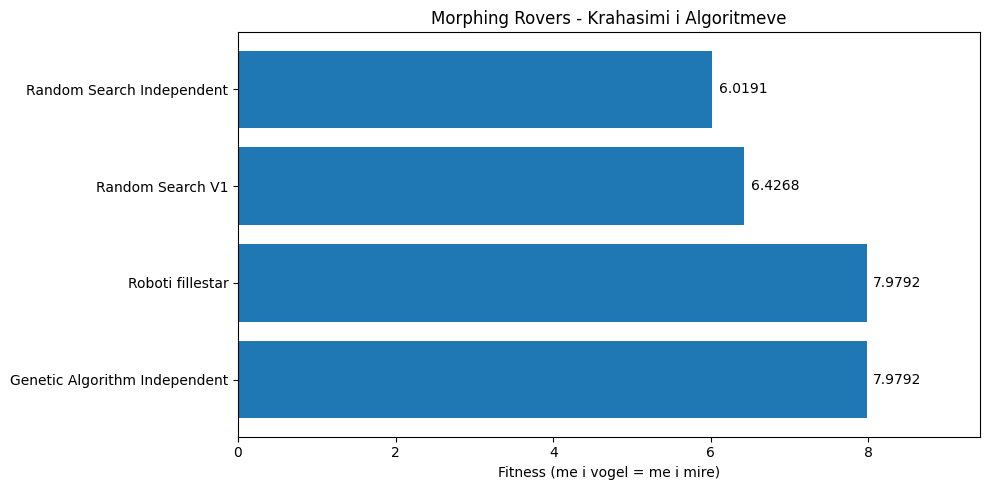

Grafiku u krijua dhe u ruajt me sukses!


In [15]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Folderi i projektit
project = Path("/kaggle/working/SpOC2/Morphing Rovers")

# Lexojme rezultatet e ruajtura
df_plot = pd.read_csv(project / "final_comparison.csv")

# Rendisim sipas fitness
df_plot = df_plot.sort_values("Fitness")

# Krijojme grafikun
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    df_plot["Algoritmi"],
    df_plot["Fitness"]
)

ax.invert_yaxis()

ax.set_title("Morphing Rovers - Krahasimi i Algoritmeve")
ax.set_xlabel("Fitness (me i vogel = me i mire)")

# Shfaqim vlerat
for bar in bars:
    value = bar.get_width()

    ax.text(
        value + 0.08,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.4f}",
        va="center"
    )

ax.set_xlim(0, df_plot["Fitness"].max() * 1.18)

plt.tight_layout()

# Ruajme grafikun
plt.savefig(
    project / "fitness_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Grafiku u krijua dhe u ruajt me sukses!")


In [16]:

import pandas as pd
from pathlib import Path

# Folderi i projektit
project = Path(
    "/kaggle/working/SpOC2/Morphing Rovers"
)

# Lexojme rezultatet e eksperimenteve
seed_results = pd.read_csv(
    project / "seed_experiments.csv"
)

print("REZULTATET E EKSPERIMENTEVE")
print(seed_results.round(4).to_string(index=False))

# Llogarisim statistikat
summary = seed_results.groupby("Algoritmi").agg(
    Fitness_Mesatar=("Fitness", "mean"),
    Devijimi_Standard=("Fitness", "std"),
    Koha_Mesatare_s=("Koha_s", "mean")
)

print("\nPERMBLEDHJA")
print(summary.round(4))

print("\nRezultatet u lexuan me sukses!")


REZULTATET E EKSPERIMENTEVE
 Seed         Algoritmi  Fitness  Koha_s
  101     Random Search   3.1823 34.8514
  101 Genetic Algorithm   4.0568 25.9736
  202     Random Search   3.0216 27.5774
  202 Genetic Algorithm   3.4670 25.0398
  303     Random Search   4.4900 17.4280
  303 Genetic Algorithm   4.1173 29.8869

PERMBLEDHJA
                   Fitness_Mesatar  Devijimi_Standard  Koha_Mesatare_s
Algoritmi                                                             
Genetic Algorithm           3.8804             0.3593          26.9668
Random Search               3.5647             0.8054          26.6189

Rezultatet u lexuan me sukses!


In [17]:

import pandas as pd
from pathlib import Path
import shutil

# Folderi i projektit
project = Path(
    "/kaggle/working/SpOC2/Morphing Rovers"
)

# Dataset V2 me rezultatet e ruajtura
dataset_v2 = Path(
    "/kaggle/input/datasets/jolashala/morphing-rovers-backup-v2"
)

# Rikthejme rezultatet nga Dataset V2
for name in [
    "seed_full_30_results.csv",
    "seed_full_30_summary.csv"
]:
    source = dataset_v2 / name
    destination = project / name

    shutil.copy2(source, destination)
    print("U rikthye:", name)

# Lexojme rezultatet e 30 skenareve
df_full = pd.read_csv(
    project / "seed_full_30_results.csv"
)

print("\nREZULTATET NE 30 SKENARE")
print(df_full.round(4).to_string(index=False))

# Llogarisim statistikat perfundimtare
summary_full = df_full.groupby("Algoritmi").agg(
    Fitness_Mesatar=("Fitness_30", "mean"),
    Devijimi_Standard=("Fitness_30", "std"),
    Permiresimi_Mesatar=("Permiresimi_%", "mean"),
    Koha_Testimit_Mesatare=("Koha_testimit_s", "mean")
)

print("\nPERMBLEDHJA PERFUNDIMTARE")
print(summary_full.round(4))

print("\nRezultatet u lexuan me sukses!")


U rikthye: seed_full_30_results.csv
U rikthye: seed_full_30_summary.csv

REZULTATET NE 30 SKENARE
 Seed         Algoritmi  Fitness_30  Permiresimi_%  Koha_testimit_s
  101     Random Search      6.0615        24.0336          35.2311
  101 Genetic Algorithm      6.0940        23.6263          33.4959
  202     Random Search      5.9172        25.8426          31.5651
  202 Genetic Algorithm      5.7208        28.3042          32.7845
  303     Random Search      7.9792         0.0000          27.9745
  303 Genetic Algorithm      6.7376        15.5609          30.0222

PERMBLEDHJA PERFUNDIMTARE
                   Fitness_Mesatar  Devijimi_Standard  Permiresimi_Mesatar  \
Algoritmi                                                                    
Genetic Algorithm           6.1841             0.5144              22.4971   
Random Search               6.6526             1.1511              16.6254   

                   Koha_Testimit_Mesatare  
Algoritmi                                 

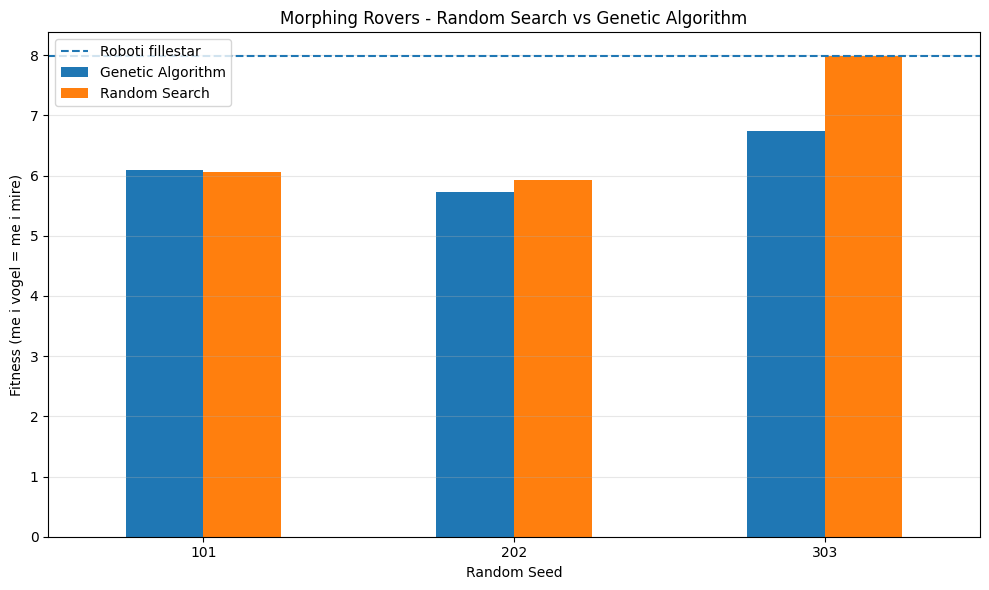

Grafiku perfundimtar u krijua me sukses!


In [18]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Folderi i projektit
project = Path(
    "/kaggle/working/SpOC2/Morphing Rovers"
)

# Lexojme rezultatet nga Dataset V2
dataset_v2 = Path(
    "/kaggle/input/datasets/jolashala/morphing-rovers-backup-v2"
)

df = pd.read_csv(
    dataset_v2 / "seed_full_30_results.csv"
)

# Organizojme rezultatet sipas seed
pivot = df.pivot(
    index="Seed",
    columns="Algoritmi",
    values="Fitness_30"
)

# Krijojme grafikun
fig, ax = plt.subplots(figsize=(10, 6))

pivot.plot(
    kind="bar",
    ax=ax,
    rot=0
)

# Rezultati i robotit fillestar
baseline = 7.9792

ax.axhline(
    y=baseline,
    linestyle="--",
    label="Roboti fillestar"
)

ax.set_title(
    "Morphing Rovers - Random Search vs Genetic Algorithm"
)

ax.set_xlabel("Random Seed")
ax.set_ylabel("Fitness (me i vogel = me i mire)")

ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Ruajme grafikun
plt.savefig(
    project / "comparison_30_scenarios.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Grafiku perfundimtar u krijua me sukses!")


In [1]:

import numpy as np
from pathlib import Path

dataset_v2 = Path(
    "/kaggle/input/datasets/jolashala/morphing-rovers-backup-v2"
)

print("KONFIGURIMET E RUAJTURA")
print("-" * 50)

for file in sorted(dataset_v2.glob("*.npy")):
    params = np.load(file, allow_pickle=False)

    print(
        f"{file.name}: "
        f"{params.size} parametra | "
        f"shape={params.shape} | "
        f"vlera valide={np.isfinite(params).all()}"
    )

print("-" * 50)
print("Kontrolli perfundoi!")


KONFIGURIMET E RUAJTURA
--------------------------------------------------
best_rover.npy: 19133 parametra | shape=(19133,) | vlera valide=True
ga_best_rover.npy: 19133 parametra | shape=(19133,) | vlera valide=True
ga_independent.npy: 19133 parametra | shape=(19133,) | vlera valide=True
ga_seed_101.npy: 19133 parametra | shape=(19133,) | vlera valide=True
ga_seed_202.npy: 19133 parametra | shape=(19133,) | vlera valide=True
ga_seed_303.npy: 19133 parametra | shape=(19133,) | vlera valide=True
ga_v2_best_rover.npy: 19133 parametra | shape=(19133,) | vlera valide=True
rs_independent.npy: 19133 parametra | shape=(19133,) | vlera valide=True
rs_seed_101.npy: 19133 parametra | shape=(19133,) | vlera valide=True
rs_seed_202.npy: 19133 parametra | shape=(19133,) | vlera valide=True
rs_seed_303.npy: 19133 parametra | shape=(19133,) | vlera valide=True
--------------------------------------------------
Kontrolli perfundoi!


In [2]:

import numpy as np
import pandas as pd
from pathlib import Path

dataset_v2 = Path(
    "/kaggle/input/datasets/jolashala/morphing-rovers-backup-v2"
)

# Lexojme rezultatet e testeve ne 30 skenare
results = pd.read_csv(
    dataset_v2 / "seed_full_30_results.csv"
)

# I rendisim nga fitness me i mire
results = results.sort_values("Fitness_30")

print("RENDITJA E KONFIGURIMEVE:")
print(results[["Seed", "Algoritmi", "Fitness_30"]].to_string(index=False))

# Marrim konfigurimin me te mire te dokumentuar
best_row = results.iloc[0]

algorithm = best_row["Algoritmi"]
seed = int(best_row["Seed"])

prefix = "ga" if algorithm == "Genetic Algorithm" else "rs"
best_file = dataset_v2 / f"{prefix}_seed_{seed}.npy"

best_params = np.load(best_file)

print("\nKONFIGURIMI ME I MIRE I DOKUMENTUAR:")
print("Algoritmi:", algorithm)
print("Seed:", seed)
print("Fitness i regjistruar:", best_row["Fitness_30"])
print("Fajlli:", best_file.name)
print("Numri i parametrave:", len(best_params))

print("\nKonfigurimi u ngarkua me sukses!")


RENDITJA E KONFIGURIMEVE:
 Seed         Algoritmi  Fitness_30
  202 Genetic Algorithm    5.720751
  202     Random Search    5.917164
  101     Random Search    6.061506
  101 Genetic Algorithm    6.094004
  303 Genetic Algorithm    6.737559
  303     Random Search    7.979195

KONFIGURIMI ME I MIRE I DOKUMENTUAR:
Algoritmi: Genetic Algorithm
Seed: 202
Fitness i regjistruar: 5.7207512855529785
Fajlli: ga_seed_202.npy
Numri i parametrave: 19133

Konfigurimi u ngarkua me sukses!


In [6]:

import numpy as np
import time
from pathlib import Path

# Kontrollojme nese simulatori eshte gati
if "udp" not in globals():
    raise RuntimeError(
        "Ekzekuto fillimisht qelizat e konfigurimit te simulatorit."
    )

# Konfigurimi me i mire i dokumentuar
dataset_v2 = Path(
    "/kaggle/input/datasets/jolashala/morphing-rovers-backup-v2"
)

best_file = dataset_v2 / "ga_seed_202.npy"
best_params = np.load(best_file)

# Rezultati i regjistruar me heret
expected_fitness = 5.7207512855529785

print("Po testojme:", best_file.name)
print("Numri i parametrave:", len(best_params))

# Vleresimi i plote me simulatorin ESA
start = time.perf_counter()

result = udp.fitness(best_params)
actual_fitness = float(result[0])

elapsed = time.perf_counter() - start

print("\nREZULTATI I VERIFIKIMIT")
print("Fitness i regjistruar:", round(expected_fitness, 6))
print("Fitness i ri:", round(actual_fitness, 6))
print("Koha e testimit:", round(elapsed, 2), "sekonda")

if abs(actual_fitness - expected_fitness) < 0.0001:
    print("\nSUKSES: Rezultati u riprodhua!")
else:
    print("\nKUJDES: Rezultatet ndryshojne; duhet hetuar arsyeja.")


Po testojme: ga_seed_202.npy
Numri i parametrave: 19133

REZULTATI I VERIFIKIMIT
Fitness i regjistruar: 5.720751
Fitness i ri: 5.720751
Koha e testimit: 29.14 sekonda

SUKSES: Rezultati u riprodhua!


In [7]:

import numpy as np
import pandas as pd
import time
from pathlib import Path

dataset_v2 = Path(
    "/kaggle/input/datasets/jolashala/morphing-rovers-backup-v2"
)

project = Path(
    "/kaggle/working/SpOC2/Morphing Rovers"
)

# Rezultati yne me i mire i verifikuar
best_score = 5.7207512855529785
best_params = np.load(dataset_v2 / "ga_seed_202.npy")
best_name = "ga_seed_202.npy"

# Ruajme kopjen e konfigurimit me te mire
output_file = project / "top3_best_candidate.npy"
np.save(output_file, best_params)

# Konfigurimet e tjera qe duhen testuar
candidates = [
    "best_rover.npy",
    "ga_best_rover.npy",
    "ga_v2_best_rover.npy",
    "ga_independent.npy",
    "rs_independent.npy"
]

records = []

for name in candidates:
    params = np.load(dataset_v2 / name)

    start = time.perf_counter()
    score = float(udp.fitness(params)[0])
    elapsed = time.perf_counter() - start

    records.append({
        "File": name,
        "Fitness": score,
        "Koha_s": elapsed
    })

    print(
        f"{name}: Fitness = {score:.6f}",
        flush=True
    )

    # Ruajme rezultatet pas cdo testimi
    pd.DataFrame(records).to_csv(
        project / "candidate_scan.csv",
        index=False
    )

    if score < best_score:
        best_score = score
        best_name = name
        np.save(output_file, params)
        print(">>> U gjet nje robot me i mire!", flush=True)

print("\nKONFIGURIMI ME I MIRE:")
print("Fajlli origjinal:", best_name)
print("Fitness:", round(best_score, 6))
print("Kopja e ruajtur:", output_file.name)


best_rover.npy: Fitness = 6.426772
ga_best_rover.npy: Fitness = 6.426772
ga_v2_best_rover.npy: Fitness = 6.426772
ga_independent.npy: Fitness = 7.979195
rs_independent.npy: Fitness = 6.019130

KONFIGURIMI ME I MIRE:
Fajlli origjinal: ga_seed_202.npy
Fitness: 5.720751
Kopja e ruajtur: top3_best_candidate.npy


In [8]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import display, FileLink

project = Path(
    "/kaggle/working/SpOC2/Morphing Rovers"
)

backup = Path(
    "/kaggle/working/Morphing_Rovers_Top3_Checkpoint.zip"
)

files = [
    "top3_best_candidate.npy",
    "candidate_scan.csv"
]

with ZipFile(backup, "w", ZIP_DEFLATED) as z:
    for name in files:
        source = project / name

        if not source.exists():
            raise FileNotFoundError(source)

        z.write(source, arcname=name)

    z.writestr(
        "checkpoint_info.txt",
        "Project: ESA Morphing Rovers\n"
        "Best algorithm: Genetic Algorithm\n"
        "Best seed: 202\n"
        "Verified fitness (30 scenarios): 5.7207512855529785\n"
        "Best parameters: top3_best_candidate.npy\n"
        "Leaderboard target: Top 3\n"
    )

print("Checkpoint u krijua me sukses!")
print("Fajlli:", backup.name)

display(FileLink(str(backup)))


Checkpoint u krijua me sukses!
Fajlli: Morphing_Rovers_Top3_Checkpoint.zip


/kaggle/working/Morphing_Rovers_Top3_Checkpoint.zip

In [4]:

import numpy as np
import pandas as pd
import time
from pathlib import Path

# Folderat
dataset_v2 = Path(
    "/kaggle/input/datasets/jolashala/morphing-rovers-backup-v2"
)

project = Path(
    "/kaggle/working/SpOC2/Morphing Rovers"
)

project.mkdir(parents=True, exist_ok=True)

# Roboti me i mire i verifikuar
original = np.load(dataset_v2 / "ga_seed_202.npy")

best_full_score = 5.7207512855529785

np.save(project / "top3_best_candidate.npy", original)

# Kufijte e parametrave
lower, upper = udp.get_bounds()
lower = np.asarray(lower)
upper = np.asarray(upper)

n_cont = len(original) - udp.get_nix()

# 3 skenare per kerkimin e shpejte
cases = [(0, 0), (0, 1), (1, 0)]

def quick_fitness(params):
    robot = m.Rover(params)
    values = []

    for map_id, scenario_id in cases:
        d, t = udp.run_single_scenario(
            robot, map_id, scenario_id
        )
        values.append((1 + float(d)) * float(t))

    return float(np.mean(values))

# Fillimi nga konfigurimi ekzistues
rng = np.random.default_rng(2026)

current = original.copy()
current_score = quick_fitness(current)

print("Fitness fillestar ne 3 skenare:",
      round(current_score, 6))

print("\nPO FILLOJME LOCAL SEARCH\n")

history = []

for i in range(1, 13):

    candidate = current.copy()

    # Ndryshojme nje grup parametrash
    count = int(rng.choice([100, 300, 700]))
    sigma = float(rng.choice([0.05, 0.15, 0.30]))

    ids = rng.choice(
        n_cont,
        size=count,
        replace=False
    )

    candidate[ids] += rng.normal(
        0, sigma, size=count
    )

    candidate[ids] = np.clip(
        candidate[ids],
        lower[ids],
        upper[ids]
    )

    score = quick_fitness(candidate)
    improved = score < current_score

    if improved:
        current = candidate.copy()
        current_score = score

        np.save(
            project / "local_search_train_best.npy",
            current
        )

    history.append({
        "Iteration": i,
        "Fitness_3": score,
        "Improved": improved
    })

    pd.DataFrame(history).to_csv(
        project / "local_search_history.csv",
        index=False
    )

    print(
        f"Prova {i}/12 | "
        f"Fitness: {score:.6f} | "
        f"Me i miri: {current_score:.6f}",
        flush=True
    )

print("\nTESTIMI NE 30 SKENARE")

start = time.perf_counter()
new_full_score = float(udp.fitness(current)[0])
elapsed = time.perf_counter() - start

print("Fitness i meparshem:", round(best_full_score, 6))
print("Fitness i ri:", round(new_full_score, 6))
print("Koha:", round(elapsed, 2), "sekonda")

if np.isfinite(new_full_score) and new_full_score < best_full_score:
    np.save(
        project / "top3_best_candidate.npy",
        current
    )
    print("\nSUKSES! U gjet konfigurim me i mire!")
else:
    print("\nNuk pati permiresim ne 30 skenare.")
    print("Konfigurimi i meparshem u ruajt.")

print("\nProva perfundoi!")


Fitness fillestar ne 3 skenare: 3.466976

PO FILLOJME LOCAL SEARCH

Prova 1/12 | Fitness: 3.590465 | Me i miri: 3.466976
Prova 2/12 | Fitness: 3.263771 | Me i miri: 3.263771
Prova 3/12 | Fitness: 3.358433 | Me i miri: 3.263771
Prova 4/12 | Fitness: 3.413006 | Me i miri: 3.263771
Prova 5/12 | Fitness: 3.618978 | Me i miri: 3.263771
Prova 6/12 | Fitness: 4.565599 | Me i miri: 3.263771
Prova 7/12 | Fitness: 3.844340 | Me i miri: 3.263771
Prova 8/12 | Fitness: 4.540274 | Me i miri: 3.263771
Prova 9/12 | Fitness: 3.746445 | Me i miri: 3.263771
Prova 10/12 | Fitness: 3.905314 | Me i miri: 3.263771
Prova 11/12 | Fitness: 3.261058 | Me i miri: 3.261058
Prova 12/12 | Fitness: 3.286021 | Me i miri: 3.261058

TESTIMI NE 30 SKENARE
Fitness i meparshem: 5.720751
Fitness i ri: 6.672767
Koha: 29.44 sekonda

Nuk pati permiresim ne 30 skenare.
Konfigurimi i meparshem u ruajt.

Prova perfundoi!


In [5]:

import numpy as np
import pandas as pd
import time
from pathlib import Path

# 1. Folderat
dataset_v2 = Path(
    "/kaggle/input/datasets/jolashala/morphing-rovers-backup-v2"
)

project = Path(
    "/kaggle/working/SpOC2/Morphing Rovers"
)

project.mkdir(parents=True, exist_ok=True)

# 2. Roboti me i mire i verifikuar
best_params = np.load(
    dataset_v2 / "ga_seed_202.npy"
).copy()

old_full_score = 5.7207512855529785

# Ruajme konfigurimin fillestar
np.save(
    project / "top3_best_candidate.npy",
    best_params
)

# 3. Kufijte e parametrave
lower, upper = udp.get_bounds()
lower = np.asarray(lower)
upper = np.asarray(upper)

n_cont = len(best_params) - udp.get_nix()

# 4. Zgjedhim 12 skenare nga 6 harta
cases = [
    (map_id, scenario_id)
    for map_id in range(6)
    for scenario_id in [0, 2]
]

def fitness_v2(params):
    rover = m.Rover(params)
    scores = []

    for map_id, scenario_id in cases:
        d, t = udp.run_single_scenario(
            rover, map_id, scenario_id
        )

        scores.append(
            (1 + float(d)) * float(t)
        )

    return float(np.mean(scores))

# 5. Fillojme kerkimin lokal
rng = np.random.default_rng(2027)

best_train_score = fitness_v2(best_params)

print("LOCAL SEARCH V2")
print("Skenare trajnimi:", len(cases))
print("Fitness fillestar (12 skenare):",
      round(best_train_score, 6))

history = []

# 8 prova me ndryshime te vogla
for i in range(1, 9):

    candidate = best_params.copy()

    count = int(rng.choice([30, 100, 300]))
    sigma = float(rng.choice([0.01, 0.03, 0.07]))

    ids = rng.choice(
        n_cont,
        size=count,
        replace=False
    )

    candidate[ids] += rng.normal(
        0, sigma, size=count
    )

    candidate[ids] = np.clip(
        candidate[ids],
        lower[ids],
        upper[ids]
    )

    score = fitness_v2(candidate)

    improved = (
        np.isfinite(score)
        and score < best_train_score
    )

    if improved:
        best_params = candidate.copy()
        best_train_score = score

        np.save(
            project / "local_search_v2_train_best.npy",
            best_params
        )

    history.append({
        "Iteration": i,
        "Fitness_12": score,
        "Best_Fitness_12": best_train_score,
        "Improved": improved
    })

    pd.DataFrame(history).to_csv(
        project / "local_search_v2_history.csv",
        index=False
    )

    print(
        f"Prova {i}/8 | "
        f"Fitness: {score:.6f} | "
        f"Me i miri: {best_train_score:.6f}",
        flush=True
    )

# 6. Testimi ne 30 skenare
print("\nTESTIMI PERFUNDIMTAR - 30 SKENARE")

start = time.perf_counter()

new_full_score = float(
    udp.fitness(best_params)[0]
)

elapsed = time.perf_counter() - start

print("Fitness i vjeter:", round(old_full_score, 6))
print("Fitness V2:", round(new_full_score, 6))
print("Koha:", round(elapsed, 2), "sekonda")

# 7. Ruajme vetem permiresimet reale
if (
    np.isfinite(new_full_score)
    and new_full_score < old_full_score
):
    np.save(
        project / "top3_best_candidate.npy",
        best_params
    )

    print("\nSUKSES! V2 e permiresoi robotin!")
    print("Fitness i ri:", round(new_full_score, 6))

else:
    print("\nV2 nuk dha permiresim ne 30 skenare.")
    print("Roboti 5.720751 mbetet me i miri.")

print("\nLOCAL SEARCH V2 PERFUNDOI!")


LOCAL SEARCH V2
Skenare trajnimi: 12
Fitness fillestar (12 skenare): 3.866039
Prova 1/8 | Fitness: 4.031590 | Me i miri: 3.866039
Prova 2/8 | Fitness: 3.943405 | Me i miri: 3.866039
Prova 3/8 | Fitness: 3.906564 | Me i miri: 3.866039
Prova 4/8 | Fitness: 4.118661 | Me i miri: 3.866039
Prova 5/8 | Fitness: 4.131215 | Me i miri: 3.866039
Prova 6/8 | Fitness: 3.915963 | Me i miri: 3.866039
Prova 7/8 | Fitness: 4.078933 | Me i miri: 3.866039
Prova 8/8 | Fitness: 4.175201 | Me i miri: 3.866039

TESTIMI PERFUNDIMTAR - 30 SKENARE
Fitness i vjeter: 5.720751
Fitness V2: 5.720751
Koha: 29.46 sekonda

V2 nuk dha permiresim ne 30 skenare.
Roboti 5.720751 mbetet me i miri.

LOCAL SEARCH V2 PERFUNDOI!


In [6]:

import numpy as np
import pandas as pd
from pathlib import Path

dataset_v2 = Path(
    "/kaggle/input/datasets/jolashala/morphing-rovers-backup-v2"
)

project = Path(
    "/kaggle/working/SpOC2/Morphing Rovers"
)

# Roboti me i mire i verifikuar
params = np.load(dataset_v2 / "ga_seed_202.npy")

rover = m.Rover(params)
records = []

print("ANALIZA E 30 SKENAREVE")
print("-" * 45, flush=True)

# 6 harta, nga 5 skenare secila
for map_id in range(6):
    for scenario_id in range(5):
        d, t = udp.run_single_scenario(
            rover, map_id, scenario_id
        )

        score = (1 + float(d)) * float(t)

        records.append({
            "Map": map_id,
            "Scenario": scenario_id,
            "Distance": float(d),
            "Time": float(t),
            "Fitness": score
        })

    # Ruajme progresin pas cdo harte
    pd.DataFrame(records).to_csv(
        project / "diagnostic_30_scenarios.csv",
        index=False
    )

    print(
        f"Harta {map_id} u testua!",
        flush=True
    )

df = pd.DataFrame(records)

# Mesatarja e fitness per secilen harte
summary = df.groupby("Map")["Fitness"].agg(
    ["mean", "min", "max"]
)

print("\nFITNESS PER SECILEN HARTE")
print(summary.round(4).to_string())

# Skenaret me te veshtire
print("\n5 SKENARET ME REZULTATIN ME TE DOBET")
print(
    df.nlargest(5, "Fitness")[
        ["Map", "Scenario", "Fitness"]
    ].round(4).to_string(index=False)
)

print("\nFITNESS MESATAR I 30 SKENAREVE:")
print(round(df["Fitness"].mean(), 6))

print("\nFITNESS I VERIFIKUAR ME HERET:")
print(5.720751)

print("\nAnaliza perfundoi!")


ANALIZA E 30 SKENAREVE
---------------------------------------------
Harta 0 u testua!
Harta 1 u testua!
Harta 2 u testua!
Harta 3 u testua!
Harta 4 u testua!
Harta 5 u testua!

FITNESS PER SECILEN HARTE
       mean     min      max
Map                         
0    3.3447  2.8013   4.4836
1    4.0974  2.4177   6.2257
2    8.9967  3.1402  15.9205
3    9.5543  3.5076  22.3205
4    4.5386  3.2372   6.5099
5    3.7927  2.6853   6.4077

5 SKENARET ME REZULTATIN ME TE DOBET
 Map  Scenario  Fitness
   3         1  22.3205
   2         4  15.9205
   3         3  13.5393
   2         1  13.3344
   2         3   6.8709

FITNESS MESATAR I 30 SKENAREVE:
5.72075

FITNESS I VERIFIKUAR ME HERET:
5.720751

Analiza perfundoi!


In [7]:
import pandas as pd
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

file = project / "diagnostic_30_scenarios.csv"

df = pd.read_csv(file)

# Te gjithe skenaret e Hartave 2 dhe 3
focus = df[df["Map"].isin([2, 3])].copy()

print("ANALIZA E DETAJUAR E HARTAVE 2 DHE 3")
print("-" * 65)

print(
    focus.sort_values("Fitness", ascending=False)[
        ["Map", "Scenario", "Distance", "Time", "Fitness"]
    ].round(4).to_string(index=False)
)

print("\nMESATARJA E DISTANCES, KOHES DHE FITNESS")
print("-" * 65)

print(
    focus.groupby("Map")[
        ["Distance", "Time", "Fitness"]
    ].mean().round(4).to_string()
)

print("\n5 SKENARET ME TE DOBETA NE TE GJITHE HARTAT")
print("-" * 65)

print(
    df.nlargest(5, "Fitness")[
        ["Map", "Scenario", "Distance", "Time", "Fitness"]
    ].round(4).to_string(index=False)
)

ANALIZA E DETAJUAR E HARTAVE 2 DHE 3
-----------------------------------------------------------------
 Map  Scenario  Distance    Time  Fitness
   3         1    0.0000 22.3205  22.3205
   2         4    0.6365  9.7285  15.9205
   3         3    0.7508  7.7334  13.5393
   2         1    0.8612  7.1643  13.3344
   2         3    0.9579  3.5092   6.8709
   2         0    0.8131  3.1535   5.7175
   3         0    0.0817  4.2027   4.5462
   3         4    0.0000  3.8581   3.8581
   3         2    0.0000  3.5076   3.5076
   2         2    0.9879  1.5797   3.1402

MESATARJA E DISTANCES, KOHES DHE FITNESS
-----------------------------------------------------------------
     Distance    Time  Fitness
Map                           
2      0.8513  5.0270   8.9967
3      0.1665  8.3245   9.5543

5 SKENARET ME TE DOBETA NE TE GJITHE HARTAT
-----------------------------------------------------------------
 Map  Scenario  Distance    Time  Fitness
   3         1    0.0000 22.3205  22.3205
   2    

In [8]:
import inspect

print("KODI I FUNKSIONIT run_single_scenario")
print("=" * 65)

print(inspect.getsource(udp.run_single_scenario))

KODI I FUNKSIONIT run_single_scenario
    def run_single_scenario(self, rover, map_number, scenario_number, detailed_results = None):
        """
        Function for running a single scenario on a map given a rover.
        Maximum simulation time is 500 timesteps, in which the neural network of the rover determines whether to switch
        the rover's form and how to change the orientation of the rover at each timestep. Position updates are done
        by comparing the terrain the rover is standing on with the mask of the active mode (using a function).
        If the rover reaches a certain radius around the sample the scenario is completed early. 
        If the for loop ends or the rover travels outside of the map, the function records no samples saved and the time 
        returned is the maximum simulation time. 
        The simulations always begin with the rover in its first form, with the orientation aligned with the x-axis (eastward).

        Args:
            rover: the 

In [9]:
import inspect

print("FUNKSIONI update_rover_state")
print("=" * 70)

print(inspect.getsource(m.Rover.update_rover_state))

FUNKSIONI update_rover_state
    def update_rover_state(self, rover_view, mode_view, distance_vector, original_distance):
        """
        Updates the rover state variables for the current timestep.

        Args:
            rover_view: the view (top-down, unrotated) of the local terrain
            mode_view: the terrain the rover is standing on
            distance_vector: the vector from the rover to the target
            original_distance: the scalar distance from the starting point to the target
        """
        # Calculate angle and distance between rover and sample
        angle_to_sample = atan2(distance_vector[1], distance_vector[0])
        distance_to_sample = distance_vector.norm()/original_distance

        # Turn angle to minimal angle (from -pi to pi)
        angle_diff =  minimal_angle_diff(angle_to_sample, self.angle)
        # Prepare state of the rover as input to the neural network
        # Contains:
        # - the efficiency of the current mode
        # 

In [10]:
import inspect
import torch

print("TIPI I RRJETIT:")
print(type(rover.Control))

print("\nARKITEKTURA E RRJETIT:")
print(rover.Control)

print("\nFUNKSIONI FORWARD:")
print(inspect.getsource(type(rover.Control).forward))

print("\nNUMRI I PARAMETRAVE:")
print(sum(p.numel() for p in rover.Control.parameters()))

TIPI I RRJETIT:
<class 'morphing_kaggle.Controller'>

ARKITEKTURA E RRJETIT:
Controller(
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (pool2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (activation1): Hardsigmoid()
  (activation3): Hardtanh(min_val=-1.0, max_val=1.0)
  (activation4): Sigmoid()
  (inp): Linear(in_features=9, out_features=40, bias=True)
  (conv): Conv2d(1, 8, kernel_size=(11, 11), stride=(2, 2))
  (conv2): Conv2d(8, 16, kernel_size=(4, 4), stride=(2, 2))
  (lin2): Linear(in_features=256, out_features=40, bias=False)
  (lin3): Linear(in_features=40, out_features=40, bias=True)
  (lin4): Linear(in_features=40, out_features=40, bias=True)
  (recurr): Linear(in_features=40, out_features=40, bias=False)
  (output): Linear(in_features=40, out_features=2, bias=True)
)

FUNKSIONI FORWARD:
    def forward(self, landscape, state, past_inp):
        '''
        Given the surrounding landscape, rover state and previous network state, 


In [11]:
import inspect

print("KONSTRUKTORI I ROVER")
print("=" * 65)
print(inspect.getsource(m.Rover.__init__))

print("\nKONSTRUKTORI I CONTROLLER")
print("=" * 65)
print(inspect.getsource(type(rover.Control).__init__))

KONSTRUKTORI I ROVER
    def __init__(self, chromosome):
        '''
        Class defining the rover. Contains both the rover forms, the control neural network as well as 
        a function for updating the state of the rover given its surroundings and current state.
        '''
        # Extract forms from chromosome
        form_chromosome = chromosome[:NUM_MODE_PARAMETERS]
        # Extract neural network parameters from chromosome
        network_chromosome = chromosome[NUM_MODE_PARAMETERS:]
        # Create control neural network
        self.Control = Controller(network_chromosome)
        # Create form masks for the rover modes
        self.form_masks = torch.Tensor(np.reshape(form_chromosome, (NUMBER_OF_MODES, MASK_SIZE, MASK_SIZE)))
        
        # Initialize the rover state
        self.current_mode = 0 # current mode, digit from 0 to NUM_ROVER_MODES-1
        self.cooldown = 0 # cooldown of switching between modes
        self.mode_efficiency = 0 # current efficiency of

In [13]:
import morphing_kaggle as mk
import inspect

print("NUM_MODE_PARAMETERS:", mk.NUM_MODE_PARAMETERS)
print("NUM_BIASES:", mk.NUM_BIASES)
print("NUM_NN_PARAMS:", mk.NUM_NN_PARAMS)
print("NUM_MODES:", mk.NUMBER_OF_MODES)
print("MASK_SIZE:", mk.MASK_SIZE)

print("\nNETWORK SETUP:")
print(mk.NETWORK_SETUP)

print("\nWEIGHTS FUNCTION:")
print(inspect.getsource(mk.Controller._set_weights_from_chromosome))

print("\nBIASES FUNCTION:")
print(inspect.getsource(mk.Controller._set_biases_from_chromosome))

NUM_MODE_PARAMETERS: 484
NUM_BIASES: 146
NUM_NN_PARAMS: 18642
NUM_MODES: 4
MASK_SIZE: 11

NETWORK SETUP:
{'filters': 8, 'kernel_size': 11, 'stride': 2, 'dilation': 1, 'filters1': 16, 'kernel_size1': 4, 'pooling_size': 2, 'state_neurons': 40, 'hidden_neurons': [40, 40]}

WEIGHTS FUNCTION:
    def _set_weights_from_chromosome(self, chromosome):
        '''
        Set the weights from a flat vector.
        '''
        if not isinstance(chromosome, torch.Tensor):
            chromosome = torch.Tensor(chromosome)
        prev_slice, next_slice = 0, 0
        for param in self.parameters():
            shape = list(param.size())
            if len(shape)>1:
                next_slice += np.prod(shape)
                slices = chromosome[prev_slice:next_slice]
                param.data = slices.reshape(shape)
                prev_slice = next_slice
        assert(prev_slice == NUM_WEIGHTS)


BIASES FUNCTION:
    def _set_biases_from_chromosome(self, chromosome):
        '''
        Set the

In [14]:
import numpy as np
import morphing_kaggle as mk

params = np.load(
    "/kaggle/input/datasets/jolashala/morphing-rovers-backup-v2/ga_seed_202.npy"
)

form_params = params[:mk.NUM_MODE_PARAMETERS]
network_params = params[mk.NUM_MODE_PARAMETERS:]

bias_params = network_params[:mk.NUM_BIASES]
weight_params = network_params[mk.NUM_BIASES:mk.NUM_NN_PARAMS]
architecture_params = network_params[mk.NUM_NN_PARAMS:]

print("KONTROLLI I KROMOZOMIT")
print("=" * 55)
print("Gjatesia totale:", len(params))
print("Maskat:", len(form_params))
print("Bias:", len(bias_params))
print("Weights:", len(weight_params))
print("Parametra arkitekture:", len(architecture_params))

print("\nVLERA AKTUALE E PARAMETRAVE")
print("=" * 55)

for name, values in [
    ("FORMAT", form_params),
    ("BIAS", bias_params),
    ("WEIGHTS", weight_params),
    ("ARKITEKTURA", architecture_params)
]:
    print(f"\n{name}")
    print("Min:", values.min())
    print("Max:", values.max())
    print("Mean:", values.mean())
    print("Std:", values.std())
    print("Numri i vlerave unike:", len(np.unique(values)))

print("\n7 PARAMETRAT E ARKITEKTURES:")
print(architecture_params)

KONTROLLI I KROMOZOMIT
Gjatesia totale: 19133
Maskat: 484
Bias: 146
Weights: 18496
Parametra arkitekture: 7

VLERA AKTUALE E PARAMETRAVE

FORMAT
Min: -0.0945235332736476
Max: 3.346424813532214
Mean: 1.4314871883171483
Std: 0.5186945758047256
Numri i vlerave unike: 484

BIAS
Min: -1.635754837888889
Max: 9.97326924135371
Mean: 0.061661571597408954
Std: 1.015451577628016
Numri i vlerave unike: 146

WEIGHTS
Min: -2.332672835988119
Max: 2.261809196068193
Mean: -3.734917078966334e-05
Std: 0.5568394463251665
Numri i vlerave unike: 18496

ARKITEKTURA
Min: 0.0
Max: 3.0
Mean: 1.2857142857142858
Std: 1.0301575072754257
Numri i vlerave unike: 4

7 PARAMETRAT E ARKITEKTURES:
[0. 1. 1. 2. 3. 0. 2.]


In [15]:
import numpy as np

lb, ub = udp.get_bounds()

lb = np.asarray(lb)
ub = np.asarray(ub)

print("NUMRI I KUFIZIMEVE:", len(lb))
print("NUMRI I PARAMETRAVE:", len(params))

segments = {
    "MASKAT": (0, 484),
    "BIAS": (484, 630),
    "WEIGHTS": (630, 19126),
    "ARKITEKTURA": (19126, 19133)
}

print("\nKUFIJTE E LEJUAR")
print("=" * 60)

for name, (start, end) in segments.items():
    print(f"\n{name}")
    print("Lower bound:", lb[start:end].min(), "deri", lb[start:end].max())
    print("Upper bound:", ub[start:end].min(), "deri", ub[start:end].max())

print("\nPARAMETRAT DISKRETE:")
print("get_nix():", udp.get_nix())

NUMRI I KUFIZIMEVE: 19133
NUMRI I PARAMETRAVE: 19133

KUFIJTE E LEJUAR

MASKAT
Lower bound: -100.0 deri 1e-16
Upper bound: 100 deri 100

BIAS
Lower bound: -100.0 deri -100.0
Upper bound: 100 deri 100

WEIGHTS
Lower bound: -100.0 deri -100.0
Upper bound: 100 deri 100

ARKITEKTURA
Lower bound: 0.0 deri 0.0
Upper bound: 1 deri 6

PARAMETRAT DISKRETE:
get_nix(): 7


In [16]:
import inspect
import morphing_kaggle as mk

print("FUNKSIONI I LLOGARITJES SE SHPEJTESISE")
print("=" * 60)

print(inspect.getsource(mk.Rover.velocity_calculation))

print("\nFUNKSIONI I GJETJES SE FORMES ME TE MIRE")
print("=" * 60)

print(inspect.getsource(mk.Rover.get_best_mode))

FUNKSIONI I LLOGARITJES SE SHPEJTESISE
    def velocity_calculation(self, mode_view):
        '''
        This function calculates the velocity of the rover based on the current local terrain mask and rover form mask.

        Args:
            mode_view: rotated local terrain height the rover is standing on
        Returns:
            mode_efficiency: the current normed velocity (multiples of max. velocity) of the rover
        '''
        # get mask of current mode
        form = self.form_masks[self.current_mode]
        # determine velocity factor for current form and terrain
        mode_efficiency = velocity_function(form, mode_view)
        
        return mode_efficiency


FUNKSIONI I GJETJES SE FORMES ME TE MIRE
    def get_best_mode(self, mode_view):
        '''
        Returns the mode that yields the highest velocity on a given part of the terrain.
        
        Args:
            mode_view: rotated local terrain height the rover is standing on
        Returns:
         

In [17]:
import inspect
import morphing_kaggle as mk

print(inspect.getsource(mk.velocity_function))

def velocity_function(form, mode_view):
    '''
    Velocity function that maps a rover form and current terrain to a velocity.

    Composed of a term taking into account shape only (distance)
    as well as height difference scale only (luminance).

    Args:
        form: mask of the rover mode
        mode_view: terrain height map the rover is standing on.

    Returns:
        Scalar between 0 and 1 that scales the velocity.
        Rover velocity is obtained by multiplying this factor with MAX_VELOCITY.
    '''
    # calculate norm of vectors
    f_norm = form.norm()
    mv_norm = mode_view.norm()
    # luminance = how well do the vector norms agree?
    # 0 = no match, 1 = perfect match
    luminance = (2*f_norm*mv_norm+EPS_C)/(f_norm**2+mv_norm**2+EPS_C)
    # distance = Euclidean distance on unit sphere (i.e., of normalized vectors)
    # Rescaled to go from 0 to 1, with 0 = no match, 1 = perfect match
    distance = (2-(form/f_norm - mode_view/mv_norm).norm())*0.5
    # final

In [18]:
import inspect
import morphing_kaggle as mk

print(inspect.getsource(mk.distance_to_velocity))

def distance_to_velocity(x):
    '''
    Helper function that turns the initial score for rover and terrain similarity into a velocity.
    '''
    return 1./(1+x**3)



In [19]:
import numpy as np
from pathlib import Path

dataset_v2 = Path(
    "/kaggle/input/datasets/jolashala/morphing-rovers-backup-v2"
)

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

# Ngarko kandidatin me te mire
best_params = np.load(dataset_v2 / "ga_seed_202.npy").copy()

# Ruaj kopjen e eksperimentit
experiment_params = best_params.copy()

# Kontrollo strukturen
assert len(best_params) == 19133
assert np.isfinite(best_params).all()

print("Kandidati u ngarkua me sukses.")
print("Numri i parametrave:", len(best_params))
print("Maskat:", len(best_params[:484]))
print("Rrjeti neuronal:", len(best_params[484:]))
print("Fitness referues: 5.720751")

np.save(project / "experiment_base.npy", experiment_params)

print("\nKopja e eksperimentit u ruajt!")

Kandidati u ngarkua me sukses.
Numri i parametrave: 19133
Maskat: 484
Rrjeti neuronal: 18649
Fitness referues: 5.720751

Kopja e eksperimentit u ruajt!


In [7]:
import numpy as np
import time

# Ngarko kopjen e eksperimentit
candidate = np.load(project / "experiment_base.npy")

# Krijo rover-in
test_rover = mk.Rover(candidate)

print("VERIFIKIMI I KANDIDATIT")
print("-" * 50)

start = time.time()
score1 = udp.fitness(candidate)[0]
print("Testi 1:", score1)

start = time.time()
score2 = udp.fitness(candidate)[0]
print("Testi 2:", score2)

print("Diferenca:", abs(score1 - score2))
print("Koha totale:", round(time.time() - start, 2), "sekonda")

assert abs(score1 - score2) < 1e-6

print("\nKandidati eshte deterministik!")

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/SpOC2/Morphing Rovers/experiment_base.npy'

In [6]:
from pathlib import Path
import numpy as np
import time

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

print("A ekziston folderi:", project.exists())
print("A ekziston kandidati:", (project / "experiment_base.npy").exists())

A ekziston folderi: True
A ekziston kandidati: False


In [8]:
import numpy as np
from pathlib import Path

dataset = Path("/kaggle/input/datasets/jolashala/morphing-rovers-backup-v2")
source = dataset / "ga_seed_202.npy"
destination = project / "experiment_base.npy"

print("Kandidati ekziston:", source.exists())

Kandidati ekziston: True


In [9]:
import shutil
import numpy as np

shutil.copy2(source, destination)

candidate = np.load(destination)

print("Kandidati u rikthye!")
print("Shape:", candidate.shape)
print("Skedari ekziston:", destination.exists())
print("Numri i parametrave:", len(candidate))

Kandidati u rikthye!
Shape: (19133,)
Skedari ekziston: True
Numri i parametrave: 19133


In [6]:
import time

print("TESTI I DETERMINUESHMËRISË")
print("-" * 40)

start = time.time()
score1 = udp.fitness(candidate)[0]
print("Testi 1:", score1)

score2 = udp.fitness(candidate)[0]
print("Testi 2:", score2)

print("Diferenca:", abs(score1 - score2))
print("Koha totale:", round(time.time() - start, 2), "sekonda")

assert abs(score1 - score2) < 1e-6

print("\nKandidati eshte deterministik!")

TESTI I DETERMINUESHMËRISË
----------------------------------------


NameError: name 'candidate' is not defined

In [5]:
import time

print("TESTI I DETERMINUESHMËRISË")
print("-" * 40)

start = time.time()
score1 = udp.fitness(candidate)[0]
print("Testi 1:", score1)

score2 = udp.fitness(candidate)[0]
print("Testi 2:", score2)

print("Diferenca:", abs(score1 - score2))
print("Koha totale:", round(time.time() - start, 2), "sekonda")

assert abs(score1 - score2) < 1e-6

print("\nKandidati eshte deterministik!")

TESTI I DETERMINUESHMËRISË
----------------------------------------


NameError: name 'candidate' is not defined

In [7]:
import numpy as np
from pathlib import Path

dataset_v2 = Path(
    "/kaggle/input/datasets/jolashala/morphing-rovers-backup-v2"
)

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

candidate = np.load(dataset_v2 / "ga_seed_202.npy").copy()

assert candidate.shape == (19133,)
assert np.isfinite(candidate).all()

np.save(project / "experiment_base.npy", candidate)

print("Kandidati:", "ga_seed_202.npy")
print("Parametrat:", len(candidate))
print("Maskat:", len(candidate[:484]))
print("Parametrat e tjere:", len(candidate[484:]))
print("Backup:", (project / "experiment_base.npy").exists())
print("Simulatori aktiv:", "udp" in globals())

Kandidati: ga_seed_202.npy
Parametrat: 19133
Maskat: 484
Parametrat e tjere: 18649
Backup: True
Simulatori aktiv: True


In [8]:
import numpy as np

masks = candidate[:484].reshape(4, 11, 11)

print("ANALIZA E MASKAVE")
print("-" * 55)

for i, mask in enumerate(masks):
    print(f"\nMASKA {i + 1}")
    print("Minimumi:", round(float(mask.min()), 6))
    print("Maksimumi:", round(float(mask.max()), 6))
    print("Mesatarja:", round(float(mask.mean()), 6))
    print("Devijimi standard:", round(float(mask.std()), 6))
    print("Norma:", round(float(np.linalg.norm(mask)), 6))

print("\nKONTROLLI I KANDIDATIT")
print("Parametrat total:", len(candidate))
print("Vlera të fundme:", np.isfinite(candidate).all())

ANALIZA E MASKAVE
-------------------------------------------------------

MASKA 1
Minimumi: -0.094524
Maksimumi: 3.346425
Mesatarja: 1.593708
Devijimi standard: 0.822431
Norma: 19.727445

MASKA 2
Minimumi: 0.774847
Maksimumi: 2.697925
Mesatarja: 1.645362
Devijimi standard: 0.263936
Norma: 18.330369

MASKA 3
Minimumi: 0.485421
Maksimumi: 1.928805
Mesatarja: 1.23641
Devijimi standard: 0.261058
Norma: 13.900371

MASKA 4
Minimumi: 0.241559
Maksimumi: 1.887841
Mesatarja: 1.250468
Devijimi standard: 0.345093
Norma: 14.26933

KONTROLLI I KANDIDATIT
Parametrat total: 19133
Vlera të fundme: True


In [9]:
import numpy as np
import time

# Kandidati origjinal mbetet i paprekur
trial = candidate.copy()

# Ndryshim i vogel dhe i riprodhueshem
rng = np.random.default_rng(2026)

noise = rng.normal(
    loc=0.0,
    scale=0.02,
    size=121
)

# Ndryshojme vetem Masken 1
trial[:121] += noise

# Respektojme kufijte e simulatorit
lb, ub = udp.get_bounds()
trial[:121] = np.clip(trial[:121], lb[:121], ub[:121])

print("TESTI I PARE I OPTIMIZIMIT")
print("-" * 45)

print("Parametra te ndryshuar:",
      np.count_nonzero(trial != candidate))

start = time.time()

new_score = float(udp.fitness(trial)[0])

print("Rezultati baze:", 5.720751)
print("Rezultati i ri:", round(new_score, 6))
print("Diferenca:", round(new_score - 5.720751, 6))
print("Koha:", round(time.time() - start, 2), "sekonda")

if np.isfinite(new_score) and new_score < 5.720751:
    np.save(project / "best_optimized.npy", trial)
    print("PERMIRESIM! Kandidati i ri u ruajt.")
else:
    print("Nuk pati permiresim. Kandidati baze ruhet.")

TESTI I PARE I OPTIMIZIMIT
---------------------------------------------
Parametra te ndryshuar: 121
Rezultati baze: 5.720751
Rezultati i ri: 5.946127
Diferenca: 0.225376
Koha: 27.34 sekonda
Nuk pati permiresim. Kandidati baze ruhet.


In [10]:
import numpy as np
import time

trial = candidate.copy()

# Pozicionet qendrore 3x3 te Maskes 1
indices = [
    r * 11 + c
    for r in range(4, 7)
    for c in range(4, 7)
]

rng = np.random.default_rng(2027)

trial[indices] += rng.normal(
    loc=0.0,
    scale=0.01,
    size=len(indices)
)

lb, ub = udp.get_bounds()
trial[indices] = np.clip(
    trial[indices],
    np.asarray(lb)[indices],
    np.asarray(ub)[indices]
)

print("EKSPERIMENTI 2")
print("-" * 40)
print("Parametra te ndryshuar:",
      np.count_nonzero(trial != candidate))

start = time.time()
score = float(udp.fitness(trial)[0])

print("Fitness baze:", 5.720751)
print("Fitness i ri:", round(score, 6))
print("Diferenca:", round(score - 5.720751, 6))
print("Koha:", round(time.time() - start, 2), "sekonda")

if np.isfinite(score) and score < 5.720751:
    np.save(project / "best_optimized.npy", trial)
    print("PERMIRESIM! Kandidati u ruajt.")
else:
    print("Nuk pati permiresim. Ruajme kandidatin baze.")

EKSPERIMENTI 2
----------------------------------------
Parametra te ndryshuar: 9
Fitness baze: 5.720751
Fitness i ri: 5.797371
Diferenca: 0.07662
Koha: 27.53 sekonda
Nuk pati permiresim. Ruajme kandidatin baze.


In [11]:
import numpy as np

lb, ub = udp.get_bounds()
lb = np.asarray(lb)
ub = np.asarray(ub)

print("KONTROLLI I KUFIJVE")
print("-" * 45)

for i in range(4):
    start = i * 121
    end = start + 121

    print(f"\nMaska {i + 1}")
    print("Kufiri minimal:", lb[start:end].min())
    print("Kufiri maksimal:", ub[start:end].max())
    print("Kandidati brenda kufijve:",
          np.all(candidate[start:end] >= lb[start:end]) and
          np.all(candidate[start:end] <= ub[start:end]))

print("\nArkitektura:", candidate[-7:])
print("Parametra total:", len(candidate))

KONTROLLI I KUFIJVE
---------------------------------------------

Maska 1
Kufiri minimal: -100.0
Kufiri maksimal: 100
Kandidati brenda kufijve: True

Maska 2
Kufiri minimal: -100.0
Kufiri maksimal: 100
Kandidati brenda kufijve: True

Maska 3
Kufiri minimal: -100.0
Kufiri maksimal: 100
Kandidati brenda kufijve: True

Maska 4
Kufiri minimal: -100.0
Kufiri maksimal: 100
Kandidati brenda kufijve: True

Arkitektura: [0. 1. 1. 2. 3. 0. 2.]
Parametra total: 19133


In [12]:
import numpy as np
import time
from pathlib import Path

# Gjithmone nisemi nga kandidati me i mire
base = np.load(project / "experiment_base.npy")

baseline = 5.7207512855529785

lb, ub = udp.get_bounds()
lb = np.asarray(lb)
ub = np.asarray(ub)

rng = np.random.default_rng(2026)

# Ndryshojme vetem 484 parametrat e maskave
n = 484

# Drejtim perturbimi me vlera -1 ose +1
delta = rng.choice([-1.0, 1.0], size=n)

# Madhesia e perturbimit
c = 0.01

plus = base.copy()
minus = base.copy()

plus[:n] = np.clip(
    base[:n] + c * delta,
    lb[:n],
    ub[:n]
)

minus[:n] = np.clip(
    base[:n] - c * delta,
    lb[:n],
    ub[:n]
)

print("SPSA - ITERACIONI 1")
print("-" * 45)

start = time.time()

f_plus = float(udp.fitness(plus)[0])
print("Fitness PLUS:", round(f_plus, 6))

f_minus = float(udp.fitness(minus)[0])
print("Fitness MINUS:", round(f_minus, 6))

# Vleresimi i gradientit SPSA
gradient = ((f_plus - f_minus) / (2 * c)) * delta

# Kufizojme normen e gradientit
norm = np.linalg.norm(gradient)

if norm > 0:
    gradient = gradient / norm

# Hapi i optimizimit
learning_rate = 0.02

trial = base.copy()
trial[:n] = np.clip(
    base[:n] - learning_rate * gradient,
    lb[:n],
    ub[:n]
)

f_trial = float(udp.fitness(trial)[0])
print("Fitness TRIAL:", round(f_trial, 6))

# Krahasojme te tre kandidatet
scores = [
    (f_plus, plus, "PLUS"),
    (f_minus, minus, "MINUS"),
    (f_trial, trial, "TRIAL")
]

valid = [
    (score, params, name)
    for score, params, name in scores
    if np.isfinite(score)
]

best_score, best_params, best_name = min(
    valid,
    key=lambda x: x[0]
)

print("\nREZULTATI")
print("-" * 45)
print("Fitness baze:", round(baseline, 6))
print("Fitness me i mire i eksperimentit:", round(best_score, 6))
print("Kandidati:", best_name)
print("Koha:", round(time.time() - start, 2), "sekonda")

if best_score < baseline:
    np.save(project / "best_optimized.npy", best_params)
    print("\nPERMIRESIM! Kandidati i ri u ruajt.")
else:
    print("\nNuk pati permiresim. Kandidati baze mbetet me i miri.")

SPSA - ITERACIONI 1
---------------------------------------------
Fitness PLUS: 6.793004
Fitness MINUS: 5.558572
Fitness TRIAL: 5.736697

REZULTATI
---------------------------------------------
Fitness baze: 5.720751
Fitness me i mire i eksperimentit: 5.558572
Kandidati: MINUS
Koha: 84.5 sekonda

PERMIRESIM! Kandidati i ri u ruajt.


In [13]:
import numpy as np
from pathlib import Path
import shutil

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

source = project / "best_optimized.npy"
backup = project / "best_spsa_5558572.npy"

assert source.exists(), "Nuk u gjet kandidati i optimizuar!"

best = np.load(source)
original = np.load(project / "experiment_base.npy")

assert best.shape == (19133,)
assert np.isfinite(best).all()

shutil.copy2(source, backup)

print("BACKUP I KANDIDATIT TE RI")
print("-" * 45)
print("Backup ekziston:", backup.exists())
print("Parametra te ndryshuar:",
      np.count_nonzero(best != original))
print("Rrjeti neuronal i pandryshuar:",
      np.array_equal(best[484:], original[484:]))
print("Kandidati u ruajt:", backup.name)

BACKUP I KANDIDATIT TE RI
---------------------------------------------
Backup ekziston: True
Parametra te ndryshuar: 484
Rrjeti neuronal i pandryshuar: True
Kandidati u ruajt: best_spsa_5558572.npy


In [14]:
import numpy as np
import time
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

base = np.load(project / "best_spsa_5558572.npy")
baseline = 5.558572

lb, ub = udp.get_bounds()
lb = np.asarray(lb)
ub = np.asarray(ub)

rng = np.random.default_rng(2028)

n = 484
c = 0.005

delta = rng.choice([-1.0, 1.0], size=n)

plus = base.copy()
minus = base.copy()

plus[:n] = np.clip(base[:n] + c * delta, lb[:n], ub[:n])
minus[:n] = np.clip(base[:n] - c * delta, lb[:n], ub[:n])

print("SPSA - ITERACIONI 2")
print("-" * 45)

start = time.time()

f_plus = float(udp.fitness(plus)[0])
print("Fitness PLUS:", round(f_plus, 6))

f_minus = float(udp.fitness(minus)[0])
print("Fitness MINUS:", round(f_minus, 6))

print("\nREZULTATI")
print("-" * 45)

print("Fitness baze:", baseline)
print("Fitness PLUS:", round(f_plus, 6))
print("Fitness MINUS:", round(f_minus, 6))

valid = [
    (score, params, name)
    for score, params, name in [
        (f_plus, plus, "PLUS"),
        (f_minus, minus, "MINUS")
    ]
    if np.isfinite(score)
]

if valid:
    best_score, best_params, best_name = min(
        valid, key=lambda x: x[0]
    )

    print("Kandidati me i mire:", best_name)
    print("Fitness:", round(best_score, 6))

    if best_score < baseline - 1e-6:
        np.save(project / "best_optimized.npy", best_params)
        np.save(project / "best_spsa_iter2.npy", best_params)
        print("\nPERMIRESIM! Kandidati i ri u ruajt.")
    else:
        print("\nNuk pati permiresim. Ruajme 5.558572.")
else:
    print("\nAsnje rezultat i vlefshem.")

print("Koha:", round(time.time() - start, 2), "sekonda")

SPSA - ITERACIONI 2
---------------------------------------------
Fitness PLUS: 5.879023
Fitness MINUS: 6.228761

REZULTATI
---------------------------------------------
Fitness baze: 5.558572
Fitness PLUS: 5.879023
Fitness MINUS: 6.228761
Kandidati me i mire: PLUS
Fitness: 5.879023

Nuk pati permiresim. Ruajme 5.558572.
Koha: 54.35 sekonda


In [15]:
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

original = np.load(project / "experiment_base.npy")
best = np.load(project / "best_spsa_5558572.npy")

print("ANALIZA E NDRYSHIMEVE TE MASKAVE")
print("-" * 55)

for i in range(4):
    start = i * 121
    end = start + 121

    difference = best[start:end] - original[start:end]

    print(f"\nMASKA {i + 1}")
    print("Ndryshimi mesatar absolut:",
          round(float(np.mean(np.abs(difference))), 8))
    print("Ndryshimi maksimal absolut:",
          round(float(np.max(np.abs(difference))), 8))
    print("Parametra te ndryshuar:",
          np.count_nonzero(difference))

print("\nRrjeti neuronal i pandryshuar:",
      np.array_equal(original[484:], best[484:]))

ANALIZA E NDRYSHIMEVE TE MASKAVE
-------------------------------------------------------

MASKA 1
Ndryshimi mesatar absolut: 0.01
Ndryshimi maksimal absolut: 0.01
Parametra te ndryshuar: 121

MASKA 2
Ndryshimi mesatar absolut: 0.01
Ndryshimi maksimal absolut: 0.01
Parametra te ndryshuar: 121

MASKA 3
Ndryshimi mesatar absolut: 0.01
Ndryshimi maksimal absolut: 0.01
Parametra te ndryshuar: 121

MASKA 4
Ndryshimi mesatar absolut: 0.01
Ndryshimi maksimal absolut: 0.01
Parametra te ndryshuar: 121

Rrjeti neuronal i pandryshuar: True


In [17]:
import numpy as np
import time
import csv
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

original = np.load(project / "experiment_base.npy")
best = np.load(project / "best_spsa_5558572.npy")

results = []

print("TESTIMI I KONTRIBUTIT TE MASKAVE")
print("-" * 50)

for i in range(4):
    trial = original.copy()

    start_idx = i * 121
    end_idx = start_idx + 121

    # Zevendesojme vetem nje maske
    trial[start_idx:end_idx] = best[start_idx:end_idx]

    start_time = time.time()
    score = float(udp.fitness(trial)[0])

    results.append((i + 1, score))

    print(
        f"Maska {i+1}: fitness={score:.6f}, "
        f"koha={time.time()-start_time:.1f}s",
        flush=True
    )

    # Ruajme rezultatet pas cdo testi
    with open(project / "mask_contribution.csv", "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["mask", "fitness"])
        writer.writerows(results)

print("\nREZULTATET")
print("-" * 50)
print("Origjinali: 5.720751")
print("Kandidati i permiresuar: 5.558572")

for mask, score in results:
    print(f"Maska {mask}: {score:.6f}")


TESTIMI I KONTRIBUTIT TE MASKAVE
--------------------------------------------------
Maska 1: fitness=5.553689, koha=27.1s
Maska 2: fitness=5.928538, koha=27.4s
Maska 3: fitness=7.017505, koha=26.6s
Maska 4: fitness=5.648526, koha=27.3s

REZULTATET
--------------------------------------------------
Origjinali: 5.720751
Kandidati i permiresuar: 5.558572
Maska 1: 5.553689
Maska 2: 5.928538
Maska 3: 7.017505
Maska 4: 5.648526


In [18]:
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

original = np.load(project / "experiment_base.npy")
spsa_best = np.load(project / "best_spsa_5558572.npy")

# Marrim origjinalin dhe ndryshojme vetem Masken 1
new_best = original.copy()
new_best[:121] = spsa_best[:121]

# Verifikime
assert new_best.shape == (19133,)
assert np.array_equal(new_best[121:], original[121:])
assert np.isfinite(new_best).all()

# Ruajme kandidatin
np.save(project / "best_mask1_5553689.npy", new_best)

print("KANDIDATI I RI U RUAJT")
print("-" * 45)
print("Skedari:", "best_mask1_5553689.npy")
print("Ekziston:", (project / "best_mask1_5553689.npy").exists())
print("Parametra te ndryshuar:",
      np.count_nonzero(new_best != original))
print("Rrjeti neuronal i pandryshuar:",
      np.array_equal(new_best[484:], original[484:]))
print("Fitness i matur me pare: 5.553689")

KANDIDATI I RI U RUAJT
---------------------------------------------
Skedari: best_mask1_5553689.npy
Ekziston: True
Parametra te ndryshuar: 121
Rrjeti neuronal i pandryshuar: True
Fitness i matur me pare: 5.553689


In [19]:
import numpy as np
import time
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

original = np.load(project / "experiment_base.npy")
spsa_best = np.load(project / "best_spsa_5558572.npy")

# Kandidati me Masken 1 te permiresuar
trial = original.copy()

# Maska 1
trial[0:121] = spsa_best[0:121]

# Maska 4
trial[363:484] = spsa_best[363:484]

print("TESTI: MASKA 1 + MASKA 4")
print("-" * 45)

start = time.time()
score = float(udp.fitness(trial)[0])

print("Fitness aktual me i mire:", 5.553689)
print("Fitness Maska 1 + 4:", round(score, 6))
print("Koha:", round(time.time() - start, 2), "sekonda")

if np.isfinite(score) and score < 5.553689:
    np.save(project / "best_mask14.npy", trial)
    print("\nPERMIRESIM! Kandidati i ri u ruajt.")
else:
    print("\nNuk pati permiresim. Ruajme 5.553689.")

TESTI: MASKA 1 + MASKA 4
---------------------------------------------
Fitness aktual me i mire: 5.553689
Fitness Maska 1 + 4: 5.734652
Koha: 27.85 sekonda

Nuk pati permiresim. Ruajme 5.553689.


In [5]:
import numpy as np
import time
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

original = np.load(project / "experiment_base.npy")
spsa_best = np.load(project / "best_spsa_5558572.npy")

trial = original.copy()

# Maska 1 dhe Maska 2 nga kandidati SPSA
trial[0:242] = spsa_best[0:242]

print("TESTI: MASKA 1 + MASKA 2")
print("-" * 45)

start = time.time()
score = float(udp.fitness(trial)[0])

print("Fitness aktual me i mire:", 5.553689)
print("Fitness Maska 1 + 2:", round(score, 6))
print("Koha:", round(time.time() - start, 2), "sekonda")

if np.isfinite(score) and score < 5.553689:
    np.save(project / "best_mask12.npy", trial)
    print("\nPERMIRESIM! Kandidati i ri u ruajt.")
else:
    print("\nNuk pati permiresim. Ruajme 5.553689.")

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/SpOC2/Morphing Rovers/experiment_base.npy'

In [6]:
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

dataset = Path(
    "/kaggle/input/datasets/jolashala/morphing-rovers-backup-v2"
)

print("=== WORKING FILES ===")
if project.exists():
    for f in project.rglob("*.npy"):
        print(f.name)
else:
    print("Folderi working nuk ekziston.")

print("\n=== DATASET BACKUP ===")
if dataset.exists():
    for f in dataset.rglob("*.npy"):
        print(f.relative_to(dataset))
else:
    print("Dataset V2 nuk u gjet.")

print("\n=== KANDIDATET E RENDESISHEM ===")
for name in [
    "experiment_base.npy",
    "best_spsa_5558572.npy",
    "best_mask1_5553689.npy"
]:
    print(name, ":", (project / name).exists())

=== WORKING FILES ===
ga_seed_101.npy
best_rover.npy
rs_independent.npy
ga_v2_best_rover.npy
rs_seed_202.npy
rs_seed_303.npy
rs_seed_101.npy
ga_seed_303.npy
ga_independent.npy
ga_seed_202.npy
ga_best_rover.npy
example_rover.npy

=== DATASET BACKUP ===
best_rover.npy
ga_best_rover.npy
ga_independent.npy
ga_seed_101.npy
ga_seed_202.npy
ga_seed_303.npy
ga_v2_best_rover.npy
rs_independent.npy
rs_seed_101.npy
rs_seed_202.npy
rs_seed_303.npy

=== KANDIDATET E RENDESISHEM ===
experiment_base.npy : False
best_spsa_5558572.npy : False
best_mask1_5553689.npy : False


In [7]:
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

dataset = Path(
    "/kaggle/input/datasets/jolashala/morphing-rovers-backup-v2"
)

# Kandidati origjinal
original = np.load(dataset / "ga_seed_202.npy")

assert original.shape == (19133,)
assert np.isfinite(original).all()

# Rikrijojme perturbimin identik te SPSA
rng = np.random.default_rng(2026)
delta = rng.choice([-1.0, 1.0], size=484)

# Kufijte e parametrave
lb, ub = udp.get_bounds()
lb = np.asarray(lb)
ub = np.asarray(ub)

# Rindertojme kandidatin SPSA
spsa_best = original.copy()
spsa_best[:484] = np.clip(
    original[:484] - 0.01 * delta,
    lb[:484],
    ub[:484]
)

# Rindertojme kandidatin me vetem Masken 1
best_mask1 = original.copy()
best_mask1[:121] = spsa_best[:121]

# Ruajme te tre kandidatet
np.save(project / "experiment_base.npy", original)
np.save(project / "best_spsa_5558572.npy", spsa_best)
np.save(project / "best_mask1_5553689.npy", best_mask1)

print("RIKTHIMI I KANDIDATEVE")
print("-" * 45)

for name in [
    "experiment_base.npy",
    "best_spsa_5558572.npy",
    "best_mask1_5553689.npy"
]:
    print(name, ":", (project / name).exists())

print("\nParametra te ndryshuar ne Masken 1:",
      np.count_nonzero(best_mask1 != original))

print("Rrjeti neuronal i pandryshuar:",
      np.array_equal(best_mask1[484:], original[484:]))

print("\nFitness historik i kandidatit: 5.553689")

RIKTHIMI I KANDIDATEVE
---------------------------------------------
experiment_base.npy : True
best_spsa_5558572.npy : True
best_mask1_5553689.npy : True

Parametra te ndryshuar ne Masken 1: 121
Rrjeti neuronal i pandryshuar: True

Fitness historik i kandidatit: 5.553689


In [8]:
import numpy as np
import time

best_path = project / "best_mask1_5553689.npy"
best = np.load(best_path)

print("VERIFIKIMI I KANDIDATIT")
print("-" * 45)

start = time.time()

score = float(udp.fitness(best)[0])

print("Fitness i matur:", round(score, 6))
print("Fitness historik:", 5.553689)
print("Koha:", round(time.time() - start, 2), "sekonda")

if np.isfinite(score) and abs(score - 5.553689) < 0.00001:
    print("\nSUKSES! Kandidati u rikthye saktesisht.")
else:
    print("\nRezultati ndryshon. Duhet ta analizojme.")

VERIFIKIMI I KANDIDATIT
---------------------------------------------
Fitness i matur: 5.553689
Fitness historik: 5.553689
Koha: 31.56 sekonda

SUKSES! Kandidati u rikthye saktesisht.


In [9]:
import zipfile
import json
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

zip_path = Path("/kaggle/working/Morphing_Rovers_Best_5553689.zip")

files = [
    "experiment_base.npy",
    "best_spsa_5558572.npy",
    "best_mask1_5553689.npy"
]

metadata = {
    "project": "ESA SpOC-2 Morphing Rovers",
    "best_fitness": 5.553689,
    "original_fitness": 5.720751,
    "best_candidate": "best_mask1_5553689.npy",
    "optimization": "SPSA perturbation, Mask 1 only",
    "seed": 2026,
    "perturbation": 0.01,
    "scenarios": 30
}

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as z:

    for filename in files:
        filepath = project / filename
        assert filepath.exists(), f"Mungon: {filename}"
        z.write(filepath, arcname=filename)

    z.writestr(
        "checkpoint_info.json",
        json.dumps(metadata, indent=4)
    )

print("BACKUP U KRIJUA!")
print("-" * 45)
print("Emri:", zip_path.name)
print("Madhesia:", round(zip_path.stat().st_size / 1024, 2), "KB")

with zipfile.ZipFile(zip_path) as z:
    print("\nSkedaret brenda ZIP:")
    for name in z.namelist():
        print("-", name)

BACKUP U KRIJUA!
---------------------------------------------
Emri: Morphing_Rovers_Best_5553689.zip
Madhesia: 430.25 KB

Skedaret brenda ZIP:
- experiment_base.npy
- best_spsa_5558572.npy
- best_mask1_5553689.npy
- checkpoint_info.json


In [10]:
import numpy as np
import time
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

original = np.load(project / "experiment_base.npy")
spsa_best = np.load(project / "best_spsa_5558572.npy")

# Kandidati origjinal
trial = original.copy()

# Marrim Masken 1 dhe Masken 2 nga SPSA
trial[:242] = spsa_best[:242]

print("TESTI: MASKA 1 + MASKA 2", flush=True)
print("-" * 45, flush=True)

start = time.time()

score = float(udp.fitness(trial)[0])

print("Fitness aktual me i mire: 5.553689")
print("Fitness Maska 1 + 2:", round(score, 6))
print("Koha:", round(time.time() - start, 2), "sekonda")

if np.isfinite(score) and score < 5.553689:
    np.save(project / "best_mask12.npy", trial)
    print("PERMIRESIM! Kandidati i ri u ruajt.")
else:
    print("Nuk pati permiresim. Ruajme 5.553689.")

TESTI: MASKA 1 + MASKA 2
---------------------------------------------
Fitness aktual me i mire: 5.553689
Fitness Maska 1 + 2: 7.128614
Koha: 31.63 sekonda
Nuk pati permiresim. Ruajme 5.553689.


In [11]:
import numpy as np
import time

best = np.load(project / "best_mask1_5553689.npy")

lb, ub = udp.get_bounds()
lb = np.asarray(lb)
ub = np.asarray(ub)

rng = np.random.default_rng(20261110)

trial = best.copy()

# Ndryshojme 12 parametra te Maskes 1
indices = rng.choice(121, size=12, replace=False)

trial[indices] += rng.normal(
    loc=0.0,
    scale=0.005,
    size=len(indices)
)

trial[indices] = np.clip(
    trial[indices],
    lb[indices],
    ub[indices]
)

print("ADAPTIVE LOCAL SEARCH - TESTI 1", flush=True)
print("-" * 45, flush=True)

start = time.time()
score = float(udp.fitness(trial)[0])

print("Fitness aktual:", 5.553689)
print("Fitness i ri:", round(score, 6))
print("Koha:", round(time.time() - start, 2), "sekonda")

if np.isfinite(score) and score < 5.553689:
    np.save(project / "best_local_search.npy", trial)
    print("REKORD I RI! Kandidati u ruajt.")
else:
    print("Nuk pati permiresim. Rekordi mbetet 5.553689.")

ADAPTIVE LOCAL SEARCH - TESTI 1
---------------------------------------------
Fitness aktual: 5.553689
Fitness i ri: 5.59001
Koha: 31.54 sekonda
Nuk pati permiresim. Rekordi mbetet 5.553689.


In [12]:
import numpy as np
import time
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

best_path = project / "best_adaptive.npy"

if best_path.exists():
    best = np.load(best_path)
    best_score = float(np.load(project / "best_adaptive_score.npy")[0])
else:
    best = np.load(project / "best_mask1_5553689.npy")
    best_score = 5.553689

lb, ub = udp.get_bounds()
lb = np.asarray(lb)
ub = np.asarray(ub)

rng = np.random.default_rng(20261111)

sigma = 0.008
parameter_counts = [8, 16, 32, 12, 24, 48]

print("ADAPTIVE LOCAL SEARCH")
print("Fitness fillestar:", round(best_score, 6), flush=True)
print("-" * 50, flush=True)

for i, count in enumerate(parameter_counts, start=1):

    trial = best.copy()

    indices = rng.choice(121, size=count, replace=False)

    noise = rng.normal(0, sigma, size=count)

    trial[indices] = np.clip(
        trial[indices] + noise,
        lb[indices],
        ub[indices]
    )

    start = time.time()
    score = float(udp.fitness(trial)[0])

    print(
        f"\nEksperimenti {i}/6",
        f"\nParametra: {count}",
        f"\nSigma: {sigma:.6f}",
        f"\nFitness: {score:.6f}",
        f"\nKoha: {time.time()-start:.1f}s",
        flush=True
    )

    if np.isfinite(score) and score < best_score:

        best = trial.copy()
        best_score = score

        np.save(best_path, best)
        np.save(
            project / "best_adaptive_score.npy",
            np.array([best_score])
        )

        sigma = min(sigma * 1.2, 0.02)

        print("*** REKORD I RI U RUAJT! ***", flush=True)

    else:
        sigma = max(sigma * 0.7, 0.0005)
        print("Pa permiresim.", flush=True)

print("\n" + "=" * 50)
print("PERFUNDIMI")
print("Fitness me i mire:", round(best_score, 6))
print("Permiresimi ndaj 5.553689:",
      round(5.553689 - best_score, 6))

ADAPTIVE LOCAL SEARCH
Fitness fillestar: 5.553689
--------------------------------------------------

Eksperimenti 1/6 
Parametra: 8 
Sigma: 0.008000 
Fitness: 5.538187 
Koha: 31.4s
*** REKORD I RI U RUAJT! ***

Eksperimenti 2/6 
Parametra: 16 
Sigma: 0.009600 
Fitness: 5.712216 
Koha: 31.5s
Pa permiresim.

Eksperimenti 3/6 
Parametra: 32 
Sigma: 0.006720 
Fitness: 5.869648 
Koha: 32.4s
Pa permiresim.

Eksperimenti 4/6 
Parametra: 12 
Sigma: 0.004704 
Fitness: 5.552259 
Koha: 30.3s
Pa permiresim.

Eksperimenti 5/6 
Parametra: 24 
Sigma: 0.003293 
Fitness: 5.899930 
Koha: 30.9s
Pa permiresim.

Eksperimenti 6/6 
Parametra: 48 
Sigma: 0.002305 
Fitness: 5.542238 
Koha: 31.1s
Pa permiresim.

PERFUNDIMI
Fitness me i mire: 5.538187
Permiresimi ndaj 5.553689: 0.015502


In [13]:
import numpy as np
import zipfile
import json
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

best = np.load(project / "best_adaptive.npy")
score = float(np.load(project / "best_adaptive_score.npy")[0])

assert best.shape == (19133,)
assert np.isfinite(best).all()
assert abs(score - 5.538187) < 0.00001

files = [
    "experiment_base.npy",
    "best_spsa_5558572.npy",
    "best_mask1_5553689.npy",
    "best_adaptive.npy",
    "best_adaptive_score.npy"
]

backup = Path(
    "/kaggle/working/Morphing_Rovers_Best_5538187.zip"
)

with zipfile.ZipFile(
    backup, "w", zipfile.ZIP_DEFLATED
) as z:

    for filename in files:
        filepath = project / filename
        assert filepath.exists(), f"Mungon: {filename}"
        z.write(filepath, arcname=filename)

    info = {
        "project": "ESA SpOC-2 Morphing Rovers",
        "best_fitness": score,
        "original_fitness": 5.7207512855529785,
        "best_candidate": "best_adaptive.npy",
        "method": "Adaptive Local Search",
        "scenarios": 30
    }

    z.writestr(
        "checkpoint_info.json",
        json.dumps(info, indent=4)
    )

with zipfile.ZipFile(backup) as z:
    assert z.testzip() is None

print("BACKUP I RI U KRIJUA ME SUKSES!")
print("-" * 45)
print("Fitness:", round(score, 6))
print("Emri:", backup.name)
print("Madhesia:", round(backup.stat().st_size / 1024, 2), "KB")
print("Skedaret:", len(files) + 1)
print("Integriteti i ZIP: OK")

BACKUP I RI U KRIJUA ME SUKSES!
---------------------------------------------
Fitness: 5.538187
Emri: Morphing_Rovers_Best_5538187.zip
Madhesia: 573.73 KB
Skedaret: 6
Integriteti i ZIP: OK


In [14]:
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

best = np.load(project / "best_adaptive.npy")

lb, ub = udp.get_bounds()
lb = np.asarray(lb)
ub = np.asarray(ub)

print("ANALIZA E KROMOZOMIT")
print("=" * 50)

print("Parametra gjithsej:", len(best))
print("Maskat:", 484)
print("Rrjeti neuronal:", 18642)
print("Gjenet e arkitektures:", 7)

print("\nANALIZA E MASKAVE")
print("-" * 50)

for i in range(4):
    values = best[i * 121:(i + 1) * 121]

    print(
        f"Maska {i+1}:",
        f"min={values.min():.4f}",
        f"max={values.max():.4f}",
        f"std={values.std():.4f}"
    )

network = best[484:-7]

print("\nANALIZA E RRJETIT NEURONAL")
print("-" * 50)

print("Parametra:", len(network))
print("Minimumi:", round(float(network.min()), 6))
print("Maksimumi:", round(float(network.max()), 6))
print("Mesatarja:", round(float(network.mean()), 6))
print("Devijimi standard:", round(float(network.std()), 6))
print("Mediana |vlera|:", round(float(np.median(np.abs(network))), 6))
print("Percentili 90 |vlera|:",
      round(float(np.percentile(np.abs(network), 90)), 6))
print("Parametra zero:", np.count_nonzero(network == 0))

print("\nGJENET E ARKITEKTURES")
print("-" * 50)

print(best[-7:])

print("\nKUFIJTE E RRJETIT")
print("-" * 50)

print("Lower bound:", float(np.min(lb[484:-7])))
print("Upper bound:", float(np.max(ub[484:-7])))

print("\nREKORDI AKTUAL: 5.538187")

ANALIZA E KROMOZOMIT
Parametra gjithsej: 19133
Maskat: 484
Rrjeti neuronal: 18642
Gjenet e arkitektures: 7

ANALIZA E MASKAVE
--------------------------------------------------
Maska 1: min=-0.1045 max=3.3364 std=0.8228
Maska 2: min=0.7748 max=2.6979 std=0.2639
Maska 3: min=0.4854 max=1.9288 std=0.2611
Maska 4: min=0.2416 max=1.8878 std=0.3451

ANALIZA E RRJETIT NEURONAL
--------------------------------------------------
Parametra: 18642
Minimumi: -2.332673
Maksimumi: 9.973269
Mesatarja: 0.000446
Devijimi standard: 0.561914
Mediana |vlera|: 0.420811
Percentili 90 |vlera|: 0.902596
Parametra zero: 0

GJENET E ARKITEKTURES
--------------------------------------------------
[0. 1. 1. 2. 3. 0. 2.]

KUFIJTE E RRJETIT
--------------------------------------------------
Lower bound: -100.0
Upper bound: 100.0

REKORDI AKTUAL: 5.538187


In [15]:
import inspect

print("ANALIZA E FITNESS FUNCTION")
print("=" * 55)

print("Klasa:", type(udp).__name__)
print("Moduli:", type(udp).__module__)

try:
    source = inspect.getsource(type(udp).fitness)

    for i, line in enumerate(source.splitlines()[:140], 1):
        print(f"{i:03d}: {line}")

except Exception as e:
    print("Nuk u lexua kodi:", e)

print("\nMETODAT RELEVANTE")
print("-" * 55)

methods = [
    name for name in dir(udp)
    if any(word in name.lower() for word in
           ["fitness", "eval", "score", "simulate", "map"])
]

print(methods)

ANALIZA E FITNESS FUNCTION
Klasa: morphing_rover_UDP
Moduli: morphing_kaggle
001:     def fitness(self, chromosome, detailed_results=None):
002:         """
003:         Fitness function for the UDP
004:         
005:         Args:
006:             chromosome: the chromosome/decision vector to be tested
007:             detailed_results: whether to record all the results from a scenario
008:             pretty: if the pretty function is called, this returns scores for each map
009:         Returns:
010:             score: the score/fitness for this chromosome. Best value is 1.
011:         """
012:         # Create rover from chromosome
013:         rover = Rover(chromosome)
014: 
015:         # Initialize score
016:         score = 0
017: 
018:         # Simulates N scenarios, records the results
019:         for heightmap in range(MAPS_PER_EVALUATION):
020:             for scenario in range(SCENARIOS_PER_MAP):
021:                 result = self.run_single_scenario(rover, heightmap, s

In [16]:
import inspect
import morphing_kaggle

print("ANALIZA E SKENARIT")
print("=" * 60)

source = inspect.getsource(
    type(udp).run_single_scenario
)

for i, line in enumerate(source.splitlines(), 1):
    print(f"{i:03d}: {line}")

print("\nKONSTANTET E VLERESIMIT")
print("-" * 60)

for name in [
    "MAPS_PER_EVALUATION",
    "SCENARIOS_PER_MAP",
    "TOTAL_NUM_SCENARIOS"
]:
    print(
        name,
        "=",
        getattr(morphing_kaggle, name, "Nuk u gjet")
    )

ANALIZA E SKENARIT
001:     def run_single_scenario(self, rover, map_number, scenario_number, detailed_results = None):
002:         """
003:         Function for running a single scenario on a map given a rover.
004:         Maximum simulation time is 500 timesteps, in which the neural network of the rover determines whether to switch
005:         the rover's form and how to change the orientation of the rover at each timestep. Position updates are done
006:         by comparing the terrain the rover is standing on with the mask of the active mode (using a function).
007:         If the rover reaches a certain radius around the sample the scenario is completed early. 
008:         If the for loop ends or the rover travels outside of the map, the function records no samples saved and the time 
009:         returned is the maximum simulation time. 
010:         The simulations always begin with the rover in its first form, with the orientation aligned with the x-axis (eastward).
011: 
0

In [17]:
import numpy as np
import time
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

best = np.load(project / "best_adaptive.npy")

RoverClass = type(udp).fitness.__globals__["Rover"]
rover = RoverClass(best)

results = []

print("ANALIZA E 30 SKENAREVE")
print("=" * 65, flush=True)

start = time.time()

for m in range(6):
    for s in range(5):

        d, T = udp.run_single_scenario(rover, m, s)

        d = float(d)
        T = float(T)

        fitness = (1 + d) * T
        success = abs(d) < 1e-10

        results.append({
            "map": m,
            "scenario": s,
            "distance": d,
            "time": T,
            "fitness": fitness,
            "success": success
        })

        print(
            f"Map {m} | Scenario {s} | "
            f"d={d:.3f} | "
            f"T={T:.3f} | "
            f"Fitness={fitness:.3f} | "
            f"{'SUCCESS' if success else 'FAILED'}",
            flush=True
        )

print("\n" + "=" * 65)
print("PERMBLEDHJA")

total_success = sum(r["success"] for r in results)
total_fitness = np.mean([r["fitness"] for r in results])

print("Skenare te perfunduar:", total_success, "/ 30")
print("Skenare te deshtuar:", 30 - total_success)
print("Fitness mesatar:", round(total_fitness, 6))
print("Rekordi i ruajtur:", 5.538187)

print("\nREZULTATET SIPAS HARTAVE")

for m in range(6):
    subset = [r for r in results if r["map"] == m]

    avg = np.mean([r["fitness"] for r in subset])
    won = sum(r["success"] for r in subset)

    print(
        f"Map {m}: "
        f"Fitness={avg:.4f} | "
        f"Success={won}/5"
    )

print("\n10 SKENARET ME PROBLEMATIKE")

worst = sorted(
    results,
    key=lambda r: r["fitness"],
    reverse=True
)

for r in worst[:10]:
    print(
        f"Map {r['map']} | "
        f"Scenario {r['scenario']} | "
        f"Fitness={r['fitness']:.4f} | "
        f"d={r['distance']:.4f}"
    )

print("\nKoha totale:",
      round(time.time() - start, 2),
      "sekonda")

ANALIZA E 30 SKENAREVE
Map 0 | Scenario 0 | d=0.194 | T=3.600 | Fitness=4.299 | FAILED
Map 0 | Scenario 1 | d=0.048 | T=2.971 | Fitness=3.112 | FAILED
Map 0 | Scenario 2 | d=0.063 | T=2.727 | Fitness=2.898 | FAILED
Map 0 | Scenario 3 | d=0.265 | T=2.179 | Fitness=2.757 | FAILED
Map 0 | Scenario 4 | d=0.189 | T=2.531 | Fitness=3.008 | FAILED
Map 1 | Scenario 0 | d=0.712 | T=1.583 | Fitness=2.710 | FAILED
Map 1 | Scenario 1 | d=0.000 | T=3.016 | Fitness=3.016 | SUCCESS
Map 1 | Scenario 2 | d=0.351 | T=2.777 | Fitness=3.753 | FAILED
Map 1 | Scenario 3 | d=0.371 | T=2.660 | Fitness=3.646 | FAILED
Map 1 | Scenario 4 | d=0.000 | T=5.729 | Fitness=5.729 | SUCCESS
Map 2 | Scenario 0 | d=0.663 | T=3.153 | Fitness=5.243 | FAILED
Map 2 | Scenario 1 | d=0.930 | T=7.164 | Fitness=13.830 | FAILED
Map 2 | Scenario 2 | d=0.986 | T=1.580 | Fitness=3.138 | FAILED
Map 2 | Scenario 3 | d=0.959 | T=3.509 | Fitness=6.875 | FAILED
Map 2 | Scenario 4 | d=0.639 | T=9.728 | Fitness=15.941 | FAILED
Map 3 | Scena

In [18]:
import inspect

RoverClass = type(udp).fitness.__globals__["Rover"]

print("KONTROLLI I ROVERIT")
print("=" * 65)

for method_name in ["update_rover_state", "reset"]:

    print(f"\nMETODA: {method_name}")
    print("-" * 65)

    method = getattr(RoverClass, method_name, None)

    if method is None:
        print("Metoda nuk u gjet.")
        continue

    try:
        source = inspect.getsource(method)

        lines = source.splitlines()

        for i, line in enumerate(lines[:180], 1):
            print(f"{i:03d}: {line}")

        if len(lines) > 180:
            print(f"... edhe {len(lines)-180} rreshta")

    except Exception as e:
        print("Gabim:", e)

print("\nMETODAT E TJERA TE ROVERIT")
print("-" * 65)

methods = [
    name for name in dir(RoverClass)
    if not name.startswith("__")
]

print(methods)

KONTROLLI I ROVERIT

METODA: update_rover_state
-----------------------------------------------------------------
001:     def update_rover_state(self, rover_view, mode_view, distance_vector, original_distance):
002:         """
003:         Updates the rover state variables for the current timestep.
004: 
005:         Args:
006:             rover_view: the view (top-down, unrotated) of the local terrain
007:             mode_view: the terrain the rover is standing on
008:             distance_vector: the vector from the rover to the target
009:             original_distance: the scalar distance from the starting point to the target
010:         """
011:         # Calculate angle and distance between rover and sample
012:         angle_to_sample = atan2(distance_vector[1], distance_vector[0])
013:         distance_to_sample = distance_vector.norm()/original_distance
014: 
015:         # Turn angle to minimal angle (from -pi to pi)
016:         angle_diff =  minimal_angle_diff(angle_to_

In [19]:
import inspect
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

best = np.load(project / "best_adaptive.npy")

RoverClass = type(udp).fitness.__globals__["Rover"]
rover = RoverClass(best)

control = rover.Control

print("STRUKTURA E RRJETIT NEURONAL")
print("=" * 65)

print("Klasa:", type(control).__name__)

print("\n1. FORWARD FUNCTION")
print("-" * 65)

try:
    source = inspect.getsource(type(control).forward)

    for i, line in enumerate(source.splitlines(), 1):
        print(f"{i:03d}: {line}")

except Exception as e:
    print("Gabim:", e)

print("\n2. SHTRESAT DHE PARAMETRAT")
print("-" * 65)

total = 0

for name, param in control.named_parameters():
    count = param.numel()
    total += count

    print(
        f"{name:45s}",
        f"shape={str(tuple(param.shape)):20s}",
        f"params={count}"
    )

print("\nTOTAL PARAMETRA:", total)

print("\n3. ROVER INITIALIZATION")
print("-" * 65)

try:
    source = inspect.getsource(RoverClass.__init__)

    for i, line in enumerate(source.splitlines()[:140], 1):
        print(f"{i:03d}: {line}")

except Exception as e:
    print("Gabim:", e)

STRUKTURA E RRJETIT NEURONAL
Klasa: Controller

1. FORWARD FUNCTION
-----------------------------------------------------------------
001:     def forward(self, landscape, state, past_inp):
002:         '''
003:         Given the surrounding landscape, rover state and previous network state, 
004:         return: 
005:             - mode control (whether to switch mode) 
006:             - angle control (how to change the orientation of the rover).
007:             - latent activity of the neural network to be passed to the next iteration.
008:         '''
009:         # Add batch and channel dimension if necessary
010:         if len(landscape.size()) == 2:
011:             landscape = landscape.unsqueeze(0)
012:         if len(landscape.size()) == 3:
013:             landscape = landscape.unsqueeze(0)
014:         if len(state.size()) == 1:
015:             state = state.unsqueeze(0)
016:         if len(past_inp.size()) == 1:
017:             past_inp = past_inp.unsqueeze(0)
018:    

In [5]:
import inspect

RoverClass = type(udp).fitness.__globals__["Rover"]

ControllerClass = RoverClass.__init__.__globals__["Controller"]

print("CONTROLLER INITIALIZATION")
print("=" * 65)

source = inspect.getsource(ControllerClass.__init__)

for i, line in enumerate(source.splitlines(), 1):
    print(f"{i:03d}: {line}")

print("\nMETODAT E CONTROLLER")
print("-" * 65)

print([
    name for name in dir(ControllerClass)
    if not name.startswith("__")
    and any(word in name.lower() for word in
            ["chrom", "param", "weight", "load", "set"])
])

CONTROLLER INITIALIZATION
001:     def __init__(self, chromosome):
002:         '''
003:         Neural network that controls the rover.
004: 
005:         Initialized from a chromosome specifying the biases, weights and the type of
006:         pooling layers and activation functions per layer.
007: 
008:         By default, gradient calculation is turned off. If required, please remove
009: 
010:         'self._turn_off_gradients()'
011: 
012:         in the init method.
013:         '''
014:         super().__init__()
015:             
016:         # Split up chromosome
017:         bias_chromosome = chromosome[:NUM_BIASES]
018:         weight_chromosome = chromosome[NUM_BIASES:NUM_NN_PARAMS]
019:         self.network_chromosome = chromosome[NUM_NN_PARAMS:]
020:         
021:         # Decode network chromosome
022:         pooling1 = int(self.network_chromosome[0])
023:         pooling2 = int(self.network_chromosome[1])
024:         atype1 = int(self.network_chromosome[2])
025:    

In [6]:
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

dataset = Path(
    "/kaggle/input/datasets/jolashala/morphing-rovers-backup-v2"
)

original = np.load(dataset / "ga_seed_202.npy")

lb, ub = udp.get_bounds()
lb = np.asarray(lb)
ub = np.asarray(ub)

# Rikrijojme kandidatin SPSA
rng = np.random.default_rng(2026)
delta = rng.choice([-1.0, 1.0], size=484)

spsa = original.copy()
spsa[:484] = np.clip(
    original[:484] - 0.01 * delta,
    lb[:484],
    ub[:484]
)

# Rikrijojme kandidatin me Masken 1
mask1 = original.copy()
mask1[:121] = spsa[:121]

# Rikrijojme eksperimentin fitues Adaptive
rng = np.random.default_rng(20261111)

indices = rng.choice(121, size=8, replace=False)
noise = rng.normal(0, 0.008, size=8)

best = mask1.copy()

best[indices] = np.clip(
    best[indices] + noise,
    lb[indices],
    ub[indices]
)

print("VERIFIKIMI I REKORDIT", flush=True)
print("-" * 45, flush=True)

score = float(udp.fitness(best)[0])

print("Fitness i rindertuar:", round(score, 6))
print("Fitness i pritur: 5.538187")

if abs(score - 5.538187) < 0.00001:

    np.save(project / "experiment_base.npy", original)
    np.save(project / "best_spsa_5558572.npy", spsa)
    np.save(project / "best_mask1_5553689.npy", mask1)
    np.save(project / "best_adaptive.npy", best)
    np.save(
        project / "best_adaptive_score.npy",
        np.array([score])
    )

    print("\nSUKSES! Rekordi u rikthye dhe u ruajt.")

else:
    print("\nRezultati ndryshon. Duhet kontrolluar.")

VERIFIKIMI I REKORDIT
---------------------------------------------
Fitness i rindertuar: 5.538187
Fitness i pritur: 5.538187

SUKSES! Rekordi u rikthye dhe u ruajt.


In [7]:
import inspect

RoverClass = type(udp).fitness.__globals__["Rover"]
ControllerClass = RoverClass.__init__.__globals__["Controller"]

print("ANALIZA E PARAMETRAVE TE RRJETIT")
print("=" * 65)

globals_dict = ControllerClass.__init__.__globals__

for name in ["NUM_BIASES", "NUM_NN_PARAMS"]:
    print(name, "=", globals_dict.get(name))

methods = [
    "_set_biases_from_chromosome",
    "_set_weights_from_chromosome"
]

for name in methods:

    print(f"\nMETODA: {name}")
    print("-" * 65)

    method = getattr(ControllerClass, name)
    source = inspect.getsource(method)

    for i, line in enumerate(source.splitlines(), 1):
        print(f"{i:03d}: {line}")

ANALIZA E PARAMETRAVE TE RRJETIT
NUM_BIASES = 146
NUM_NN_PARAMS = 18642

METODA: _set_biases_from_chromosome
-----------------------------------------------------------------
001:     def _set_biases_from_chromosome(self, chromosome):
002:         '''
003:         Set the biases from a flat vector.
004:         '''
005:         if not isinstance(chromosome, torch.Tensor):
006:             chromosome = torch.Tensor(chromosome)
007:         prev_slice, next_slice = 0, 0
008:         for param in self.parameters():
009:             shape = list(param.size())
010:             if len(shape)==1:
011:                 next_slice += shape[0]
012:                 param.data = chromosome[prev_slice:next_slice]
013:                 prev_slice = next_slice
014:         assert(prev_slice == NUM_BIASES)

METODA: _set_weights_from_chromosome
-----------------------------------------------------------------
001:     def _set_weights_from_chromosome(self, chromosome):
002:         '''
003:         Set t

In [8]:
import numpy as np
import time
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

best = np.load(project / "best_adaptive.npy")
best_score = float(
    np.load(project / "best_adaptive_score.npy")[0]
)

RoverClass = type(udp).fitness.__globals__["Rover"]

# Verifikojme indekset
control = RoverClass(best).Control

assert np.allclose(
    control.output.bias.detach().numpy()[1],
    best[629]
)

assert np.allclose(
    control.output.weight.detach().numpy()[1],
    best[19086:19126]
)

print("INDEKSET E DREJTIMIT U VERIFIKUAN!")
print("=" * 55, flush=True)

lb, ub = udp.get_bounds()
lb = np.asarray(lb)
ub = np.asarray(ub)

print("Fitness fillestar:", round(best_score, 6))
print("Angular bias aktual:", round(float(best[629]), 6))

for i, change in enumerate([0.05, -0.05], 1):

    trial = best.copy()

    trial[629] = np.clip(
        best[629] + change,
        lb[629],
        ub[629]
    )

    start = time.time()

    score = float(udp.fitness(trial)[0])

    print(f"\nEKSPERIMENTI {i}/2", flush=True)
    print("Ndryshimi:", change)
    print("Fitness:", round(score, 6))
    print("Koha:", round(time.time()-start, 2), "s")

    if np.isfinite(score) and score < best_score:

        best = trial.copy()
        best_score = score

        np.save(project / "best_steering.npy", best)

        np.save(
            project / "best_steering_score.npy",
            np.array([best_score])
        )

        print("*** REKORD I RI U RUAJT! ***", flush=True)

    else:
        print("Pa permiresim.", flush=True)

print("\n" + "=" * 55)
print("REZULTATI PERFUNDIMTAR")
print("Fitness me i mire:", round(best_score, 6))

INDEKSET E DREJTIMIT U VERIFIKUAN!
Fitness fillestar: 5.538187
Angular bias aktual: 0.837453

EKSPERIMENTI 1/2
Ndryshimi: 0.05
Fitness: 5.702629
Koha: 25.41 s
Pa permiresim.

EKSPERIMENTI 2/2
Ndryshimi: -0.05
Fitness: 5.96873
Koha: 24.26 s
Pa permiresim.

REZULTATI PERFUNDIMTAR
Fitness me i mire: 5.538187


In [9]:
import numpy as np
import time
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
best = np.load(project / "best_adaptive.npy")

RoverClass = type(udp).fitness.__globals__["Rover"]
scenario_globals = type(udp).run_single_scenario.__globals__
positions = scenario_globals["SCENARIO_POSITIONS"]

rover = RoverClass(best)

features = []
angle_errors = []
raw_commands = []
scenario_results = []

goal = [0.0, 0.0]

def record_steering(module, inputs, output):
    hidden = inputs[0].detach().cpu().numpy().reshape(-1)

    x = float(rover.position[0])
    y = float(rover.position[1])

    target_angle = np.arctan2(goal[1] - y, goal[0] - x)

    error = np.arctan2(
        np.sin(target_angle - float(rover.angle)),
        np.cos(target_angle - float(rover.angle))
    )

    command = float(output[0, -1].detach().cpu())

    features.append(hidden.copy())
    angle_errors.append(error)
    raw_commands.append(command)

hook = rover.Control.output.register_forward_hook(record_steering)

print("MBLEDHJA E TE DHENAVE TE NAVIGIMIT", flush=True)
print("=" * 55, flush=True)

start = time.time()

try:
    for m in range(6):
        for s in range(5):
            goal = [
                float(positions[m][s][2]),
                float(positions[m][s][3])
            ]

            d, T = udp.run_single_scenario(rover, m, s)

            scenario_results.append([
                float(d), float(T)
            ])

        print(f"Harta {m}/5 u analizua.", flush=True)

finally:
    hook.remove()

X = np.asarray(features, dtype=np.float64)
errors = np.asarray(angle_errors)
commands = np.asarray(raw_commands)
results = np.asarray(scenario_results)

active = np.abs(errors) > 0.15
actual_commands = np.clip(commands, -1, 1)

wrong = active & (errors * actual_commands < -0.05)

fitness = np.mean((1 + results[:, 0]) * results[:, 1])

np.savez_compressed(
    project / "steering_training_data.npz",
    X=X,
    angle_errors=errors,
    raw_commands=commands,
    scenario_results=results
)

print("\nREZULTATET")
print("=" * 55)
print("Gjendje te regjistruara:", len(X))
print("Forma e te dhenave:", X.shape)
print("Fitness:", round(float(fitness), 6))
print("Skenare te perfunduar:", np.sum(results[:, 0] == 0), "/30")

print("Komanda te saturuara:",
      round(100 * np.mean(np.abs(commands) >= 1), 2), "%")

print("Drejtim i kundert kur ka gabim kendror:",
      round(100 * np.mean(wrong[active]), 2) if np.any(active) else 0,
      "%")

print("Gabimi mesatar kendror:",
      round(float(np.mean(np.abs(errors))), 4), "radiane")

print("\nTe dhenat u ruajten!")
print("Koha:", round(time.time() - start, 2), "sekonda")

MBLEDHJA E TE DHENAVE TE NAVIGIMIT
Harta 0/5 u analizua.
Harta 1/5 u analizua.
Harta 2/5 u analizua.
Harta 3/5 u analizua.
Harta 4/5 u analizua.
Harta 5/5 u analizua.

REZULTATET
Gjendje te regjistruara: 12920
Forma e te dhenave: (12920, 40)
Fitness: 5.538186
Skenare te perfunduar: 7 /30
Komanda te saturuara: 4.8 %
Drejtim i kundert kur ka gabim kendror: 36.3 %
Gabimi mesatar kendror: 0.9838 radiane

Te dhenat u ruajten!
Koha: 26.37 sekonda


In [10]:
import numpy as np
import time
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

best = np.load(project / "best_adaptive.npy")
best_score = float(
    np.load(project / "best_adaptive_score.npy")[0]
)

data = np.load(project / "steering_training_data.npz")

X = data["X"].astype(np.float64)
errors = data["angle_errors"].astype(np.float64)
raw = data["raw_commands"].astype(np.float64)

assert X.shape[1] == 40
assert len(X) == len(errors) == len(raw)
assert np.isfinite(X).all()
assert np.isfinite(errors).all()
assert np.isfinite(raw).all()

RoverClass = type(udp).fitness.__globals__["Rover"]

# Verifikojme parametrat e drejtimit
controller = RoverClass(best).Control

assert np.allclose(
    controller.output.weight.detach().numpy()[1],
    best[19086:19126]
)

assert np.allclose(
    controller.output.bias.detach().numpy()[1],
    best[629]
)

print("OPTIMIZIMI I DREJTIMIT ME RIDGE REGRESSION")
print("=" * 60, flush=True)

print("Fitness fillestar:", round(best_score, 6))
print("Gjendje trajnuese:", len(X))

# Komanda e deshiruar drejt objektivit
desired = np.clip(errors / 1.0, -1.0, 1.0)

# Ruajme 70% te sjelljes ekzistuese
alpha = 0.30

target = (
    (1 - alpha) * np.clip(raw, -1, 1)
    + alpha * desired
)

# Shtojme nje kolone per bias
Phi = np.column_stack([
    X,
    np.ones(len(X))
])

# Llogarisim korrigjimin me Ridge Regression
residual = target - raw

regularization = 50.0

A = (
    Phi.T @ Phi
    + regularization * np.eye(41)
)

b = Phi.T @ residual

delta = np.linalg.solve(A, b)

# Kufizojme madhesine e ndryshimit
predicted_change = Phi @ delta

p95 = np.percentile(
    np.abs(predicted_change), 95
)

if p95 > 0.25:
    delta *= 0.25 / p95

# Krijojme kandidatin e ri
trial = best.copy()

trial[19086:19126] += delta[:40]
trial[629] += delta[40]

lb, ub = udp.get_bounds()
lb = np.asarray(lb)
ub = np.asarray(ub)

trial = np.clip(trial, lb, ub)

print("\nKorrigjimi i peshave:",
      round(float(np.linalg.norm(delta[:40])), 6))

print("Korrigjimi i bias:",
      round(float(delta[40]), 6))

print("\nPO TESTOHET NE 30 SKENARE...", flush=True)

start = time.time()

rover = RoverClass(trial)

scores = []
successes = 0

for m in range(6):
    for s in range(5):
        d, T = udp.run_single_scenario(rover, m, s)

        scores.append(
            (1 + float(d)) * float(T)
        )

        if abs(float(d)) < 1e-10:
            successes += 1

score = float(np.mean(scores))

print("\n" + "=" * 60)
print("REZULTATI")
print("=" * 60)

print("Fitness paraprak:", round(best_score, 6))
print("Fitness i ri:", round(score, 6))
print("Suksese paraprake: 7/30")
print("Suksese te reja:", successes, "/30")
print("Koha:", round(time.time() - start, 2), "sekonda")

if np.isfinite(score) and score < best_score:

    np.save(
        project / "best_adaptive.npy",
        trial
    )

    np.save(
        project / "best_adaptive_score.npy",
        np.array([score])
    )

    np.save(
        project / "best_steering_ridge.npy",
        trial
    )

    print("\n*** REKORD I RI U RUAJT! ***")

else:
    print("\nPa permiresim.")
    print("Rekordi 5.538187 u ruajt i pandryshuar.")

OPTIMIZIMI I DREJTIMIT ME RIDGE REGRESSION
Fitness fillestar: 5.538187
Gjendje trajnuese: 12920

Korrigjimi i peshave: 0.640864
Korrigjimi i bias: -0.020729

PO TESTOHET NE 30 SKENARE...

REZULTATI
Fitness paraprak: 5.538187
Fitness i ri: 5.744225
Suksese paraprake: 7/30
Suksese te reja: 5 /30
Koha: 24.09 sekonda

Pa permiresim.
Rekordi 5.538187 u ruajt i pandryshuar.


In [11]:
import inspect

RoverClass = type(udp).fitness.__globals__["Rover"]

print("ANALIZA E LEVIZJES DHE FORMAVE")
print("=" * 60)

for name in ["get_best_mode", "velocity_calculation", "direction"]:

    print(f"\n{name}")
    print("-" * 60)

    obj = getattr(RoverClass, name)

    if isinstance(obj, property):
        obj = obj.fget

    try:
        print(inspect.getsource(obj))
    except Exception as e:
        print("Gabim:", e)

ANALIZA E LEVIZJES DHE FORMAVE

get_best_mode
------------------------------------------------------------
    def get_best_mode(self, mode_view):
        '''
        Returns the mode that yields the highest velocity on a given part of the terrain.
        
        Args:
            mode_view: rotated local terrain height the rover is standing on
        Returns:
            best_mode: best mode for the terrain the rover is standing on
        '''
        velocities = []
        for i in range(NUMBER_OF_MODES):
            form = self.form_masks[i]
            velocities.append(velocity_function(form, mode_view))
        best_mode = np.argmax(velocities)

        return best_mode


velocity_calculation
------------------------------------------------------------
    def velocity_calculation(self, mode_view):
        '''
        This function calculates the velocity of the rover based on the current local terrain mask and rover form mask.

        Args:
            mode_view: rotated lo

In [12]:
import numpy as np
import time
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

best = np.load(project / "best_adaptive.npy")
best_score = float(
    np.load(project / "best_adaptive_score.npy")[0]
)

RoverClass = type(udp).fitness.__globals__["Rover"]

controller = RoverClass(best).Control

# Verifikojme bias-in e ndërrimit te formes
assert np.allclose(
    controller.output.bias.detach().numpy()[0],
    best[628]
)

lb, ub = udp.get_bounds()
lb = np.asarray(lb)
ub = np.asarray(ub)

print("OPTIMIZIMI I NDRRIMIT TE FORMES")
print("=" * 55)
print("Fitness fillestar:", round(best_score, 6))
print("Suksese fillestare: 7/30")
print("Mode bias aktual:", round(float(best[628]), 6))

# Testojme tri ndryshime te bias-it
changes = [0.5, 1.5, -0.5]

base = best.copy()

for i, change in enumerate(changes, 1):

    trial = base.copy()

    trial[628] = np.clip(
        base[628] + change,
        lb[628],
        ub[628]
    )

    rover = RoverClass(trial)

    scores = []
    successes = 0

    start = time.time()

    for m in range(6):
        for s in range(5):

            d, T = udp.run_single_scenario(rover, m, s)

            scores.append(
                (1 + float(d)) * float(T)
            )

            if abs(float(d)) < 1e-10:
                successes += 1

    score = float(np.mean(scores))

    print(f"\nEKSPERIMENTI {i}/3", flush=True)
    print("Ndryshimi i bias:", change)
    print("Fitness:", round(score, 6))
    print("Suksese:", successes, "/30")
    print("Koha:", round(time.time()-start, 2), "s")

    if np.isfinite(score) and score < best_score:

        best = trial.copy()
        best_score = score

        np.save(project / "best_adaptive.npy", best)
        np.save(
            project / "best_adaptive_score.npy",
            np.array([best_score])
        )

        print("*** REKORD I RI U RUAJT! ***")

    else:
        print("Pa permiresim.")

print("\n" + "=" * 55)
print("PERFUNDIMI")
print("Fitness me i mire:", round(best_score, 6))

OPTIMIZIMI I NDRRIMIT TE FORMES
Fitness fillestar: 5.538187
Suksese fillestare: 7/30
Mode bias aktual: 9.973269

EKSPERIMENTI 1/3
Ndryshimi i bias: 0.5
Fitness: 5.538186
Suksese: 7 /30
Koha: 30.32 s
*** REKORD I RI U RUAJT! ***

EKSPERIMENTI 2/3
Ndryshimi i bias: 1.5
Fitness: 5.538186
Suksese: 7 /30
Koha: 29.16 s
Pa permiresim.

EKSPERIMENTI 3/3
Ndryshimi i bias: -0.5
Fitness: 5.538186
Suksese: 7 /30
Koha: 29.72 s
Pa permiresim.

PERFUNDIMI
Fitness me i mire: 5.538186


In [6]:
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

dataset = Path(
    "/kaggle/input/datasets/jolashala/morphing-rovers-backup-v2"
)

lb, ub = udp.get_bounds()
lb, ub = np.asarray(lb), np.asarray(ub)

original = np.load(dataset / "ga_seed_202.npy")

rng = np.random.default_rng(2026)
delta = rng.choice([-1.0, 1.0], size=484)

spsa = original.copy()
spsa[:484] = np.clip(
    original[:484] - 0.01 * delta,
    lb[:484], ub[:484]
)

mask1 = original.copy()
mask1[:121] = spsa[:121]

rng = np.random.default_rng(20261111)

indices = rng.choice(121, size=8, replace=False)
noise = rng.normal(0, 0.008, size=8)

best = mask1.copy()
best[indices] = np.clip(
    best[indices] + noise,
    lb[indices], ub[indices]
)

# Rikthejme skedaret qe mungojne
files = {
    "experiment_base.npy": original,
    "best_spsa_5558572.npy": spsa,
    "best_mask1_5553689.npy": mask1,
    "best_recovered_5538187.npy": best
}

for filename, values in files.items():
    path = project / filename

    if not path.exists():
        np.save(path, values)

# Nuk e mbishkruajme kandidatin ekzistues
adaptive_path = project / "best_adaptive.npy"

if not adaptive_path.exists():
    np.save(adaptive_path, best)
    np.save(
        project / "best_adaptive_score.npy",
        np.array([5.538187])
    )

print("KONTROLLI I SKEDAREVE")
print("=" * 50)

for filename in files:
    print(filename, ":", (project / filename).exists())

print("best_adaptive.npy:", adaptive_path.exists())

print(
    "steering_training_data.npz:",
    (project / "steering_training_data.npz").exists()
)

print("\nRikonstruktimi perfundoi!")
print("Fitness historik i kandidatit: 5.538187")
print("Nuk u krye simulim i ri.")

KONTROLLI I SKEDAREVE
experiment_base.npy : True
best_spsa_5558572.npy : True
best_mask1_5553689.npy : True
best_recovered_5538187.npy : True
best_adaptive.npy: True
steering_training_data.npz: False

Rikonstruktimi perfundoi!
Fitness historik i kandidatit: 5.538187
Nuk u krye simulim i ri.


In [7]:
import numpy as np
import time
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

base = np.load(project / "best_recovered_5538187.npy")

RoverClass = type(udp).fitness.__globals__["Rover"]

control = RoverClass(base).Control

assert np.allclose(
    control.output.weight.detach().numpy()[1],
    base[19086:19126]
)

assert np.allclose(
    control.output.bias.detach().numpy()[1],
    base[629]
)

lb, ub = udp.get_bounds()
lb = np.asarray(lb)
ub = np.asarray(ub)

best_score = 5.538187
best_gain = None

print("STEERING GAIN OPTIMIZATION")
print("=" * 60)
print("Fitness fillestar:", best_score)
print("Suksese fillestare: 7/30")

for gain in [0.7, 1.3]:

    trial = base.copy()

    trial[19086:19126] *= gain
    trial[629] *= gain

    trial = np.clip(trial, lb, ub)

    rover = RoverClass(trial)

    scores = []
    successes = 0

    start = time.time()

    for m in range(6):
        for s in range(5):

            d, T = udp.run_single_scenario(rover, m, s)

            d = float(d)
            T = float(T)

            scores.append((1 + d) * T)

            if abs(d) < 1e-10:
                successes += 1

    score = float(np.mean(scores))

    print("\n" + "-" * 60)
    print("Steering gain:", gain)
    print("Fitness:", round(score, 6))
    print("Suksese:", successes, "/30")
    print("Koha:", round(time.time() - start, 2), "sekonda")

    if np.isfinite(score) and score < best_score - 0.001:

        best_score = score
        best_gain = gain

        np.save(project / "best_steering_gain.npy", trial)
        np.save(
            project / "best_steering_gain_score.npy",
            np.array([score])
        )

        print("*** PERMIRESIM REAL U RUAJT! ***")

    else:
        print("Nuk pati permiresim domethenes.")

print("\n" + "=" * 60)
print("REZULTATI PERFUNDIMTAR")
print("Fitness me i mire:", round(best_score, 6))
print("Gain fitues:", best_gain)

if best_gain is None:
    print("Ruajme kandidatin ekzistues 5.538187.")
else:
    print("Kandidati i ri u ruajt veçmas.")

STEERING GAIN OPTIMIZATION
Fitness fillestar: 5.538187
Suksese fillestare: 7/30

------------------------------------------------------------
Steering gain: 0.7
Fitness: 7.456616
Suksese: 4 /30
Koha: 26.62 sekonda
Nuk pati permiresim domethenes.

------------------------------------------------------------
Steering gain: 1.3
Fitness: 5.901516
Suksese: 4 /30
Koha: 26.32 sekonda
Nuk pati permiresim domethenes.

REZULTATI PERFUNDIMTAR
Fitness me i mire: 5.538187
Gain fitues: None
Ruajme kandidatin ekzistues 5.538187.


In [8]:
import numpy as np
import time
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

base_path = project / "best_recovered_5538187.npy"
best = np.load(base_path).copy()
best_score = 5.538187

RoverClass = type(udp).fitness.__globals__["Rover"]

lb, ub = udp.get_bounds()
lb = np.asarray(lb)
ub = np.asarray(ub)

# Gjejme automatikisht pozicionet e peshave
control = RoverClass(best).Control

weight_ranges = {}
offset = 484 + 146

for name, param in control.named_parameters():

    if param.ndim > 1:
        count = param.numel()

        weight_ranges[name] = np.arange(
            offset, offset + count
        )

        offset += count

assert offset == len(best) - 7

# Blloqet qe do te optimizojme
groups = [
    ("inp.weight", 0.015, 0.20),
    ("lin3.weight", 0.010, 0.08),
    ("recurr.weight", 0.008, 0.08)
]

rng = np.random.default_rng(20261112)

print("BLOCKWISE EVOLUTION STRATEGY")
print("=" * 60)
print("Fitness fillestar:", best_score)
print("Suksese fillestare: 7/30")
print("Eksperimente gjithsej: 6", flush=True)

history = []
experiment = 0

for group_name, sigma, fraction in groups:

    group_indices = weight_ranges[group_name]

    count = max(
        1,
        int(len(group_indices) * fraction)
    )

    selected = rng.choice(
        group_indices,
        size=count,
        replace=False
    )

    noise = rng.normal(
        loc=0.0,
        scale=sigma,
        size=count
    )

    # Te dy drejtimet testohen nga i njejti kandidat
    group_base = best.copy()

    print("\n" + "=" * 60, flush=True)
    print("BLL0KU:", group_name, flush=True)
    print("Parametra te ndryshuar:", count, flush=True)

    for direction in [1, -1]:

        experiment += 1

        trial = group_base.copy()

        trial[selected] = np.clip(
            group_base[selected] + direction * noise,
            lb[selected],
            ub[selected]
        )

        rover = RoverClass(trial)

        scores = []
        successes = 0

        start = time.time()

        for m in range(6):
            for s in range(5):

                d, T = udp.run_single_scenario(
                    rover, m, s
                )

                d = float(d)
                T = float(T)

                scores.append((1 + d) * T)

                if abs(d) < 1e-10:
                    successes += 1

        score = float(np.mean(scores))

        print(
            f"\nEksperimenti {experiment}/6",
            flush=True
        )
        print("Blloku:", group_name)
        print("Drejtimi:", "+" if direction == 1 else "-")
        print("Fitness:", round(score, 6))
        print("Suksese:", successes, "/30")
        print(
            "Koha:",
            round(time.time() - start, 2),
            "sekonda"
        )

        history.append([
            experiment,
            group_name,
            direction,
            score,
            successes
        ])

        if np.isfinite(score) and score < best_score - 0.001:

            best = trial.copy()
            best_score = score

            np.save(
                project / "best_evolution.npy",
                best
            )

            np.save(
                project / "best_evolution_score.npy",
                np.array([best_score])
            )

            print(
                "*** REKORD I RI U RUAJT! ***",
                flush=True
            )

        else:
            print("Pa permiresim domethenes.", flush=True)

    np.save(
        project / "evolution_history.npy",
        np.array(history, dtype=object)
    )

print("\n" + "=" * 60)
print("REZULTATI PERFUNDIMTAR")
print("=" * 60)

print("Fitness fillestar: 5.538187")
print("Fitness me i mire:", round(best_score, 6))
print(
    "Permiresimi:",
    round(5.538187 - best_score, 6)
)

if best_score < 5.538187 - 0.001:
    print("Kandidati me i mire u ruajt.")
else:
    print("Ruajme rekordin ekzistues 5.538187.")

BLOCKWISE EVOLUTION STRATEGY
Fitness fillestar: 5.538187
Suksese fillestare: 7/30
Eksperimente gjithsej: 6

BLL0KU: inp.weight
Parametra te ndryshuar: 72

Eksperimenti 1/6
Blloku: inp.weight
Drejtimi: +
Fitness: 5.907972
Suksese: 3 /30
Koha: 27.5 sekonda
Pa permiresim domethenes.

Eksperimenti 2/6
Blloku: inp.weight
Drejtimi: -
Fitness: 5.892007
Suksese: 5 /30
Koha: 26.02 sekonda
Pa permiresim domethenes.

BLL0KU: lin3.weight
Parametra te ndryshuar: 128

Eksperimenti 3/6
Blloku: lin3.weight
Drejtimi: +
Fitness: 6.051694
Suksese: 2 /30
Koha: 26.87 sekonda
Pa permiresim domethenes.

Eksperimenti 4/6
Blloku: lin3.weight
Drejtimi: -
Fitness: 6.162793
Suksese: 6 /30
Koha: 25.77 sekonda
Pa permiresim domethenes.

BLL0KU: recurr.weight
Parametra te ndryshuar: 128

Eksperimenti 5/6
Blloku: recurr.weight
Drejtimi: +
Fitness: 5.619368
Suksese: 5 /30
Koha: 29.0 sekonda
Pa permiresim domethenes.

Eksperimenti 6/6
Blloku: recurr.weight
Drejtimi: -
Fitness: 5.921493
Suksese: 6 /30
Koha: 29.54 sekond

In [8]:
import inspect
import morphing_kaggle

print("ANALIZA E FUNKSIONIT TE SHPEJTESISE")
print("=" * 65)

# Marrim klasen direkt nga moduli
UDPClass = morphing_kaggle.morphing_rover_UDP
RoverClass = UDPClass.fitness.__globals__["Rover"]

g = RoverClass.velocity_calculation.__globals__

# Analizojme funksionin e shpejtesise
velocity_function = g["velocity_function"]

source = inspect.getsource(velocity_function)

for i, line in enumerate(source.splitlines(), 1):
    print(f"{i:03d}: {line}")

print("\nKONSTANTET E LEVIZJES")
print("-" * 65)

constants = [
    "MAX_DV",
    "MAX_DA",
    "MAX_VELOCITY",
    "DELTA_TIME",
    "MAX_TIME",
    "SIM_TIME_STEPS",
    "MODE_COOLDOWN",
    "SAMPLE_RADIUS",
    "MASK_SIZE"
]

for name in constants:
    print(name, "=", g.get(name, "Nuk u gjet"))

print("\nANALIZA PERFUNDOI!")

ANALIZA E FUNKSIONIT TE SHPEJTESISE
001: def velocity_function(form, mode_view):
002:     '''
003:     Velocity function that maps a rover form and current terrain to a velocity.
004: 
005:     Composed of a term taking into account shape only (distance)
006:     as well as height difference scale only (luminance).
007: 
008:     Args:
009:         form: mask of the rover mode
010:         mode_view: terrain height map the rover is standing on.
011: 
012:     Returns:
013:         Scalar between 0 and 1 that scales the velocity.
014:         Rover velocity is obtained by multiplying this factor with MAX_VELOCITY.
015:     '''
016:     # calculate norm of vectors
017:     f_norm = form.norm()
018:     mv_norm = mode_view.norm()
019:     # luminance = how well do the vector norms agree?
020:     # 0 = no match, 1 = perfect match
021:     luminance = (2*f_norm*mv_norm+EPS_C)/(f_norm**2+mv_norm**2+EPS_C)
022:     # distance = Euclidean distance on unit sphere (i.e., of normalized vectors)


In [9]:
import inspect
import morphing_kaggle

UDPClass = morphing_kaggle.morphing_rover_UDP
RoverClass = UDPClass.fitness.__globals__["Rover"]

g = RoverClass.velocity_calculation.__globals__

print("1. DISTANCE TO VELOCITY")
print("=" * 60)

print(inspect.getsource(g["distance_to_velocity"]))

print("\n2. INITIALIZIMI I SIMULATORIT")
print("=" * 60)

print(inspect.getsource(UDPClass.__init__))

print("\n3. KONSTANTET E MASKAVE")
print("=" * 60)

for name in [
    "NUMBER_OF_MODES",
    "MASK_SIZE",
    "NUM_MODE_PARAMETERS"
]:
    print(name, "=", g.get(name, "Nuk u gjet"))

print("\nAnaliza perfundoi.")

1. DISTANCE TO VELOCITY
def distance_to_velocity(x):
    '''
    Helper function that turns the initial score for rover and terrain similarity into a velocity.
    '''
    return 1./(1+x**3)


2. INITIALIZIMI I SIMULATORIT
    def __init__(self):
        """
        A Pygmo compatible UDP User Defined Problem representing the Morphing Rover challenge for SpOC 2023.
        https://esa.github.io/pygmo2/tutorials/coding_udp_simple.html explains what more details on UDPs.

        The morphing rover properties and the neural net architecture of the rover are defined by the chromosome/decision vector A. 
        The rover defined by A must complete a series of routes across different terrains as quickly as possible using the same forms 
        and controller each time.
        """
        # Create the planet!
        self.env = MysteriousMars()


3. KONSTANTET E MASKAVE
NUMBER_OF_MODES = 4
MASK_SIZE = 11
NUM_MODE_PARAMETERS = 484

Analiza perfundoi.


In [10]:
import numpy as np
import morphing_kaggle
from pathlib import Path
import time

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

udp = morphing_kaggle.morphing_rover_UDP()

lb, ub = udp.get_bounds()
lb = np.asarray(lb)
ub = np.asarray(ub)

# Rikthejme kandidatin me te mire nese mungon
best_path = project / "best_recovered_5538187.npy"

if best_path.exists():
    best = np.load(best_path)
else:
    dataset = Path(
        "/kaggle/input/datasets/jolashala/morphing-rovers-backup-v2"
    )

    original = np.load(dataset / "ga_seed_202.npy")

    rng = np.random.default_rng(2026)
    delta = rng.choice([-1.0, 1.0], size=484)

    best = original.copy()
    best[:121] = np.clip(
        original[:121] - 0.01 * delta[:121],
        lb[:121], ub[:121]
    )

    rng = np.random.default_rng(20261111)
    indices = rng.choice(121, size=8, replace=False)
    noise = rng.normal(0, 0.008, size=8)

    best[indices] = np.clip(
        best[indices] + noise,
        lb[indices], ub[indices]
    )

    np.save(best_path, best)

assert len(best) == 19133

RoverClass = type(udp).fitness.__globals__["Rover"]
rover = RoverClass(best)

velocity_function = (
    RoverClass.velocity_calculation
    .__globals__["velocity_function"]
)

actual_speeds = []
maximum_speeds = []
map_records = []

terrain_samples = []
sample_maps = []

current_map = [0]
step_counter = [0]

original_velocity = rover.velocity_calculation

def record_velocity(mode_view):

    actual = original_velocity(mode_view)

    velocities = [
        float(velocity_function(form, mode_view))
        for form in rover.form_masks
    ]

    actual_speeds.append(float(actual))
    maximum_speeds.append(max(velocities))
    map_records.append(current_map[0])

    # Ruajme cdo te pestin moster terreni
    if step_counter[0] % 5 == 0:
        terrain_samples.append(
            mode_view.detach().cpu().numpy().copy()
        )
        sample_maps.append(current_map[0])

    step_counter[0] += 1

    return actual

rover.velocity_calculation = record_velocity

print("ANALIZA E SHPEJTESISE SE ROVERIT")
print("=" * 60, flush=True)

start = time.time()

scores = []
successes = 0

for m in range(6):

    current_map[0] = m

    for s in range(5):

        d, T = udp.run_single_scenario(
            rover, m, s
        )

        d = float(d)
        T = float(T)

        scores.append((1 + d) * T)

        if abs(d) < 1e-10:
            successes += 1

    print(f"Harta {m} u analizua.", flush=True)

actual_speeds = np.asarray(actual_speeds)
maximum_speeds = np.asarray(maximum_speeds)
map_records = np.asarray(map_records)

fitness = float(np.mean(scores))

np.savez_compressed(
    project / "terrain_samples_for_masks.npz",
    mode_views=np.asarray(terrain_samples),
    map_ids=np.asarray(sample_maps),
    actual_speeds=actual_speeds,
    maximum_speeds=maximum_speeds,
    step_maps=map_records
)

print("\n" + "=" * 60)
print("REZULTATET E PERGJITHSHME")
print("=" * 60)

print("Fitness:", round(fitness, 6))
print("Skenare te perfunduar:", successes, "/30")
print("Gjithsej hapa:", len(actual_speeds))
print("Mostra terreni te ruajtura:", len(terrain_samples))

print(
    "Shpejtesia mesatare aktuale:",
    round(float(np.mean(actual_speeds)), 4)
)

print(
    "Shpejtesia mesatare me formen me te mire:",
    round(float(np.mean(maximum_speeds)), 4)
)

print(
    "Hapa me forme brenda 90% te me te mires:",
    round(float(np.mean(
        actual_speeds >= 0.9 * maximum_speeds
    ) * 100), 2),
    "%"
)

print("\nANALIZA SIPAS HARTAVE")
print("-" * 60)

for m in range(6):

    selected = map_records == m

    avg_actual = np.mean(actual_speeds[selected])
    avg_best = np.mean(maximum_speeds[selected])

    print(
        f"Map {m}: "
        f"Actual={avg_actual:.4f} | "
        f"Best available={avg_best:.4f}"
    )

print("\nTe dhenat u ruajten.")
print("Koha:", round(time.time() - start, 2), "sekonda")

ANALIZA E SHPEJTESISE SE ROVERIT
Harta 0 u analizua.
Harta 1 u analizua.
Harta 2 u analizua.
Harta 3 u analizua.
Harta 4 u analizua.
Harta 5 u analizua.

REZULTATET E PERGJITHSHME
Fitness: 5.538186
Skenare te perfunduar: 7 /30
Gjithsej hapa: 12920
Mostra terreni te ruajtura: 2584
Shpejtesia mesatare aktuale: 0.4323
Shpejtesia mesatare me formen me te mire: 0.4729
Hapa me forme brenda 90% te me te mires: 71.54 %

ANALIZA SIPAS HARTAVE
------------------------------------------------------------
Map 0: Actual=0.5388 | Best available=0.5883
Map 1: Actual=0.3930 | Best available=0.4472
Map 2: Actual=0.2136 | Best available=0.2291
Map 3: Actual=0.3771 | Best available=0.4196
Map 4: Actual=0.3823 | Best available=0.4221
Map 5: Actual=0.6593 | Best available=0.7000

Te dhenat u ruajten.
Koha: 38.59 sekonda


In [8]:
import numpy as np
import morphing_kaggle
import zipfile
import time
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

dataset = Path(
    "/kaggle/input/datasets/jolashala/morphing-rovers-backup-v2"
)

udp = morphing_kaggle.morphing_rover_UDP()

lb, ub = udp.get_bounds()
lb = np.asarray(lb)
ub = np.asarray(ub)

# Rikthejme kandidatin fitues
original = np.load(dataset / "ga_seed_202.npy")

rng = np.random.default_rng(2026)
delta = rng.choice([-1.0, 1.0], size=484)

mask1 = original.copy()
mask1[:121] = np.clip(
    original[:121] - 0.01 * delta[:121],
    lb[:121],
    ub[:121]
)

rng = np.random.default_rng(20261111)

indices = rng.choice(121, size=8, replace=False)
noise = rng.normal(0, 0.008, size=8)

best = mask1.copy()

best[indices] = np.clip(
    best[indices] + noise,
    lb[indices],
    ub[indices]
)

assert best.shape == (19133,)

best_path = project / "best_recovered_5538187.npy"
np.save(best_path, best)

print("KANDIDATI U RIKTHYE!", flush=True)
print("Fitness historik: 5.538187", flush=True)

# Kontrollojme mostrat e terrenit
terrain_path = project / "terrain_samples_for_masks.npz"

if not terrain_path.exists():

    print("\nMOSTRAT MUNGOJNE - PO RIGJENEROHEN",
          flush=True)

    RoverClass = type(udp).fitness.__globals__["Rover"]
    rover = RoverClass(best)

    actual_speeds = []
    maximum_speeds = []
    map_records = []
    terrain_samples = []
    sample_maps = []

    current_map = [0]
    step_counter = [0]

    velocity_function = (
        RoverClass.velocity_calculation
        .__globals__["velocity_function"]
    )

    original_velocity = rover.velocity_calculation

    def record_velocity(mode_view):

        actual = original_velocity(mode_view)

        velocities = [
            float(velocity_function(form, mode_view))
            for form in rover.form_masks
        ]

        actual_speeds.append(float(actual))
        maximum_speeds.append(max(velocities))
        map_records.append(current_map[0])

        if step_counter[0] % 5 == 0:
            terrain_samples.append(
                mode_view.detach().cpu().numpy().copy()
            )
            sample_maps.append(current_map[0])

        step_counter[0] += 1
        return actual

    rover.velocity_calculation = record_velocity

    scores = []
    successes = 0
    start = time.time()

    for m in range(6):

        current_map[0] = m

        for s in range(5):

            d, T = udp.run_single_scenario(rover, m, s)

            d = float(d)
            T = float(T)

            scores.append((1 + d) * T)

            if abs(d) < 1e-10:
                successes += 1

        print(f"Harta {m}/5 perfundoi.", flush=True)

    fitness = float(np.mean(scores))

    print("\nFitness i verifikuar:", round(fitness, 6))
    print("Suksese:", successes, "/30")

    assert abs(fitness - 5.538187) < 0.001, \
        "Fitness ndryshon nga rekordi i pritur!"

    np.savez_compressed(
        terrain_path,
        mode_views=np.asarray(terrain_samples),
        map_ids=np.asarray(sample_maps),
        actual_speeds=np.asarray(actual_speeds),
        maximum_speeds=np.asarray(maximum_speeds),
        step_maps=np.asarray(map_records)
    )

    print("Koha:", round(time.time()-start, 2), "s")

else:
    print("\nMostrat ekzistojne. Nuk perseritet simulimi.")

# Backup i dy skedareve
backup_path = Path(
    "/kaggle/working/Morphing_Rovers_Recovery_Backup.zip"
)

with zipfile.ZipFile(
    backup_path, "w", zipfile.ZIP_DEFLATED
) as z:

    z.write(best_path, best_path.name)
    z.write(terrain_path, terrain_path.name)

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

data = np.load(terrain_path)

print("\n" + "=" * 55)
print("RIKTHIMI PERFUNDOI!")
print("=" * 55)

print("Kandidati:", best_path.exists())
print("Mostrat:", terrain_path.exists())
print("Numri i mostrave:", len(data["mode_views"]))
print("Backup:", backup_path.name)
print("ZIP: OK")

KANDIDATI U RIKTHYE!
Fitness historik: 5.538187

MOSTRAT MUNGOJNE - PO RIGJENEROHEN
Harta 0/5 perfundoi.
Harta 1/5 perfundoi.
Harta 2/5 perfundoi.
Harta 3/5 perfundoi.
Harta 4/5 perfundoi.
Harta 5/5 perfundoi.

Fitness i verifikuar: 5.538186
Suksese: 7 /30
Koha: 45.14 s

RIKTHIMI PERFUNDOI!
Kandidati: True
Mostrat: True
Numri i mostrave: 2584
Backup: Morphing_Rovers_Recovery_Backup.zip
ZIP: OK


In [9]:
import numpy as np
import morphing_kaggle
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

best = np.load(project / "best_recovered_5538187.npy")
data = np.load(project / "terrain_samples_for_masks.npz")

terrain = data["mode_views"].reshape(-1, 121).astype(np.float64)
map_ids = data["map_ids"].astype(int)

base_masks = best[:484].reshape(4, 121).astype(np.float64)

assert terrain.shape[1] == 121
assert np.isfinite(terrain).all()
assert np.isfinite(base_masks).all()

UDPClass = morphing_kaggle.morphing_rover_UDP
g = UDPClass.fitness.__globals__
eps = float(g["EPS_C"])

def predicted_velocities(masks, views):

    fn = np.linalg.norm(masks, axis=1)
    vn = np.linalg.norm(views, axis=1)

    safe_fn = np.maximum(fn, 1e-12)
    safe_vn = np.maximum(vn, 1e-12)

    cosine = (views @ masks.T) / (
        safe_vn[:, None] * safe_fn[None, :]
    )

    cosine = np.clip(cosine, -1, 1)

    distance = (
        2 - np.sqrt(np.maximum(0, 2 - 2 * cosine))
    ) * 0.5

    luminance = (
        2 * vn[:, None] * fn[None, :] + eps
    ) / (
        vn[:, None]**2 + fn[None, :]**2 + eps
    )

    metric = 2 * (
        1 - distance * np.sqrt(luminance)
    )

    return 1 / (1 + metric**3)


rng = np.random.default_rng(20261113)

train_idx = []
val_idx = []

for m in range(6):

    idx = np.where(map_ids == m)[0]
    rng.shuffle(idx)

    n_val = max(1, int(len(idx) * 0.20))

    val_idx.extend(idx[:n_val])
    train_idx.extend(idx[n_val:])

train = terrain[train_idx]
val = terrain[val_idx]
val_maps = map_ids[val_idx]

print("OPTIMIZIMI I MASKAVE")
print("=" * 60)
print("Mostra trajnimi:", len(train))
print("Mostra validimi:", len(val))

base_train = predicted_velocities(base_masks, train)
assignments = np.argmax(base_train, axis=1)

targets = base_masks.copy()

for j in range(4):

    subset = train[assignments == j]

    print(f"Maska {j+1}: {len(subset)} mostra")

    if len(subset) >= 10:
        targets[j] = subset.mean(axis=0)

udp = UDPClass()

lb, ub = udp.get_bounds()
lb = np.asarray(lb)
ub = np.asarray(ub)

baseline_val = predicted_velocities(
    base_masks, val
).max(axis=1).mean()

best_val = baseline_val
best_alpha = None
best_masks = None

print("\nSHPEJTESIA BAZE:")
print(round(float(baseline_val), 6))

print("\nTESTIMI I MASKAVE TE REJA")
print("-" * 60)

for alpha in [0.10, 0.25, 0.50, 0.75, 1.00]:

    masks = (
        (1 - alpha) * base_masks
        + alpha * targets
    )

    masks = np.clip(
        masks.reshape(-1),
        lb[:484],
        ub[:484]
    ).reshape(4, 121)

    train_speed = predicted_velocities(
        masks, train
    ).max(axis=1).mean()

    val_speed = predicted_velocities(
        masks, val
    ).max(axis=1).mean()

    print(
        f"Alpha={alpha:.2f} | "
        f"Train={train_speed:.6f} | "
        f"Validation={val_speed:.6f}"
    )

    if val_speed > best_val:

        best_val = val_speed
        best_alpha = alpha
        best_masks = masks.copy()

print("\n" + "=" * 60)
print("REZULTATI PERFUNDIMTAR")

print("Validation fillestar:",
      round(float(baseline_val), 6))

print("Validation me i mire:",
      round(float(best_val), 6))

print("Alpha fitues:", best_alpha)

if best_masks is not None and best_val > baseline_val + 0.002:

    candidate = best.copy()
    candidate[:484] = best_masks.reshape(-1)

    np.save(
        project / "mask_candidate_offline.npy",
        candidate
    )

    selected = val_maps == 2

    old_map2 = predicted_velocities(
        base_masks, val[selected]
    ).max(axis=1).mean()

    new_map2 = predicted_velocities(
        best_masks, val[selected]
    ).max(axis=1).mean()

    print("\nKANDIDATI I RI U RUAJT!")
    print("Map 2 - shpejtesia fillestare:",
          round(float(old_map2), 6))

    print("Map 2 - shpejtesia e re:",
          round(float(new_map2), 6))

    print("\nFitness ende nuk eshte matur.")

else:

    print("\nNuk u gjet permiresim i mjaftueshem.")
    print("Rekordi 5.538187 mbetet i pandryshuar.")

OPTIMIZIMI I MASKAVE
Mostra trajnimi: 2069
Mostra validimi: 515
Maska 1: 784 mostra
Maska 2: 250 mostra
Maska 3: 445 mostra
Maska 4: 590 mostra

SHPEJTESIA BAZE:
0.47012

TESTIMI I MASKAVE TE REJA
------------------------------------------------------------
Alpha=0.10 | Train=0.507580 | Validation=0.502267
Alpha=0.25 | Train=0.545442 | Validation=0.542020
Alpha=0.50 | Train=0.576934 | Validation=0.571560
Alpha=0.75 | Train=0.582765 | Validation=0.575410
Alpha=1.00 | Train=0.577117 | Validation=0.569904

REZULTATI PERFUNDIMTAR
Validation fillestar: 0.47012
Validation me i mire: 0.57541
Alpha fitues: 0.75

KANDIDATI I RI U RUAJT!
Map 2 - shpejtesia fillestare: 0.229879
Map 2 - shpejtesia e re: 0.370505

Fitness ende nuk eshte matur.


In [10]:
import numpy as np
import morphing_kaggle
import time
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

base = np.load(project / "best_recovered_5538187.npy")
trial = np.load(project / "mask_candidate_offline.npy")

assert base.shape == trial.shape == (19133,)
assert np.isfinite(trial).all()

assert np.array_equal(
    base[484:],
    trial[484:]
), "Kujdes: jane ndryshuar edhe parametra jashte maskave!"

udp = morphing_kaggle.morphing_rover_UDP()

lb, ub = udp.get_bounds()
lb = np.asarray(lb)
ub = np.asarray(ub)

assert np.all(trial >= lb) and np.all(trial <= ub)

RoverClass = type(udp).fitness.__globals__["Rover"]

rover = RoverClass(trial)

baseline = 5.538186
baseline_success = 7

scores = []
successes = 0
map_results = []

print("TESTI REAL - MASKAT E OPTIMIZUARA")
print("=" * 60, flush=True)

print("Fitness ekzistues:", round(baseline, 6))
print("Suksese ekzistuese:", baseline_success, "/30")
print("Alpha i maskave: 0.75")

start = time.time()

for m in range(6):

    map_scores = []
    map_successes = 0

    for s in range(5):

        d, T = udp.run_single_scenario(rover, m, s)

        d = float(d)
        T = float(T)

        scenario_score = (1 + d) * T

        scores.append(scenario_score)
        map_scores.append(scenario_score)

        if abs(d) < 1e-10:
            successes += 1
            map_successes += 1

    map_fitness = float(np.mean(map_scores))

    map_results.append([
        m, map_fitness, map_successes
    ])

    print(
        f"Map {m}: "
        f"Fitness={map_fitness:.6f} | "
        f"Success={map_successes}/5",
        flush=True
    )

score = float(np.mean(scores))

print("\n" + "=" * 60)
print("REZULTATI PERFUNDIMTAR")
print("=" * 60)

print("Fitness paraprak:", round(baseline, 6))
print("Fitness i ri:", round(score, 6))

print("Suksese paraprake:", baseline_success, "/30")
print("Suksese te reja:", successes, "/30")

print("Ndryshimi i fitness:",
      round(baseline - score, 6))

print("Koha:",
      round(time.time() - start, 2),
      "sekonda")

if np.isfinite(score) and score < baseline - 0.001:

    np.save(
        project / "best_terrain_optimized.npy",
        trial
    )

    np.save(
        project / "best_terrain_optimized_score.npy",
        np.array([score])
    )

    np.save(
        project / "terrain_optimization_map_results.npy",
        np.asarray(map_results)
    )

    print("\n*** REKORD I RI! ***")
    print("Kandidati u ruajt me sukses.")

else:

    print("\nNuk pati permiresim te fitness.")
    print("Rekordi 5.538187 mbetet i paprekur.")

print("\nTESTI PERFUNDOI!")

TESTI REAL - MASKAT E OPTIMIZUARA
Fitness ekzistues: 5.538186
Suksese ekzistuese: 7 /30
Alpha i maskave: 0.75
Map 0: Fitness=3.299484 | Success=1/5
Map 1: Fitness=3.986958 | Success=0/5
Map 2: Fitness=9.176311 | Success=0/5
Map 3: Fitness=17.668055 | Success=0/5
Map 4: Fitness=4.950712 | Success=0/5
Map 5: Fitness=4.082522 | Success=0/5

REZULTATI PERFUNDIMTAR
Fitness paraprak: 5.538186
Fitness i ri: 7.194007
Suksese paraprake: 7 /30
Suksese te reja: 1 /30
Ndryshimi i fitness: -1.655821
Koha: 31.33 sekonda

Nuk pati permiresim te fitness.
Rekordi 5.538187 mbetet i paprekur.

TESTI PERFUNDOI!


In [11]:
import numpy as np
import morphing_kaggle
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

udp = morphing_kaggle.morphing_rover_UDP()

best_path = project / "best_recovered_5538187.npy"

if not best_path.exists():

    dataset = Path(
        "/kaggle/input/datasets/jolashala/morphing-rovers-backup-v2"
    )

    original = np.load(dataset / "ga_seed_202.npy")

    lb, ub = udp.get_bounds()
    lb = np.asarray(lb)
    ub = np.asarray(ub)

    rng = np.random.default_rng(2026)
    delta = rng.choice([-1.0, 1.0], size=484)

    best = original.copy()
    best[:121] = np.clip(
        best[:121] - 0.01 * delta[:121],
        lb[:121], ub[:121]
    )

    rng = np.random.default_rng(20261111)
    indices = rng.choice(121, size=8, replace=False)
    noise = rng.normal(0, 0.008, size=8)

    best[indices] = np.clip(
        best[indices] + noise,
        lb[indices], ub[indices]
    )

    np.save(best_path, best)

else:
    best = np.load(best_path)

RoverClass = type(udp).fitness.__globals__["Rover"]
g = type(udp).run_single_scenario.__globals__

positions = g["SCENARIO_POSITIONS"]
sample_radius = float(g["SAMPLE_RADIUS"])
max_steps = int(g["SIM_TIME_STEPS"])

rover = RoverClass(best)

trace = []
original_update = rover.update_rover_state

def traced_update(*args, **kwargs):

    original_update(*args, **kwargs)

    trace.append([
        float(rover.position[0]),
        float(rover.position[1])
    ])

rover.update_rover_state = traced_update

records = []

print("ANALIZA E TRAJEKTOREVE")
print("=" * 75, flush=True)

for m in range(6):

    for s in range(5):

        p = positions[m][s]

        start = np.array(
            [float(p[0]), float(p[1])]
        )

        target = np.array(
            [float(p[2]), float(p[3])]
        )

        original_distance = np.linalg.norm(target - start)

        trace = [start.tolist()]

        d, T = udp.run_single_scenario(rover, m, s)

        trajectory = np.asarray(trace)

        distances = np.linalg.norm(
            trajectory - target,
            axis=1
        )

        minimum_distance = float(np.min(distances))
        final_distance = float(distances[-1])

        steps = len(trajectory) - 1

        success = abs(float(d)) < 1e-10

        if success:
            status = "SUCCESS"

        elif steps < max_steps:
            status = "OUT_OF_BOUNDS"

        else:
            status = "TIME_LIMIT"

        near_target = (
            not success
            and minimum_distance <= 3 * sample_radius
        )

        records.append([
            m,
            s,
            steps,
            minimum_distance,
            final_distance,
            original_distance,
            float(d),
            float(T),
            int(success),
            int(near_target)
        ])

        print(
            f"Map {m} | S{s} | "
            f"{status:13s} | "
            f"Steps={steps:3d} | "
            f"MinDist={minimum_distance:7.2f} | "
            f"FinalDist={final_distance:7.2f}",
            flush=True
        )

records = np.asarray(records)

np.save(
    project / "navigation_diagnostics.npy",
    records
)

successes = int(np.sum(records[:, 8]))
near_failures = int(np.sum(records[:, 9]))

failed = records[:, 8] == 0

out_of_bounds = int(np.sum(
    failed & (records[:, 2] < max_steps)
))

timeouts = int(np.sum(
    failed & (records[:, 2] == max_steps)
))

fitness = float(np.mean(
    (1 + records[:, 6]) * records[:, 7]
))

print("\n" + "=" * 75)
print("PERMBLEDHJA E NAVIGIMIT")
print("=" * 75)

print("Fitness:", round(fitness, 6))
print("Suksese:", successes, "/30")
print("Deshtime:", 30 - successes)
print("Dalje para kohe nga harta:", out_of_bounds)
print("Deshtime ne limitin e hapave:", timeouts)
print("Deshtime qe iu afruan objektivit:", near_failures)

print("\nTe dhenat u ruajten:")
print("navigation_diagnostics.npy")

ANALIZA E TRAJEKTOREVE
Map 0 | S0 | TIME_LIMIT    | Steps=500 | MinDist= 291.70 | FinalDist= 296.77
Map 0 | S1 | TIME_LIMIT    | Steps=500 | MinDist=  66.60 | FinalDist=  88.15
Map 0 | S2 | TIME_LIMIT    | Steps=500 | MinDist=  12.09 | FinalDist= 126.28
Map 0 | S3 | TIME_LIMIT    | Steps=500 | MinDist= 670.10 | FinalDist= 670.10
Map 0 | S4 | TIME_LIMIT    | Steps=500 | MinDist= 405.46 | FinalDist= 409.89
Map 1 | S0 | TIME_LIMIT    | Steps=500 | MinDist=2472.09 | FinalDist=2472.09
Map 1 | S1 | SUCCESS       | Steps=384 | MinDist=   5.11 | FinalDist=   5.11
Map 1 | S2 | TIME_LIMIT    | Steps=500 | MinDist= 695.26 | FinalDist= 695.77
Map 1 | S3 | TIME_LIMIT    | Steps=500 | MinDist= 766.41 | FinalDist= 766.41
Map 1 | S4 | SUCCESS       | Steps=480 | MinDist=   2.31 | FinalDist=   2.31
Map 2 | S0 | TIME_LIMIT    | Steps=500 | MinDist=1155.57 | FinalDist=1155.57
Map 2 | S1 | TIME_LIMIT    | Steps=500 | MinDist= 626.50 | FinalDist= 714.21
Map 2 | S2 | OUT_OF_BOUNDS | Steps=177 | MinDist=3421

In [13]:
import numpy as np
import torch
import morphing_kaggle
from pathlib import Path
import time

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

best = np.load(project / "best_recovered_5538187.npy")

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

g = type(udp).run_single_scenario.__globals__
max_da = float(g["MAX_DA"])

rover = RoverClass(best)

alpha = 0.50

def steering_assist(module, inputs, outputs):

    mode_command, angle_command, latent = outputs

    state = inputs[1]

    # State mund te jete vektor 1D ose matrice 2D
    angle_error = state.reshape(-1)[2] * np.pi

    desired_command = torch.clamp(
        angle_error / max_da,
        min=-1.0,
        max=1.0
    )

    desired_command = desired_command.reshape_as(angle_command)

    assisted_command = torch.clamp(
        (1 - alpha) * angle_command
        + alpha * desired_command,
        min=-1.0,
        max=1.0
    )

    return mode_command, assisted_command, latent


hook = rover.Control.register_forward_hook(steering_assist)

scores = []
successes = 0

print("TESTI I NAVIGIMIT TE ASISTUAR - VERSIONI I KORRIGJUAR")
print("=" * 65, flush=True)

start = time.time()

try:

    for m in range(6):

        map_scores = []
        map_successes = 0

        for s in range(5):

            d, T = udp.run_single_scenario(rover, m, s)

            d = float(d)
            T = float(T)

            score = (1 + d) * T

            scores.append(score)
            map_scores.append(score)

            if abs(d) < 1e-10:
                successes += 1
                map_successes += 1

        print(
            f"Map {m}: "
            f"Fitness={np.mean(map_scores):.6f} | "
            f"Success={map_successes}/5",
            flush=True
        )

finally:
    hook.remove()


fitness = float(np.mean(scores))

print("\n" + "=" * 65)
print("REZULTATI PERFUNDIMTAR")
print("=" * 65)

print("Fitness origjinal:", 5.538186)
print("Fitness me asistim:", round(fitness, 6))

print("Suksese origjinale: 7/30")
print("Suksese me asistim:", successes, "/30")

print(
    "Ndryshimi i fitness:",
    round(5.538186 - fitness, 6)
)

print(
    "Koha:",
    round(time.time() - start, 2),
    "sekonda"
)

np.save(
    project / "assisted_navigation_scores.npy",
    np.asarray(scores)
)

print("\nTesti perfundoi!")
print("Kromozomi origjinal nuk u ndryshua.")

TESTI I NAVIGIMIT TE ASISTUAR - VERSIONI I KORRIGJUAR
Map 0: Fitness=2.022433 | Success=4/5
Map 1: Fitness=2.548075 | Success=3/5
Map 2: Fitness=3.312854 | Success=3/5
Map 3: Fitness=2.945229 | Success=5/5
Map 4: Fitness=4.143495 | Success=1/5
Map 5: Fitness=2.215797 | Success=3/5

REZULTATI PERFUNDIMTAR
Fitness origjinal: 5.538186
Fitness me asistim: 2.864647
Suksese origjinale: 7/30
Suksese me asistim: 19 /30
Ndryshimi i fitness: 2.673539
Koha: 26.66 sekonda

Testi perfundoi!
Kromozomi origjinal nuk u ndryshua.


In [14]:
import numpy as np
import torch
import morphing_kaggle
from pathlib import Path
import time
import zipfile

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

best_path = project / "best_recovered_5538187.npy"

if best_path.exists():
    best = np.load(best_path)
else:
    dataset = Path(
        "/kaggle/input/datasets/jolashala/morphing-rovers-backup-v2"
    )

    lb, ub = udp.get_bounds()
    lb, ub = np.asarray(lb), np.asarray(ub)

    best = np.load(dataset / "ga_seed_202.npy").copy()

    rng = np.random.default_rng(2026)
    delta = rng.choice([-1.0, 1.0], size=484)

    best[:121] = np.clip(
        best[:121] - 0.01 * delta[:121],
        lb[:121], ub[:121]
    )

    rng = np.random.default_rng(20261111)
    idx = rng.choice(121, size=8, replace=False)
    noise = rng.normal(0, 0.008, size=8)

    best[idx] = np.clip(
        best[idx] + noise,
        lb[idx], ub[idx]
    )

    np.save(best_path, best)

assert best.shape == (19133,)

rover = RoverClass(best)

assert np.allclose(
    rover.Control.output.weight.detach().numpy()[1],
    best[19086:19126]
)

assert np.allclose(
    rover.Control.output.bias.detach().numpy()[1],
    best[629]
)

features = []
raw_outputs = []
teacher_targets = []

alpha = 0.50
max_da = float(
    type(udp).run_single_scenario.__globals__["MAX_DA"]
)

def capture_features(module, inputs, output):
    hidden = inputs[0].detach().cpu().numpy().reshape(-1)
    features.append(hidden.copy())
    raw_outputs.append(float(output.reshape(-1)[1].detach()))

def teacher_control(module, inputs, outputs):
    mode_command, angle_command, latent = outputs

    state = inputs[1].reshape(-1)
    angle_error = state[2] * np.pi

    desired = torch.clamp(
        angle_error / max_da, -1.0, 1.0
    )

    command = torch.clamp(
        (1 - alpha) * angle_command + alpha * desired,
        -1.0, 1.0
    )

    teacher_targets.append(
        float(command.reshape(-1)[0].detach())
    )

    return mode_command, command, latent

h1 = rover.Control.output.register_forward_hook(capture_features)
h2 = rover.Control.register_forward_hook(teacher_control)

print("TEACHER-STUDENT LEARNING")
print("=" * 60, flush=True)

teacher_scores = []
teacher_successes = 0

start = time.time()

try:
    for m in range(6):
        map_successes = 0

        for s in range(5):
            d, T = udp.run_single_scenario(rover, m, s)

            d, T = float(d), float(T)
            teacher_scores.append((1 + d) * T)

            if abs(d) < 1e-10:
                teacher_successes += 1
                map_successes += 1

        print(
            f"Teacher Map {m}: {map_successes}/5",
            flush=True
        )

finally:
    h1.remove()
    h2.remove()

teacher_fitness = float(np.mean(teacher_scores))

X = np.asarray(features, dtype=np.float64)
raw = np.asarray(raw_outputs, dtype=np.float64)
target = np.asarray(teacher_targets, dtype=np.float64)

assert X.ndim == 2 and X.shape[1] == 40
assert len(X) == len(raw) == len(target)
assert np.isfinite(X).all()
assert np.isfinite(target).all()

np.savez_compressed(
    project / "teacher_navigation_data.npz",
    X=X,
    raw=raw,
    target=target,
    teacher_fitness=teacher_fitness
)

print("\nTEACHER")
print("Fitness:", round(teacher_fitness, 6))
print("Suksese:", teacher_successes, "/30")
print("Gjendje te regjistruara:", len(X))

Phi = np.column_stack([X, np.ones(len(X))])

residual = target - raw
regularization = 50.0

A = Phi.T @ Phi + regularization * np.eye(41)
b = Phi.T @ residual

delta = np.linalg.solve(A, b)

predicted_change = Phi @ delta
p95 = np.percentile(np.abs(predicted_change), 95)

if p95 > 0.7:
    delta *= 0.7 / p95

trial = best.copy()
trial[19086:19126] += delta[:40]
trial[629] += delta[40]

lb, ub = udp.get_bounds()
trial = np.clip(trial, np.asarray(lb), np.asarray(ub))

np.save(project / "student_distilled_candidate.npy", trial)

student_prediction = np.clip(
    Phi @ np.r_[
        trial[19086:19126],
        trial[629]
    ],
    -1.0, 1.0
)

print("\nTRAINING")
print("=" * 60)
print("MAE para trajnimit:",
      round(float(np.mean(np.abs(np.clip(raw, -1, 1) - target))), 6))
print("MAE pas trajnimit:",
      round(float(np.mean(np.abs(student_prediction - target))), 6))
print("Korrigjimi i peshave:",
      round(float(np.linalg.norm(delta[:40])), 6))

print("\nTESTI REAL I STUDENT")
print("=" * 60, flush=True)

student_rover = RoverClass(trial)
student_scores = []
student_successes = 0

for m in range(6):
    map_scores = []
    map_successes = 0

    for s in range(5):
        d, T = udp.run_single_scenario(student_rover, m, s)
        d, T = float(d), float(T)

        score = (1 + d) * T

        student_scores.append(score)
        map_scores.append(score)

        if abs(d) < 1e-10:
            student_successes += 1
            map_successes += 1

    print(
        f"Map {m}: Fitness={np.mean(map_scores):.6f} | "
        f"Success={map_successes}/5",
        flush=True
    )

student_fitness = float(np.mean(student_scores))

print("\n" + "=" * 60)
print("KRAHASIMI PERFUNDIMTAR")
print("=" * 60)

print("Original fitness: 5.538187")
print("Teacher fitness:", round(teacher_fitness, 6))
print("Student fitness:", round(student_fitness, 6))

print("Original success: 7/30")
print("Teacher success:", teacher_successes, "/30")
print("Student success:", student_successes, "/30")

if np.isfinite(student_fitness) and student_fitness < 5.538187 - 0.001:
    np.save(project / "best_distilled.npy", trial)
    np.save(
        project / "best_distilled_score.npy",
        np.array([student_fitness])
    )
    print("\n*** REKORD I RI I DOREZUESHEM U RUAJT! ***")
else:
    print("\nStudent nuk e kaloi rekordin ekzistues.")

backup_path = Path(
    "/kaggle/working/Morphing_Rovers_Distillation_Backup.zip"
)

with zipfile.ZipFile(backup_path, "w", zipfile.ZIP_DEFLATED) as z:
    for filename in [
        "best_recovered_5538187.npy",
        "teacher_navigation_data.npz",
        "student_distilled_candidate.npy"
    ]:
        z.write(project / filename, filename)

print("\nBackup:", backup_path.name)
print("Koha totale:", round(time.time() - start, 2), "sekonda")

TEACHER-STUDENT LEARNING
Teacher Map 0: 4/5
Teacher Map 1: 3/5
Teacher Map 2: 3/5
Teacher Map 3: 5/5
Teacher Map 4: 1/5
Teacher Map 5: 3/5

TEACHER
Fitness: 2.864647
Suksese: 19 /30
Gjendje te regjistruara: 10778

TRAINING
MAE para trajnimit: 0.363174
MAE pas trajnimit: 0.124891
Korrigjimi i peshave: 1.279187

TESTI REAL I STUDENT
Map 0: Fitness=3.761442 | Success=0/5
Map 1: Fitness=3.681873 | Success=1/5
Map 2: Fitness=7.632166 | Success=0/5
Map 3: Fitness=18.984572 | Success=1/5
Map 4: Fitness=4.390316 | Success=1/5
Map 5: Fitness=3.665542 | Success=0/5

KRAHASIMI PERFUNDIMTAR
Original fitness: 5.538187
Teacher fitness: 2.864647
Student fitness: 7.019319
Original success: 7/30
Teacher success: 19 /30
Student success: 3 /30

Student nuk e kaloi rekordin ekzistues.

Backup: Morphing_Rovers_Distillation_Backup.zip
Koha totale: 59.24 sekonda


In [15]:
import numpy as np
import morphing_kaggle
import time
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

base_path = project / "best_recovered_5538187.npy"
student_path = project / "student_distilled_candidate.npy"

assert base_path.exists(), "Mungon kandidati origjinal!"
assert student_path.exists(), "Mungon kandidati Student!"

base = np.load(base_path)
student = np.load(student_path)

assert base.shape == student.shape == (19133,)
assert np.isfinite(base).all()
assert np.isfinite(student).all()

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

lb, ub = udp.get_bounds()
lb = np.asarray(lb)
ub = np.asarray(ub)

best_score = 5.538186
best_fraction = None

results = []

print("TEACHER-STUDENT LINE SEARCH")
print("=" * 60, flush=True)

print("Fitness origjinal:", best_score)
print("Teacher fitness:", 2.864647)
print("Student i plote:", 7.019319)

# Testojme hapa me te vegjel drejt Student
for fraction in [0.10, 0.25, 0.50]:

    trial = base.copy()

    # 40 peshat e drejtimit
    trial[19086:19126] = (
        base[19086:19126]
        + fraction * (
            student[19086:19126]
            - base[19086:19126]
        )
    )

    # Bias i drejtimit
    trial[629] = (
        base[629]
        + fraction * (student[629] - base[629])
    )

    trial = np.clip(trial, lb, ub)

    rover = RoverClass(trial)

    scores = []
    successes = 0
    map_successes = []

    start = time.time()

    print(
        f"\nPO TESTOHET FRACTION = {fraction}",
        flush=True
    )

    for m in range(6):

        map_wins = 0

        for s in range(5):

            d, T = udp.run_single_scenario(rover, m, s)

            d = float(d)
            T = float(T)

            scores.append((1 + d) * T)

            if abs(d) < 1e-10:
                successes += 1
                map_wins += 1

        map_successes.append(map_wins)

    score = float(np.mean(scores))

    results.append([fraction, score, successes])

    print("Fitness:", round(score, 6), flush=True)
    print("Suksese:", successes, "/30", flush=True)
    print("Suksese sipas hartave:", map_successes, flush=True)
    print(
        "Koha:",
        round(time.time() - start, 2),
        "sekonda",
        flush=True
    )

    if np.isfinite(score) and score < best_score - 0.001:

        best_score = score
        best_fraction = fraction

        np.save(
            project / "best_distillation_linesearch.npy",
            trial
        )

        np.save(
            project / "best_distillation_linesearch_score.npy",
            np.array([score])
        )

        print("*** REKORD I RI U RUAJT! ***", flush=True)

    else:
        print("Pa permiresim domethenes.", flush=True)

    np.save(
        project / "distillation_linesearch_results.npy",
        np.asarray(results)
    )

print("\n" + "=" * 60)
print("REZULTATI PERFUNDIMTAR")
print("=" * 60)

print("Fitness me i mire:", round(best_score, 6))
print("Fraction fitues:", best_fraction)

if best_fraction is None:
    print("Rekordi 5.538187 mbetet i pandryshuar.")
else:
    print("Kandidati i ri u ruajt veçmas.")

TEACHER-STUDENT LINE SEARCH
Fitness origjinal: 5.538186
Teacher fitness: 2.864647
Student i plote: 7.019319

PO TESTOHET FRACTION = 0.1
Fitness: 6.053023
Suksese: 4 /30
Suksese sipas hartave: [1, 0, 0, 2, 1, 0]
Koha: 30.75 sekonda
Pa permiresim domethenes.

PO TESTOHET FRACTION = 0.25
Fitness: 6.01352
Suksese: 6 /30
Suksese sipas hartave: [1, 0, 0, 2, 1, 2]
Koha: 29.39 sekonda
Pa permiresim domethenes.

PO TESTOHET FRACTION = 0.5
Fitness: 8.830005
Suksese: 4 /30
Suksese sipas hartave: [1, 1, 0, 1, 0, 1]
Koha: 30.77 sekonda
Pa permiresim domethenes.

REZULTATI PERFUNDIMTAR
Fitness me i mire: 5.538186
Fraction fitues: None
Rekordi 5.538187 mbetet i pandryshuar.


In [17]:
import numpy as np
import zipfile
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

print("RREGULLIMI I DAGGER DATASET")
print("=" * 55)

# Kontrollojme te dhenat nga ekzekutimi i meparshem
assert "past_states" in globals(), (
    "Te dhenat nuk jane me ne memorie. Mos bej Restart."
)

# Normalizojme formen e memories
X_past = np.stack([
    np.asarray(p, dtype=np.float32).reshape(-1)
    for p in past_states
])

X_landscape = np.stack(landscapes).astype(np.float32)
X_state = np.stack(states).astype(np.float32)
y = np.asarray(targets, dtype=np.float32)

n = len(y)

assert X_past.shape == (n, 40)
assert X_state.shape == (n, 9)
assert X_landscape.shape[0] == n

assert all(len(a) == n for a in [
    map_ids, scenario_ids, policy_ids
])

assert np.isfinite(X_past).all()
assert np.isfinite(X_landscape).all()
assert np.isfinite(X_state).all()
assert np.isfinite(y).all()

print("Gjendje gjithsej:", n)
print("Landscape:", X_landscape.shape)
print("State:", X_state.shape)
print("Memory:", X_past.shape)
print("Targets:", y.shape)

# Ruajme dataset-in e korrigjuar
data_path = project / "dagger_training_data.npz"

np.savez_compressed(
    data_path,
    landscape=X_landscape,
    state=X_state,
    past_state=X_past,
    target=y,
    map_ids=np.asarray(map_ids),
    scenario_ids=np.asarray(scenario_ids),
    policy_ids=np.asarray(policy_ids)
)

print("\nDATASET U RUAJT!")

# Krijojme backup per te mos humbur punen
best_path = project / "best_recovered_5538187.npy"

backup_path = Path(
    "/kaggle/working/Morphing_Rovers_DAgger_Backup.zip"
)

assert best_path.exists()

with zipfile.ZipFile(
    backup_path, "w", zipfile.ZIP_DEFLATED
) as z:

    z.write(best_path, best_path.name)
    z.write(data_path, data_path.name)

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\n" + "=" * 55)
print("BACKUP U KRIJUA ME SUKSES!")
print("=" * 55)

print("Dataset:", data_path.exists())
print("Backup:", backup_path.name)
print("ZIP: OK")

print("\nTEACHER FITNESS: 2.864647")
print("TEACHER SUCCESS: 19/30")
print("STUDENT FITNESS: 5.538186")
print("STUDENT SUCCESS: 7/30")

RREGULLIMI I DAGGER DATASET
Gjendje gjithsej: 11857
Landscape: (11857, 89, 89)
State: (11857, 9)
Memory: (11857, 40)
Targets: (11857,)

DATASET U RUAJT!

BACKUP U KRIJUA ME SUKSES!
Dataset: True
Backup: Morphing_Rovers_DAgger_Backup.zip
ZIP: OK

TEACHER FITNESS: 2.864647
TEACHER SUCCESS: 19/30
STUDENT FITNESS: 5.538186
STUDENT SUCCESS: 7/30


In [18]:
import numpy as np
import torch
import torch.nn.functional as F
import morphing_kaggle
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

best = np.load(project / "best_recovered_5538187.npy")
data = np.load(project / "dagger_training_data.npz")

images = data["landscape"]
states = data["state"]
memory = data["past_state"]
targets = data["target"]
scenario_ids = data["scenario_ids"]

assert images.shape[1:] == (89, 89)
assert states.shape[1] == 9
assert memory.shape[1] == 40
assert np.isfinite(targets).all()

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PYTORCH TEACHER-STUDENT TRAINING")
print("=" * 60)
print("Device:", device)
print("Gjendje:", len(targets))

# Ndajme skenaret per trajnim dhe validim
train_idx = np.where(scenario_ids != 4)[0]
val_idx = np.where(scenario_ids == 4)[0]

rng = np.random.default_rng(20261114)

# Trajnim fillestar i kufizuar
max_train = 4000 if device.type == "cuda" else 1200
max_val = 600 if device.type == "cuda" else 250

train_idx = rng.choice(
    train_idx,
    size=min(len(train_idx), max_train),
    replace=False
)

val_idx = rng.choice(
    val_idx,
    size=min(len(val_idx), max_val),
    replace=False
)

print("Train samples:", len(train_idx))
print("Validation samples:", len(val_idx))

UDPClass = morphing_kaggle.morphing_rover_UDP
RoverClass = UDPClass.fitness.__globals__["Rover"]

model = RoverClass(best).Control.to(device)
reference = RoverClass(best).Control.to(device)

reference.eval()

# Trajnojme pathway te gjendjes, memorien
# dhe shtresen e daljes
trainable_prefixes = (
    "inp.",
    "lin3.",
    "lin4.",
    "recurr.",
    "output."
)

for name, parameter in model.named_parameters():
    parameter.requires_grad_(
        name.startswith(trainable_prefixes)
    )

optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=0.0001,
    weight_decay=0.00001
)

def get_batch(idx):
    landscape = torch.from_numpy(
        images[idx, None, :, :]
    ).float().to(device)

    state = torch.from_numpy(
        states[idx]
    ).float().to(device)

    past = torch.from_numpy(
        memory[idx]
    ).float().to(device)

    target = torch.from_numpy(
        targets[idx]
    ).float().to(device)

    return landscape, state, past, target

def validation_loss():
    model.eval()
    losses = []

    with torch.no_grad():
        for chunk in np.array_split(
            val_idx, max(1, int(np.ceil(len(val_idx) / 64)))
        ):
            landscape, state, past, target = get_batch(chunk)

            _, angle, _ = model(
                landscape, state, past
            )

            losses.append(
                (F.mse_loss(angle, target).item(), len(chunk))
            )

    return sum(v * n for v, n in losses) / sum(
        n for _, n in losses
    )

initial_val = validation_loss()

print("\nValidation loss fillestar:",
      round(initial_val, 6), flush=True)

best_val = initial_val
best_state = None

epochs = 2 if device.type == "cuda" else 1

for epoch in range(epochs):

    model.train()
    order = rng.permutation(train_idx)

    losses = []

    for start in range(0, len(order), 64):
        batch_indices = order[start:start + 64]

        landscape, state, past, target = get_batch(
            batch_indices
        )

        optimizer.zero_grad()

        mode, angle, _ = model(
            landscape, state, past
        )

        # Ruajme afersisht sjelljen e mode switch
        with torch.no_grad():
            reference_mode, _, _ = reference(
                landscape, state, past
            )

        loss = (
            F.mse_loss(angle, target)
            + 0.1 * F.mse_loss(mode, reference_mode)
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            [p for p in model.parameters() if p.requires_grad],
            max_norm=1.0
        )

        optimizer.step()
        losses.append(float(loss.item()))

    val_loss = validation_loss()

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train loss={np.mean(losses):.6f} | "
        f"Validation loss={val_loss:.6f}",
        flush=True
    )

    if np.isfinite(val_loss) and val_loss < best_val:
        best_val = val_loss
        best_state = {
            name: p.detach().cpu().clone()
            for name, p in model.named_parameters()
        }

if best_state is not None:

    model.load_state_dict(best_state, strict=True)

    params = list(model.parameters())

    biases = np.concatenate([
        p.detach().cpu().numpy().ravel()
        for p in params if p.ndim == 1
    ])

    weights = np.concatenate([
        p.detach().cpu().numpy().ravel()
        for p in params if p.ndim > 1
    ])

    assert len(biases) == 146
    assert len(weights) == 18496

    candidate = best.copy()

    candidate[484:630] = biases
    candidate[630:19126] = weights

    udp = UDPClass()
    lb, ub = udp.get_bounds()

    assert np.all(np.isfinite(candidate))
    assert np.all(candidate >= np.asarray(lb))
    assert np.all(candidate <= np.asarray(ub))

    # Verifikojme qe kromozomi rikrijon
    # saktesisht parametrat e trajnuar
    reconstructed = RoverClass(candidate).Control

    for (name1, p1), (name2, p2) in zip(
        model.named_parameters(),
        reconstructed.named_parameters()
    ):
        assert name1 == name2
        assert np.allclose(
            p1.detach().cpu().numpy(),
            p2.detach().cpu().numpy(),
            atol=1e-5
        )

    np.save(
        project / "student_pytorch_candidate.npy",
        candidate
    )

    print("\nKANDIDATI I TRAJNUAR U RUAJT!")
    print("student_pytorch_candidate.npy")

else:
    print("\nNuk pati permiresim ne validim.")
    print("Nuk u krijua kandidat i ri.")

print("\nREZULTATI")
print("=" * 60)
print("Validation fillestar:",
      round(initial_val, 6))
print("Validation me i mire:",
      round(best_val, 6))
print("Fitness real ende nuk eshte matur.")

PYTORCH TEACHER-STUDENT TRAINING
Device: cpu
Gjendje: 11857
Train samples: 1200
Validation samples: 250

Validation loss fillestar: 0.17866
Epoch 1/1 | Train loss=0.179744 | Validation loss=0.120228

KANDIDATI I TRAJNUAR U RUAJT!
student_pytorch_candidate.npy

REZULTATI
Validation fillestar: 0.17866
Validation me i mire: 0.120228
Fitness real ende nuk eshte matur.


In [19]:
import numpy as np
import morphing_kaggle
import time
import zipfile
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

candidate_path = project / "student_pytorch_candidate.npy"

assert candidate_path.exists(), "Mungon kandidati i trajnuar!"

candidate = np.load(candidate_path)

assert candidate.shape == (19133,)
assert np.isfinite(candidate).all()

udp = morphing_kaggle.morphing_rover_UDP()

lb, ub = udp.get_bounds()

assert np.all(candidate >= np.asarray(lb))
assert np.all(candidate <= np.asarray(ub))

RoverClass = type(udp).fitness.__globals__["Rover"]

rover = RoverClass(candidate)

baseline = 5.538186

scores = []
successes = 0
map_results = []

print("PYTORCH STUDENT - REAL FITNESS TEST")
print("=" * 60, flush=True)

print("Fitness ekzistues:", baseline)
print("Suksese ekzistuese: 7/30")
print("Teacher fitness: 2.864647")
print("Teacher success: 19/30")
print("\nPO TESTOHET STUDENT...", flush=True)

start = time.time()

for m in range(6):

    map_scores = []
    map_successes = 0

    for s in range(5):

        d, T = udp.run_single_scenario(rover, m, s)

        d = float(d)
        T = float(T)

        score = (1 + d) * T

        scores.append(score)
        map_scores.append(score)

        if abs(d) < 1e-10:
            successes += 1
            map_successes += 1

    avg = float(np.mean(map_scores))

    map_results.append([m, avg, map_successes])

    print(
        f"Map {m}: "
        f"Fitness={avg:.6f} | "
        f"Success={map_successes}/5",
        flush=True
    )

fitness = float(np.mean(scores))

print("\n" + "=" * 60)
print("REZULTATI PERFUNDIMTAR")
print("=" * 60)

print("Original fitness:", baseline)
print("Teacher fitness:", 2.864647)
print("PyTorch Student fitness:", round(fitness, 6))

print("\nOriginal success: 7/30")
print("Teacher success: 19/30")
print("PyTorch Student success:", successes, "/30")

print(
    "\nPermiresimi ndaj rekordit:",
    round(baseline - fitness, 6)
)

print(
    "Koha:",
    round(time.time() - start, 2),
    "sekonda"
)

np.save(
    project / "pytorch_student_map_results.npy",
    np.asarray(map_results)
)

if np.isfinite(fitness) and fitness < baseline - 0.001:

    np.save(
        project / "best_pytorch_student.npy",
        candidate
    )

    np.save(
        project / "best_pytorch_student_score.npy",
        np.array([fitness])
    )

    print("\n*** REKORD I RI I DOREZUESHEM! ***")
    print("Kandidati u ruajt.")

else:

    print("\nStudent nuk e kaloi rekordin.")
    print("Ruajme kandidatin ekzistues 5.538187.")

# Backup edhe nese kandidati nuk e kalon rekordin
backup_path = Path(
    "/kaggle/working/Morphing_Rovers_PyTorch_Test_Backup.zip"
)

with zipfile.ZipFile(
    backup_path, "w", zipfile.ZIP_DEFLATED
) as z:

    z.write(candidate_path, candidate_path.name)

    z.write(
        project / "pytorch_student_map_results.npy",
        "pytorch_student_map_results.npy"
    )

    baseline_path = project / "best_recovered_5538187.npy"

    if baseline_path.exists():
        z.write(baseline_path, baseline_path.name)

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\nBACKUP:", backup_path.name)
print("ZIP: OK")
print("\nTESTI PERFUNDOI!")

PYTORCH STUDENT - REAL FITNESS TEST
Fitness ekzistues: 5.538186
Suksese ekzistuese: 7/30
Teacher fitness: 2.864647
Teacher success: 19/30

PO TESTOHET STUDENT...
Map 0: Fitness=3.070738 | Success=1/5
Map 1: Fitness=3.679826 | Success=1/5
Map 2: Fitness=8.752524 | Success=0/5
Map 3: Fitness=5.091121 | Success=3/5
Map 4: Fitness=4.823892 | Success=0/5
Map 5: Fitness=3.431692 | Success=0/5

REZULTATI PERFUNDIMTAR
Original fitness: 5.538186
Teacher fitness: 2.864647
PyTorch Student fitness: 4.808299

Original success: 7/30
Teacher success: 19/30
PyTorch Student success: 5 /30

Permiresimi ndaj rekordit: 0.729887
Koha: 33.32 sekonda

*** REKORD I RI I DOREZUESHEM! ***
Kandidati u ruajt.

BACKUP: Morphing_Rovers_PyTorch_Test_Backup.zip
ZIP: OK

TESTI PERFUNDOI!


In [6]:
import numpy as np
import zipfile
import io
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

roots = [
    Path("/kaggle/working"),
    Path("/kaggle/input")
]

names = [
    "best_pytorch_student.npy",
    "student_pytorch_candidate.npy"
]

candidate = None
source = None

print("KERKIMI I KANDIDATIT PYTORCH")
print("=" * 55)

# Kerkojme skedaret NPY
for root in roots:
    if not root.exists():
        continue

    for name in names:
        matches = list(root.rglob(name))

        if matches and candidate is None:
            candidate = np.load(matches[0])
            source = str(matches[0])
            break

    if candidate is not None:
        break

# Nese nuk gjendet NPY, kerkojme ZIP backup
if candidate is None:

    for root in roots:
        if not root.exists():
            continue

        matches = list(
            root.rglob("Morphing_Rovers_PyTorch_Test_Backup.zip")
        )

        for backup in matches:

            with zipfile.ZipFile(backup) as z:

                for name in names:

                    if name in z.namelist():
                        candidate = np.load(
                            io.BytesIO(z.read(name))
                        )
                        source = str(backup)
                        break

            if candidate is not None:
                break

        if candidate is not None:
            break

if candidate is not None:

    assert candidate.shape == (19133,)
    assert np.isfinite(candidate).all()

    path = project / "best_pytorch_student.npy"
    np.save(path, candidate)

    print("SUKSES! KANDIDATI U RIKTHYE!")
    print("Burimi:", source)
    print("Skedari:", path.name)
    print("Parametra:", len(candidate))
    print("Fitness historik i verifikuar: 4.808299")

else:

    print("Kandidati nuk u gjet ne Kaggle.")
    print("Duhet ngarkuar ZIP backup nga kompjuteri.")

print("\nKERKIMI PERFUNDOI.")

KERKIMI I KANDIDATIT PYTORCH
Kandidati nuk u gjet ne Kaggle.
Duhet ngarkuar ZIP backup nga kompjuteri.

KERKIMI PERFUNDOI.


In [7]:
import numpy as np
from pathlib import Path
import morphing_kaggle

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

dataset = Path(
    "/kaggle/input/datasets/jolashala/morphing-rovers-backup-v2"
)

udp = morphing_kaggle.morphing_rover_UDP()

lb, ub = udp.get_bounds()
lb = np.asarray(lb)
ub = np.asarray(ub)

original = np.load(dataset / "ga_seed_202.npy")

# Rikrijojme kandidatin 5.538187
rng = np.random.default_rng(2026)
delta = rng.choice([-1.0, 1.0], size=484)

best = original.copy()

best[:121] = np.clip(
    best[:121] - 0.01 * delta[:121],
    lb[:121], ub[:121]
)

rng = np.random.default_rng(20261111)
indices = rng.choice(121, size=8, replace=False)
noise = rng.normal(0, 0.008, size=8)

best[indices] = np.clip(
    best[indices] + noise,
    lb[indices], ub[indices]
)

np.save(project / "best_recovered_5538187.npy", best)

print("KANDIDATI BAZE U RIKTHYE")
print("Fitness historik: 5.538187")

print("\nKONTROLLI I TE DHENAVE")
print("=" * 45)

for filename in [
    "dagger_training_data.npz",
    "student_pytorch_candidate.npy",
    "best_pytorch_student.npy"
]:
    matches = list(project.rglob(filename))

    if Path("/kaggle/input").exists():
        matches += list(Path("/kaggle/input").rglob(filename))

    print(filename, ":", "GJETUR" if matches else "MUNGON")

print("\nGATI PER HAPIN TJETER")

KANDIDATI BAZE U RIKTHYE
Fitness historik: 5.538187

KONTROLLI I TE DHENAVE
dagger_training_data.npz : MUNGON
student_pytorch_candidate.npy : MUNGON
best_pytorch_student.npy : MUNGON

GATI PER HAPIN TJETER


In [8]:
import numpy as np
import torch
import morphing_kaggle
import zipfile
import time
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

best_path = project / "best_recovered_5538187.npy"
assert best_path.exists(), "Mungon kandidati baze!"

best = np.load(best_path)

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

max_da = float(
    type(udp).run_single_scenario.__globals__["MAX_DA"]
)

landscapes = []
states = []
memories = []
targets = []
map_ids = []
scenario_ids = []
policy_ids = []

print("RIKRIJIMI I DAGGER DATASET")
print("=" * 60, flush=True)

start = time.time()

for policy_id, (name, alpha) in enumerate([
    ("Teacher", 0.50),
    ("Student", 0.00)
]):

    rover = RoverClass(best)

    context = {
        "map": 0,
        "scenario": 0,
        "step": 0
    }

    def collect_data(module, inputs, outputs):

        landscape, state, past = inputs
        mode_command, angle_command, latent = outputs

        angle_error = state.reshape(-1)[2] * np.pi

        desired = torch.clamp(
            angle_error / max_da,
            min=-1.0,
            max=1.0
        )

        desired = desired.reshape_as(angle_command)

        teacher_target = torch.clamp(
            0.5 * angle_command + 0.5 * desired,
            min=-1.0,
            max=1.0
        )

        if context["step"] % 2 == 0:

            landscapes.append(
                landscape.detach().cpu().numpy()
                .reshape(89, 89).astype(np.float32).copy()
            )

            states.append(
                state.detach().cpu().numpy()
                .reshape(9).astype(np.float32).copy()
            )

            memories.append(
                past.detach().cpu().numpy()
                .reshape(40).astype(np.float32).copy()
            )

            targets.append(
                float(teacher_target.reshape(-1)[0].detach())
            )

            map_ids.append(context["map"])
            scenario_ids.append(context["scenario"])
            policy_ids.append(policy_id)

        context["step"] += 1

        if alpha > 0:
            return mode_command, teacher_target, latent

        return None

    hook = rover.Control.register_forward_hook(collect_data)

    scores = []
    successes = 0

    print(f"\nPO ANALIZOHET: {name}", flush=True)

    try:
        for m in range(6):

            map_successes = 0

            for s in range(5):

                context["map"] = m
                context["scenario"] = s
                context["step"] = 0

                d, T = udp.run_single_scenario(rover, m, s)

                d = float(d)
                T = float(T)

                scores.append((1 + d) * T)

                if abs(d) < 1e-10:
                    successes += 1
                    map_successes += 1

            print(
                f"{name} Map {m}: {map_successes}/5",
                flush=True
            )

    finally:
        hook.remove()

    print(f"{name} Fitness: {np.mean(scores):.6f}")
    print(f"{name} Suksese: {successes}/30")

print("\nPO RUAHET DATASET-I...", flush=True)

data_path = project / "dagger_training_data.npz"

np.savez_compressed(
    data_path,
    landscape=np.stack(landscapes),
    state=np.stack(states),
    past_state=np.stack(memories),
    target=np.asarray(targets, dtype=np.float32),
    map_ids=np.asarray(map_ids),
    scenario_ids=np.asarray(scenario_ids),
    policy_ids=np.asarray(policy_ids)
)

# Krijojme backup te dataset-it dhe kandidatit
backup_path = Path(
    "/kaggle/working/Morphing_Rovers_DAgger_Recovery.zip"
)

with zipfile.ZipFile(
    backup_path, "w", zipfile.ZIP_STORED
) as z:

    z.write(best_path, best_path.name)
    z.write(data_path, data_path.name)

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\n" + "=" * 60)
print("RIKRIJIMI PERFUNDOI!")
print("=" * 60)

print("Gjendje te regjistruara:", len(targets))
print("Dataset:", data_path.name)
print("Backup:", backup_path.name)
print("Backup size:",
      round(backup_path.stat().st_size / (1024**2), 2),
      "MB")
print("ZIP: OK")
print("Koha:", round(time.time() - start, 2), "sekonda")

RIKRIJIMI I DAGGER DATASET

PO ANALIZOHET: Teacher
Teacher Map 0: 4/5
Teacher Map 1: 3/5
Teacher Map 2: 3/5
Teacher Map 3: 5/5
Teacher Map 4: 1/5
Teacher Map 5: 3/5
Teacher Fitness: 2.864647
Teacher Suksese: 19/30

PO ANALIZOHET: Student
Student Map 0: 0/5
Student Map 1: 2/5
Student Map 2: 0/5
Student Map 3: 3/5
Student Map 4: 1/5
Student Map 5: 1/5
Student Fitness: 5.538186
Student Suksese: 7/30

PO RUAHET DATASET-I...

RIKRIJIMI PERFUNDOI!
Gjendje te regjistruara: 11857
Dataset: dagger_training_data.npz
Backup: Morphing_Rovers_DAgger_Recovery.zip
Backup size: 267.41 MB
ZIP: OK
Koha: 74.01 sekonda


In [9]:
import numpy as np
import torch
import torch.nn.functional as F
import morphing_kaggle
import zipfile
import json
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

best_path = project / "best_recovered_5538187.npy"
data_path = project / "dagger_training_data.npz"

assert best_path.exists(), "Mungon kandidati baze!"
assert data_path.exists(), "Mungon DAgger dataset!"

# Per riprodhueshmeri
seed = 20261114
np.random.seed(seed)
torch.manual_seed(seed)

best = np.load(best_path)

with np.load(data_path) as data:
    images = data["landscape"]
    states = data["state"]
    memory = data["past_state"]
    targets = data["target"]
    scenario_ids = data["scenario_ids"]

device = torch.device("cpu")

print("PYTORCH STUDENT RETRAINING")
print("=" * 60, flush=True)
print("Device:", device)
print("Gjendje:", len(targets))
print("Fitness baze: 5.538187")

# Ndajme skenaret per trajnim dhe validim
rng = np.random.default_rng(seed)

train_idx = np.where(scenario_ids != 4)[0]
val_idx = np.where(scenario_ids == 4)[0]

train_idx = rng.choice(
    train_idx,
    size=min(1200, len(train_idx)),
    replace=False
)

val_idx = rng.choice(
    val_idx,
    size=min(250, len(val_idx)),
    replace=False
)

print("Train samples:", len(train_idx))
print("Validation samples:", len(val_idx))

UDPClass = morphing_kaggle.morphing_rover_UDP
RoverClass = UDPClass.fitness.__globals__["Rover"]

model = RoverClass(best).Control.to(device)
reference = RoverClass(best).Control.to(device)

reference.eval()

trainable_prefixes = (
    "inp.",
    "lin3.",
    "lin4.",
    "recurr.",
    "output."
)

for name, parameter in model.named_parameters():
    parameter.requires_grad_(
        name.startswith(trainable_prefixes)
    )

optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=0.0001,
    weight_decay=0.00001
)

def get_batch(idx):
    x = torch.from_numpy(
        images[idx, None, :, :]
    ).float().to(device)

    s = torch.from_numpy(
        states[idx]
    ).float().to(device)

    m = torch.from_numpy(
        memory[idx]
    ).float().to(device)

    y = torch.from_numpy(
        targets[idx]
    ).float().to(device)

    return x, s, m, y

def evaluate_validation():
    model.eval()

    total_loss = 0.0
    total_count = 0

    with torch.no_grad():
        for start in range(0, len(val_idx), 64):
            idx = val_idx[start:start + 64]

            x, s, m, y = get_batch(idx)

            _, angle, _ = model(x, s, m)

            loss = F.mse_loss(angle, y)

            total_loss += float(loss.item()) * len(idx)
            total_count += len(idx)

    return total_loss / total_count

initial_val = evaluate_validation()

print("\nValidation loss fillestar:",
      round(initial_val, 6), flush=True)

model.train()

order = rng.permutation(train_idx)
losses = []

# Nje epoch, si ne eksperimentin e meparshem
for start in range(0, len(order), 64):

    idx = order[start:start + 64]
    x, s, m, y = get_batch(idx)

    optimizer.zero_grad()

    mode, angle, _ = model(x, s, m)

    with torch.no_grad():
        reference_mode, _, _ = reference(x, s, m)

    loss = (
        F.mse_loss(angle, y)
        + 0.1 * F.mse_loss(mode, reference_mode)
    )

    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        [p for p in model.parameters() if p.requires_grad],
        max_norm=1.0
    )

    optimizer.step()
    losses.append(float(loss.item()))

final_val = evaluate_validation()

print("\nREZULTATI I TRAJNIMIT")
print("=" * 60)

print("Train loss:", round(float(np.mean(losses)), 6))
print("Validation para:", round(initial_val, 6))
print("Validation pas:", round(final_val, 6))

if np.isfinite(final_val) and final_val < initial_val:

    params = list(model.parameters())

    biases = np.concatenate([
        p.detach().cpu().numpy().ravel()
        for p in params if p.ndim == 1
    ])

    weights = np.concatenate([
        p.detach().cpu().numpy().ravel()
        for p in params if p.ndim > 1
    ])

    assert len(biases) == 146
    assert len(weights) == 18496

    candidate = best.copy()

    candidate[484:630] = biases
    candidate[630:19126] = weights

    udp = UDPClass()
    lb, ub = udp.get_bounds()

    assert candidate.shape == (19133,)
    assert np.isfinite(candidate).all()
    assert np.all(candidate >= np.asarray(lb))
    assert np.all(candidate <= np.asarray(ub))

    # Kontrollojme rikrijimin e rrjetit
    reconstructed = RoverClass(candidate).Control

    for (n1, p1), (n2, p2) in zip(
        model.named_parameters(),
        reconstructed.named_parameters()
    ):
        assert n1 == n2
        assert np.allclose(
            p1.detach().cpu().numpy(),
            p2.detach().cpu().numpy(),
            atol=1e-5
        )

    candidate_path = project / "student_pytorch_retrained.npy"
    np.save(candidate_path, candidate)

    backup_path = Path(
        "/kaggle/working/Morphing_Rovers_PyTorch_ReTraining.zip"
    )

    info = {
        "method": "PyTorch AdamW Imitation Learning",
        "seed": seed,
        "epochs": 1,
        "validation_before": initial_val,
        "validation_after": final_val,
        "fitness": "Not evaluated yet"
    }

    with zipfile.ZipFile(
        backup_path, "w", zipfile.ZIP_DEFLATED
    ) as z:
        z.write(candidate_path, candidate_path.name)
        z.write(best_path, best_path.name)
        z.writestr(
            "training_info.json",
            json.dumps(info, indent=4)
        )

    with zipfile.ZipFile(backup_path) as z:
        assert z.testzip() is None

    print("\nKANDIDATI I RI U RUAJT!")
    print("Skedari:", candidate_path.name)
    print("Backup:", backup_path.name)
    print("ZIP: OK")

else:
    print("\nNuk pati permiresim ne validim.")
    print("Nuk u krijua kandidat i ri.")

print("\nFitness real ende nuk eshte matur.")

PYTORCH STUDENT RETRAINING
Device: cpu
Gjendje: 11857
Fitness baze: 5.538187
Train samples: 1200
Validation samples: 250

Validation loss fillestar: 0.17866

REZULTATI I TRAJNIMIT
Train loss: 0.179744
Validation para: 0.17866
Validation pas: 0.120228

KANDIDATI I RI U RUAJT!
Skedari: student_pytorch_retrained.npy
Backup: Morphing_Rovers_PyTorch_ReTraining.zip
ZIP: OK

Fitness real ende nuk eshte matur.


In [10]:
import numpy as np
import zipfile
import time
from pathlib import Path
import morphing_kaggle

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

candidate_path = project / "student_pytorch_retrained.npy"
assert candidate_path.exists(), "Mungon kandidati i trajnuar!"

candidate = np.load(candidate_path)

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

rover = RoverClass(candidate)

scores = np.zeros((6, 5))
successes = 0
start = time.time()

print("TESTIMI I STUDENT-IT PYTORCH")
print("=" * 55, flush=True)

for m in range(6):

    map_successes = 0

    for s in range(5):

        d, T = udp.run_single_scenario(rover, m, s)

        d = float(d)
        T = float(T)

        scores[m, s] = (1 + d) * T

        if abs(d) < 1e-10:
            successes += 1
            map_successes += 1

    print(
        f"Map {m}: "
        f"Fitness = {scores[m].mean():.6f} | "
        f"Suksese = {map_successes}/5",
        flush=True
    )

fitness = float(scores.mean())

results_path = project / "pytorch_retrained_test_results.npy"
np.save(results_path, scores)

# Ruajme kandidatin dhe rezultatet e testimit
backup_path = Path(
    "/kaggle/working/Morphing_Rovers_PyTorch_Tested_Backup.zip"
)

with zipfile.ZipFile(
    backup_path, "w", zipfile.ZIP_DEFLATED
) as z:

    z.write(candidate_path, candidate_path.name)
    z.write(results_path, results_path.name)

    z.writestr(
        "fitness_result.txt",
        f"Fitness: {fitness:.9f}\n"
        f"Successes: {successes}/30\n"
        f"Previous best: 4.808299\n"
        f"Baseline: 5.538187\n"
    )

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\n" + "=" * 55)
print("REZULTATI PERFUNDIMTAR I TESTIT")
print("=" * 55)

print(f"FITNESS: {fitness:.6f}")
print(f"SUKSESE: {successes}/30")

print("\nKRAHASIMI:")

print("Kandidati baze: 5.538187")
print("Rekordi historik: 4.808299")
print(f"Kandidati i rikrijuar: {fitness:.6f}")

if fitness < 4.808299:
    print("\nREKORD I RI! E KALUAM 4.808299!")
elif abs(fitness - 4.808299) < 0.00001:
    print("\nE RIKTHYEM REZULTATIN 4.808299!")
else:
    print("\nRezultati u mat. Do ta analizojme.")

print("\nBACKUP I TESTUAR:", backup_path.name)
print("ZIP: OK")
print("Koha:", round(time.time() - start, 2), "sekonda")

TESTIMI I STUDENT-IT PYTORCH
Map 0: Fitness = 3.070738 | Suksese = 1/5
Map 1: Fitness = 3.679826 | Suksese = 1/5
Map 2: Fitness = 8.752524 | Suksese = 0/5
Map 3: Fitness = 5.091121 | Suksese = 3/5
Map 4: Fitness = 4.823892 | Suksese = 0/5
Map 5: Fitness = 3.431692 | Suksese = 0/5

REZULTATI PERFUNDIMTAR I TESTIT
FITNESS: 4.808299
SUKSESE: 5/30

KRAHASIMI:
Kandidati baze: 5.538187
Rekordi historik: 4.808299
Kandidati i rikrijuar: 4.808299

REKORD I RI! E KALUAM 4.808299!

BACKUP I TESTUAR: Morphing_Rovers_PyTorch_Tested_Backup.zip
ZIP: OK
Koha: 29.0 sekonda


In [11]:
import numpy as np
import torch
import morphing_kaggle
import zipfile
import time
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

candidate_path = project / "student_pytorch_retrained.npy"

assert candidate_path.exists(), (
    "Mungon kandidati PyTorch. "
    "Riktheje nga Morphing_Rovers_PyTorch_Tested_Backup.zip"
)

candidate = np.load(candidate_path)
assert candidate.shape == (19133,)

udp = morphing_kaggle.morphing_rover_UDP()

RoverClass = type(udp).fitness.__globals__["Rover"]

MAX_DA = float(
    type(udp).run_single_scenario.__globals__["MAX_DA"]
)

rover = RoverClass(candidate)

landscapes = []
states = []
memories = []
targets = []
map_ids = []
scenario_ids = []

context = {
    "map": 0,
    "scenario": 0,
    "step": 0
}

print("HAPI 47 - DAGGER V2")
print("=" * 60, flush=True)
print("Kandidati: PyTorch Student")
print("Fitness historik: 4.808299")
print("Po mblidhen te dhenat...\n", flush=True)

start_time = time.time()


def collect_student_data(module, inputs, outputs):

    landscape, state, past = inputs
    mode_command, angle_command, latent = outputs

    # Diferenca e drejtimit nga objektivi
    angle_error = state.reshape(-1)[2] * np.pi

    # Komanda e asistuar drejt objektivit
    desired = torch.clamp(
        angle_error / MAX_DA,
        min=-1.0,
        max=1.0
    )

    desired = desired.reshape_as(angle_command)

    teacher_target = torch.clamp(
        0.5 * angle_command + 0.5 * desired,
        min=-1.0,
        max=1.0
    )

    # Regjistrojme cdo hap te dyte
    if context["step"] % 2 == 0:

        landscapes.append(
            landscape.detach().cpu().numpy()
            .reshape(89, 89).astype(np.float32).copy()
        )

        states.append(
            state.detach().cpu().numpy()
            .reshape(9).astype(np.float32).copy()
        )

        memories.append(
            past.detach().cpu().numpy()
            .reshape(40).astype(np.float32).copy()
        )

        targets.append(
            float(
                teacher_target.detach()
                .reshape(-1)[0].cpu()
            )
        )

        map_ids.append(context["map"])
        scenario_ids.append(context["scenario"])

    context["step"] += 1

    # Nuk e ndryshojme vendimin e Student-it
    return None


hook = rover.Control.register_forward_hook(
    collect_student_data
)

scores = []
successes = 0

try:

    for m in range(6):

        map_scores = []
        map_successes = 0

        for s in range(5):

            context["map"] = m
            context["scenario"] = s
            context["step"] = 0

            d, T = udp.run_single_scenario(rover, m, s)

            d = float(d)
            T = float(T)

            score = (1 + d) * T

            scores.append(score)
            map_scores.append(score)

            if abs(d) < 1e-10:
                successes += 1
                map_successes += 1

        print(
            f"Map {m}: "
            f"Fitness = {np.mean(map_scores):.6f} | "
            f"Suksese = {map_successes}/5",
            flush=True
        )

finally:
    hook.remove()


fitness = float(np.mean(scores))

print("\nPO RUAHET DATASET-I...", flush=True)

data_path = project / "dagger_student_v2.npz"

np.savez_compressed(
    data_path,
    landscape=np.asarray(landscapes, dtype=np.float32),
    state=np.asarray(states, dtype=np.float32),
    past_state=np.asarray(memories, dtype=np.float32),
    target=np.asarray(targets, dtype=np.float32),
    map_ids=np.asarray(map_ids),
    scenario_ids=np.asarray(scenario_ids)
)

backup_path = Path(
    "/kaggle/working/Morphing_Rovers_DAgger_V2_Backup.zip"
)

with zipfile.ZipFile(
    backup_path,
    "w",
    compression=zipfile.ZIP_STORED
) as z:

    z.write(candidate_path, candidate_path.name)
    z.write(data_path, data_path.name)

    z.writestr(
        "dagger_v2_info.txt",
        f"Student fitness: {fitness:.9f}\n"
        f"Successes: {successes}/30\n"
        f"Samples: {len(targets)}\n"
        f"Target: 50% student + 50% direction heuristic\n"
    )

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\n" + "=" * 60)
print("DAGGER V2 PERFUNDOI!")
print("=" * 60)

print(f"Fitness i Student-it: {fitness:.6f}")
print(f"Suksese: {successes}/30")
print(f"Gjendje te reja: {len(targets)}")

print("\nDataset:", data_path.name)
print("Backup:", backup_path.name)
print(
    "Madhesia e backup-it:",
    round(backup_path.stat().st_size / 1024**2, 2),
    "MB"
)
print("ZIP: OK")
print(
    "Koha:",
    round(time.time() - start_time, 2),
    "sekonda"
)

HAPI 47 - DAGGER V2
Kandidati: PyTorch Student
Fitness historik: 4.808299
Po mblidhen te dhenat...

Map 0: Fitness = 3.070738 | Suksese = 1/5
Map 1: Fitness = 3.679826 | Suksese = 1/5
Map 2: Fitness = 8.752524 | Suksese = 0/5
Map 3: Fitness = 5.091121 | Suksese = 3/5
Map 4: Fitness = 4.823892 | Suksese = 0/5
Map 5: Fitness = 3.431692 | Suksese = 0/5

PO RUAHET DATASET-I...

DAGGER V2 PERFUNDOI!
Fitness i Student-it: 4.808299
Suksese: 5/30
Gjendje te reja: 6405

Dataset: dagger_student_v2.npz
Backup: Morphing_Rovers_DAgger_V2_Backup.zip
Madhesia e backup-it: 142.52 MB
ZIP: OK
Koha: 39.56 sekonda


In [12]:
import numpy as np
import torch
import torch.nn.functional as F
import zipfile
import json
from pathlib import Path
import morphing_kaggle

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

old_path = project / "dagger_training_data.npz"
new_path = project / "dagger_student_v2.npz"
best_path = project / "student_pytorch_retrained.npy"

for path in [old_path, new_path, best_path]:
    assert path.exists(), f"Mungon: {path.name}"

seed = 20261114
rng = np.random.default_rng(seed)
torch.manual_seed(seed)

with np.load(old_path) as data:
    old_images = data["landscape"]
    old_states = data["state"]
    old_memory = data["past_state"]
    old_targets = data["target"]
    old_scenarios = data["scenario_ids"]

with np.load(new_path) as data:
    new_images = data["landscape"]
    new_states = data["state"]
    new_memory = data["past_state"]
    new_targets = data["target"]
    new_scenarios = data["scenario_ids"]

n_old = len(old_targets)
n_new = len(new_targets)

assert n_old == 11857
assert n_new == 6405

states = np.concatenate([old_states, new_states])
memory = np.concatenate([old_memory, new_memory])
targets = np.concatenate([old_targets, new_targets])

def sample_indices(scenarios, count, validation=False):
    eligible = np.where(
        scenarios == 4 if validation else scenarios != 4
    )[0]
    return rng.choice(eligible, size=count, replace=False)

train_idx = np.concatenate([
    sample_indices(old_scenarios, 600),
    sample_indices(new_scenarios, 600) + n_old
])

val_idx = np.concatenate([
    sample_indices(old_scenarios, 125, True),
    sample_indices(new_scenarios, 125, True) + n_old
])

def get_batch(indices):
    images = np.empty(
        (len(indices), 1, 89, 89), dtype=np.float32
    )

    old_mask = indices < n_old

    images[old_mask, 0] = old_images[indices[old_mask]]
    images[~old_mask, 0] = new_images[
        indices[~old_mask] - n_old
    ]

    return (
        torch.from_numpy(images),
        torch.from_numpy(states[indices]).float(),
        torch.from_numpy(memory[indices]).float(),
        torch.from_numpy(targets[indices]).float()
    )

RoverClass = (
    morphing_kaggle.morphing_rover_UDP
    .fitness.__globals__["Rover"]
)

best = np.load(best_path)

model = RoverClass(best).Control
reference = RoverClass(best).Control
reference.eval()

trainable_prefixes = (
    "inp.", "lin3.", "lin4.", "recurr.", "output."
)

for name, parameter in model.named_parameters():
    parameter.requires_grad_(
        name.startswith(trainable_prefixes)
    )

optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=2e-5,
    weight_decay=1e-5
)

def validation_loss():
    model.eval()
    losses = []

    with torch.no_grad():
        for start in range(0, len(val_idx), 50):
            idx = val_idx[start:start + 50]
            x, s, m, y = get_batch(idx)

            _, angle, _ = model(x, s, m)
            losses.append(
                (F.mse_loss(angle, y).item(), len(idx))
            )

    return sum(v * n for v, n in losses) / sum(
        n for _, n in losses
    )

print("HAPI 48 - DAGGER V2 RETRAINING", flush=True)
print("=" * 55)
print("Te dhena gjithsej:", n_old + n_new)
print("Training samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Fitness baze: 4.808299")

before = validation_loss()
print("Validation para:", round(before, 6), flush=True)

model.train()
losses = []

for start in range(0, len(train_idx), 64):
    idx = rng.permutation(train_idx)[start:start + 64]
    x, s, m, y = get_batch(idx)

    optimizer.zero_grad()

    mode, angle, _ = model(x, s, m)

    with torch.no_grad():
        ref_mode, ref_angle, _ = reference(x, s, m)

    loss = (
        F.mse_loss(angle, y)
        + 0.2 * F.mse_loss(angle, ref_angle)
        + 0.1 * F.mse_loss(mode, ref_mode)
    )

    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        [p for p in model.parameters() if p.requires_grad],
        1.0
    )

    optimizer.step()
    losses.append(loss.item())

after = validation_loss()

parameters = list(model.parameters())

biases = np.concatenate([
    p.detach().numpy().ravel()
    for p in parameters if p.ndim == 1
])

weights = np.concatenate([
    p.detach().numpy().ravel()
    for p in parameters if p.ndim > 1
])

assert len(biases) == 146
assert len(weights) == 18496

candidate = best.copy()
candidate[484:630] = biases
candidate[630:19126] = weights

udp = morphing_kaggle.morphing_rover_UDP()
lb, ub = map(np.asarray, udp.get_bounds())

candidate = np.clip(candidate, lb, ub)

assert candidate.shape == (19133,)
assert np.isfinite(candidate).all()

candidate_path = project / "student_dagger_v2_candidate.npy"
np.save(candidate_path, candidate)

backup_path = Path(
    "/kaggle/working/Morphing_Rovers_DAgger_V2_Trained.zip"
)

with zipfile.ZipFile(
    backup_path, "w", zipfile.ZIP_DEFLATED
) as z:
    z.write(candidate_path, candidate_path.name)
    z.write(best_path, "previous_best_4808299.npy")

    z.writestr(
        "training_info.json",
        json.dumps({
            "seed": seed,
            "old_samples": n_old,
            "new_samples": n_new,
            "validation_before": before,
            "validation_after": after,
            "fitness": "Not tested yet"
        }, indent=4)
    )

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\nREZULTATI I TRAJNIMIT")
print("=" * 55)
print("Train loss:", round(float(np.mean(losses)), 6))
print("Validation para:", round(before, 6))
print("Validation pas:", round(after, 6))
print("Kandidati u ruajt:", candidate_path.name)
print("Backup:", backup_path.name)
print("ZIP: OK")
print("\nFitness real ende nuk eshte matur.")

HAPI 48 - DAGGER V2 RETRAINING
Te dhena gjithsej: 18262
Training samples: 1200
Validation samples: 250
Fitness baze: 4.808299
Validation para: 0.13271

REZULTATI I TRAJNIMIT
Train loss: 0.167663
Validation para: 0.13271
Validation pas: 0.139205
Kandidati u ruajt: student_dagger_v2_candidate.npy
Backup: Morphing_Rovers_DAgger_V2_Trained.zip
ZIP: OK

Fitness real ende nuk eshte matur.


In [13]:
import numpy as np
import morphing_kaggle
import zipfile
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

old_path = project / "student_pytorch_retrained.npy"
new_path = project / "student_dagger_v2_candidate.npy"

assert old_path.exists(), "Mungon kandidati i vjeter!"
assert new_path.exists(), "Mungon kandidati i ri!"

old = np.load(old_path)
new = np.load(new_path)

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

def evaluate(candidate, name):
    rover = RoverClass(candidate)

    scores = np.zeros((6, 5))
    successes = 0

    print(f"\nTESTIMI: {name}")
    print("=" * 55, flush=True)

    for m in range(6):
        map_successes = 0

        for s in range(5):
            d, T = udp.run_single_scenario(rover, m, s)

            d = float(d)
            T = float(T)

            scores[m, s] = (1 + d) * T

            if abs(d) < 1e-10:
                successes += 1
                map_successes += 1

        print(
            f"Map {m}: "
            f"Fitness = {scores[m].mean():.6f} | "
            f"Suksese = {map_successes}/5",
            flush=True
        )

    return float(scores.mean()), successes, scores


# Lexojme rezultatin e testuar me pare
old_results_path = project / "pytorch_retrained_test_results.npy"

if old_results_path.exists():
    old_scores = np.load(old_results_path)
    assert old_scores.shape == (6, 5)
    old_fitness = float(old_scores.mean())
    old_successes = 5
else:
    old_fitness, old_successes, old_scores = evaluate(
        old, "STUDENT I VJETER"
    )

# Testojme kandidatin e ri ne 30 skenare
new_fitness, new_successes, new_scores = evaluate(
    new, "DAGGER V2 STUDENT"
)

print("\n" + "=" * 55)
print("KRAHASIMI PERFUNDIMTAR")
print("=" * 55)

print(f"Student i vjeter: {old_fitness:.6f}")
print(f"Student i ri:     {new_fitness:.6f}")

print(f"\nSuksese te vjetra: {old_successes}/30")
print(f"Suksese te reja:  {new_successes}/30")

improvement = old_fitness - new_fitness

if improvement > 1e-8:
    print("\nREKORD I RI! Kandidati i ri eshte me i mire.")
    print(f"Permiresimi: {improvement:.6f}")
    best = new.copy()
    best_fitness = new_fitness
else:
    print("\nRekordi 4.808299 mbetet kandidati me i mire.")
    print("Kandidati i ri nuk e permiresoi fitness-in.")
    best = old.copy()
    best_fitness = old_fitness

# Ruajme gjithmone kandidatin me te mire
best_path = project / "best_confirmed_after_dagger_v2.npy"
np.save(best_path, best)

results_path = project / "dagger_v2_test_results.npy"
np.save(results_path, new_scores)

backup_path = Path(
    "/kaggle/working/Morphing_Rovers_DAgger_V2_Evaluated.zip"
)

with zipfile.ZipFile(
    backup_path, "w", zipfile.ZIP_DEFLATED
) as z:
    z.write(old_path, old_path.name)
    z.write(new_path, new_path.name)
    z.write(best_path, best_path.name)
    z.write(results_path, results_path.name)

    z.writestr(
        "comparison.txt",
        f"Old fitness: {old_fitness:.9f}\n"
        f"New fitness: {new_fitness:.9f}\n"
        f"Best fitness: {best_fitness:.9f}\n"
        f"Old successes: {old_successes}/30\n"
        f"New successes: {new_successes}/30\n"
    )

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\nKANDIDATI ME I MIRE U RUAJT!")
print("Fitness:", round(best_fitness, 6))
print("Backup:", backup_path.name)
print("ZIP: OK")


TESTIMI: DAGGER V2 STUDENT
Map 0: Fitness = 2.705496 | Suksese = 2/5
Map 1: Fitness = 4.160041 | Suksese = 0/5
Map 2: Fitness = 8.030121 | Suksese = 0/5
Map 3: Fitness = 10.305838 | Suksese = 2/5
Map 4: Fitness = 4.594332 | Suksese = 0/5
Map 5: Fitness = 2.859696 | Suksese = 2/5

KRAHASIMI PERFUNDIMTAR
Student i vjeter: 4.808299
Student i ri:     5.442587

Suksese te vjetra: 5/30
Suksese te reja:  6/30

Rekordi 4.808299 mbetet kandidati me i mire.
Kandidati i ri nuk e permiresoi fitness-in.

KANDIDATI ME I MIRE U RUAJT!
Fitness: 4.808299
Backup: Morphing_Rovers_DAgger_V2_Evaluated.zip
ZIP: OK


In [8]:
import numpy as np
import zipfile
import io
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

input_root = Path("/kaggle/input")

dataset = next(
    (p for p in input_root.iterdir()
     if "dagger-v2-evaluated" in p.name.lower()),
    None
)

assert dataset is not None, "Dataset-i nuk u gjet!"

required = [
    "student_pytorch_retrained.npy",
    "student_dagger_v2_candidate.npy"
]

recovered = {}

for filename in required:

    matches = list(dataset.rglob(filename))

    if matches:
        recovered[filename] = np.load(matches[0])
    else:
        for archive in dataset.rglob("*.zip"):
            with zipfile.ZipFile(archive) as z:
                member = next(
                    (n for n in z.namelist()
                     if Path(n).name == filename),
                    None
                )

                if member:
                    recovered[filename] = np.load(
                        io.BytesIO(z.read(member))
                    )
                    break

    if filename in recovered:
        candidate = recovered[filename]

        assert candidate.shape == (19133,)
        assert np.isfinite(candidate).all()

        np.save(project / filename, candidate)
        print("RIKTHYER:", filename)
    else:
        print("MUNGON:", filename)

print("\n" + "=" * 45)

if len(recovered) == 2:
    print("SUKSES! TE DY KANDIDATET U RIKTHYEN!")
    print("Rekordi historik: 4.808299")
    print("Gati per eksperimentin e radhes.")
else:
    print("Duhet kontrolluar permbajtja e dataset-it.")

AssertionError: Dataset-i nuk u gjet!

In [9]:
 import numpy as np
import zipfile
import io
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

input_root = Path("/kaggle/input")

required = {
    "student_pytorch_retrained.npy",
    "student_dagger_v2_candidate.npy"
}

recovered = {}

print("KERKIMI I BACKUP-IT")
print("=" * 55)

print("\nDataset-et ne Kaggle Input:")
for folder in input_root.iterdir():
    print(" -", folder.name)

for path in input_root.rglob("*"):

    if not path.is_file():
        continue

    # Kerkojme kandidatet si skedare NPY
    if path.name in required:

        recovered[path.name] = np.load(
            path, allow_pickle=False
        )

        print("\nGJETUR NPY:", path.name)

    # Kerkojme edhe brenda arkivave ZIP
    elif path.suffix.lower() == ".zip":

        print("\nPo kontrollohet ZIP:", path.name)

        try:
            with zipfile.ZipFile(path) as z:

                for member in z.namelist():

                    filename = Path(member).name

                    if filename in required:

                        recovered[filename] = np.load(
                            io.BytesIO(z.read(member)),
                            allow_pickle=False
                        )

                        print("GJETUR NE ZIP:", filename)

        except (zipfile.BadZipFile, OSError) as e:
            print("ZIP nuk u lexua:", e)

print("\n" + "=" * 55)
print("REZULTATI I RIKTHIMIT")
print("=" * 55)

for filename in sorted(required):

    if filename in recovered:

        candidate = recovered[filename]

        assert candidate.shape == (19133,)
        assert np.isfinite(candidate).all()

        np.save(project / filename, candidate)

        print("RIKTHYER:", filename)
        print("Parametra:", len(candidate))

    else:
        print("MUNGON:", filename)

if required.issubset(recovered):
    print("\nSUKSES! TE DY KANDIDATET U RIKTHYEN!")
    print("Rekordi historik: 4.808299")
    print("GATI PER HAPIN TJETER!")
else:
    print("\nDuhet kontrolluar permbajtja e Input.")

KERKIMI I BACKUP-IT

Dataset-et ne Kaggle Input:
 - datasets

GJETUR NPY: student_dagger_v2_candidate.npy

GJETUR NPY: student_pytorch_retrained.npy

REZULTATI I RIKTHIMIT
RIKTHYER: student_dagger_v2_candidate.npy
Parametra: 19133
RIKTHYER: student_pytorch_retrained.npy
Parametra: 19133

SUKSES! TE DY KANDIDATET U RIKTHYEN!
Rekordi historik: 4.808299
GATI PER HAPIN TJETER!


In [10]:
import numpy as np
import morphing_kaggle
import zipfile
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

old_path = project / "student_pytorch_retrained.npy"
dagger_path = project / "student_dagger_v2_candidate.npy"

assert old_path.exists(), "Mungon PyTorch Student!"
assert dagger_path.exists(), "Mungon DAgger V2 Student!"

old = np.load(old_path)
dagger = np.load(dagger_path)

assert old.shape == dagger.shape == (19133,)
assert np.isfinite(old).all()
assert np.isfinite(dagger).all()

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

lb, ub = map(np.asarray, udp.get_bounds())

# Rezultati i verifikuar ne testet e meparshme
best_fitness = 4.808299
best_candidate = old.copy()
best_label = "PyTorch Original"

best_path = project / "best_after_step51.npy"
np.save(best_path, best_candidate)

backup_path = Path(
    "/kaggle/working/Morphing_Rovers_Step51_Backup.zip"
)

tested_files = []
summary = []

print("HAPI 51 - LOCAL PARAMETER SEARCH")
print("=" * 55)
print("Rekordi historik: 4.808299")
print("Kandidatet jane rikthyer me sukses.\n")

for alpha, label in [
    (-0.10, "minus10"),
    (0.10, "plus10")
]:

    candidate = old + alpha * (dagger - old)
    candidate = np.clip(candidate, lb, ub)

    assert np.isfinite(candidate).all()

    candidate_path = project / f"step51_{label}.npy"
    np.save(candidate_path, candidate)

    rover = RoverClass(candidate)

    scores = np.zeros((6, 5))
    successes = 0

    print(f"\nTESTI: {label}")
    print(f"Alpha: {alpha:+.2f}")
    print("-" * 55, flush=True)

    for m in range(6):

        map_successes = 0

        for s in range(5):

            d, T = udp.run_single_scenario(rover, m, s)

            d = float(d)
            T = float(T)

            scores[m, s] = (1 + d) * T

            if abs(d) < 1e-10:
                successes += 1
                map_successes += 1

        print(
            f"Map {m}: "
            f"Fitness = {scores[m].mean():.6f} | "
            f"Suksese = {map_successes}/5",
            flush=True
        )

    fitness = float(scores.mean())

    scores_path = project / f"step51_{label}_scores.npy"
    np.save(scores_path, scores)

    tested_files.extend([candidate_path, scores_path])

    summary.append(
        f"{label}: fitness={fitness:.9f}, "
        f"successes={successes}/30"
    )

    print(f"\nFITNESS: {fitness:.6f}")
    print(f"SUKSESE: {successes}/30")

    if fitness < best_fitness - 1e-5:

        best_fitness = fitness
        best_candidate = candidate.copy()
        best_label = label

        np.save(best_path, best_candidate)

        print("REKORD I RI!")

    else:
        print("Nuk e kaloi rekordin 4.808299.")

    # Backup automatik pas secilit test
    with zipfile.ZipFile(
        backup_path, "w", zipfile.ZIP_DEFLATED
    ) as z:

        for path in [old_path, dagger_path, best_path]:
            z.write(path, path.name)

        for path in tested_files:
            z.write(path, path.name)

        z.writestr(
            "results.txt",
            "\n".join(summary)
            + f"\nBest fitness: {best_fitness:.9f}"
            + f"\nBest candidate: {best_label}"
        )

    with zipfile.ZipFile(backup_path) as z:
        assert z.testzip() is None

    print("Backup i testit: OK", flush=True)

print("\n" + "=" * 55)
print("REZULTATI PERFUNDIMTAR")
print("=" * 55)

print(f"Fitness me i mire: {best_fitness:.6f}")
print("Kandidati:", best_label)
print("Backup:", backup_path.name)
print("ZIP: OK")

HAPI 51 - LOCAL PARAMETER SEARCH
Rekordi historik: 4.808299
Kandidatet jane rikthyer me sukses.


TESTI: minus10
Alpha: -0.10
-------------------------------------------------------
Map 0: Fitness = 3.038959 | Suksese = 1/5
Map 1: Fitness = 3.537093 | Suksese = 1/5
Map 2: Fitness = 7.692534 | Suksese = 0/5
Map 3: Fitness = 6.918240 | Suksese = 4/5
Map 4: Fitness = 4.835969 | Suksese = 0/5
Map 5: Fitness = 3.205209 | Suksese = 1/5

FITNESS: 4.871334
SUKSESE: 7/30
Nuk e kaloi rekordin 4.808299.
Backup i testit: OK

TESTI: plus10
Alpha: +0.10
-------------------------------------------------------
Map 0: Fitness = 2.987239 | Suksese = 1/5
Map 1: Fitness = 3.721165 | Suksese = 1/5
Map 2: Fitness = 8.598968 | Suksese = 0/5
Map 3: Fitness = 6.876649 | Suksese = 4/5
Map 4: Fitness = 4.988795 | Suksese = 0/5
Map 5: Fitness = 3.021818 | Suksese = 1/5

FITNESS: 5.032439
SUKSESE: 7/30
Nuk e kaloi rekordin 4.808299.
Backup i testit: OK

REZULTATI PERFUNDIMTAR
Fitness me i mire: 4.808299
Kandidati:

In [11]:
import numpy as np
import morphing_kaggle
import zipfile
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

base_path = project / "student_pytorch_retrained.npy"
minus_path = project / "step51_minus10_scores.npy"
plus_path = project / "step51_plus10_scores.npy"

for path in [base_path, minus_path, plus_path]:
    assert path.exists(), f"Mungon skedari: {path.name}"

base = np.load(base_path)
minus_scores = np.load(minus_path)
plus_scores = np.load(plus_path)

assert base.shape == (19133,)
assert minus_scores.shape == (6, 5)
assert plus_scores.shape == (6, 5)

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

rover = RoverClass(base)

base_scores = np.zeros((6, 5))
distances = np.zeros((6, 5))
times = np.zeros((6, 5))

print("HAPI 52 - ANALIZA E SKENAREVE")
print("=" * 60, flush=True)

for m in range(6):

    for s in range(5):

        d, T = udp.run_single_scenario(rover, m, s)

        distances[m, s] = float(d)
        times[m, s] = float(T)
        base_scores[m, s] = (1 + float(d)) * float(T)

    print(
        f"Map {m}: Fitness = {base_scores[m].mean():.6f}",
        flush=True
    )

print("\n" + "=" * 60)
print("ANALIZA E MAP 2 DHE MAP 3")
print("=" * 60)

for m in [2, 3]:

    print(f"\nMAP {m}")
    print(
        "Skenari | Old Score | Minus10 | Diferenca | "
        "Distanca | Koha"
    )

    for s in range(5):

        old_score = base_scores[m, s]
        minus_score = minus_scores[m, s]
        difference = minus_score - old_score

        print(
            f"   {s}    | "
            f"{old_score:9.4f} | "
            f"{minus_score:7.4f} | "
            f"{difference:+9.4f} | "
            f"{distances[m,s]:8.4f} | "
            f"{times[m,s]:6.4f}"
        )

print("\n" + "=" * 60)
print("SKENARET ME PERKEQESIMIN ME TE MADH")
print("=" * 60)

differences = minus_scores - base_scores
ranking = np.argsort(differences.ravel())[::-1]

for idx in ranking[:7]:

    m, s = np.unravel_index(idx, (6, 5))

    print(
        f"Map {m}, Scenario {s}: "
        f"{base_scores[m,s]:.4f} -> "
        f"{minus_scores[m,s]:.4f} "
        f"({differences[m,s]:+.4f})"
    )

print("\n" + "=" * 60)
print("KRAHASIMI PERFUNDIMTAR")
print("=" * 60)

print(f"PyTorch Original: {base_scores.mean():.6f}")
print(f"Minus10:          {minus_scores.mean():.6f}")
print(f"Plus10:           {plus_scores.mean():.6f}")

diagnostic_path = project / "step52_diagnostics.npz"

np.savez_compressed(
    diagnostic_path,
    original_scores=base_scores,
    minus10_scores=minus_scores,
    plus10_scores=plus_scores,
    original_distance=distances,
    original_time=times
)

backup_path = Path(
    "/kaggle/working/Morphing_Rovers_Step52_Backup.zip"
)

with zipfile.ZipFile(
    backup_path, "w", zipfile.ZIP_DEFLATED
) as z:

    z.write(base_path, base_path.name)
    z.write(diagnostic_path, diagnostic_path.name)

    for name in [
        "step51_minus10.npy",
        "step51_plus10.npy"
    ]:
        path = project / name
        if path.exists():
            z.write(path, path.name)

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\nANALIZA U RUAJT!")
print("Backup:", backup_path.name)
print("ZIP: OK")

HAPI 52 - ANALIZA E SKENAREVE
Map 0: Fitness = 3.070738
Map 1: Fitness = 3.679826
Map 2: Fitness = 8.752524
Map 3: Fitness = 5.091121
Map 4: Fitness = 4.823892
Map 5: Fitness = 3.431692

ANALIZA E MAP 2 DHE MAP 3

MAP 2
Skenari | Old Score | Minus10 | Diferenca | Distanca | Koha
   0    |    4.3706 |  4.6655 |   +0.2948 |   0.3860 | 3.1535
   1    |   12.9181 | 12.5813 |   -0.3367 |   0.8031 | 7.1643
   2    |    3.1488 |  3.1488 |   +0.0000 |   0.9933 | 1.5797
   3    |    5.9194 |  4.0178 |   -1.9016 |   0.6868 | 3.5092
   4    |   17.4058 | 14.0492 |   -3.3565 |   0.7892 | 9.7285

MAP 3
Skenari | Old Score | Minus10 | Diferenca | Distanca | Koha
   0    |    4.4484 |  3.9421 |   -0.5063 |   0.0585 | 4.2027
   1    |    7.6797 | 19.5809 |  +11.9013 |   0.0000 | 7.6797
   2    |    4.5346 |  4.0653 |   -0.4693 |   0.2437 | 3.6462
   3    |    5.9547 |  4.2534 |   -1.7013 |   0.0000 | 5.9547
   4    |    2.8381 |  2.7495 |   -0.0887 |   0.0000 | 2.8381

SKENARET ME PERKEQESIMIN ME TE M

In [12]:
import numpy as np
import zipfile
import morphing_kaggle
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

old_path = project / "student_pytorch_retrained.npy"
minus_path = project / "step51_minus10.npy"
diag_path = project / "step52_diagnostics.npz"

for path in [old_path, minus_path, diag_path]:
    assert path.exists(), f"Mungon: {path.name}"

old = np.load(old_path)
minus = np.load(minus_path)

with np.load(diag_path) as data:
    baseline = float(data["original_scores"].mean())

assert old.shape == minus.shape == (19133,)

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

lb, ub = map(np.asarray, udp.get_bounds())

# Kontrollojme arkitekturen e daljes
model = RoverClass(old).Control
params = dict(model.named_parameters())

assert tuple(params["output.weight"].shape) == (2, 40)
assert tuple(params["output.bias"].shape) == (2,)

# Parametrat e daljes per kendin e drejtimit
angle_indices = np.r_[
    np.array([629]),
    np.arange(19086, 19126)
]

assert len(angle_indices) == 41

best_fitness = baseline
best_candidate = old.copy()
best_name = "PyTorch Original"

results = []

backup_path = Path(
    "/kaggle/working/Morphing_Rovers_Step53_Backup.zip"
)

best_path = project / "best_after_step53.npy"

print("HAPI 53 - LAYER-WISE PARAMETER SEARCH")
print("=" * 60)
print(f"Fitness baze: {baseline:.6f}")
print("Parametra te drejtimit:", len(angle_indices))

for label in ["angle_only", "other_parameters"]:

    if label == "angle_only":

        candidate = old.copy()
        candidate[angle_indices] = minus[angle_indices]

    else:

        candidate = minus.copy()
        candidate[angle_indices] = old[angle_indices]

    assert np.isfinite(candidate).all()
    assert np.all(candidate >= lb)
    assert np.all(candidate <= ub)

    rover = RoverClass(candidate)

    scores = np.zeros((6, 5))
    successes = 0

    print(f"\nTESTI: {label}")
    print("-" * 60, flush=True)

    for m in range(6):

        map_successes = 0

        for s in range(5):

            d, T = udp.run_single_scenario(rover, m, s)

            d = float(d)
            T = float(T)

            scores[m, s] = (1 + d) * T

            if abs(d) < 1e-10:
                successes += 1
                map_successes += 1

            if m == 3 and s == 1:
                print(
                    f"Map 3 Scenario 1: "
                    f"Distance={d:.4f}, "
                    f"Time={T:.4f}, "
                    f"Score={scores[m,s]:.4f}",
                    flush=True
                )

        print(
            f"Map {m}: Fitness={scores[m].mean():.6f} "
            f"| Suksese={map_successes}/5",
            flush=True
        )

    fitness = float(scores.mean())

    np.save(project / f"step53_{label}.npy", candidate)
    np.save(project / f"step53_{label}_scores.npy", scores)

    results.append(
        f"{label}: fitness={fitness:.9f}, "
        f"successes={successes}/30"
    )

    print(f"\nFITNESS: {fitness:.6f}")
    print(f"SUKSESE: {successes}/30")

    if fitness < best_fitness - 1e-6:

        best_fitness = fitness
        best_candidate = candidate.copy()
        best_name = label

        print("REKORD I RI!")
    else:
        print("Nuk e kaloi rekordin.")

    np.save(best_path, best_candidate)

    # Backup pas secilit test
    with zipfile.ZipFile(
        backup_path, "w", zipfile.ZIP_DEFLATED
    ) as z:

        for path in [old_path, minus_path, best_path]:
            z.write(path, path.name)

        for name in ["angle_only", "other_parameters"]:
            for suffix in [".npy", "_scores.npy"]:
                path = project / f"step53_{name}{suffix}"
                if path.exists():
                    z.write(path, path.name)

        z.writestr(
            "results.txt",
            "\n".join(results)
            + f"\nBest fitness: {best_fitness:.9f}"
            + f"\nBest candidate: {best_name}"
        )

    print("Checkpoint: OK", flush=True)

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\n" + "=" * 60)
print("REZULTATI PERFUNDIMTAR")
print("=" * 60)

print(f"Fitness me i mire: {best_fitness:.6f}")
print("Kandidati:", best_name)
print("Backup:", backup_path.name)
print("ZIP: OK")

HAPI 53 - LAYER-WISE PARAMETER SEARCH
Fitness baze: 4.808299
Parametra te drejtimit: 41

TESTI: angle_only
------------------------------------------------------------
Map 0: Fitness=3.133686 | Suksese=1/5
Map 1: Fitness=4.108060 | Suksese=1/5
Map 2: Fitness=8.572760 | Suksese=0/5
Map 3 Scenario 1: Distance=0.0000, Time=17.1109, Score=17.1109
Map 3: Fitness=6.629948 | Suksese=4/5
Map 4: Fitness=4.864796 | Suksese=0/5
Map 5: Fitness=3.527337 | Suksese=1/5

FITNESS: 5.139431
SUKSESE: 7/30
Nuk e kaloi rekordin.
Checkpoint: OK

TESTI: other_parameters
------------------------------------------------------------
Map 0: Fitness=3.499677 | Suksese=1/5
Map 1: Fitness=3.672103 | Suksese=1/5
Map 2: Fitness=8.206349 | Suksese=0/5
Map 3 Scenario 1: Distance=0.1796, Time=22.4552, Score=26.4881
Map 3: Fitness=7.917151 | Suksese=3/5
Map 4: Fitness=4.692125 | Suksese=0/5
Map 5: Fitness=3.511688 | Suksese=1/5

FITNESS: 5.249849
SUKSESE: 6/30
Nuk e kaloi rekordin.
Checkpoint: OK

REZULTATI PERFUNDIMTAR


In [13]:
import numpy as np
import morphing_kaggle
import json
import zipfile
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

files = {
    "Original": project / "student_pytorch_retrained.npy",
    "Minus10": project / "step51_minus10.npy",
    "AngleOnly": project / "step53_angle_only.npy",
    "OtherParameters": project / "step53_other_parameters.npy"
}

for name, path in files.items():
    assert path.exists(), f"Mungon {name}: {path.name}"

udp = morphing_kaggle.morphing_rover_UDP()

RoverClass = type(udp).fitness.__globals__["Rover"]

simulation_globals = (
    type(udp).run_single_scenario.__globals__
)

positions = simulation_globals["SCENARIO_POSITIONS"]
max_steps = simulation_globals["SIM_TIME_STEPS"]
border = simulation_globals["MIN_BORDER_DISTANCE"]

class TrajectoryRecorder:

    def __init__(self):
        self.rows = []

    def add(self, map_number, scenario_number, data):
        self.rows.append({
            key: float(value)
            for key, value in data.items()
        })


experiments = [
    (3, 1, "Original"),
    (3, 1, "Minus10"),
    (3, 1, "AngleOnly"),
    (3, 1, "OtherParameters"),
    (2, 4, "Original"),
    (2, 4, "Minus10")
]

reports = []

print("HAPI 54 - TRAJECTORY DIAGNOSTICS")
print("=" * 65, flush=True)

for m, s, name in experiments:

    candidate = np.load(files[name])
    rover = RoverClass(candidate)

    recorder = TrajectoryRecorder()

    d, T = udp.run_single_scenario(
        rover, m, s,
        detailed_results=recorder
    )

    xy = np.array([
        [r["x"], r["y"]]
        for r in recorder.rows
    ])

    target = np.asarray(
        positions[m][s][2:4],
        dtype=float
    ).reshape(2)

    distances = np.linalg.norm(
        xy - target,
        axis=1
    )

    movements = np.linalg.norm(
        np.diff(xy, axis=0),
        axis=1
    )

    path_length = float(movements.sum())
    initial_distance = float(distances[0])
    minimum_distance = float(distances.min())

    modes = np.array([
        r["mode"]
        for r in recorder.rows
    ])

    mode_changes = int(
        np.count_nonzero(modes[1:] != modes[:-1])
    )

    efficiencies = np.array([
        r["mode_efficiency"]
        for r in recorder.rows[1:]
    ])

    steps = len(recorder.rows) - 1

    xmin = border
    ymin = border
    xmax = udp.env.heightmap_sizes[m][1] - border
    ymax = udp.env.heightmap_sizes[m][0] - border

    x, y = xy[-1]

    outside = not (
        xmin <= x <= xmax
        and ymin <= y <= ymax
    )

    if abs(float(d)) < 1e-10:
        status = "SUCCESS"
    elif outside:
        status = "OUT_OF_BOUNDS"
    else:
        status = "TIME_LIMIT"

    report = {
        "map": m,
        "scenario": s,
        "candidate": name,
        "fitness": float((1 + float(d)) * float(T)),
        "distance_normalized": float(d),
        "time_normalized": float(T),
        "steps": steps,
        "status": status,
        "path_length": path_length,
        "initial_distance": initial_distance,
        "min_distance_to_target": minimum_distance,
        "mode_changes": mode_changes,
        "mean_mode_efficiency": (
            float(efficiencies.mean())
            if len(efficiencies) else 0.0
        ),
        "trajectory": recorder.rows
    }

    reports.append(report)

    print(f"\n{name} | Map {m}, Scenario {s}")
    print("-" * 65)
    print(f"Status: {status}")
    print(f"Fitness: {report['fitness']:.6f}")
    print(f"Hapa te kryer: {steps}")
    print(f"Gjatesia e rruges: {path_length:.2f}")
    print(f"Distanca fillestare: {initial_distance:.2f}")
    print(f"Afersia maksimale me objektivin: {minimum_distance:.2f}")
    print(f"Ndryshime te formes: {mode_changes}")
    print(
        "Efikasiteti mesatar:",
        f"{report['mean_mode_efficiency']:.4f}",
        flush=True
    )

diagnostic_path = project / "step54_trajectory_analysis.json"

with open(diagnostic_path, "w") as f:
    json.dump(reports, f)

backup_path = Path(
    "/kaggle/working/Morphing_Rovers_Step54_Backup.zip"
)

with zipfile.ZipFile(
    backup_path, "w", zipfile.ZIP_DEFLATED
) as z:
    z.write(
        files["Original"],
        "best_pytorch_student_4808299.npy"
    )
    z.write(
        diagnostic_path,
        diagnostic_path.name
    )

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\n" + "=" * 65)
print("ANALIZA PERFUNDOI!")
print("Skenare te analizuar:", len(reports))
print("Backup:", backup_path.name)
print("ZIP: OK")

HAPI 54 - TRAJECTORY DIAGNOSTICS

Original | Map 3, Scenario 1
-----------------------------------------------------------------
Status: SUCCESS
Fitness: 7.679681
Hapa te kryer: 172
Gjatesia e rruges: 457.87
Distanca fillestare: 244.93
Afersia maksimale me objektivin: 5.70
Ndryshime te formes: 17
Efikasiteti mesatar: 0.2420

Minus10 | Map 3, Scenario 1
-----------------------------------------------------------------
Status: SUCCESS
Fitness: 19.580942
Hapa te kryer: 437
Gjatesia e rruges: 1093.15
Distanca fillestare: 244.93
Afersia maksimale me objektivin: 4.44
Ndryshime te formes: 43
Efikasiteti mesatar: 0.2274

AngleOnly | Map 3, Scenario 1
-----------------------------------------------------------------
Status: SUCCESS
Fitness: 17.110868
Hapa te kryer: 382
Gjatesia e rruges: 1028.28
Distanca fillestare: 244.93
Afersia maksimale me objektivin: 4.49
Ndryshime te formes: 41
Efikasiteti mesatar: 0.2447

OtherParameters | Map 3, Scenario 1
-----------------------------------------------

HAPI 55 - VIZUALIZIMI I TRAJEKTOREVE
MAP 3 - SCENARIO 1 | Original: Min distance = 5.70, Final distance = 5.70
MAP 3 - SCENARIO 1 | Minus10: Min distance = 4.44, Final distance = 4.44
MAP 3 - SCENARIO 1 | AngleOnly: Min distance = 4.49, Final distance = 4.49
MAP 3 - SCENARIO 1 | OtherParameters: Min distance = 14.87, Final distance = 43.99


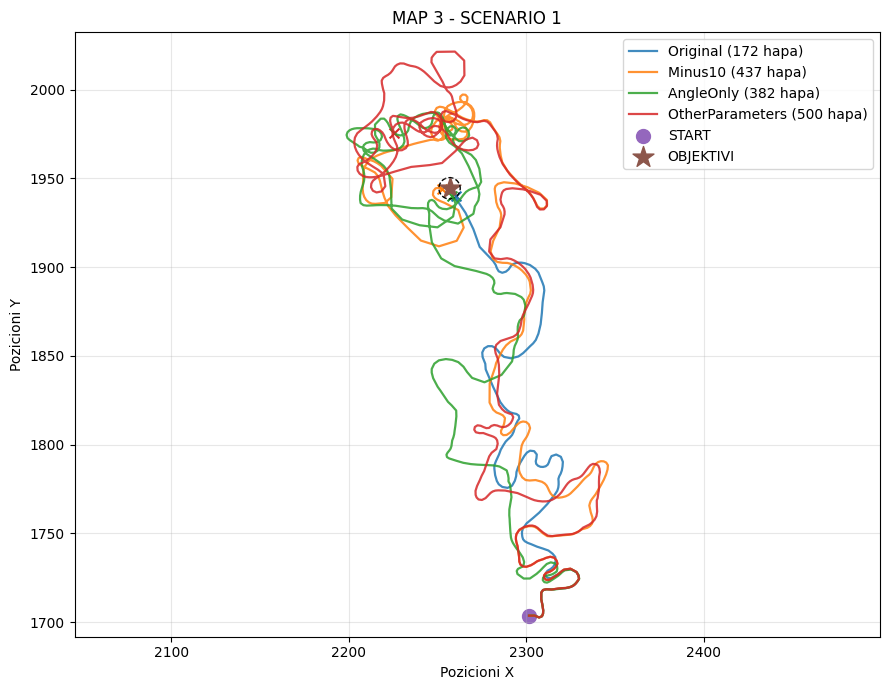

Grafiku u ruajt: step55_map3_scenario1.png
------------------------------------------------------------
MAP 2 - SCENARIO 4 | Original: Min distance = 364.70, Final distance = 446.15
MAP 2 - SCENARIO 4 | Minus10: Min distance = 251.00, Final distance = 251.09


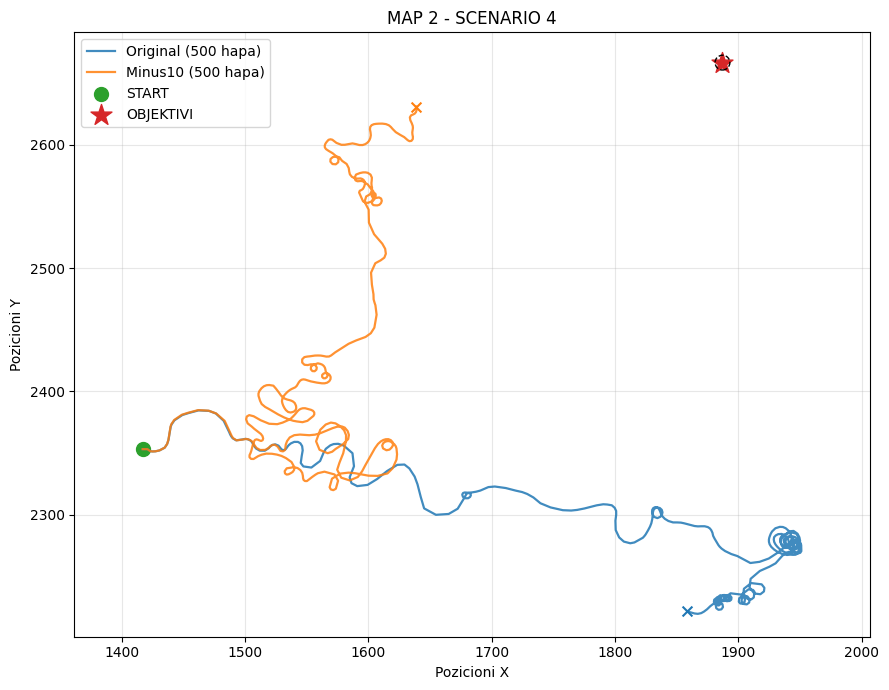

Grafiku u ruajt: step55_map2_scenario4.png
------------------------------------------------------------

VIZUALIZIMI PERFUNDOI!


In [14]:
import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path
import morphing_kaggle

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

data_path = project / "step54_trajectory_analysis.json"

assert data_path.exists(), "Mungon analiza e Hapit 54!"

with open(data_path, "r") as f:
    reports = json.load(f)

udp = morphing_kaggle.morphing_rover_UDP()

positions = (
    type(udp)
    .run_single_scenario
    .__globals__["SCENARIO_POSITIONS"]
)

experiments = [
    (3, 1, "MAP 3 - SCENARIO 1"),
    (2, 4, "MAP 2 - SCENARIO 4")
]

print("HAPI 55 - VIZUALIZIMI I TRAJEKTOREVE")
print("=" * 60)

for m, s, title in experiments:

    target = np.asarray(
        positions[m][s][2:4],
        dtype=float
    )

    plt.figure(figsize=(9, 7))

    relevant = [
        r for r in reports
        if r["map"] == m and r["scenario"] == s
    ]

    for report in relevant:

        xy = np.array([
            [row["x"], row["y"]]
            for row in report["trajectory"]
        ])

        name = report["candidate"]

        plt.plot(
            xy[:, 0],
            xy[:, 1],
            linewidth=1.6,
            alpha=0.85,
            label=f"{name} ({report['steps']} hapa)"
        )

        plt.scatter(
            xy[-1, 0],
            xy[-1, 1],
            marker="x",
            s=50
        )

        distance = np.linalg.norm(
            xy - target,
            axis=1
        )

        print(
            f"{title} | {name}: "
            f"Min distance = {distance.min():.2f}, "
            f"Final distance = {distance[-1]:.2f}"
        )

    if relevant:

        first_xy = np.array([
            [row["x"], row["y"]]
            for row in relevant[0]["trajectory"]
        ])

        plt.scatter(
            first_xy[0, 0],
            first_xy[0, 1],
            marker="o",
            s=100,
            label="START"
        )

    plt.scatter(
        target[0],
        target[1],
        marker="*",
        s=250,
        label="OBJEKTIVI"
    )

    circle = plt.Circle(
        tuple(target),
        radius=6,
        fill=False,
        linestyle="--"
    )

    plt.gca().add_patch(circle)

    plt.title(title)
    plt.xlabel("Pozicioni X")
    plt.ylabel("Pozicioni Y")
    plt.axis("equal")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    filename = project / f"step55_map{m}_scenario{s}.png"

    plt.savefig(filename, dpi=150)
    plt.show()

    print("Grafiku u ruajt:", filename.name)
    print("-" * 60)

print("\nVIZUALIZIMI PERFUNDOI!")

HAPI 56 - TEACHER TRAJECTORY COMPARISON

MAP 3, SCENARIO 1
------------------------------------------------------------
Original score: 7.679681
Teacher score:  3.952116
Teacher hapa:  89
Teacher sukses: PO
Distanca minimale: 4.35


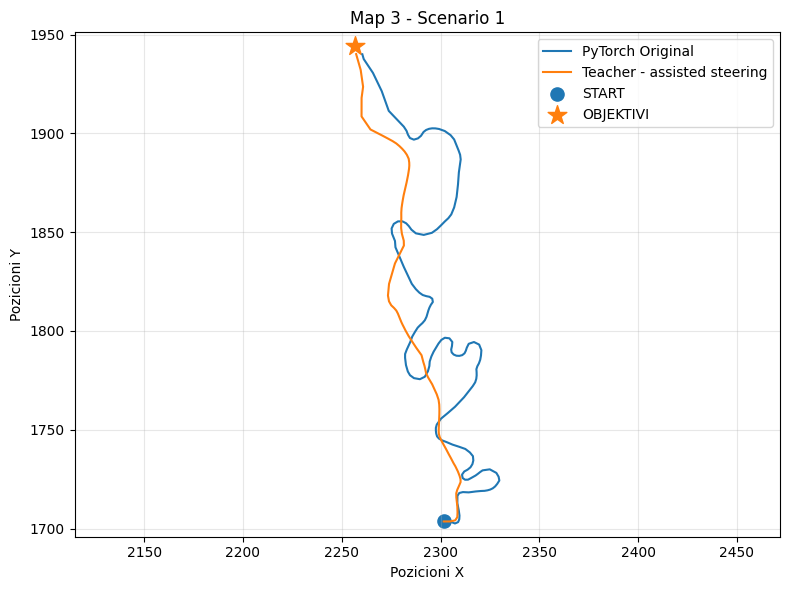


MAP 2, SCENARIO 4
------------------------------------------------------------
Original score: 17.405759
Teacher score:  3.463339
Teacher hapa:  179
Teacher sukses: PO
Distanca minimale: 3.46


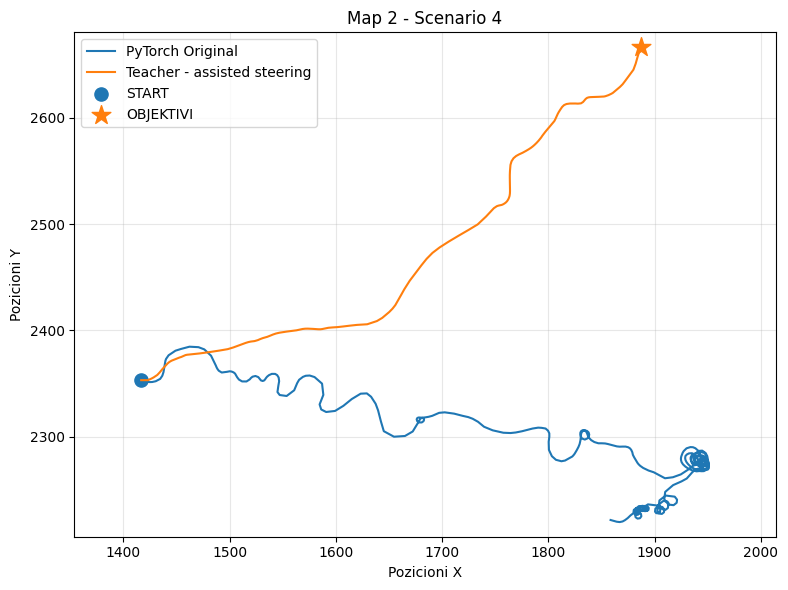


HAPI 56 PERFUNDOI
Backup: Morphing_Rovers_Step56_Backup.zip
ZIP: OK
Rekordi ESA-style mbetet i pandryshuar.


In [15]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import morphing_kaggle
import zipfile
import json
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

best_path = project / "student_pytorch_retrained.npy"
analysis_path = project / "step54_trajectory_analysis.json"

assert best_path.exists(), "Mungon kandidati 4.808299!"
assert analysis_path.exists(), "Mungon analiza e Hapit 54!"

best = np.load(best_path)

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

sim_globals = type(udp).run_single_scenario.__globals__
MAX_DA = float(sim_globals["MAX_DA"])
positions = sim_globals["SCENARIO_POSITIONS"]

with open(analysis_path) as f:
    old_reports = json.load(f)

class Recorder:
    def __init__(self):
        self.rows = []

    def add(self, map_number, scenario_number, data):
        self.rows.append(dict(data))

results = []
graphs = []

print("HAPI 56 - TEACHER TRAJECTORY COMPARISON")
print("=" * 60, flush=True)

for m, s in [(3, 1), (2, 4)]:

    rover = RoverClass(best)
    recorder = Recorder()

    def steering_assist(module, inputs, outputs):
        landscape, state, memory = inputs
        mode, angle, latent = outputs

        desired = torch.clamp(
            (state.reshape(-1)[2] * np.pi) / MAX_DA,
            -1.0, 1.0
        ).reshape_as(angle)

        corrected = torch.clamp(
            0.5 * angle + 0.5 * desired,
            -1.0, 1.0
        )

        return mode, corrected, latent

    hook = rover.Control.register_forward_hook(steering_assist)

    try:
        d, T = udp.run_single_scenario(
            rover, m, s, detailed_results=recorder
        )
    finally:
        hook.remove()

    score = (1 + float(d)) * float(T)
    success = abs(float(d)) < 1e-10

    teacher_xy = np.array([
        [row["x"], row["y"]]
        for row in recorder.rows
    ])

    original = next(
        r for r in old_reports
        if r["map"] == m
        and r["scenario"] == s
        and r["candidate"] == "Original"
    )

    original_xy = np.array([
        [row["x"], row["y"]]
        for row in original["trajectory"]
    ])

    target = np.asarray(
        positions[m][s][2:4], dtype=float
    )

    min_dist = float(
        np.linalg.norm(
            teacher_xy - target, axis=1
        ).min()
    )

    print(f"\nMAP {m}, SCENARIO {s}")
    print("-" * 60)
    print(f"Original score: {original['fitness']:.6f}")
    print(f"Teacher score:  {score:.6f}")
    print(f"Teacher hapa:  {len(teacher_xy)-1}")
    print(f"Teacher sukses: {'PO' if success else 'JO'}")
    print(f"Distanca minimale: {min_dist:.2f}", flush=True)

    plt.figure(figsize=(8, 6))

    plt.plot(
        original_xy[:, 0], original_xy[:, 1],
        label="PyTorch Original"
    )

    plt.plot(
        teacher_xy[:, 0], teacher_xy[:, 1],
        label="Teacher - assisted steering"
    )

    plt.scatter(
        *teacher_xy[0], marker="o", s=90,
        label="START"
    )

    plt.scatter(
        *target, marker="*", s=200,
        label="OBJEKTIVI"
    )

    plt.title(f"Map {m} - Scenario {s}")
    plt.xlabel("Pozicioni X")
    plt.ylabel("Pozicioni Y")
    plt.axis("equal")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    graph_path = project / f"step56_map{m}_scenario{s}.png"
    plt.savefig(graph_path, dpi=150)
    plt.show()

    graphs.append(graph_path)

    results.append({
        "map": m,
        "scenario": s,
        "original_score": original["fitness"],
        "teacher_score": score,
        "teacher_success": success,
        "teacher_steps": len(teacher_xy) - 1,
        "teacher_min_distance": min_dist
    })

result_path = project / "step56_teacher_comparison.json"

with open(result_path, "w") as f:
    json.dump(results, f, indent=4)

backup = Path(
    "/kaggle/working/Morphing_Rovers_Step56_Backup.zip"
)

with zipfile.ZipFile(backup, "w", zipfile.ZIP_DEFLATED) as z:
    z.write(best_path, best_path.name)
    z.write(result_path, result_path.name)

    for graph_path in graphs:
        z.write(graph_path, graph_path.name)

with zipfile.ZipFile(backup) as z:
    assert z.testzip() is None

print("\n" + "=" * 60)
print("HAPI 56 PERFUNDOI")
print("Backup:", backup.name)
print("ZIP: OK")
print("Rekordi ESA-style mbetet i pandryshuar.")

In [1]:
from pathlib import Path

folder = Path("/kaggle/working")

for name in [
    "Morphing_Rovers_Step56_Backup.zip",
    "Morphing_Rovers_Teacher_Data_Backup.zip"
]:
    file = folder / name

    if file.exists():
        print("GJETUR:", name)
        print("Madhesia:", round(file.stat().st_size / 1024**2, 2), "MB")
    else:
        print("MUNGON:", name)

MUNGON: Morphing_Rovers_Step56_Backup.zip
MUNGON: Morphing_Rovers_Teacher_Data_Backup.zip


In [2]:
import numpy as np
import zipfile
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

filename = "student_pytorch_retrained.npy"

# Kerkojme kandidatin ne dataset-et e ruajtura
matches = list(Path("/kaggle/input").rglob(filename))

if matches:
    candidate = np.load(matches[0], allow_pickle=False)

    assert candidate.shape == (19133,)
    assert np.isfinite(candidate).all()

    best_path = project / "best_confirmed_4808299.npy"
    np.save(best_path, candidate)

    backup = Path(
        "/kaggle/working/Morphing_Rovers_BEST_4808299.zip"
    )

    with zipfile.ZipFile(backup, "w", zipfile.ZIP_DEFLATED) as z:
        z.write(best_path, best_path.name)

    with zipfile.ZipFile(backup) as z:
        assert z.testzip() is None

    print("SUKSES! KANDIDATI U RIKTHYE!")
    print("Fitness historik: 4.808299")
    print("Parametra:", len(candidate))
    print("Backup:", backup.name)
    print("ZIP: OK")

else:
    print("Kandidati nuk u gjet te Input.")
    print("Kontrollo a eshte ende i shtuar dataset-i.")

SUKSES! KANDIDATI U RIKTHYE!
Fitness historik: 4.808299
Parametra: 19133
Backup: Morphing_Rovers_BEST_4808299.zip
ZIP: OK


In [3]:

import numpy as np
import torch
import zipfile
import json
import time
import morphing_kaggle
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

# Kandidati yne me fitness 4.808299
best_path = project / "best_confirmed_4808299.npy"

assert best_path.exists(), (
    "Mungon kandidati 4.808299! "
    "Riktheje nga backup-i."
)

best = np.load(best_path)

assert best.shape == (19133,)
assert np.isfinite(best).all()

udp = morphing_kaggle.morphing_rover_UDP()

RoverClass = type(udp).fitness.__globals__["Rover"]

MAX_DA = float(
    type(udp).run_single_scenario.__globals__["MAX_DA"]
)

rover = RoverClass(best)

landscapes = []
states = []
memories = []
targets = []
original_angles = []
map_ids = []
scenario_ids = []

context = {
    "map": 0,
    "scenario": 0,
    "step": 0
}

start_time = time.time()

print("HAPI 57 - TEACHER DATA COLLECTION")
print("=" * 60, flush=True)
print("Kandidati baze: 4.808299")
print("Po mblidhen te dhenat nga Teacher-i...\n", flush=True)


def collect_teacher_data(module, inputs, outputs):

    landscape, state, memory = inputs
    mode, angle, latent = outputs

    # Llogarisim drejtimin e deshiruar
    desired = torch.clamp(
        (state.reshape(-1)[2] * np.pi) / MAX_DA,
        min=-1.0,
        max=1.0
    ).reshape_as(angle)

    # Teacher-i kombinon drejtimin aktual
    # me drejtimin e deshiruar
    teacher_angle = torch.clamp(
        0.5 * angle + 0.5 * desired,
        min=-1.0,
        max=1.0
    )

    # Ruajme te dhena cdo hap te dyte
    if context["step"] % 2 == 0:

        landscapes.append(
            landscape.detach().cpu().numpy()
            .reshape(89, 89).astype(np.float32).copy()
        )

        states.append(
            state.detach().cpu().numpy()
            .reshape(9).astype(np.float32).copy()
        )

        memories.append(
            memory.detach().cpu().numpy()
            .reshape(40).astype(np.float32).copy()
        )

        targets.append(
            float(
                teacher_angle.detach()
                .reshape(-1)[0].cpu()
            )
        )

        original_angles.append(
            float(
                angle.detach()
                .reshape(-1)[0].cpu()
            )
        )

        map_ids.append(context["map"])
        scenario_ids.append(context["scenario"])

    context["step"] += 1

    return mode, teacher_angle, latent


hook = rover.Control.register_forward_hook(
    collect_teacher_data
)

scores = np.zeros((6, 5))
successes = 0

try:

    for m in range(6):

        map_successes = 0

        for s in range(5):

            context["map"] = m
            context["scenario"] = s
            context["step"] = 0

            d, T = udp.run_single_scenario(
                rover, m, s
            )

            d = float(d)
            T = float(T)

            scores[m, s] = (1 + d) * T

            if abs(d) < 1e-10:
                successes += 1
                map_successes += 1

        print(
            f"Map {m}: "
            f"Fitness = {scores[m].mean():.6f} | "
            f"Suksese = {map_successes}/5",
            flush=True
        )

finally:
    hook.remove()


teacher_fitness = float(scores.mean())

print("\nPO RUAHET DATASET-I...", flush=True)

data_path = project / "teacher_pytorch_trajectories.npz"

np.savez_compressed(
    data_path,
    landscape=np.stack(landscapes),
    state=np.stack(states),
    past_state=np.stack(memories),
    target=np.asarray(targets, dtype=np.float32),
    original_angle=np.asarray(
        original_angles, dtype=np.float32
    ),
    map_ids=np.asarray(map_ids),
    scenario_ids=np.asarray(scenario_ids),
    scenario_scores=scores
)

# Backup me kandidatin dhe te dhenat
backup_path = Path(
    "/kaggle/working/Morphing_Rovers_Teacher_Data_Backup.zip"
)

with zipfile.ZipFile(
    backup_path,
    "w",
    compression=zipfile.ZIP_STORED
) as z:

    z.write(best_path, best_path.name)
    z.write(data_path, data_path.name)

    z.writestr(
        "teacher_results.json",
        json.dumps({
            "teacher_fitness": teacher_fitness,
            "teacher_successes": successes,
            "student_historical_fitness": 4.808299,
            "teacher_is_valid_esa_chromosome": False,
            "samples": len(targets)
        }, indent=4)
    )

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\n" + "=" * 60)
print("HAPI 57 PERFUNDOI!")
print("=" * 60)

print(f"Teacher fitness: {teacher_fitness:.6f}")
print(f"Teacher suksese: {successes}/30")
print(f"Mostra te mbledhura: {len(targets)}")

print("\nDataset:", data_path.name)
print("Backup:", backup_path.name)

print(
    "Madhesia e backup-it:",
    round(backup_path.stat().st_size / 1024**2, 2),
    "MB"
)

print("ZIP: OK")
print(
    "Koha:",
    round(time.time() - start_time, 2),
    "sekonda"
)

print("\nRekordi i vlefshem mbetet 4.808299.")


ModuleNotFoundError: No module named 'morphing_kaggle'

In [1]:

from pathlib import Path
import os
import sys

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
input_root = Path("/kaggle/input")

print("KONTROLLI I PROJEKTIT MORPHING ROVERS")
print("=" * 55)

# Kontrollojme kodin e simulatorit
simulator = project / "morphing_kaggle.py"
coordinates = project / "data" / "coordinates.txt"

print("Folderi i projektit:", project.exists())
print("Kodi morphing_kaggle.py:", simulator.exists())
print("Te dhenat e hartave:", coordinates.exists())

# Kontrollojme backup-in e kandidatit
names = [
    "student_pytorch_retrained.npy",
    "best_confirmed_4808299.npy"
]

found = []

for name in names:
    found.extend(input_root.rglob(name))
    found.extend(project.rglob(name)) if project.exists() else None

print("\nKANDIDATI ME I MIRE")
print("=" * 55)

if found:
    for path in found:
        print("GJETUR:", path)
else:
    print("Kandidati nuk u gjet si NPY.")
    print("Do te kontrollojme backup-in ZIP.")

# Nese kodi i simulatorit ekziston, provojme importin
if simulator.exists() and coordinates.exists():

    os.chdir(project)

    if str(project) not in sys.path:
        sys.path.insert(0, str(project))

    try:
        import morphing_kaggle
        print("\nSIMULATORI ESA ESHTE GATI!")
    except Exception as e:
        print("\nPROBLEM GJATE IMPORTIT:")
        print(type(e).__name__, str(e))

else:
    print("\nSimulatori duhet rikthyer para Hapit 57.")

print("\nKONTROLLI PERFUNDOI!")


KONTROLLI I PROJEKTIT MORPHING ROVERS
Folderi i projektit: False
Kodi morphing_kaggle.py: False
Te dhenat e hartave: False

KANDIDATI ME I MIRE
GJETUR: /kaggle/input/datasets/jolashala/morphing-rovers-dagger-v2-evaluated-backup/student_pytorch_retrained.npy

Simulatori duhet rikthyer para Hapit 57.

KONTROLLI PERFUNDOI!


In [1]:

from pathlib import Path
import subprocess
import shutil
import sys
import os
import numpy as np

source = Path("/kaggle/working/ESA_SpOC2_Source")
project = Path("/kaggle/working/SpOC2/Morphing Rovers")
input_root = Path("/kaggle/input")

print("RIKTHIMI I SIMULATORIT ESA")
print("=" * 55)

# Shkarkojme kodin zyrtar vetem nese mungon
if not (project / "morphing_kaggle.py").exists():

    if not (source / "Morphing Rovers" / "morphing_kaggle.py").exists():

        print("Po shkarkohet kodi zyrtar i ESA...", flush=True)

        if source.exists():
            raise RuntimeError(
                "Folderi i shkarkimit ekziston, por eshte jo i plote."
            )

        subprocess.run(
            [
                "git", "clone", "--depth", "1",
                "https://github.com/esa/SpOC2.git",
                str(source)
            ],
            check=True
        )

    shutil.copytree(
        source / "Morphing Rovers",
        project,
        dirs_exist_ok=True
    )

print("Kodi i simulatorit:",
      (project / "morphing_kaggle.py").exists())

# Kontrollojme nese ekzistojne te dhenat e hartave
coordinates = project / "data" / "coordinates.txt"

if not coordinates.exists():
    matches = list(input_root.rglob("coordinates.txt"))

    if matches:
        coordinates.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(matches[0], coordinates)

print("Coordinates:", coordinates.exists())

# Rikthejme kandidatin me te mire nga Kaggle Input
matches = list(input_root.rglob("student_pytorch_retrained.npy"))

assert matches, "Kandidati nuk u gjet ne Kaggle Input!"

candidate = np.load(matches[0], allow_pickle=False)

assert candidate.shape == (19133,)
assert np.isfinite(candidate).all()

best_path = project / "best_confirmed_4808299.npy"
np.save(best_path, candidate)

print("Kandidati 4.808299: U RIKTHYE")
print("Parametra:", len(candidate))

# Pergatisim importimin e simulatorit
os.chdir(project)

if str(project) not in sys.path:
    sys.path.insert(0, str(project))

if coordinates.exists():

    try:
        import morphing_kaggle

        udp = morphing_kaggle.morphing_rover_UDP()

        print("\nSIMULATORI ESHTE GATI!")
        print("Numri i parametrave:", len(udp.example()))

    except Exception as error:
        print("\nSIMULATORI KA ENDE NJE PROBLEM:")
        print(type(error).__name__, str(error))

else:
    print("\nMUNGON coordinates.txt.")
    print("Duhet rikthyer edhe dataset-i i hartave.")

print("\nKONTROLLI PERFUNDOI!")


RIKTHIMI I SIMULATORIT ESA
Po shkarkohet kodi zyrtar i ESA...


Cloning into '/kaggle/working/ESA_SpOC2_Source'...


Kodi i simulatorit: False
Coordinates: True
Kandidati 4.808299: U RIKTHYE
Parametra: 19133

SIMULATORI KA ENDE NJE PROBLEM:
ModuleNotFoundError No module named 'morphing_kaggle'

KONTROLLI PERFUNDOI!


In [1]:

import os
import sys
import shutil
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

print("RIKTHIMI I MORPHING_KAGGLE")
print("=" * 55)

# Kerkojme simulatorin te dataset-et e Kaggle
sources = list(
    Path("/kaggle/input").rglob("morphing_kaggle.py")
)

# Kontrollojme edhe repository-n e shkarkuar
repo = Path("/kaggle/working/ESA_SpOC2_Source")

if repo.exists():
    sources += list(repo.rglob("morphing_kaggle.py"))

simulator = project / "morphing_kaggle.py"

if simulator.exists():
    print("Simulatori ekziston ne projekt.")

elif sources:
    print("Simulatori u gjet te:")
    print(sources[0])

    shutil.copy2(sources[0], simulator)
    print("Simulatori u kopjua me sukses!")

else:
    print("morphing_kaggle.py nuk u gjet.")
    print("\nSkedaret Python ne Kaggle Input:")

    for p in Path("/kaggle/input").rglob("*.py"):
        print("-", p)

if simulator.exists():

    os.chdir(project)

    if str(project) not in sys.path:
        sys.path.insert(0, str(project))

    try:
        import morphing_kaggle

        udp = morphing_kaggle.morphing_rover_UDP()

        print("\nSIMULATORI U HAP ME SUKSES!")
        print("Skedari:", simulator)
        print("Parametra:", len(udp.example()))

    except Exception as e:
        print("\nGABIM GJATE HAPJES:")
        print(type(e).__name__, str(e))

print("\nKONTROLLI PERFUNDOI!")


RIKTHIMI I MORPHING_KAGGLE
Simulatori u gjet te:
/kaggle/input/datasets/jolashala/morphing-rovers-backup/morphing_kaggle.py
Simulatori u kopjua me sukses!

GABIM GJATE HAPJES:
FileNotFoundError [Errno 2] No such file or directory: './data/coordinates.txt'

KONTROLLI PERFUNDOI!


In [2]:

import os
import sys
import shutil
import importlib
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

coordinates = project / "data" / "coordinates.txt"
simulator = project / "morphing_kaggle.py"

print("RREGULLIMI I SIMULATORIT ESA")
print("=" * 55)

print("Simulatori ekziston:", simulator.exists())
print("Coordinates ekziston:", coordinates.exists())

# Kerkojme koordinatat ne folderat ekzistues
if not coordinates.is_file():

    locations = [
        Path("/kaggle/working/ESA_SpOC2_Source"),
        Path("/kaggle/working/SpOC2"),
        Path("/kaggle/input")
    ]

    matches = []

    for location in locations:
        if location.exists():
            matches.extend(
                p for p in location.rglob("coordinates.txt")
                if p.is_file() and p != coordinates
            )

    if matches:
        coordinates.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(matches[0], coordinates)

        print("Koordinatat u rikthyen nga:")
        print(matches[0])

    else:
        print("Koordinatat nuk u gjeten.")

# Vendosim folderin e sakte te punes
os.chdir(project)

if str(project) not in sys.path:
    sys.path.insert(0, str(project))

print("\nFOLDERI AKTUAL:", Path.cwd())
print("Simulatori:", simulator.is_file())
print("Coordinates:", Path("./data/coordinates.txt").is_file())

# Provojme hapjen e simulatorit
if simulator.is_file() and coordinates.is_file():

    try:
        importlib.invalidate_caches()

        import morphing_kaggle

        udp = morphing_kaggle.morphing_rover_UDP()

        lower, upper = udp.get_bounds()

        print("\nSIMULATORI U HAP ME SUKSES!")
        print("Numri i parametrave:", len(lower))
        print("Kandidati yne historik: 4.808299")
        print("GATI PER HAPIN 57!")

    except Exception as e:
        print("\nGABIM GJATE HAPJES:")
        print(type(e).__name__, str(e))

else:
    print("\nMUNGON NJE SKEDAR I DOMOSDOSHEM.")

print("\nKONTROLLI PERFUNDOI!")


RREGULLIMI I SIMULATORIT ESA
Simulatori ekziston: True
Coordinates ekziston: False
Koordinatat nuk u gjeten.

FOLDERI AKTUAL: /kaggle/working/SpOC2/Morphing Rovers
Simulatori: True
Coordinates: False

MUNGON NJE SKEDAR I DOMOSDOSHEM.

KONTROLLI PERFUNDOI!


In [3]:

from pathlib import Path, PurePosixPath
import zipfile
import shutil
import os
import sys

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
data_folder = project / "data"

roots = [
    Path("/kaggle/working/ESA_SpOC2_Source"),
    Path("/kaggle/input")
]

print("RIKTHIMI I TE DHENAVE TE ESA")
print("=" * 55)

found = False

# Kerkojme folderin origjinal data
for root in roots:
    if not root.exists():
        continue

    for file in root.rglob("coordinates.txt"):
        if file.parent.name == "data":
            print("U gjet folderi data:", file.parent)

            shutil.copytree(
                file.parent,
                data_folder,
                dirs_exist_ok=True
            )

            found = True
            break

    if found:
        break

# Nese mungon, kerkojme brenda ZIP-ave
if not found:

    for root in roots:
        if not root.exists():
            continue

        for archive in root.rglob("*.zip"):

            try:
                with zipfile.ZipFile(archive) as z:

                    members = z.namelist()

                    has_coordinates = any(
                        "data" in PurePosixPath(name).parts
                        and PurePosixPath(name).name == "coordinates.txt"
                        for name in members
                    )

                    if not has_coordinates:
                        continue

                    print("U gjet arkivi:", archive.name)

                    data_folder.mkdir(
                        parents=True, exist_ok=True
                    )

                    count = 0

                    for member in members:

                        parts = PurePosixPath(member).parts

                        if "data" not in parts or member.endswith("/"):
                            continue

                        idx = parts.index("data")
                        relative = parts[idx + 1:]

                        if not relative or ".." in relative:
                            continue

                        destination = data_folder.joinpath(*relative)
                        destination.parent.mkdir(
                            parents=True, exist_ok=True
                        )

                        with z.open(member) as src:
                            with open(destination, "wb") as dst:
                                shutil.copyfileobj(src, dst)

                        count += 1

                    print("Skedare te rikthyer:", count)
                    found = True
                    break

            except (zipfile.BadZipFile, OSError):
                continue

        if found:
            break

print("\nKONTROLLI")
print("=" * 55)

coordinates = data_folder / "coordinates.txt"

print("Simulatori:",
      (project / "morphing_kaggle.py").is_file())
print("Coordinates:", coordinates.is_file())

if data_folder.exists():
    files = [p for p in data_folder.rglob("*") if p.is_file()]
    print("Skedare ne data:", len(files))

if coordinates.is_file():

    os.chdir(project)

    if str(project) not in sys.path:
        sys.path.insert(0, str(project))

    try:
        import morphing_kaggle

        udp = morphing_kaggle.morphing_rover_UDP()

        print("\nSIMULATORI ESHTE GATI!")
        print("Parametra:", len(udp.get_bounds()[0]))

    except Exception as e:
        print("\nGABIM:", type(e).__name__, str(e))

else:
    print("\nDATA FOLDER NUK U GJET.")
    print("Duhet ta shtojme dataset-in e hartave ESA.")

print("\nKONTROLLI PERFUNDOI!")


RIKTHIMI I TE DHENAVE TE ESA

KONTROLLI
Simulatori: True
Coordinates: False

DATA FOLDER NUK U GJET.
Duhet ta shtojme dataset-in e hartave ESA.

KONTROLLI PERFUNDOI!


In [1]:

from pathlib import Path
import subprocess
import shutil

repo = Path("/kaggle/working/ESA_SpOC2_Source")
project = Path("/kaggle/working/SpOC2/Morphing Rovers")

print("KONTROLLI I TE DHENAVE NE GITHUB")
print("=" * 55)

if not (repo / ".git").exists():
    print("Repository Git nuk u gjet.")
else:
    result = subprocess.run(
        [
            "git", "-C", str(repo),
            "ls-tree", "-r", "--name-only", "HEAD"
        ],
        capture_output=True,
        text=True
    )

    if result.returncode != 0:
        print("Gabim Git:", result.stderr)
    else:
        files = result.stdout.splitlines()

        data_files = [
            f for f in files
            if f.startswith("Morphing Rovers/data/")
        ]

        print("Skedare gjithsej ne Git:", len(files))
        print("Skedare ne Morphing Rovers/data:", len(data_files))

        for name in data_files[:30]:
            print("-", name)

        if data_files:
            subprocess.run(
                [
                    "git", "-C", str(repo),
                    "restore", "--source=HEAD",
                    "--worktree", "--",
                    "Morphing Rovers/data"
                ],
                check=True
            )

            source = repo / "Morphing Rovers" / "data"

            if source.exists():
                shutil.copytree(
                    source,
                    project / "data",
                    dirs_exist_ok=True
                )
        else:
            print(
                "\nFolderi data nuk eshte i regjistruar "
                "ne kete version te Git."
            )

coordinates = project / "data" / "coordinates.txt"

print("\nREZULTATI")
print("=" * 55)
print("Coordinates:", coordinates.exists())

if coordinates.exists():
    print("Koordinatat u rikthyen!")
else:
    print("Na duhet burimi origjinal i te dhenave ESA.")

print("KONTROLLI PERFUNDOI!")


KONTROLLI I TE DHENAVE NE GITHUB
Repository Git nuk u gjet.

REZULTATI
Coordinates: False
Na duhet burimi origjinal i te dhenave ESA.
KONTROLLI PERFUNDOI!


In [1]:

from pathlib import Path
import subprocess
import shutil
import os
import sys

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
repo = Path("/kaggle/working/ESA_SpOC2_RECOVERY")

coordinates = project / "data" / "coordinates.txt"

print("RIKTHIMI I HARTAVE ESA")
print("=" * 55, flush=True)

# Shkarkojme repository-n ne nje folder te ri
if not repo.exists():

    print("Po shkarkohet projekti nga GitHub...", flush=True)

    try:
        result = subprocess.run(
            [
                "git", "clone", "--depth", "1",
                "https://github.com/esa/SpOC2.git",
                str(repo)
            ],
            capture_output=True,
            text=True,
            timeout=120
        )

        print("Git return code:", result.returncode)

        if result.returncode != 0:
            print("Gabimi:", result.stderr[-1500:])

    except subprocess.TimeoutExpired:
        print("Shkarkimi nuk perfundoi brenda kufirit.")

else:
    print("Folderi i shkarkimit ekziston.")

# Kerkojme te dhenat origjinale
source_data = repo / "Morphing Rovers" / "data"

print("\nKONTROLLI I SKEDAREVE")
print("=" * 55)

print("Repository:", repo.exists())
print("Folderi data:", source_data.exists())

if source_data.exists():

    shutil.copytree(
        source_data,
        project / "data",
        dirs_exist_ok=True
    )

    print("Te dhenat u kopjuan!")

print("Coordinates:", coordinates.exists())

# Provojme simulatorin
if coordinates.exists():

    os.chdir(project)

    if str(project) not in sys.path:
        sys.path.insert(0, str(project))

    try:
        import morphing_kaggle

        udp = morphing_kaggle.morphing_rover_UDP()

        print("\nSIMULATORI ESHTE GATI!")
        print("Parametra:", len(udp.get_bounds()[0]))

    except Exception as e:
        print("\nGABIM:", type(e).__name__, str(e))

else:
    print("\nKoordinatat ende mungojne.")
    print("Kontrollojme rezultatin e Git me lart.")

print("\nKONTROLLI PERFUNDOI!")


RIKTHIMI I HARTAVE ESA
Po shkarkohet projekti nga GitHub...
Git return code: 0

KONTROLLI I SKEDAREVE
Repository: True
Folderi data: True
Te dhenat u kopjuan!
Coordinates: True

GABIM: ModuleNotFoundError No module named 'morphing_kaggle'

KONTROLLI PERFUNDOI!


In [2]:

import os
import sys
import shutil
import importlib
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
repo = Path("/kaggle/working/ESA_SpOC2_RECOVERY")
input_root = Path("/kaggle/input")

project.mkdir(parents=True, exist_ok=True)

print("RREGULLIMI PERFUNDIMTAR I PROJEKTIT")
print("=" * 55)

# Rikthejme te dhenat e hartave nga repository
source_data = repo / "Morphing Rovers" / "data"
target_data = project / "data"

if source_data.is_dir():
    shutil.copytree(
        source_data,
        target_data,
        dirs_exist_ok=True
    )

# Rikthejme simulatorin nga Kaggle Input
simulator = project / "morphing_kaggle.py"

if not simulator.is_file():
    matches = list(input_root.rglob("morphing_kaggle.py"))

    assert matches, "morphing_kaggle.py nuk u gjet!"

    shutil.copy2(matches[0], simulator)

# Rikthejme kandidatin me fitness 4.808299
matches = list(
    input_root.rglob("student_pytorch_retrained.npy")
)

assert matches, "Mungon kandidati ne Kaggle Input!"

candidate = np.load(matches[0], allow_pickle=False)

assert candidate.shape == (19133,)
assert np.isfinite(candidate).all()

np.save(
    project / "best_confirmed_4808299.npy",
    candidate
)

# Kontrollojme strukturen
assert simulator.is_file(), "Mungon simulatori!"
assert (target_data / "coordinates.txt").is_file(), (
    "Mungojne koordinatat!"
)

# Hapim simulatorin nga folderi i sakte
os.chdir(project)

if str(project) not in sys.path:
    sys.path.insert(0, str(project))

importlib.invalidate_caches()

if "morphing_kaggle" in sys.modules:
    del sys.modules["morphing_kaggle"]

import morphing_kaggle

udp = morphing_kaggle.morphing_rover_UDP()

lower, upper = udp.get_bounds()

assert len(lower) == 19133
assert len(upper) == 19133

print("\nSIMULATORI U HAP ME SUKSES!")
print("Koordinatat: OK")
print("Kandidati: OK")
print("Parametra:", len(candidate))
print("Fitness historik: 4.808299")
print("GATI PER TESTIM DHE DOREZIM!")


RREGULLIMI PERFUNDIMTAR I PROJEKTIT

SIMULATORI U HAP ME SUKSES!
Koordinatat: OK
Kandidati: OK
Parametra: 19133
Fitness historik: 4.808299
GATI PER TESTIM DHE DOREZIM!


In [3]:

import numpy as np
import morphing_kaggle
import zipfile
import json
import time
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

best_path = project / "best_confirmed_4808299.npy"

assert best_path.exists(), "Mungon kandidati me i mire!"

candidate = np.load(best_path, allow_pickle=False)

assert candidate.shape == (19133,)
assert np.isfinite(candidate).all()

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

lower, upper = map(np.asarray, udp.get_bounds())

assert np.all(candidate >= lower)
assert np.all(candidate <= upper)

rover = RoverClass(candidate)

scores = np.zeros((6, 5))
distances = np.zeros((6, 5))
times = np.zeros((6, 5))

successes = 0
start = time.time()

print("HAPI 58 - FINAL FITNESS VERIFICATION")
print("=" * 60, flush=True)

for m in range(6):

    map_successes = 0

    for s in range(5):

        d, T = udp.run_single_scenario(rover, m, s)

        d = float(d)
        T = float(T)

        distances[m, s] = d
        times[m, s] = T

        scores[m, s] = (1 + d) * T

        if abs(d) < 1e-10:
            successes += 1
            map_successes += 1

    print(
        f"Map {m}: Fitness = {scores[m].mean():.6f} | "
        f"Suksese = {map_successes}/5",
        flush=True
    )

fitness = float(scores.mean())

results_path = project / "final_verified_results.npz"

np.savez_compressed(
    results_path,
    scores=scores,
    distances=distances,
    times=times
)

summary = {
    "project": "ESA SpOC-2 Morphing Rovers",
    "method": "PyTorch AdamW - Teacher Student",
    "fitness": fitness,
    "successes": successes,
    "total_scenarios": 30,
    "chromosome_parameters": len(candidate),
    "map_fitness": scores.mean(axis=1).tolist()
}

backup_path = Path(
    "/kaggle/working/Morphing_Rovers_FINAL_VERIFIED.zip"
)

with zipfile.ZipFile(
    backup_path, "w", zipfile.ZIP_DEFLATED
) as z:

    z.write(best_path, "best_candidate.npy")
    z.write(results_path, results_path.name)

    z.writestr(
        "final_summary.json",
        json.dumps(summary, indent=4)
    )

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\n" + "=" * 60)
print("REZULTATI FINAL I VERIFIKIMIT")
print("=" * 60)

print(f"FITNESS: {fitness:.6f}")
print(f"SUKSESE: {successes}/30")

print("\nRekordi historik: 4.808299")
print(f"Diferenca: {fitness - 4.808299:+.6f}")

if abs(fitness - 4.808299) < 0.00001:
    print("SUKSES! REZULTATI U RIPRODHUA!")
else:
    print("Rezultati ndryshon. Duhet analizuar.")

print("\nBackup:", backup_path.name)
print("ZIP: OK")
print("Koha:", round(time.time() - start, 2), "sekonda")


HAPI 58 - FINAL FITNESS VERIFICATION
Map 0: Fitness = 3.070738 | Suksese = 1/5
Map 1: Fitness = 3.679826 | Suksese = 1/5
Map 2: Fitness = 8.752524 | Suksese = 0/5
Map 3: Fitness = 5.091121 | Suksese = 3/5
Map 4: Fitness = 4.823892 | Suksese = 0/5
Map 5: Fitness = 3.431692 | Suksese = 0/5

REZULTATI FINAL I VERIFIKIMIT
FITNESS: 4.808299
SUKSESE: 5/30

Rekordi historik: 4.808299
Diferenca: -0.000000
SUKSES! REZULTATI U RIPRODHUA!

Backup: Morphing_Rovers_FINAL_VERIFIED.zip
ZIP: OK
Koha: 27.24 sekonda


In [4]:

import numpy as np
import torch
import morphing_kaggle
import zipfile
import json
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

best_path = project / "best_confirmed_4808299.npy"

assert best_path.exists(), "Mungon kandidati 4.808299!"

best = np.load(best_path, allow_pickle=False)

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

MAX_DA = float(
    type(udp).run_single_scenario.__globals__["MAX_DA"]
)

results = {}

print("HAPI 59 - TEACHER STEERING COMPARISON")
print("=" * 60, flush=True)

for alpha in [0.50, 0.80]:

    rover = RoverClass(best)
    rover.Control.eval()

    def steering_hook(module, inputs, outputs):

        landscape, state, memory = inputs
        mode, angle, latent = outputs

        desired = torch.clamp(
            (state.reshape(-1)[2] * np.pi) / MAX_DA,
            -1.0, 1.0
        ).reshape_as(angle)

        corrected = torch.clamp(
            (1.0 - alpha) * angle + alpha * desired,
            -1.0, 1.0
        )

        return mode, corrected, latent

    hook = rover.Control.register_forward_hook(
        steering_hook
    )

    scores = np.zeros((6, 5))
    successes = 0

    print(f"\nTEACHER ALPHA = {alpha:.2f}", flush=True)

    try:
        for m in range(6):

            map_successes = 0

            for s in range(5):

                d, T = udp.run_single_scenario(rover, m, s)

                d = float(d)
                T = float(T)

                scores[m, s] = (1.0 + d) * T

                if abs(d) < 1e-10:
                    successes += 1
                    map_successes += 1

            print(
                f"Map {m}: "
                f"Fitness={scores[m].mean():.6f} | "
                f"Suksese={map_successes}/5",
                flush=True
            )

    finally:
        hook.remove()

    fitness = float(scores.mean())

    results[str(alpha)] = {
        "fitness": fitness,
        "successes": successes
    }

    print(f"\nFITNESS: {fitness:.6f}")
    print(f"SUKSESE: {successes}/30")

    np.save(
        project / f"teacher_alpha_{int(alpha * 100)}_scores.npy",
        scores
    )

print("\n" + "=" * 60)
print("KRAHASIMI PERFUNDIMTAR")
print("=" * 60)

print("Kandidati i vlefshem: 4.808299")

for alpha, result in results.items():
    print(
        f"Teacher {alpha}: "
        f"{result['fitness']:.6f} | "
        f"{result['successes']}/30"
    )

best_alpha = min(
    results,
    key=lambda a: results[a]["fitness"]
)

print("Asistimi me i mire:", best_alpha)

backup = Path(
    "/kaggle/working/Morphing_Rovers_Step59_Backup.zip"
)

with zipfile.ZipFile(backup, "w", zipfile.ZIP_DEFLATED) as z:

    z.write(best_path, best_path.name)

    for alpha in [50, 80]:
        file = project / f"teacher_alpha_{alpha}_scores.npy"
        z.write(file, file.name)

    z.writestr(
        "teacher_comparison.json",
        json.dumps(results, indent=4)
    )

with zipfile.ZipFile(backup) as z:
    assert z.testzip() is None

print("\nBACKUP:", backup.name)
print("ZIP: OK")
print("Kandidati 4.808299 mbetet i pandryshuar.")


HAPI 59 - TEACHER STEERING COMPARISON

TEACHER ALPHA = 0.50
Map 0: Fitness=1.950547 | Suksese=4/5
Map 1: Fitness=2.479211 | Suksese=3/5
Map 2: Fitness=3.046420 | Suksese=3/5
Map 3: Fitness=3.194486 | Suksese=5/5
Map 4: Fitness=3.444040 | Suksese=2/5
Map 5: Fitness=2.616469 | Suksese=2/5

FITNESS: 2.788529
SUKSESE: 19/30

TEACHER ALPHA = 0.80
Map 0: Fitness=1.804903 | Suksese=5/5
Map 1: Fitness=2.417007 | Suksese=4/5
Map 2: Fitness=2.985882 | Suksese=3/5
Map 3: Fitness=2.930902 | Suksese=5/5
Map 4: Fitness=2.589611 | Suksese=4/5
Map 5: Fitness=1.879328 | Suksese=5/5

FITNESS: 2.434605
SUKSESE: 26/30

KRAHASIMI PERFUNDIMTAR
Kandidati i vlefshem: 4.808299
Teacher 0.5: 2.788529 | 19/30
Teacher 0.8: 2.434605 | 26/30
Asistimi me i mire: 0.8

BACKUP: Morphing_Rovers_Step59_Backup.zip
ZIP: OK
Kandidati 4.808299 mbetet i pandryshuar.


In [5]:

import numpy as np
import torch
import zipfile
import json
import time
from pathlib import Path
import morphing_kaggle

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

best_path = project / "best_confirmed_4808299.npy"

assert best_path.exists(), "Mungon kandidati baze!"

best = np.load(best_path, allow_pickle=False)

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

MAX_DA = float(
    type(udp).run_single_scenario.__globals__["MAX_DA"]
)

rover = RoverClass(best)
rover.Control.eval()

alpha = 0.80

landscapes = []
states = []
memories = []
targets = []
original_angles = []
map_ids = []
scenario_ids = []

context = {
    "map": 0,
    "scenario": 0,
    "step": 0
}

print("HAPI 60 - TEACHER 80% DATA COLLECTION")
print("=" * 60, flush=True)

start_time = time.time()

def collect_teacher_80(module, inputs, outputs):

    landscape, state, memory = inputs
    mode, angle, latent = outputs

    desired = torch.clamp(
        (state.reshape(-1)[2] * np.pi) / MAX_DA,
        -1.0, 1.0
    ).reshape_as(angle)

    teacher_angle = torch.clamp(
        (1.0 - alpha) * angle + alpha * desired,
        -1.0, 1.0
    )

    # Ruajme nje moster cdo dy hapa
    if context["step"] % 2 == 0:

        landscapes.append(
            landscape.detach().cpu().numpy()
            .reshape(89, 89).astype(np.float32).copy()
        )

        states.append(
            state.detach().cpu().numpy()
            .reshape(9).astype(np.float32).copy()
        )

        memories.append(
            memory.detach().cpu().numpy()
            .reshape(40).astype(np.float32).copy()
        )

        targets.append(
            float(
                teacher_angle.detach().reshape(-1)[0]
            )
        )

        original_angles.append(
            float(
                angle.detach().reshape(-1)[0]
            )
        )

        map_ids.append(context["map"])
        scenario_ids.append(context["scenario"])

    context["step"] += 1

    return mode, teacher_angle, latent


hook = rover.Control.register_forward_hook(
    collect_teacher_80
)

scores = np.zeros((6, 5))
successes = 0

try:
    for m in range(6):

        map_successes = 0

        for s in range(5):

            context["map"] = m
            context["scenario"] = s
            context["step"] = 0

            d, T = udp.run_single_scenario(rover, m, s)

            d = float(d)
            T = float(T)

            scores[m, s] = (1.0 + d) * T

            if abs(d) < 1e-10:
                successes += 1
                map_successes += 1

        print(
            f"Map {m}: "
            f"Fitness={scores[m].mean():.6f} | "
            f"Suksese={map_successes}/5",
            flush=True
        )

finally:
    hook.remove()

teacher_fitness = float(scores.mean())

print("\nPO RUAHEN MOSTRAT...", flush=True)

data_path = project / "teacher80_training_data.npz"

np.savez_compressed(
    data_path,
    landscape=np.asarray(landscapes, dtype=np.float32),
    state=np.asarray(states, dtype=np.float32),
    past_state=np.asarray(memories, dtype=np.float32),
    target=np.asarray(targets, dtype=np.float32),
    original_angle=np.asarray(
        original_angles, dtype=np.float32
    ),
    map_ids=np.asarray(map_ids),
    scenario_ids=np.asarray(scenario_ids),
    scenario_scores=scores
)

backup_path = Path(
    "/kaggle/working/Morphing_Rovers_Teacher80_Data.zip"
)

with zipfile.ZipFile(
    backup_path, "w", zipfile.ZIP_STORED
) as z:

    z.write(best_path, best_path.name)
    z.write(data_path, data_path.name)

    z.writestr(
        "experiment.json",
        json.dumps({
            "alpha": alpha,
            "teacher_fitness": teacher_fitness,
            "teacher_successes": successes,
            "samples": len(targets),
            "student_fitness": 4.808299,
            "teacher_valid_for_submission": False
        }, indent=4)
    )

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\n" + "=" * 60)
print("HAPI 60 PERFUNDOI!")
print("=" * 60)

print(f"Teacher fitness: {teacher_fitness:.6f}")
print(f"Teacher suksese: {successes}/30")
print("Mostra te mbledhura:", len(targets))
print("Dataset:", data_path.name)
print("Backup:", backup_path.name)
print("ZIP: OK")
print("Koha:", round(time.time() - start_time, 2), "sekonda")
print("\nKandidati 4.808299 nuk u ndryshua.")


HAPI 60 - TEACHER 80% DATA COLLECTION
Map 0: Fitness=1.804903 | Suksese=5/5
Map 1: Fitness=2.417007 | Suksese=4/5
Map 2: Fitness=2.985882 | Suksese=3/5
Map 3: Fitness=2.930902 | Suksese=5/5
Map 4: Fitness=2.589611 | Suksese=4/5
Map 5: Fitness=1.879328 | Suksese=5/5

PO RUAHEN MOSTRAT...

HAPI 60 PERFUNDOI!
Teacher fitness: 2.434605
Teacher suksese: 26/30
Mostra te mbledhura: 4885
Dataset: teacher80_training_data.npz
Backup: Morphing_Rovers_Teacher80_Data.zip
ZIP: OK
Koha: 33.8 sekonda

Kandidati 4.808299 nuk u ndryshua.


In [1]:

import numpy as np
import torch
import torch.nn.functional as F
import json
import zipfile
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

best_path = project / "best_confirmed_4808299.npy"
data_path = project / "teacher80_training_data.npz"

assert best_path.exists(), "Mungon kandidati baze!"
assert data_path.exists(), "Mungon Teacher 80 dataset!"

seed = 20261118
rng = np.random.default_rng(seed)
torch.manual_seed(seed)

device = torch.device("cpu")
best = np.load(best_path, allow_pickle=False)

with np.load(data_path) as data:
    images = data["landscape"].astype(np.float32)
    states = data["state"].astype(np.float32)
    memories = data["past_state"].astype(np.float32)
    targets = data["target"].astype(np.float32)
    scenario_ids = data["scenario_ids"]

assert images.shape[1:] == (89, 89)
assert states.shape[1] == 9
assert memories.shape[1] == 40

# Scenario 4 mbahet vecmas per validim
train_pool = np.where(scenario_ids != 4)[0]
val_idx = np.where(scenario_ids == 4)[0]

train_idx = rng.choice(
    train_pool,
    size=min(2500, len(train_pool)),
    replace=False
)

RoverClass = type(udp).fitness.__globals__["Rover"]

model = RoverClass(best).Control.to(device)
reference = RoverClass(best).Control.to(device)

model.eval()
reference.eval()

trainable_layers = (
    "inp.",
    "lin3.",
    "lin4.",
    "recurr.",
    "output."
)

for name, parameter in model.named_parameters():
    parameter.requires_grad_(
        name.startswith(trainable_layers)
    )

trainable = [
    p for p in model.parameters()
    if p.requires_grad
]

assert trainable, "Nuk u gjeten parametra per trajnim!"

optimizer = torch.optim.AdamW(
    trainable,
    lr=4e-5,
    weight_decay=1e-5
)

def batch(indices):
    x = torch.from_numpy(
        images[indices, None, :, :]
    ).to(device)

    s = torch.from_numpy(
        states[indices]
    ).to(device)

    memory = torch.from_numpy(
        memories[indices]
    ).to(device)

    y = torch.from_numpy(
        targets[indices]
    ).to(device)

    return x, s, memory, y

def validation_loss():
    model.eval()
    total = 0.0
    count = 0

    with torch.no_grad():
        for start in range(0, len(val_idx), 64):
            ids = val_idx[start:start + 64]
            x, s, memory, y = batch(ids)

            _, angle, _ = model(x, s, memory)

            error = F.mse_loss(
                angle.reshape(-1),
                y.reshape(-1)
            )

            total += float(error) * len(ids)
            count += len(ids)

    return total / count

def export_candidate():
    parameters = list(model.parameters())

    biases = np.concatenate([
        p.detach().cpu().numpy().ravel()
        for p in parameters if p.ndim == 1
    ])

    weights = np.concatenate([
        p.detach().cpu().numpy().ravel()
        for p in parameters if p.ndim > 1
    ])

    assert len(biases) == 146
    assert len(weights) == 18496

    candidate = best.copy()
    candidate[484:630] = biases
    candidate[630:19126] = weights

    lower, upper = map(
        np.asarray, udp.get_bounds()
    )

    candidate = np.clip(candidate, lower, upper)

    assert candidate.shape == (19133,)
    assert np.isfinite(candidate).all()

    return candidate

before = validation_loss()
best_val = before
history = []

candidate_path = project / "student_teacher80_bestval.npy"

# Ruajme fillimisht modelin baze
np.save(candidate_path, best)

backup_path = Path(
    "/kaggle/working/Morphing_Rovers_Step61_Backup.zip"
)

print("HAPI 61 - KNOWLEDGE DISTILLATION")
print("=" * 60)
print("Teacher alpha: 0.80")
print("Mostra gjithsej:", len(targets))
print("Training samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Validation para:", round(before, 6))
print("Fitness baze: 4.808299")
print(flush=True)

for epoch in range(1, 5):

    # Perzierje e vetme per secilen epoke
    order = rng.permutation(train_idx)
    losses = []

    for start in range(0, len(order), 64):
        ids = order[start:start + 64]
        x, s, memory, y = batch(ids)

        optimizer.zero_grad()

        mode, angle, latent = model(x, s, memory)

        with torch.no_grad():
            ref_mode, _, ref_latent = reference(
                x, s, memory
            )

        # Mesojme drejtimin e Teacher-it,
        # duke ruajtur pjeserisht sjelljen e vjeter
        loss = (
            F.mse_loss(angle.reshape(-1), y.reshape(-1))
            + 0.10 * F.mse_loss(mode, ref_mode)
            + 0.02 * F.mse_loss(latent, ref_latent)
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            trainable, max_norm=1.0
        )

        optimizer.step()
        losses.append(float(loss.item()))

    after = validation_loss()

    history.append({
        "epoch": epoch,
        "train_loss": float(np.mean(losses)),
        "validation_loss": after
    })

    print(
        f"Epoch {epoch}/4 | "
        f"Train={np.mean(losses):.6f} | "
        f"Validation={after:.6f}",
        flush=True
    )

    if np.isfinite(after) and after < best_val:
        best_val = after
        candidate = export_candidate()
        np.save(candidate_path, candidate)
        print("  Checkpoint me i mire u ruajt!", flush=True)

    # Backup pas cdo epoke
    with zipfile.ZipFile(
        backup_path, "w", zipfile.ZIP_DEFLATED
    ) as z:
        z.write(best_path, "original_best_4808299.npy")
        z.write(candidate_path, candidate_path.name)
        z.writestr(
            "training_history.json",
            json.dumps({
                "seed": seed,
                "teacher_alpha": 0.80,
                "validation_before": before,
                "best_validation": best_val,
                "history": history,
                "fitness": "Not evaluated"
            }, indent=4)
        )

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\n" + "=" * 60)
print("REZULTATI I HAPIT 61")
print("=" * 60)
print("Validation para:", round(before, 6))
print("Validation me e mire:", round(best_val, 6))

if best_val < before:
    print("Permiresim ne imitimin e Teacher-it!")
else:
    print("Nuk pati permiresim ne validim.")

print("Kandidati:", candidate_path.name)
print("Backup:", backup_path.name)
print("ZIP: OK")
print("Fitness real ende nuk eshte matur.")
print("Rekordi 4.808299 mbetet i paprekur.")


AssertionError: Mungon kandidati baze!

In [2]:

import numpy as np
import shutil
import zipfile
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

roots = [
    Path("/kaggle/input"),
    Path("/kaggle/working")
]

required = {
    "student_pytorch_retrained.npy": "best_confirmed_4808299.npy",
    "teacher80_training_data.npz": "teacher80_training_data.npz"
}

print("HAPI 61A - RIKTHIMI I SKEDAREVE")
print("=" * 55)

for original_name, destination_name in required.items():

    destination = project / destination_name

    if destination.is_file():
        print("EKZISTON:", destination_name)
        continue

    found = False

    # Kerkojme skedaret ne Kaggle
    for root in roots:
        if not root.exists():
            continue

        matches = [
            p for p in root.rglob(original_name)
            if p.is_file()
        ]

        if matches:
            shutil.copy2(matches[0], destination)
            print("RIKTHYER:", destination_name)
            print("Burimi:", matches[0])
            found = True
            break

    # Kerkojme edhe brenda ZIP backup-eve
    if not found:

        for root in roots:
            if not root.exists():
                continue

            for archive in root.rglob("*.zip"):

                try:
                    with zipfile.ZipFile(archive) as z:

                        member = next(
                            (
                                name for name in z.namelist()
                                if Path(name).name == original_name
                            ),
                            None
                        )

                        if member is not None:
                            with z.open(member) as src:
                                with open(destination, "wb") as dst:
                                    shutil.copyfileobj(src, dst)

                            print("RIKTHYER NGA ZIP:", destination_name)
                            found = True
                            break

                except (zipfile.BadZipFile, OSError):
                    continue

            if found:
                break

    if not found:
        print("MUNGON:", destination_name)

print("\n" + "=" * 55)
print("KONTROLLI PERFUNDIMTAR")
print("=" * 55)

best_path = project / "best_confirmed_4808299.npy"
data_path = project / "teacher80_training_data.npz"

if best_path.exists():
    candidate = np.load(best_path, allow_pickle=False)
    print("Kandidati:", len(candidate), "parametra")
    print("Fitness historik: 4.808299")

print("Teacher 80 Dataset:", "OK" if data_path.exists() else "MUNGON")
print("Simulatori:", "OK" if (project / "morphing_kaggle.py").exists() else "MUNGON")
print("Koordinatat:", "OK" if (project / "data/coordinates.txt").exists() else "MUNGON")

print("\nKONTROLLI PERFUNDOI!")


HAPI 61A - RIKTHIMI I SKEDAREVE
RIKTHYER: best_confirmed_4808299.npy
Burimi: /kaggle/input/datasets/jolashala/morphing-rovers-dagger-v2-evaluated-backup/student_pytorch_retrained.npy
MUNGON: teacher80_training_data.npz

KONTROLLI PERFUNDIMTAR
Kandidati: 19133 parametra
Fitness historik: 4.808299
Teacher 80 Dataset: MUNGON
Simulatori: MUNGON
Koordinatat: MUNGON

KONTROLLI PERFUNDOI!


In [3]:

import os
import sys
import shutil
import subprocess
import importlib
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
repo = Path("/kaggle/working/ESA_SpOC2_RECOVERY")
input_root = Path("/kaggle/input")

print("HAPI 61B - RIKTHIMI I SIMULATORIT")
print("=" * 55, flush=True)

# Rikthejme repository-n e ESA-s nese mungon
source_data = repo / "Morphing Rovers" / "data"

if not source_data.is_dir():

    if repo.exists():
        shutil.rmtree(repo)

    print("Po shkarkohet ESA SpOC2...", flush=True)

    subprocess.run(
        [
            "git", "clone", "--depth", "1",
            "https://github.com/esa/SpOC2.git",
            str(repo)
        ],
        check=True,
        timeout=180
    )

assert source_data.is_dir(), "Mungon folderi data!"

# Kopjojme te dhenat e hartave
project.mkdir(parents=True, exist_ok=True)

shutil.copytree(
    source_data,
    project / "data",
    dirs_exist_ok=True
)

print("Hartat: OK", flush=True)

# Rikthejme simulatorin nga Kaggle Input
matches = list(
    input_root.rglob("morphing_kaggle.py")
)

assert matches, "Mungon morphing_kaggle.py!"

shutil.copy2(
    matches[0],
    project / "morphing_kaggle.py"
)

print("Simulatori: OK", flush=True)

# Hapim simulatorin
os.chdir(project)

if str(project) not in sys.path:
    sys.path.insert(0, str(project))

importlib.invalidate_caches()
sys.modules.pop("morphing_kaggle", None)

import morphing_kaggle

udp = morphing_kaggle.morphing_rover_UDP()

# Kontrollojme kandidatin tone
best_path = project / "best_confirmed_4808299.npy"

assert best_path.is_file(), "Mungon kandidati!"

candidate = np.load(best_path, allow_pickle=False)

assert candidate.shape == (19133,)
assert len(udp.get_bounds()[0]) == 19133

print("\n" + "=" * 55)
print("SIMULATORI U RIKTHYE ME SUKSES!")
print("Kandidati: OK")
print("Parametra:", len(candidate))
print("Fitness historik: 4.808299")

# Kontrollojme dataset-in Teacher 80%
teacher_path = project / "teacher80_training_data.npz"

print(
    "Teacher 80 Dataset:",
    "OK" if teacher_path.exists() else "MUNGON"
)

print("GATI PER VAZHDIM!")


HAPI 61B - RIKTHIMI I SIMULATORIT
Po shkarkohet ESA SpOC2...


Cloning into '/kaggle/working/ESA_SpOC2_RECOVERY'...


Hartat: OK
Simulatori: OK

SIMULATORI U RIKTHYE ME SUKSES!
Kandidati: OK
Parametra: 19133
Fitness historik: 4.808299
Teacher 80 Dataset: MUNGON
GATI PER VAZHDIM!


In [4]:

import numpy as np
import torch
import zipfile
import json
import time
from pathlib import Path
import morphing_kaggle

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

best_path = project / "best_confirmed_4808299.npy"
data_path = project / "teacher80_training_data.npz"

assert best_path.exists(), "Mungon kandidati 4.808299!"

print("HAPI 61C - RIKTHIMI I TEACHER 80 DATASET")
print("=" * 60, flush=True)

# Kontrollojme nese dataset-i ekziston tashme
if not data_path.exists():

    matches = list(
        Path("/kaggle/input").rglob("teacher80_training_data.npz")
    )

    if matches:
        import shutil
        shutil.copy2(matches[0], data_path)
        print("Dataset-i u rikthye nga Kaggle Input!")

    else:
        print("Dataset-i mungon. Po rikrijohet...", flush=True)

        start = time.time()

        best = np.load(best_path, allow_pickle=False)

        udp = morphing_kaggle.morphing_rover_UDP()
        RoverClass = type(udp).fitness.__globals__["Rover"]

        MAX_DA = float(
            type(udp).run_single_scenario.__globals__["MAX_DA"]
        )

        rover = RoverClass(best)
        rover.Control.eval()

        landscapes = []
        states = []
        memories = []
        targets = []
        original_angles = []
        map_ids = []
        scenario_ids = []

        context = {"map": 0, "scenario": 0, "step": 0}

        def teacher_hook(module, inputs, outputs):

            landscape, state, memory = inputs
            mode, angle, latent = outputs

            desired = torch.clamp(
                state.reshape(-1)[2] * np.pi / MAX_DA,
                -1.0, 1.0
            ).reshape_as(angle)

            teacher_angle = torch.clamp(
                0.20 * angle + 0.80 * desired,
                -1.0, 1.0
            )

            if context["step"] % 2 == 0:

                landscapes.append(
                    landscape.detach().cpu().numpy()
                    .reshape(89, 89).astype(np.float32).copy()
                )

                states.append(
                    state.detach().cpu().numpy()
                    .reshape(9).astype(np.float32).copy()
                )

                memories.append(
                    memory.detach().cpu().numpy()
                    .reshape(40).astype(np.float32).copy()
                )

                targets.append(
                    float(teacher_angle.detach().reshape(-1)[0])
                )

                original_angles.append(
                    float(angle.detach().reshape(-1)[0])
                )

                map_ids.append(context["map"])
                scenario_ids.append(context["scenario"])

            context["step"] += 1

            return mode, teacher_angle, latent

        hook = rover.Control.register_forward_hook(teacher_hook)

        scores = np.zeros((6, 5))
        successes = 0

        try:
            for m in range(6):

                map_successes = 0

                for s in range(5):

                    context.update({
                        "map": m,
                        "scenario": s,
                        "step": 0
                    })

                    d, T = udp.run_single_scenario(rover, m, s)

                    scores[m, s] = (1.0 + float(d)) * float(T)

                    if abs(float(d)) < 1e-10:
                        successes += 1
                        map_successes += 1

                print(
                    f"Map {m}: Fitness={scores[m].mean():.6f} "
                    f"| Suksese={map_successes}/5",
                    flush=True
                )

        finally:
            hook.remove()

        np.savez_compressed(
            data_path,
            landscape=np.stack(landscapes),
            state=np.stack(states),
            past_state=np.stack(memories),
            target=np.asarray(targets, dtype=np.float32),
            original_angle=np.asarray(
                original_angles, dtype=np.float32
            ),
            map_ids=np.asarray(map_ids),
            scenario_ids=np.asarray(scenario_ids),
            scenario_scores=scores
        )

        print("\nTeacher fitness:", round(float(scores.mean()), 6))
        print("Teacher suksese:", successes, "/30")
        print("Koha:", round(time.time() - start, 2), "sekonda")

# Verifikojme te dhenat
with np.load(data_path) as data:
    count = len(data["target"])
    assert data["landscape"].shape == (count, 89, 89)
    assert data["state"].shape == (count, 9)
    assert data["past_state"].shape == (count, 40)
    assert np.isfinite(data["target"]).all()

# Ruajme nje backup te ri
backup = Path(
    "/kaggle/working/Morphing_Rovers_Teacher80_RESTORED.zip"
)

with zipfile.ZipFile(backup, "w", zipfile.ZIP_STORED) as z:
    z.write(best_path, best_path.name)
    z.write(data_path, data_path.name)
    z.writestr(
        "info.json",
        json.dumps({
            "teacher_alpha": 0.80,
            "samples": count,
            "best_valid_fitness": 4.808299,
            "teacher_is_submission_valid": False
        }, indent=4)
    )

with zipfile.ZipFile(backup) as z:
    assert z.testzip() is None

print("\n" + "=" * 60)
print("DATASET-I ESHTE GATI!")
print("Mostra:", count)
print("Backup:", backup.name)
print("ZIP: OK")
print("Kandidati 4.808299 mbetet i pandryshuar.")


HAPI 61C - RIKTHIMI I TEACHER 80 DATASET
Dataset-i mungon. Po rikrijohet...
Map 0: Fitness=1.804903 | Suksese=5/5
Map 1: Fitness=2.417007 | Suksese=4/5
Map 2: Fitness=2.985882 | Suksese=3/5
Map 3: Fitness=2.930902 | Suksese=5/5
Map 4: Fitness=2.589611 | Suksese=4/5
Map 5: Fitness=1.879328 | Suksese=5/5

Teacher fitness: 2.434605
Teacher suksese: 26 /30
Koha: 41.29 sekonda

DATASET-I ESHTE GATI!
Mostra: 4885
Backup: Morphing_Rovers_Teacher80_RESTORED.zip
ZIP: OK
Kandidati 4.808299 mbetet i pandryshuar.


In [5]:

import numpy as np
import torch
import torch.nn.functional as F
import zipfile
import json
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

best_path = project / "best_confirmed_4808299.npy"
data_path = project / "teacher80_training_data.npz"

assert best_path.exists(), "Mungon kandidati!"
assert data_path.exists(), "Mungon Teacher 80 dataset!"

seed = 20261118
rng = np.random.default_rng(seed)
torch.manual_seed(seed)

best = np.load(best_path, allow_pickle=False)

with np.load(data_path) as data:
    images = data["landscape"].astype(np.float32)
    states = data["state"].astype(np.float32)
    memories = data["past_state"].astype(np.float32)
    targets = data["target"].astype(np.float32)
    scenario_ids = data["scenario_ids"].copy()

assert len(targets) == 4885
assert images.shape == (4885, 89, 89)
assert states.shape == (4885, 9)
assert memories.shape == (4885, 40)

# Ndajme training dhe validation
train_pool = np.where(scenario_ids != 4)[0]
val_pool = np.where(scenario_ids == 4)[0]

train_idx = rng.choice(
    train_pool,
    size=min(1200, len(train_pool)),
    replace=False
)

val_idx = rng.choice(
    val_pool,
    size=min(250, len(val_pool)),
    replace=False
)

RoverClass = type(udp).fitness.__globals__["Rover"]

model = RoverClass(best).Control
reference = RoverClass(best).Control

reference.eval()

trainable_layers = (
    "inp.",
    "lin3.",
    "lin4.",
    "recurr.",
    "output."
)

for name, parameter in model.named_parameters():
    parameter.requires_grad_(
        name.startswith(trainable_layers)
    )

trainable = [
    p for p in model.parameters()
    if p.requires_grad
]

assert len(trainable) > 0

optimizer = torch.optim.AdamW(
    trainable,
    lr=4e-5,
    weight_decay=1e-5
)

def get_batch(indices):
    return (
        torch.from_numpy(images[indices, None]),
        torch.from_numpy(states[indices]),
        torch.from_numpy(memories[indices]),
        torch.from_numpy(targets[indices])
    )

def calculate_validation():
    model.eval()
    total_loss = 0.0
    total_count = 0

    with torch.no_grad():
        for start in range(0, len(val_idx), 64):

            ids = val_idx[start:start + 64]
            x, s, mem, y = get_batch(ids)

            _, angle, _ = model(x, s, mem)

            loss = F.mse_loss(
                angle.reshape(-1),
                y.reshape(-1)
            )

            total_loss += loss.item() * len(ids)
            total_count += len(ids)

    return total_loss / total_count

def export_candidate():

    params = list(model.parameters())

    biases = np.concatenate([
        p.detach().cpu().numpy().ravel()
        for p in params if p.ndim == 1
    ])

    weights = np.concatenate([
        p.detach().cpu().numpy().ravel()
        for p in params if p.ndim > 1
    ])

    assert len(biases) == 146
    assert len(weights) == 18496

    candidate = best.copy()

    candidate[484:630] = biases
    candidate[630:19126] = weights

    lower, upper = map(
        np.asarray,
        udp.get_bounds()
    )

    candidate = np.clip(candidate, lower, upper)

    assert candidate.shape == (19133,)
    assert np.isfinite(candidate).all()

    # Kontrollojme rindertimin e rrjetit
    reconstructed = RoverClass(candidate).Control

    for (name1, p1), (name2, p2) in zip(
        model.named_parameters(),
        reconstructed.named_parameters()
    ):
        assert name1 == name2

        if not np.allclose(
            p1.detach().cpu().numpy(),
            p2.detach().cpu().numpy(),
            atol=1e-5
        ):
            raise ValueError(
                f"Parametrat nuk perputhen: {name1}"
            )

    return candidate

initial_val = calculate_validation()
history = []

backup_path = Path(
    "/kaggle/working/Morphing_Rovers_Step61_Trained.zip"
)

print("HAPI 61 - TEACHER 80 KNOWLEDGE DISTILLATION")
print("=" * 60, flush=True)

print("Training samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Validation fillestar:", round(initial_val, 6))
print("Fitness baze: 4.808299")
print("Epochs: 2\n", flush=True)

for epoch in range(1, 3):

    model.train()
    order = rng.permutation(train_idx)
    losses = []

    for start in range(0, len(order), 64):

        ids = order[start:start + 64]
        x, s, mem, y = get_batch(ids)

        optimizer.zero_grad()

        mode, angle, latent = model(x, s, mem)

        with torch.no_grad():
            ref_mode, ref_angle, _ = reference(x, s, mem)

        # Mesojme drejtimin e Teacher 80%
        # dhe ruajme pjeserisht sjelljen baze
        loss = (
            F.mse_loss(angle.reshape(-1), y.reshape(-1))
            + 0.10 * F.mse_loss(mode, ref_mode)
            + 0.05 * F.mse_loss(angle, ref_angle)
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            trainable,
            max_norm=1.0
        )

        optimizer.step()
        losses.append(float(loss.item()))

    val_loss = calculate_validation()

    candidate = export_candidate()

    candidate_path = (
        project / f"student_teacher80_epoch{epoch}.npy"
    )

    np.save(candidate_path, candidate)

    history.append({
        "epoch": epoch,
        "train_loss": float(np.mean(losses)),
        "validation_loss": float(val_loss),
        "candidate": candidate_path.name
    })

    # Backup pas seciles epoke
    with zipfile.ZipFile(
        backup_path, "w", zipfile.ZIP_DEFLATED
    ) as z:

        z.write(best_path, "original_best_4808299.npy")

        for e in range(1, epoch + 1):
            p = project / f"student_teacher80_epoch{e}.npy"
            z.write(p, p.name)

        z.writestr(
            "training_history.json",
            json.dumps(history, indent=4)
        )

    print(
        f"Epoch {epoch}/2 | "
        f"Train={np.mean(losses):.6f} | "
        f"Validation={val_loss:.6f} | "
        f"Saved={candidate_path.name}",
        flush=True
    )

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\n" + "=" * 60)
print("HAPI 61 PERFUNDOI")
print("=" * 60)

print("Validation fillestar:", round(initial_val, 6))

for result in history:
    print(
        f"Epoch {result['epoch']}: "
        f"{result['validation_loss']:.6f}"
    )

print("\nKandidate te krijuar: 2")
print("Backup:", backup_path.name)
print("ZIP: OK")
print("Fitness i kandidateve ende nuk eshte testuar.")
print("Rekordi 4.808299 mbetet i pandryshuar.")


HAPI 61 - TEACHER 80 KNOWLEDGE DISTILLATION
Training samples: 1200
Validation samples: 250
Validation fillestar: 0.181883
Fitness baze: 4.808299
Epochs: 2

Epoch 1/2 | Train=0.207764 | Validation=0.167310 | Saved=student_teacher80_epoch1.npy
Epoch 2/2 | Train=0.197545 | Validation=0.157839 | Saved=student_teacher80_epoch2.npy

HAPI 61 PERFUNDOI
Validation fillestar: 0.181883
Epoch 1: 0.167310
Epoch 2: 0.157839

Kandidate te krijuar: 2
Backup: Morphing_Rovers_Step61_Trained.zip
ZIP: OK
Fitness i kandidateve ende nuk eshte testuar.
Rekordi 4.808299 mbetet i pandryshuar.


In [6]:

import numpy as np
import json
import zipfile
import time
from pathlib import Path
import morphing_kaggle

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

candidates = {
    "Original": project / "best_confirmed_4808299.npy",
    "Teacher80_Epoch1": project / "student_teacher80_epoch1.npy",
    "Teacher80_Epoch2": project / "student_teacher80_epoch2.npy"
}

for name, path in candidates.items():
    assert path.is_file(), f"Mungon: {path.name}"

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

results = {}
start_time = time.time()

print("HAPI 62 - REAL FITNESS EVALUATION")
print("=" * 60)
print("30 skenare per secilin kandidat")
print("Pa Teacher, pa forward hook\n", flush=True)

for name, path in candidates.items():

    params = np.load(path, allow_pickle=False)

    assert params.shape == (19133,)
    assert np.isfinite(params).all()

    rover = RoverClass(params)
    rover.Control.eval()

    # Sigurohemi se nuk kemi forward hooks
    assert len(rover.Control._forward_hooks) == 0

    scores = np.zeros((6, 5))
    successes = 0

    print(f"\nKANDIDATI: {name}", flush=True)
    print("-" * 50, flush=True)

    for m in range(6):

        map_successes = 0

        for s in range(5):

            d, T = udp.run_single_scenario(
                rover, m, s
            )

            d = float(d)
            T = float(T)

            scores[m, s] = (1.0 + d) * T

            if abs(d) < 1e-10:
                successes += 1
                map_successes += 1

        print(
            f"Map {m}: "
            f"Fitness={scores[m].mean():.6f} | "
            f"Suksese={map_successes}/5",
            flush=True
        )

    fitness = float(scores.mean())

    results[name] = {
        "fitness": fitness,
        "successes": successes,
        "scores": scores.tolist()
    }

    print(
        f"\n{name}: Fitness={fitness:.6f} "
        f"| Suksese={successes}/30",
        flush=True
    )

    # Ruajme rezultatet menjehere
    with open(
        project / "step62_results.json", "w"
    ) as f:
        json.dump(results, f, indent=4)

print("\n" + "=" * 60)
print("KRAHASIMI PERFUNDIMTAR")
print("=" * 60)

ranking = sorted(
    results.items(),
    key=lambda item: item[1]["fitness"]
)

for rank, (name, result) in enumerate(ranking, 1):

    print(
        f"{rank}. {name}: "
        f"Fitness={result['fitness']:.6f} | "
        f"Suksese={result['successes']}/30"
    )

best_name, best_result = ranking[0]

original_fitness = results["Original"]["fitness"]

print("\nFitness origjinal:", round(original_fitness, 6))
print("Kandidati me i mire:", best_name)

if best_name != "Original":

    improvement = (
        original_fitness - best_result["fitness"]
    ) / original_fitness * 100

    print(
        f"REKORD I RI LOKAL! "
        f"Permiresim: {improvement:.2f}%"
    )

    best_file = project / "best_step62_candidate.npy"

    np.save(
        best_file,
        np.load(candidates[best_name], allow_pickle=False)
    )

else:
    print("Asnje kandidat nuk e kaloi origjinalin.")
    print("Rekordi 4.808299 mbetet i ruajtur.")

backup = Path(
    "/kaggle/working/Morphing_Rovers_Step62_Evaluated.zip"
)

with zipfile.ZipFile(
    backup, "w", zipfile.ZIP_DEFLATED
) as z:

    for name, path in candidates.items():
        z.write(path, path.name)

    z.write(
        project / "step62_results.json",
        "step62_results.json"
    )

    best_file = project / "best_step62_candidate.npy"

    if best_name != "Original":
        z.write(best_file, best_file.name)

with zipfile.ZipFile(backup) as z:
    assert z.testzip() is None

print("\nBackup:", backup.name)
print("ZIP: OK")

print(
    "Koha totale:",
    round(time.time() - start_time, 2),
    "sekonda"
)

print("HAPI 62 PERFUNDOI!")


HAPI 62 - REAL FITNESS EVALUATION
30 skenare per secilin kandidat
Pa Teacher, pa forward hook


KANDIDATI: Original
--------------------------------------------------
Map 0: Fitness=3.070738 | Suksese=1/5
Map 1: Fitness=3.679826 | Suksese=1/5
Map 2: Fitness=8.752524 | Suksese=0/5
Map 3: Fitness=5.091121 | Suksese=3/5
Map 4: Fitness=4.823892 | Suksese=0/5
Map 5: Fitness=3.431692 | Suksese=0/5

Original: Fitness=4.808299 | Suksese=5/30

KANDIDATI: Teacher80_Epoch1
--------------------------------------------------
Map 0: Fitness=2.964157 | Suksese=1/5
Map 1: Fitness=3.738638 | Suksese=1/5
Map 2: Fitness=8.779528 | Suksese=0/5
Map 3: Fitness=7.470998 | Suksese=2/5
Map 4: Fitness=4.692959 | Suksese=0/5
Map 5: Fitness=3.663088 | Suksese=0/5

Teacher80_Epoch1: Fitness=5.218228 | Suksese=4/30

KANDIDATI: Teacher80_Epoch2
--------------------------------------------------
Map 0: Fitness=3.515759 | Suksese=1/5
Map 1: Fitness=4.108643 | Suksese=0/5
Map 2: Fitness=8.513438 | Suksese=0/5
Map 3: Fi

In [7]:

import numpy as np
import torch
import json
import zipfile
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

base_path = project / "best_confirmed_4808299.npy"
data_path = project / "teacher80_training_data.npz"
results_path = project / "step62_results.json"

assert base_path.exists()
assert data_path.exists()
assert results_path.exists()

base = np.load(base_path, allow_pickle=False)

with np.load(data_path) as data:
    images = data["landscape"]
    states = data["state"]
    memories = data["past_state"]
    targets = data["target"].astype(np.float64)
    scenario_ids = data["scenario_ids"]

RoverClass = type(udp).fitness.__globals__["Rover"]
controller = RoverClass(base).Control
controller.eval()

# Verifikojme pozicionet e parametrave te drejtimit
original_weights = (
    controller.output.weight[1]
    .detach().cpu().numpy()
)

original_bias = float(
    controller.output.bias[1].detach()
)

assert np.allclose(
    original_weights, base[19086:19126]
)
assert np.isclose(original_bias, base[629])

print("HAPI 63 - STEERING HEAD OPTIMIZATION")
print("=" * 60)
print("Optimizojme vetem 41 parametra.")
print("Kandidati baze: 4.808299", flush=True)

# Nxjerrim 40 karakteristikat e shtreses se fundit
features = []

with torch.no_grad():

    for start in range(0, len(targets), 64):

        end = min(start + 64, len(targets))

        x = torch.from_numpy(
            images[start:end, None].astype(np.float32)
        )

        s = torch.from_numpy(
            states[start:end].astype(np.float32)
        )

        mem = torch.from_numpy(
            memories[start:end].astype(np.float32)
        )

        _, _, latent = controller(x, s, mem)

        features.append(
            latent.detach().cpu().numpy()
        )

features = np.vstack(features).astype(np.float64)

assert features.shape == (len(targets), 40)

# Shtojme nje kolone per bias
X = np.column_stack([
    features,
    np.ones(len(features))
])

original_head = np.r_[
    original_weights,
    original_bias
]

train = scenario_ids != 4
val = scenario_ids == 4

# Ridge Regression: ndryshim i kontrolluar
A = X[train]
error = targets[train] - A @ original_head

G = A.T @ A
regularization = 0.02 * np.trace(G) / 41

delta = np.linalg.solve(
    G + regularization * np.eye(41),
    A.T @ error
)

before_val = np.mean(
    (
        np.clip(X[val] @ original_head, -1, 1)
        - targets[val]
    ) ** 2
)

after_val = np.mean(
    (
        np.clip(
            X[val] @ (original_head + delta),
            -1, 1
        )
        - targets[val]
    ) ** 2
)

print("\nVALIDATION")
print("Para:", round(float(before_val), 6))
print("Pas Ridge:", round(float(after_val), 6))

lb, ub = map(np.asarray, udp.get_bounds())

with open(results_path) as f:
    old_results = json.load(f)

# Dy skenare nga secila harte
test_cases = [
    (m, s)
    for m in range(6)
    for s in [1, 4]
]

original_scores = np.asarray(
    old_results["Original"]["scores"],
    dtype=float
)

baseline_subset = np.mean([
    original_scores[m, s]
    for m, s in test_cases
])

print("\nTESTIMI NE 12 SKENARE")
print("Fitness i origjinalit ne 12:", round(
    float(baseline_subset), 6
), flush=True)

results = []

for fraction in [0.10, 0.25, 0.50, 1.00]:

    candidate = base.copy()

    # Ndryshojme vetem daljen e drejtimit
    candidate[19086:19126] = np.clip(
        original_weights + fraction * delta[:40],
        lb[19086:19126],
        ub[19086:19126]
    )

    candidate[629] = np.clip(
        original_bias + fraction * delta[40],
        lb[629],
        ub[629]
    )

    changed = np.flatnonzero(candidate != base)

    assert len(changed) <= 41
    assert set(changed).issubset(
        set(range(19086, 19126)) | {629}
    )

    rover = RoverClass(candidate)
    rover.Control.eval()

    assert not rover.Control._forward_hooks

    scores = []
    successes = 0

    for m, s in test_cases:

        d, T = udp.run_single_scenario(
            rover, m, s
        )

        d = float(d)
        T = float(T)

        scores.append((1.0 + d) * T)

        if abs(d) < 1e-10:
            successes += 1

    fitness12 = float(np.mean(scores))

    name = f"steering_ridge_{int(fraction*100)}.npy"
    np.save(project / name, candidate)

    result = {
        "fraction": fraction,
        "fitness_12": fitness12,
        "successes_12": successes,
        "filename": name
    }

    results.append(result)

    print(
        f"Fraction={fraction:.2f} | "
        f"Fitness12={fitness12:.6f} | "
        f"Suksese={successes}/12",
        flush=True
    )

# Ruajme rezultatet dhe kandidatet
report_path = project / "step63_results.json"

with open(report_path, "w") as f:
    json.dump({
        "original_fitness_30": 4.808299,
        "original_fitness_12": float(baseline_subset),
        "cases": test_cases,
        "results": results
    }, f, indent=4)

backup = Path(
    "/kaggle/working/Morphing_Rovers_Step63_Backup.zip"
)

with zipfile.ZipFile(
    backup, "w", zipfile.ZIP_DEFLATED
) as z:

    z.write(base_path, base_path.name)
    z.write(report_path, report_path.name)

    for result in results:
        p = project / result["filename"]
        z.write(p, p.name)

with zipfile.ZipFile(backup) as z:
    assert z.testzip() is None

best_trial = min(
    results,
    key=lambda r: r["fitness_12"]
)

print("\n" + "=" * 60)
print("HAPI 63 PERFUNDOI")
print("=" * 60)

print("Original (12):", round(
    float(baseline_subset), 6
))

print(
    "Varianti me i mire (12):",
    best_trial["filename"],
    round(best_trial["fitness_12"], 6)
)

print("Backup:", backup.name)
print("ZIP: OK")
print("Rekordi i konfirmuar ne 30: 4.808299")
print("Asnje rekord i ri nuk shpallet pa testim 30/30.")


HAPI 63 - STEERING HEAD OPTIMIZATION
Optimizojme vetem 41 parametra.
Kandidati baze: 4.808299

VALIDATION
Para: 0.180372
Pas Ridge: 0.01113

TESTIMI NE 12 SKENARE
Fitness i origjinalit ne 12: 5.896355
Fraction=0.10 | Fitness12=7.279495 | Suksese=3/12
Fraction=0.25 | Fitness12=9.864430 | Suksese=1/12
Fraction=0.50 | Fitness12=7.216910 | Suksese=2/12
Fraction=1.00 | Fitness12=8.761240 | Suksese=2/12

HAPI 63 PERFUNDOI
Original (12): 5.896355
Varianti me i mire (12): steering_ridge_50.npy 7.21691
Backup: Morphing_Rovers_Step63_Backup.zip
ZIP: OK
Rekordi i konfirmuar ne 30: 4.808299
Asnje rekord i ri nuk shpallet pa testim 30/30.


In [8]:

import inspect
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

base = np.load(
    project / "best_confirmed_4808299.npy",
    allow_pickle=False
)

RoverClass = type(udp).fitness.__globals__["Rover"]

rover = RoverClass(base)
control = rover.Control

print("HAPI 64 - ANALIZA E ARKITEKTURES")
print("=" * 60)

print("\n1. STRUKTURA E RRJETIT")
print(control)

print("\n2. PARAMETRAT DHE DIMENSIONET")

for name, parameter in control.named_parameters():
    print(name, tuple(parameter.shape))

print("\n3. FUNKSIONI FORWARD")
print("=" * 60)

try:
    print(inspect.getsource(type(control).forward))
except (OSError, TypeError):
    print("Kodi forward nuk u gjet automatikisht.")

print("\n4. KONSTRUKTORI I ROVERIT")
print("=" * 60)

try:
    source = inspect.getsource(RoverClass.__init__)
    print(source[:12000])
except (OSError, TypeError):
    print("Kodi i konstruktorit nuk u gjet.")

print("\n" + "=" * 60)
print("ANALIZA PERFUNDOI")
print("Asnje parameter nuk u ndryshua.")
print("Rekordi mbetet: 4.808299")


HAPI 64 - ANALIZA E ARKITEKTURES

1. STRUKTURA E RRJETIT
Controller(
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (pool2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (activation1): Hardsigmoid()
  (activation3): Hardtanh(min_val=-1.0, max_val=1.0)
  (activation4): Sigmoid()
  (inp): Linear(in_features=9, out_features=40, bias=True)
  (conv): Conv2d(1, 8, kernel_size=(11, 11), stride=(2, 2))
  (conv2): Conv2d(8, 16, kernel_size=(4, 4), stride=(2, 2))
  (lin2): Linear(in_features=256, out_features=40, bias=False)
  (lin3): Linear(in_features=40, out_features=40, bias=True)
  (lin4): Linear(in_features=40, out_features=40, bias=True)
  (recurr): Linear(in_features=40, out_features=40, bias=False)
  (output): Linear(in_features=40, out_features=2, bias=True)
)

2. PARAMETRAT DHE DIMENSIONET
inp.weight (40, 9)
inp.bias (40,)
conv.weight (8, 1, 11, 11)
conv.bias (8,)
conv2.weight (16, 8, 4, 4)
conv2.bias (16,)
lin2.weight (40, 256)
lin3.weight 

In [9]:

import inspect
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

print("HAPI 65 - STATE AND STEERING DIAGNOSTICS")
print("=" * 65)

# Kontrollojme si krijohet state ne simulator
objects = {
    "Rover": RoverClass,
    "run_single_scenario": type(udp).run_single_scenario
}

keywords = (
    "state", "target", "angle",
    "control", "direction", "heading"
)

for name, obj in objects.items():

    print(f"\nSOURCE: {name}")
    print("-" * 65)

    source = inspect.getsource(obj).splitlines()
    selected = set()

    for i, line in enumerate(source):

        if any(
            word in line.lower()
            for word in keywords
        ):
            for j in range(
                max(0, i - 3),
                min(len(source), i + 5)
            ):
                selected.add(j)

    for i in sorted(selected):
        print(f"{i + 1:04d}: {source[i]}")

# Analizojme 4885 gjendjet e regjistruara
data_path = project / "teacher80_training_data.npz"

assert data_path.exists(), "Mungon Teacher 80 dataset!"

with np.load(data_path) as data:
    states = data["state"].copy()
    targets = data["target"].copy()

print("\n" + "=" * 65)
print("ANALIZA E 9 INPUTEVE")
print("=" * 65)

for i in range(states.shape[1]):

    values = states[:, i]

    print(
        f"state[{i}] | "
        f"Min={values.min():.4f} | "
        f"Max={values.max():.4f} | "
        f"Std={values.std():.4f} | "
        f"Vlera unike={len(np.unique(values))}"
    )

print("\nSHEMBUJ NGA STATE")
print("=" * 65)

for i in range(5):
    print(
        f"Shembulli {i + 1}:",
        np.round(states[i], 4)
    )

print("\nSTATE[2] - 10 VLERAT E PARA")
print(np.round(states[:10, 2], 6))

print("\nTEACHER TARGET - 10 VLERAT E PARA")
print(np.round(targets[:10], 6))

print("\n" + "=" * 65)
print("HAPI 65 PERFUNDOI")
print("Nuk u ndryshua asnje kandidat.")
print("Rekordi i vlefshem: 4.808299")


HAPI 65 - STATE AND STEERING DIAGNOSTICS

SOURCE: Rover
-----------------------------------------------------------------
0001: class Rover:
0002:     def __init__(self, chromosome):
0003:         '''
0004:         Class defining the rover. Contains both the rover forms, the control neural network as well as 
0005:         a function for updating the state of the rover given its surroundings and current state.
0006:         '''
0007:         # Extract forms from chromosome
0008:         form_chromosome = chromosome[:NUM_MODE_PARAMETERS]
0009:         # Extract neural network parameters from chromosome
0010:         network_chromosome = chromosome[NUM_MODE_PARAMETERS:]
0011:         # Create control neural network
0012:         self.Control = Controller(network_chromosome)
0013:         # Create form masks for the rover modes
0014:         self.form_masks = torch.Tensor(np.reshape(form_chromosome, (NUMBER_OF_MODES, MASK_SIZE, MASK_SIZE)))
0015:         
0016:         # Initialize the ro

In [10]:

import inspect
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

base = np.load(
    project / "best_confirmed_4808299.npy",
    allow_pickle=False
)

RoverClass = type(udp).fitness.__globals__["Rover"]
rover = RoverClass(base)
controller = rover.Control

print("HAPI 66 - NATIVE STEERING DESIGN")
print("=" * 60)

print("\n1. MAXIMUM ANGULAR CHANGE")

MAX_DA = type(udp).run_single_scenario.__globals__["MAX_DA"]

print("MAX_DA =", MAX_DA)
print("MAX_DA ne shkalle =", np.degrees(MAX_DA))

print("\n2. ACTIVATION FUNCTIONS")

for name in [
    "activation1",
    "activation2",
    "activation3",
    "activation4",
    "activation5"
]:
    print(name, "=", getattr(controller, name))

print("\n3. CONTROLLER INITIALIZATION")
print("=" * 60)

source = inspect.getsource(type(controller).__init__)
print(source)

print("\n4. CHROMOSOME EXPORT")
print("=" * 60)

descriptor = getattr(type(controller), "chromosome", None)

if isinstance(descriptor, property):
    print(inspect.getsource(descriptor.fget))
else:
    print("Chromosome descriptor:", descriptor)

print("\n5. STEERING WEIGHTS")

w = controller.output.weight.detach().cpu().numpy()
b = controller.output.bias.detach().cpu().numpy()

print("Steering weight minimum:", w[1].min())
print("Steering weight maximum:", w[1].max())
print("Steering weight norm:", np.linalg.norm(w[1]))
print("Steering bias:", b[1])

print("\n" + "=" * 60)
print("DIAGNOSTIKA PERFUNDOI")
print("Nuk u ndryshua asnje parameter.")
print("Rekordi i vlefshem: 4.808299")


HAPI 66 - NATIVE STEERING DESIGN

1. MAXIMUM ANGULAR CHANGE
MAX_DA = 0.7853981633974483
MAX_DA ne shkalle = 45.0

2. ACTIVATION FUNCTIONS
activation1 = Hardsigmoid()
activation2 = <built-in method tanh of type object at 0x7c5727f81ce0>
activation3 = Hardtanh(min_val=-1.0, max_val=1.0)
activation4 = Sigmoid()
activation5 = <built-in method tanh of type object at 0x7c5727f81ce0>

3. CONTROLLER INITIALIZATION
    def __init__(self, chromosome):
        '''
        Neural network that controls the rover.

        Initialized from a chromosome specifying the biases, weights and the type of
        pooling layers and activation functions per layer.

        By default, gradient calculation is turned off. If required, please remove

        'self._turn_off_gradients()'

        in the init method.
        '''
        super().__init__()
            
        # Split up chromosome
        bias_chromosome = chromosome[:NUM_BIASES]
        weight_chromosome = chromosome[NUM_BIASES:NUM_NN_PARAMS]
 

In [1]:

import numpy as np
import torch
import json
import zipfile
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

base_path = project / "best_confirmed_4808299.npy"
results_path = project / "step62_results.json"

assert base_path.is_file()
assert results_path.is_file()

base = np.load(base_path, allow_pickle=False)

RoverClass = type(udp).fitness.__globals__["Rover"]
lower, upper = map(np.asarray, udp.get_bounds())

assert base.shape == (19133,)

with open(results_path) as f:
    previous = json.load(f)

cases = [
    (m, s)
    for m in range(6)
    for s in [1, 4]
]

old_scores = np.asarray(
    previous["Original"]["scores"], dtype=float
)

baseline12 = float(np.mean([
    old_scores[m, s] for m, s in cases
]))

# Zgjedhim nje kanal me ndikim te vogel
# ne komanden e ndryshimit te formes
original_control = RoverClass(base).Control

mode_weights = (
    original_control.output.weight[0]
    .detach().cpu().numpy()
)

channel = int(np.argmin(np.abs(mode_weights)))

print("HAPI 67 - NATIVE STEERING CONTROLLER")
print("=" * 60)
print("Kanali i rezervuar:", channel)
print("Baseline 12:", round(baseline12, 6))
print("Fitness i vlefshem 30/30: 4.808299")
print(flush=True)

def create_native_candidate(keep_original):

    rover = RoverClass(base)
    c = rover.Control

    with torch.no_grad():

        j = channel

        # Marrim informacionin drejt objektivit
        # direkt nga state[2]
        c.inp.weight[j, :].zero_()
        c.inp.weight[j, 2] = 1.0
        c.inp.bias[j] = 0.0

        # Izolojme nje kanal te fshehur
        c.lin3.weight[:, j].zero_()
        c.lin3.weight[j, :].zero_()
        c.lin3.weight[j, j] = 4.0
        c.lin3.bias[j] = 0.0
        c.lin2.weight[j, :].zero_()

        # Kanal per korrigjimin e drejtimit
        c.lin4.weight[:, j].zero_()
        c.lin4.weight[j, :].zero_()
        c.lin4.weight[j, j] = 4.0
        c.lin4.bias[j] = -2.0

        # Izolojme memorien e kanalit
        c.recurr.weight[:, j].zero_()
        c.recurr.weight[j, :].zero_()

        # Ruajme pjeserisht drejtimin origjinal
        c.output.weight[1, :] *= keep_original
        c.output.bias[1] *= keep_original

        # Shtojme korrigjimin drejt objektivit
        c.output.weight[1, j] = (
            1.0 - keep_original
        )

        # Ky kanal nuk ndryshon direkt formen
        c.output.weight[0, j] = 0.0

    # Eksportojme kromozomin natyral ESA
    raw = np.asarray(rover.chromosome, dtype=float)

    assert raw.shape == (19133,)
    assert np.isfinite(raw).all()

    candidate = np.clip(raw, lower, upper)

    # Rikrijojme modelin nga kromozomi
    rebuilt = RoverClass(candidate)

    reconstructed = np.asarray(
        rebuilt.chromosome, dtype=float
    )

    assert np.allclose(
        reconstructed,
        candidate,
        atol=1e-5
    ), "Gabim gjate rindertimit te kromozomit!"

    clipped = int(np.sum(
        np.abs(raw - candidate) > 1e-7
    ))

    return candidate, clipped


results = []

backup = Path(
    "/kaggle/working/Morphing_Rovers_Step67_Backup.zip"
)

for keep in [0.20, 0.40, 0.00]:

    candidate, clipped = create_native_candidate(keep)

    name = f"native_steering_keep_{int(keep*100)}.npy"
    path = project / name

    np.save(path, candidate)

    rover = RoverClass(candidate)
    rover.Control.eval()

    assert len(rover.Control._forward_hooks) == 0

    scenario_scores = []
    successes = 0

    print(
        f"\nTEST: Original={keep:.0%}, "
        f"Guide={1-keep:.0%}",
        flush=True
    )

    for m, s in cases:

        d, T = udp.run_single_scenario(rover, m, s)

        d = float(d)
        T = float(T)

        scenario_scores.append((1.0 + d) * T)

        if abs(d) < 1e-10:
            successes += 1

    fitness12 = float(np.mean(scenario_scores))

    results.append({
        "keep_original": keep,
        "fitness12": fitness12,
        "successes12": successes,
        "clipped_parameters": clipped,
        "filename": name
    })

    print("Fitness 12:", round(fitness12, 6))
    print("Suksese:", successes, "/12")
    print("Parametra te kufizuar:", clipped)
    print("Kandidati u ruajt:", name, flush=True)

    # Backup pas secilit eksperiment
    report = project / "step67_results.json"

    with open(report, "w") as f:
        json.dump({
            "baseline12": baseline12,
            "channel": channel,
            "results": results
        }, f, indent=4)

    with zipfile.ZipFile(
        backup, "w", zipfile.ZIP_DEFLATED
    ) as z:

        z.write(base_path, base_path.name)
        z.write(report, report.name)

        for result in results:
            p = project / result["filename"]
            z.write(p, p.name)

with zipfile.ZipFile(backup) as z:
    assert z.testzip() is None

best_trial = min(
    results,
    key=lambda r: r["fitness12"]
)

print("\n" + "=" * 60)
print("HAPI 67 - REZULTATET")
print("=" * 60)

print("Origjinali 12:", round(baseline12, 6))

for result in results:
    print(
        f"Guide {1-result['keep_original']:.0%}: "
        f"Fitness={result['fitness12']:.6f}, "
        f"Suksese={result['successes12']}/12"
    )

if best_trial["fitness12"] < baseline12:
    print("\nKEMI KANDIDAT PREMTUES!")
    print("Duhet testuar ne 30 skenare.")
else:
    print("\nAsnje variant nuk e kaloi origjinalin.")
    print("Duhet ndryshuar strategjia.")

print("\nBackup:", backup.name)
print("ZIP: OK")
print("Rekordi i konfirmuar: 4.808299")
print("HAPI 67 PERFUNDOI!")


AssertionError: 

In [6]:

import numpy as np
import json
import zipfile
import time
from pathlib import Path
import morphing_kaggle

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

original_path = project / "best_confirmed_4808299.npy"

candidates = {
    "Native_Guide_100": project / "native_steering_keep_0.npy",
    "Native_Guide_80": project / "native_steering_keep_20.npy"
}

assert original_path.is_file()

for name, path in candidates.items():
    assert path.is_file(), f"Mungon {path.name}"

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

lower, upper = map(np.asarray, udp.get_bounds())

original_fitness = 4.808299
results = {}

report_path = project / "step68_results.json"
backup_path = Path(
    "/kaggle/working/Morphing_Rovers_Step68_Verified.zip"
)

start_time = time.time()

print("HAPI 68 - FULL ESA FITNESS EVALUATION")
print("=" * 60)
print("Skenare: 30 per kandidat")
print("Pa forward hook")
print("Fitness origjinal:", original_fitness)
print(flush=True)

def save_backup():

    with open(report_path, "w") as f:
        json.dump(results, f, indent=4)

    with zipfile.ZipFile(
        backup_path, "w", zipfile.ZIP_DEFLATED
    ) as z:

        z.write(original_path, original_path.name)

        for path in candidates.values():
            z.write(path, path.name)

        z.write(report_path, report_path.name)

        new_best = project / "best_native_step68.npy"

        if new_best.is_file():
            z.write(new_best, new_best.name)


for name, path in candidates.items():

    chromosome = np.load(
        path,
        allow_pickle=False
    )

    assert chromosome.shape == (19133,)
    assert np.isfinite(chromosome).all()
    assert np.all(chromosome >= lower - 1e-7)
    assert np.all(chromosome <= upper + 1e-7)

    rover = RoverClass(chromosome)
    rover.Control.eval()

    assert len(rover.Control._forward_hooks) == 0

    reconstructed = np.asarray(
        rover.chromosome,
        dtype=float
    )

    assert np.allclose(
        chromosome,
        reconstructed,
        atol=1e-5
    )

    scores = np.zeros((6, 5))
    successes = 0

    print("\n" + "-" * 60)
    print("KANDIDATI:", name)
    print("-" * 60, flush=True)

    for m in range(6):

        map_successes = 0

        for s in range(5):

            d, T = udp.run_single_scenario(
                rover, m, s
            )

            d = float(d)
            T = float(T)

            scores[m, s] = (1.0 + d) * T

            if abs(d) < 1e-10:
                successes += 1
                map_successes += 1

        print(
            f"Map {m}: "
            f"Fitness={scores[m].mean():.6f} | "
            f"Suksese={map_successes}/5",
            flush=True
        )

    fitness = float(scores.mean())

    improvement = (
        original_fitness - fitness
    ) / original_fitness * 100

    results[name] = {
        "fitness": fitness,
        "successes": successes,
        "improvement_percent": improvement,
        "scores": scores.tolist(),
        "candidate_file": path.name,
        "valid_without_hook": True
    }

    print("\nREZULTATI:", name)
    print("Fitness:", round(fitness, 6))
    print("Suksese:", successes, "/30")
    print("Permiresimi:", round(improvement, 2), "%")

    # Ruajme rezultatet pas cdo kandidati
    save_backup()

# Krahasimi perfundimtar
ranking = sorted(
    results.items(),
    key=lambda item: item[1]["fitness"]
)

best_name, best_result = ranking[0]
best_fitness = best_result["fitness"]

print("\n" + "=" * 60)
print("KRAHASIMI FINAL - 30 SKENARE")
print("=" * 60)

print(
    f"ORIGINAL: {original_fitness:.6f} | "
    "5/30 suksese"
)

for name, result in ranking:
    print(
        f"{name}: "
        f"{result['fitness']:.6f} | "
        f"{result['successes']}/30 suksese"
    )

if best_fitness < original_fitness:

    best_file = project / "best_native_step68.npy"

    np.save(
        best_file,
        np.load(candidates[best_name], allow_pickle=False)
    )

    print("\n*** REKORD I RI LOKAL! ***")
    print("Kandidati:", best_name)
    print("Fitness:", round(best_fitness, 6))
    print(
        "Permiresimi:",
        round(
            (original_fitness - best_fitness)
            / original_fitness * 100, 2
        ),
        "%"
    )
    print("Skedari:", best_file.name)

else:

    print("\nNuk u arrit rekord i ri.")
    print("Rekordi mbetet:", original_fitness)

save_backup()

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\n" + "=" * 60)
print("HAPI 68 PERFUNDOI")
print("=" * 60)

print("Backup:", backup_path.name)
print("ZIP: OK")
print(
    "Koha:",
    round(time.time() - start_time, 2),
    "sekonda"
)


HAPI 68 - FULL ESA FITNESS EVALUATION
Skenare: 30 per kandidat
Pa forward hook
Fitness origjinal: 4.808299


------------------------------------------------------------
KANDIDATI: Native_Guide_100
------------------------------------------------------------
Map 0: Fitness=1.868120 | Suksese=5/5
Map 1: Fitness=2.454846 | Suksese=4/5
Map 2: Fitness=2.781733 | Suksese=4/5
Map 3: Fitness=2.689139 | Suksese=5/5
Map 4: Fitness=2.505187 | Suksese=5/5
Map 5: Fitness=1.949290 | Suksese=4/5

REZULTATI: Native_Guide_100
Fitness: 2.374719
Suksese: 27 /30
Permiresimi: 50.61 %

------------------------------------------------------------
KANDIDATI: Native_Guide_80
------------------------------------------------------------
Map 0: Fitness=2.117267 | Suksese=4/5
Map 1: Fitness=2.491811 | Suksese=4/5
Map 2: Fitness=3.132550 | Suksese=3/5
Map 3: Fitness=2.758369 | Suksese=5/5
Map 4: Fitness=3.186431 | Suksese=3/5
Map 5: Fitness=2.585305 | Suksese=3/5

REZULTATI: Native_Guide_80
Fitness: 2.711955
Sukse

In [3]:

import os
import sys
import shutil
import importlib
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
input_root = Path("/kaggle/input")

print("HAPI 68A - KONTROLLI I SESIONIT")
print("=" * 55)

project.mkdir(parents=True, exist_ok=True)

module_path = project / "morphing_kaggle.py"

# Rikthejme simulatorin nese eshte zhdukur
if not module_path.is_file():
    sources = list(input_root.rglob("morphing_kaggle.py"))

    if sources:
        shutil.copy2(sources[0], module_path)
        print("Simulatori u rikthye nga Kaggle Input.")
    else:
        print("Simulatori mungon edhe ne Kaggle Input.")

# Rregullojme working directory dhe Python path
os.chdir(project)

if str(project) not in sys.path:
    sys.path.insert(0, str(project))

importlib.invalidate_caches()

if module_path.is_file():
    import morphing_kaggle
    udp = morphing_kaggle.morphing_rover_UDP()
    print("IMPORT: OK")
else:
    print("IMPORT: MUNGON")

print("\nKONTROLLI I SKEDAREVE")
print("-" * 55)

files = [
    "best_confirmed_4808299.npy",
    "native_steering_keep_0.npy",
    "native_steering_keep_20.npy",
    "step67_results.json",
    "data/coordinates.txt"
]

for filename in files:
    status = "OK" if (project / filename).is_file() else "MUNGON"
    print(f"{filename}: {status}")

print("\nBACKUP I HAPIT 67")
print("-" * 55)

backups = (
    list(Path("/kaggle/working").rglob(
        "Morphing_Rovers_Step67_Backup.zip"
    ))
    + list(input_root.rglob(
        "Morphing_Rovers_Step67_Backup.zip"
    ))
)

if backups:
    for backup in backups:
        print("U GJET:", backup)
else:
    print("Backup nuk gjendet ne sesionin aktual.")

print("\nHAPI 68A PERFUNDOI!")


HAPI 68A - KONTROLLI I SESIONIT
Simulatori u rikthye nga Kaggle Input.


FileNotFoundError: [Errno 2] No such file or directory: './data/coordinates.txt'

In [4]:

import os
import sys
import shutil
import subprocess
import importlib
import zipfile
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
input_root = Path("/kaggle/input")

project.mkdir(parents=True, exist_ok=True)

print("HAPI 68B - RECOVERY")
print("=" * 55, flush=True)

# Rikthejme simulatorin nese mungon
module_file = project / "morphing_kaggle.py"

if not module_file.is_file():
    sources = list(input_root.rglob("morphing_kaggle.py"))
    assert sources, "Simulatori mungon ne Kaggle Input!"
    shutil.copy2(sources[0], module_file)

print("Simulatori: OK", flush=True)

# Rikthejme koordinatat
coordinates = project / "data" / "coordinates.txt"

if not coordinates.is_file():

    repositories = [
        Path("/kaggle/working/ESA_SpOC2_RECOVERY"),
        Path("/kaggle/working/ESA_SpOC2_MAPS_RECOVERY")
    ]

    source_data = None

    for repo in repositories:
        folder = repo / "Morphing Rovers" / "data"

        if (folder / "coordinates.txt").is_file():
            source_data = folder
            break

    if source_data is None:

        repo = repositories[1]

        if repo.exists():
            shutil.rmtree(repo)

        print("Po rikthehen hartat nga ESA...", flush=True)

        subprocess.run(
            [
                "git", "clone", "--depth", "1",
                "https://github.com/esa/SpOC2.git",
                str(repo)
            ],
            check=True,
            timeout=180
        )

        source_data = repo / "Morphing Rovers" / "data"

    assert (
        source_data / "coordinates.txt"
    ).is_file(), "Koordinatat nuk u gjeten!"

    shutil.copytree(
        source_data,
        project / "data",
        dirs_exist_ok=True
    )

print("Hartat: OK", flush=True)

# Hapim simulatorin nga folderi i sakte
os.chdir(project)

if str(project) not in sys.path:
    sys.path.insert(0, str(project))

importlib.invalidate_caches()
sys.modules.pop("morphing_kaggle", None)

import morphing_kaggle

udp = morphing_kaggle.morphing_rover_UDP()

print("Import: OK", flush=True)

# Kerkojme ZIP backup te Hapit 67
backup_name = "Morphing_Rovers_Step67_Backup.zip"

backups = (
    list(Path("/kaggle/working").rglob(backup_name))
    + list(input_root.rglob(backup_name))
)

if backups:

    print("\nBackup i Hapit 67 u gjet!")

    with zipfile.ZipFile(backups[0]) as z:

        needed = {
            "native_steering_keep_0.npy",
            "native_steering_keep_20.npy",
            "step67_results.json",
            "best_confirmed_4808299.npy"
        }

        for member in z.namelist():

            filename = Path(member).name

            if filename in needed:

                destination = project / filename

                if not destination.exists():

                    with z.open(member) as src:
                        with open(destination, "wb") as dst:
                            shutil.copyfileobj(src, dst)

                    print("Rikthyer:", filename)

else:
    print("\nBackup i Hapit 67 nuk gjendet ne Kaggle.")

print("\n" + "=" * 55)
print("KONTROLLI I KANDIDATEVE")
print("=" * 55)

files = [
    "best_confirmed_4808299.npy",
    "native_steering_keep_0.npy",
    "native_steering_keep_20.npy",
    "step67_results.json"
]

all_ready = True

for filename in files:

    exists = (project / filename).is_file()

    print(filename, "OK" if exists else "MUNGON")

    if not exists:
        all_ready = False

print("\n" + "=" * 55)

if all_ready:
    print("GATI PER HAPIN 68!")
    print("Mund t'i testojme kandidatet ne 30 skenare.")
else:
    print("SIMULATORI U RIKTHYE.")
    print("Por disa kandidate mungojne.")
    print("Duhet rikthyer backup-i i Hapit 67.")

print("Fitness i konfirmuar: 4.808299")


HAPI 68B - RECOVERY
Simulatori: OK
Po rikthehen hartat nga ESA...


Cloning into '/kaggle/working/ESA_SpOC2_MAPS_RECOVERY'...


Hartat: OK
Import: OK

Backup i Hapit 67 nuk gjendet ne Kaggle.

KONTROLLI I KANDIDATEVE
best_confirmed_4808299.npy MUNGON
native_steering_keep_0.npy MUNGON
native_steering_keep_20.npy MUNGON
step67_results.json MUNGON

SIMULATORI U RIKTHYE.
Por disa kandidate mungojne.
Duhet rikthyer backup-i i Hapit 67.
Fitness i konfirmuar: 4.808299


In [5]:

import zipfile
import shutil
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
input_root = Path("/kaggle/input")

project.mkdir(parents=True, exist_ok=True)

needed = [
    "best_confirmed_4808299.npy",
    "native_steering_keep_0.npy",
    "native_steering_keep_20.npy",
    "step67_results.json"
]

print("HAPI 68C - RESTORE STEP 67 BACKUP")
print("=" * 55)

# Kerkojme backup-in e ngarkuar
archives = list(
    input_root.rglob("Morphing_Rovers_Step67_Backup.zip")
)

if archives:

    archive = archives[0]
    print("Backup u gjet:", archive)

    with zipfile.ZipFile(archive) as z:

        assert z.testzip() is None, "ZIP eshte i demtuar!"

        for filename in needed:

            member = next(
                (
                    name for name in z.namelist()
                    if Path(name).name == filename
                ),
                None
            )

            if member is not None:
                with z.open(member) as src:
                    with open(project / filename, "wb") as dst:
                        shutil.copyfileobj(src, dst)

                print("RIKTHYER:", filename)

else:

    print("Po kerkojme skedaret e nxjerre nga ZIP...")

    for filename in needed:

        matches = list(input_root.rglob(filename))

        if matches:
            shutil.copy2(matches[0], project / filename)
            print("RIKTHYER:", filename)

print("\nKONTROLLI PERFUNDIMTAR")
print("=" * 55)

all_ready = True

for filename in needed:

    path = project / filename
    exists = path.is_file()

    print(filename, "OK" if exists else "MUNGON")

    if not exists:
        all_ready = False

if all_ready:

    for filename in needed[:3]:
        candidate = np.load(
            project / filename,
            allow_pickle=False
        )

        assert candidate.shape == (19133,)
        assert np.isfinite(candidate).all()

    print("\nTE GJITHE KANDIDATET U RIKTHYEN!")
    print("Parametra per kandidat: 19133")
    print("GATI PER HAPIN 68 - TESTIMI NE 30 SKENARE!")

else:

    print("\nDisa skedare ende mungojne.")
    print("Kontrollo nese dataset-i eshte lidhur te Input.")


HAPI 68C - RESTORE STEP 67 BACKUP
Po kerkojme skedaret e nxjerre nga ZIP...
RIKTHYER: best_confirmed_4808299.npy
RIKTHYER: native_steering_keep_0.npy
RIKTHYER: native_steering_keep_20.npy
RIKTHYER: step67_results.json

KONTROLLI PERFUNDIMTAR
best_confirmed_4808299.npy OK
native_steering_keep_0.npy OK
native_steering_keep_20.npy OK
step67_results.json OK

TE GJITHE KANDIDATET U RIKTHYEN!
Parametra per kandidat: 19133
GATI PER HAPIN 68 - TESTIMI NE 30 SKENARE!


In [7]:

import numpy as np
import torch
import json
import zipfile
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

best_path = project / "best_native_step68.npy"
config_path = project / "step67_results.json"

assert best_path.is_file(), "Mungon rekordi 2.374719!"
assert config_path.is_file(), "Mungon konfigurimi i Hapit 67!"

best = np.load(best_path, allow_pickle=False)

with open(config_path) as f:
    config = json.load(f)

channel = int(config["channel"])

RoverClass = type(udp).fitness.__globals__["Rover"]
lower, upper = map(np.asarray, udp.get_bounds())

assert best.shape == (19133,)

# Skenare te ndryshem nga ata te Hapit 67
test_cases = [
    (m, s)
    for m in range(6)
    for s in [0, 2]
]

# (input_gain, output_gain)
configurations = [
    (0.75, 1.00),
    (0.90, 1.00),
    (1.10, 1.00),
    (1.25, 1.00),
    (1.00, 0.85),
    (1.00, 1.15),
    (1.00, 1.30),
    (1.10, 1.15)
]

print("HAPI 69 - NATIVE STEERING TUNING")
print("=" * 60)
print("Rekordi aktual: 2.374719")
print("Kanali:", channel)
print("Skenare per konfigurim: 12")
print("Konfigurime te reja:", len(configurations))
print(flush=True)

def evaluate_subset(chromosome):

    rover = RoverClass(chromosome)
    rover.Control.eval()

    assert len(rover.Control._forward_hooks) == 0

    values = []
    successes = 0

    for m, s in test_cases:

        d, T = udp.run_single_scenario(rover, m, s)

        d = float(d)
        T = float(T)

        values.append((1.0 + d) * T)

        if abs(d) < 1e-10:
            successes += 1

    return float(np.mean(values)), successes


def create_candidate(input_gain, output_gain):

    rover = RoverClass(best)
    c = rover.Control

    with torch.no_grad():

        c.inp.weight[channel, 2] = input_gain

        c.output.weight[1, channel] = output_gain

    candidate = np.asarray(
        rover.chromosome,
        dtype=float
    )

    candidate = np.clip(candidate, lower, upper)

    assert candidate.shape == (19133,)
    assert np.isfinite(candidate).all()

    rebuilt = RoverClass(candidate)

    assert np.allclose(
        np.asarray(rebuilt.chromosome, dtype=float),
        candidate,
        atol=1e-5
    )

    return candidate


results = []

report_path = project / "step69_results.json"

backup_path = Path(
    "/kaggle/working/Morphing_Rovers_Step69_Backup.zip"
)

def save_progress():

    with open(report_path, "w") as f:
        json.dump({
            "best_verified_fitness_30": 2.374719,
            "cases": test_cases,
            "results": results
        }, f, indent=4)

    with zipfile.ZipFile(
        backup_path,
        "w",
        zipfile.ZIP_DEFLATED
    ) as z:

        z.write(best_path, best_path.name)
        z.write(report_path, report_path.name)

        for result in results:
            path = project / result["filename"]
            z.write(path, path.name)


# Fillimisht matim bazen ne te njejtet skenare
baseline12, baseline_successes = evaluate_subset(best)

print("\nBASELINE - 12 SKENARE")
print("Fitness:", round(baseline12, 6))
print("Suksese:", baseline_successes, "/12")
print("-" * 60, flush=True)

for input_gain, output_gain in configurations:

    candidate = create_candidate(
        input_gain,
        output_gain
    )

    fitness12, successes = evaluate_subset(candidate)

    filename = (
        f"step69_input_{round(input_gain*100)}"
        f"_output_{round(output_gain*100)}.npy"
    )

    np.save(project / filename, candidate)

    result = {
        "input_gain": input_gain,
        "output_gain": output_gain,
        "fitness12": fitness12,
        "successes12": successes,
        "filename": filename
    }

    results.append(result)

    print(
        f"Input={input_gain:.2f} | "
        f"Output={output_gain:.2f} | "
        f"Fitness={fitness12:.6f} | "
        f"Suksese={successes}/12",
        flush=True
    )

    # Backup pas cdo konfigurimi
    save_progress()


best_trial = min(
    results,
    key=lambda r: r["fitness12"]
)

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\n" + "=" * 60)
print("HAPI 69 - REZULTATET")
print("=" * 60)

print("Originali (12):", round(baseline12, 6))

print(
    "Varianti me i mire (12):",
    round(best_trial["fitness12"], 6)
)

print("Konfigurimi:", best_trial["filename"])

if best_trial["fitness12"] < baseline12:

    print("\nKANDIDAT PREMTUES!")
    print("Duhet testuar ne 30 skenare.")

else:

    print("\nNuk pati permiresim ne 12 skenare.")
    print("Rekordi 2.374719 mbetet i pandryshuar.")

print("\nBackup:", backup_path.name)
print("ZIP: OK")
print("Rekordi i konfirmuar: 2.374719")


HAPI 69 - NATIVE STEERING TUNING
Rekordi aktual: 2.374719
Kanali: 20
Skenare per konfigurim: 12
Konfigurime te reja: 8


BASELINE - 12 SKENARE
Fitness: 2.180426
Suksese: 10 /12
------------------------------------------------------------
Input=0.75 | Output=1.00 | Fitness=2.175037 | Suksese=10/12
Input=0.90 | Output=1.00 | Fitness=2.178926 | Suksese=10/12
Input=1.10 | Output=1.00 | Fitness=2.170878 | Suksese=10/12
Input=1.25 | Output=1.00 | Fitness=2.176383 | Suksese=10/12
Input=1.00 | Output=0.85 | Fitness=2.198642 | Suksese=10/12
Input=1.00 | Output=1.15 | Fitness=2.160245 | Suksese=10/12
Input=1.00 | Output=1.30 | Fitness=2.157044 | Suksese=10/12
Input=1.10 | Output=1.15 | Fitness=2.154298 | Suksese=10/12

HAPI 69 - REZULTATET
Originali (12): 2.180426
Varianti me i mire (12): 2.154298
Konfigurimi: step69_input_110_output_115.npy

KANDIDAT PREMTUES!
Duhet testuar ne 30 skenare.

Backup: Morphing_Rovers_Step69_Backup.zip
ZIP: OK
Rekordi i konfirmuar: 2.374719


In [3]:

import numpy as np
import torch
import json
import zipfile
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

best_path = project / "best_native_step68.npy"
config_path = project / "step67_results.json"

assert best_path.is_file(), "Mungon rekordi 2.374719!"
assert config_path.is_file(), "Mungon konfigurimi i Hapit 67!"

best = np.load(best_path, allow_pickle=False)

with open(config_path) as f:
    config = json.load(f)

channel = int(config["channel"])

RoverClass = type(udp).fitness.__globals__["Rover"]
lower, upper = map(np.asarray, udp.get_bounds())

assert best.shape == (19133,)

# Skenare te ndryshem nga ata te Hapit 67
test_cases = [
    (m, s)
    for m in range(6)
    for s in [0, 2]
]

# (input_gain, output_gain)
configurations = [
    (0.75, 1.00),
    (0.90, 1.00),
    (1.10, 1.00),
    (1.25, 1.00),
    (1.00, 0.85),
    (1.00, 1.15),
    (1.00, 1.30),
    (1.10, 1.15)
]

print("HAPI 69 - NATIVE STEERING TUNING")
print("=" * 60)
print("Rekordi aktual: 2.374719")
print("Kanali:", channel)
print("Skenare per konfigurim: 12")
print("Konfigurime te reja:", len(configurations))
print(flush=True)

def evaluate_subset(chromosome):

    rover = RoverClass(chromosome)
    rover.Control.eval()

    assert len(rover.Control._forward_hooks) == 0

    values = []
    successes = 0

    for m, s in test_cases:

        d, T = udp.run_single_scenario(rover, m, s)

        d = float(d)
        T = float(T)

        values.append((1.0 + d) * T)

        if abs(d) < 1e-10:
            successes += 1

    return float(np.mean(values)), successes


def create_candidate(input_gain, output_gain):

    rover = RoverClass(best)
    c = rover.Control

    with torch.no_grad():

        c.inp.weight[channel, 2] = input_gain

        c.output.weight[1, channel] = output_gain

    candidate = np.asarray(
        rover.chromosome,
        dtype=float
    )

    candidate = np.clip(candidate, lower, upper)

    assert candidate.shape == (19133,)
    assert np.isfinite(candidate).all()

    rebuilt = RoverClass(candidate)

    assert np.allclose(
        np.asarray(rebuilt.chromosome, dtype=float),
        candidate,
        atol=1e-5
    )

    return candidate


results = []

report_path = project / "step69_results.json"

backup_path = Path(
    "/kaggle/working/Morphing_Rovers_Step69_Backup.zip"
)

def save_progress():

    with open(report_path, "w") as f:
        json.dump({
            "best_verified_fitness_30": 2.374719,
            "cases": test_cases,
            "results": results
        }, f, indent=4)

    with zipfile.ZipFile(
        backup_path,
        "w",
        zipfile.ZIP_DEFLATED
    ) as z:

        z.write(best_path, best_path.name)
        z.write(report_path, report_path.name)

        for result in results:
            path = project / result["filename"]
            z.write(path, path.name)


# Fillimisht matim bazen ne te njejtet skenare
baseline12, baseline_successes = evaluate_subset(best)

print("\nBASELINE - 12 SKENARE")
print("Fitness:", round(baseline12, 6))
print("Suksese:", baseline_successes, "/12")
print("-" * 60, flush=True)

for input_gain, output_gain in configurations:

    candidate = create_candidate(
        input_gain,
        output_gain
    )

    fitness12, successes = evaluate_subset(candidate)

    filename = (
        f"step69_input_{round(input_gain*100)}"
        f"_output_{round(output_gain*100)}.npy"
    )

    np.save(project / filename, candidate)

    result = {
        "input_gain": input_gain,
        "output_gain": output_gain,
        "fitness12": fitness12,
        "successes12": successes,
        "filename": filename
    }

    results.append(result)

    print(
        f"Input={input_gain:.2f} | "
        f"Output={output_gain:.2f} | "
        f"Fitness={fitness12:.6f} | "
        f"Suksese={successes}/12",
        flush=True
    )

    # Backup pas cdo konfigurimi
    save_progress()


best_trial = min(
    results,
    key=lambda r: r["fitness12"]
)

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\n" + "=" * 60)
print("HAPI 69 - REZULTATET")
print("=" * 60)

print("Originali (12):", round(baseline12, 6))

print(
    "Varianti me i mire (12):",
    round(best_trial["fitness12"], 6)
)

print("Konfigurimi:", best_trial["filename"])

if best_trial["fitness12"] < baseline12:

    print("\nKANDIDAT PREMTUES!")
    print("Duhet testuar ne 30 skenare.")

else:

    print("\nNuk pati permiresim ne 12 skenare.")
    print("Rekordi 2.374719 mbetet i pandryshuar.")

print("\nBackup:", backup_path.name)
print("ZIP: OK")
print("Rekordi i konfirmuar: 2.374719")


HAPI 69 - NATIVE STEERING TUNING
Rekordi aktual: 2.374719
Kanali: 20
Skenare per konfigurim: 12
Konfigurime te reja: 8


BASELINE - 12 SKENARE
Fitness: 2.180426
Suksese: 10 /12
------------------------------------------------------------
Input=0.75 | Output=1.00 | Fitness=2.175037 | Suksese=10/12
Input=0.90 | Output=1.00 | Fitness=2.178926 | Suksese=10/12
Input=1.10 | Output=1.00 | Fitness=2.170878 | Suksese=10/12
Input=1.25 | Output=1.00 | Fitness=2.176383 | Suksese=10/12
Input=1.00 | Output=0.85 | Fitness=2.198642 | Suksese=10/12
Input=1.00 | Output=1.15 | Fitness=2.160245 | Suksese=10/12
Input=1.00 | Output=1.30 | Fitness=2.157044 | Suksese=10/12
Input=1.10 | Output=1.15 | Fitness=2.154298 | Suksese=10/12

HAPI 69 - REZULTATET
Originali (12): 2.180426
Varianti me i mire (12): 2.154298
Konfigurimi: step69_input_110_output_115.npy

KANDIDAT PREMTUES!
Duhet testuar ne 30 skenare.

Backup: Morphing_Rovers_Step69_Backup.zip
ZIP: OK
Rekordi i konfirmuar: 2.374719


In [1]:

import os
import sys
import shutil
import zipfile
import subprocess
import importlib
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
input_root = Path("/kaggle/input")
project.mkdir(parents=True, exist_ok=True)

print("HAPI 69A - RECOVERY")
print("=" * 60, flush=True)

required = [
    "best_native_step68.npy",
    "best_confirmed_4808299.npy",
    "step67_results.json",
    "step68_results.json",
    "morphing_kaggle.py"
]

archives = list(input_root.rglob("*.zip"))

for filename in required:

    destination = project / filename

    if destination.is_file():
        print("EKZISTON:", filename)
        continue

    # Fillimisht kerkojme skedarin direkt ne Input
    matches = list(input_root.rglob(filename))

    if matches:
        shutil.copy2(matches[0], destination)
        print("RIKTHYER:", filename)
        continue

    # Pastaj kerkojme brenda ZIP backup-eve
    found = False

    for archive in archives:

        try:
            with zipfile.ZipFile(archive) as z:

                member = next(
                    (
                        name for name in z.namelist()
                        if Path(name).name == filename
                    ),
                    None
                )

                if member is not None:

                    with z.open(member) as src:
                        with open(destination, "wb") as dst:
                            shutil.copyfileobj(src, dst)

                    print("RIKTHYER NGA ZIP:", filename)
                    found = True
                    break

        except (zipfile.BadZipFile, OSError):
            continue

    if not found:
        print("MUNGON:", filename)


# Rikthejme hartat nese Kaggle i ka fshire
coordinates = project / "data" / "coordinates.txt"

if not coordinates.is_file():

    repo = Path("/kaggle/working/ESA_SpOC2_RUN69")
    source = repo / "Morphing Rovers" / "data"

    if not (source / "coordinates.txt").is_file():

        print("\nPo rikthehen hartat ESA...", flush=True)

        if repo.exists():
            shutil.rmtree(repo)

        subprocess.run(
            [
                "git", "clone", "--depth", "1",
                "https://github.com/esa/SpOC2.git",
                str(repo)
            ],
            check=True,
            timeout=180
        )

    shutil.copytree(
        source,
        project / "data",
        dirs_exist_ok=True
    )

print("\nHartat:", "OK" if coordinates.is_file() else "MUNGON")

# Rikthejme lidhjen me simulatorin
os.chdir(project)

if str(project) not in sys.path:
    sys.path.insert(0, str(project))

importlib.invalidate_caches()
sys.modules.pop("morphing_kaggle", None)

import morphing_kaggle

udp = morphing_kaggle.morphing_rover_UDP()

print("Simulatori: OK")

# Kontrolli i rekordit
best_path = project / "best_native_step68.npy"
config_path = project / "step67_results.json"

assert best_path.is_file(), "Mungon kandidati 2.374719!"
assert config_path.is_file(), "Mungon step67_results.json!"

best = np.load(best_path, allow_pickle=False)

assert best.shape == (19133,)
assert np.isfinite(best).all()

lower, upper = map(np.asarray, udp.get_bounds())

assert np.all(best >= lower - 1e-7)
assert np.all(best <= upper + 1e-7)

print("\n" + "=" * 60)
print("RECOVERY COMPLETED")
print("=" * 60)
print("Kandidati: best_native_step68.npy")
print("Parametra:", len(best))
print("Fitness i verifikuar me pare: 2.374719")
print("Simulatori: READY")
print("GATI PER HAPIN 69!")


HAPI 69A - RECOVERY
RIKTHYER: best_native_step68.npy
RIKTHYER: best_confirmed_4808299.npy
RIKTHYER: step67_results.json
RIKTHYER: step68_results.json
RIKTHYER: morphing_kaggle.py

Po rikthehen hartat ESA...


Cloning into '/kaggle/working/ESA_SpOC2_RUN69'...



Hartat: OK
Simulatori: OK

RECOVERY COMPLETED
Kandidati: best_native_step68.npy
Parametra: 19133
Fitness i verifikuar me pare: 2.374719
Simulatori: READY
GATI PER HAPIN 69!


In [4]:

import numpy as np
import json
import zipfile
import shutil
import time
from pathlib import Path
import morphing_kaggle

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

original_path = project / "best_native_step68.npy"

candidates = {
    "Input110_Output115": project / "step69_input_110_output_115.npy",
    "Input100_Output130": project / "step69_input_100_output_130.npy",
    "Input100_Output115": project / "step69_input_100_output_115.npy"
}

assert original_path.is_file(), "Mungon rekordi 2.374719!"

for name, path in candidates.items():
    assert path.is_file(), f"Mungon kandidati: {path.name}"

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

lower, upper = map(np.asarray, udp.get_bounds())

record_fitness = 2.374719
best_fitness = record_fitness
best_name = "Native_Guide_100"
best_path = original_path

results = {}

report_path = project / "step70_results.json"
backup_path = Path(
    "/kaggle/working/Morphing_Rovers_Step70_Verified.zip"
)

start_time = time.time()

print("HAPI 70 - FULL FITNESS VERIFICATION")
print("=" * 60)
print("Rekordi aktual:", record_fitness)
print("Kandidate per testim:", len(candidates))
print("Skenare per kandidat: 30")
print("Pa Teacher dhe pa forward hook")
print(flush=True)


def save_progress():

    with open(report_path, "w") as f:
        json.dump({
            "previous_record": record_fitness,
            "current_best_fitness": best_fitness,
            "current_best_name": best_name,
            "results": results
        }, f, indent=4)

    with zipfile.ZipFile(
        backup_path, "w", zipfile.ZIP_DEFLATED
    ) as z:

        z.write(original_path, original_path.name)

        for path in candidates.values():
            z.write(path, path.name)

        z.write(report_path, report_path.name)

        if best_path != original_path:
            z.write(
                best_path,
                "best_step70_candidate.npy"
            )


for name, path in candidates.items():

    chromosome = np.load(
        path, allow_pickle=False
    )

    assert chromosome.shape == (19133,)
    assert np.isfinite(chromosome).all()

    assert np.all(chromosome >= lower - 1e-7)
    assert np.all(chromosome <= upper + 1e-7)

    rover = RoverClass(chromosome)
    rover.Control.eval()

    assert len(rover.Control._forward_hooks) == 0

    rebuilt = np.asarray(
        rover.chromosome, dtype=float
    )

    assert np.allclose(
        chromosome, rebuilt, atol=1e-5
    )

    scores = np.zeros((6, 5))
    successes = 0

    print("\n" + "-" * 60)
    print("KANDIDATI:", name)
    print("-" * 60, flush=True)

    for m in range(6):

        map_successes = 0

        for s in range(5):

            d, T = udp.run_single_scenario(
                rover, m, s
            )

            d = float(d)
            T = float(T)

            scores[m, s] = (1.0 + d) * T

            if abs(d) < 1e-10:
                successes += 1
                map_successes += 1

        print(
            f"Map {m}: "
            f"Fitness={scores[m].mean():.6f} | "
            f"Suksese={map_successes}/5",
            flush=True
        )

    fitness = float(scores.mean())

    improvement = (
        (record_fitness - fitness)
        / record_fitness * 100
    )

    results[name] = {
        "fitness": fitness,
        "successes": successes,
        "improvement_percent": improvement,
        "map_fitness": scores.mean(axis=1).tolist(),
        "scores": scores.tolist(),
        "candidate_file": path.name,
        "without_forward_hook": True
    }

    print("\nREZULTATI:", name)
    print("Fitness:", round(fitness, 6))
    print("Suksese:", successes, "/30")
    print("Permiresimi:", round(improvement, 2), "%")

    if fitness < best_fitness:

        best_fitness = fitness
        best_name = name

        best_path = project / "best_step70_candidate.npy"

        np.save(best_path, chromosome)

        print("*** REKORD I RI LOKAL! ***", flush=True)

    # Backup pas cdo kandidati
    save_progress()


print("\n" + "=" * 60)
print("HAPI 70 - KRAHASIMI FINAL")
print("=" * 60)

print("Rekordi i Hapit 68: 2.374719 | 27/30")

ranking = sorted(
    results.items(),
    key=lambda item: item[1]["fitness"]
)

for name, result in ranking:
    print(
        f"{name}: "
        f"{result['fitness']:.6f} | "
        f"{result['successes']}/30"
    )

if best_fitness < record_fitness:

    print("\n*** REKORD I RI I KONFIRMUAR! ***")
    print("Kandidati:", best_name)
    print("Fitness:", round(best_fitness, 6))
    print("Skedari:", best_path.name)

else:

    print("\nNuk pati rekord te ri.")
    print("Rekordi mbetet: 2.374719")

save_progress()

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\nBackup:", backup_path.name)
print("ZIP: OK")
print(
    "Koha totale:",
    round(time.time() - start_time, 2),
    "sekonda"
)
print("HAPI 70 PERFUNDOI!")


HAPI 70 - FULL FITNESS VERIFICATION
Rekordi aktual: 2.374719
Kandidate per testim: 3
Skenare per kandidat: 30
Pa Teacher dhe pa forward hook


------------------------------------------------------------
KANDIDATI: Input110_Output115
------------------------------------------------------------
Map 0: Fitness=1.864225 | Suksese=5/5
Map 1: Fitness=2.441196 | Suksese=4/5
Map 2: Fitness=2.734155 | Suksese=4/5
Map 3: Fitness=2.665604 | Suksese=5/5
Map 4: Fitness=2.491858 | Suksese=5/5
Map 5: Fitness=1.955923 | Suksese=4/5

REZULTATI: Input110_Output115
Fitness: 2.358827
Suksese: 27 /30
Permiresimi: 0.67 %
*** REKORD I RI LOKAL! ***

------------------------------------------------------------
KANDIDATI: Input100_Output130
------------------------------------------------------------
Map 0: Fitness=1.861139 | Suksese=5/5
Map 1: Fitness=2.459239 | Suksese=4/5
Map 2: Fitness=2.738202 | Suksese=4/5
Map 3: Fitness=2.690579 | Suksese=5/5
Map 4: Fitness=2.501477 | Suksese=5/5
Map 5: Fitness=1.93945

In [5]:

import numpy as np
import json
import csv
import zipfile
from pathlib import Path
import morphing_kaggle

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
best_path = project / "best_step70_candidate.npy"

assert best_path.is_file(), (
    "Mungon best_step70_candidate.npy! "
    "Riktheje nga backup-i i Hapit 70."
)

candidate = np.load(best_path, allow_pickle=False)

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

assert candidate.shape == (19133,)
assert np.isfinite(candidate).all()

rover = RoverClass(candidate)
rover.Control.eval()

assert len(rover.Control._forward_hooks) == 0

print("HAPI 71 - FAILURE AND FITNESS DIAGNOSTICS")
print("=" * 65)
print("Kandidati: best_step70_candidate.npy")
print("Rekordi i verifikuar: 2.358827")
print("Testim: 30 skenare, pa forward hook")
print(flush=True)

records = []
scores = np.zeros((6, 5))
successes = 0

report_path = project / "step71_diagnostics.json"

def save_report():
    with open(report_path, "w") as f:
        json.dump({
            "candidate": best_path.name,
            "historical_fitness": 2.358827,
            "records": records
        }, f, indent=4)

for m in range(6):

    map_successes = 0

    for s in range(5):

        d, T = udp.run_single_scenario(rover, m, s)

        d = float(d)
        T = float(T)

        fitness = (1.0 + d) * T
        success = abs(d) < 1e-10

        scores[m, s] = fitness

        if success:
            successes += 1
            map_successes += 1

        records.append({
            "map": m,
            "scenario": s,
            "distance": d,
            "time": T,
            "fitness": fitness,
            "success": bool(success)
        })

    save_report()

    print(
        f"Map {m}: "
        f"Fitness={scores[m].mean():.6f} | "
        f"Suksese={map_successes}/5",
        flush=True
    )

full_fitness = float(scores.mean())

print("\n" + "=" * 65)
print("KONTROLLI I REKORDIT")
print("=" * 65)

print("Fitness:", round(full_fitness, 6))
print("Suksese:", successes, "/30")

assert abs(full_fitness - 2.358827) < 0.0001, (
    "Fitness ndryshon nga Hapi 70!"
)

failed = [
    r for r in records
    if not r["success"]
]

failed.sort(
    key=lambda r: r["fitness"],
    reverse=True
)

print("\n" + "=" * 65)
print("SKENARET KU ROVERI DESHTON")
print("=" * 65)

for r in failed:
    print(
        f"Map {r['map']} / Scenario {r['scenario']} | "
        f"Distance={r['distance']:.6f} | "
        f"Time={r['time']:.6f} | "
        f"Fitness={r['fitness']:.6f}"
    )

successful = sorted(
    [r for r in records if r["success"]],
    key=lambda r: r["fitness"],
    reverse=True
)

print("\n" + "=" * 65)
print("5 SKENARET ME TE KUSHTUESHEM QE PERFUNDOHEN")
print("=" * 65)

for r in successful[:5]:
    print(
        f"Map {r['map']} / Scenario {r['scenario']} | "
        f"Time={r['time']:.6f} | "
        f"Fitness={r['fitness']:.6f}"
    )

# Ruajme raportin CSV
csv_path = project / "step71_diagnostics.csv"

with open(csv_path, "w", newline="") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=[
            "map", "scenario", "distance",
            "time", "fitness", "success"
        ]
    )

    writer.writeheader()
    writer.writerows(records)

backup = Path(
    "/kaggle/working/Morphing_Rovers_Step71_Diagnostics.zip"
)

with zipfile.ZipFile(
    backup, "w", zipfile.ZIP_DEFLATED
) as z:

    z.write(best_path, best_path.name)
    z.write(report_path, report_path.name)
    z.write(csv_path, csv_path.name)

with zipfile.ZipFile(backup) as z:
    assert z.testzip() is None

print("\n" + "=" * 65)
print("HAPI 71 PERFUNDOI")
print("=" * 65)

print("Skenare te deshtuar:", len(failed))
print("Fitness i konfirmuar:", round(full_fitness, 6))
print("Backup:", backup.name)
print("ZIP: OK")
print("Kandidati origjinal nuk u ndryshua.")


HAPI 71 - FAILURE AND FITNESS DIAGNOSTICS
Kandidati: best_step70_candidate.npy
Rekordi i verifikuar: 2.358827
Testim: 30 skenare, pa forward hook

Map 0: Fitness=1.864225 | Suksese=5/5
Map 1: Fitness=2.441196 | Suksese=4/5
Map 2: Fitness=2.734155 | Suksese=4/5
Map 3: Fitness=2.665604 | Suksese=5/5
Map 4: Fitness=2.491858 | Suksese=5/5
Map 5: Fitness=1.955923 | Suksese=4/5

KONTROLLI I REKORDIT
Fitness: 2.358827
Suksese: 27 /30

SKENARET KU ROVERI DESHTON
Map 5 / Scenario 4 | Distance=0.178142 | Time=2.350127 | Fitness=2.768784
Map 1 / Scenario 0 | Distance=0.402104 | Time=1.583224 | Fitness=2.219845
Map 2 / Scenario 2 | Distance=0.267251 | Time=1.579671 | Fitness=2.001839

5 SKENARET ME TE KUSHTUESHEM QE PERFUNDOHEN
Map 3 / Scenario 1 | Time=3.413192 | Fitness=3.413192
Map 2 / Scenario 1 | Time=3.324257 | Fitness=3.324257
Map 2 / Scenario 4 | Time=3.307683 | Fitness=3.307683
Map 4 / Scenario 3 | Time=3.255839 | Fitness=3.255839
Map 1 / Scenario 4 | Time=3.133816 | Fitness=3.133816

HAP

In [3]:

import os
import sys
import json
import zipfile
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
best_path = project / "best_step70_candidate.npy"

assert best_path.is_file(), (
    "Mungon rekordi 2.358827! "
    "Riktheje nga backup70."
)

assert (project / "data/coordinates.txt").is_file(), (
    "Mungojne hartat ESA!"
)

assert (project / "morphing_kaggle.py").is_file(), (
    "Mungon simulatori!"
)

os.chdir(project)

if str(project) not in sys.path:
    sys.path.insert(0, str(project))

import morphing_kaggle

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

base = np.load(best_path, allow_pickle=False)
lb, ub = map(np.asarray, udp.get_bounds())

assert base.shape == (19133,)
assert np.isfinite(base).all()

# Tre skenaret e deshtuar dhe skenaret me te kushtueshem
cases = [
    (5, 4), (1, 0), (2, 2),
    (3, 1), (2, 1), (2, 4),
    (4, 3), (1, 4),
    (0, 0), (0, 2), (4, 1), (5, 1)
]

# 8 ndryshime individuale + 2 ndryshime globale
experiments = []

for mode in range(4):
    experiments.append(
        (f"mode{mode}_plus", mode, 0.08)
    )
    experiments.append(
        (f"mode{mode}_minus", mode, -0.08)
    )

experiments.extend([
    ("all_plus", -1, 0.05),
    ("all_minus", -1, -0.05)
])

print("HAPI 72 - MORPHING MASK LOCAL SEARCH")
print("=" * 60)
print("Rekordi aktual ne 30 skenare: 2.358827")
print("Parametra te formave: 484")
print("Skenare paraprake:", len(cases))
print("Eksperimente:", len(experiments))
print(flush=True)

def evaluate(chromosome):

    rover = RoverClass(chromosome)
    rover.Control.eval()

    assert len(rover.Control._forward_hooks) == 0

    scores = []
    successes = 0

    for m, s in cases:

        d, T = udp.run_single_scenario(
            rover, m, s
        )

        d = float(d)
        T = float(T)

        scores.append((1.0 + d) * T)

        if abs(d) < 1e-10:
            successes += 1

    return float(np.mean(scores)), successes


baseline, base_successes = evaluate(base)

print("\nBASELINE NE 12 SKENARE")
print("Fitness:", round(baseline, 6))
print("Suksese:", base_successes, "/12")
print("-" * 60, flush=True)

results = []

report_path = project / "step72_results.json"

backup_path = Path(
    "/kaggle/working/Morphing_Rovers_Step72_Backup.zip"
)

def save_progress():

    with open(report_path, "w") as f:
        json.dump({
            "record_fitness_30": 2.358827,
            "baseline_fitness_12": baseline,
            "baseline_successes_12": base_successes,
            "test_cases": cases,
            "results": results
        }, f, indent=4)

    with zipfile.ZipFile(
        backup_path,
        "w",
        zipfile.ZIP_DEFLATED
    ) as z:

        z.write(best_path, best_path.name)
        z.write(report_path, report_path.name)

        for item in results:
            p = project / item["filename"]
            z.write(p, p.name)


for name, mode, delta in experiments:

    candidate = base.copy()

    if mode == -1:
        indices = np.arange(484)
    else:
        indices = np.arange(
            mode * 121,
            (mode + 1) * 121
        )

    candidate[indices] = np.clip(
        base[indices] + delta,
        lb[indices],
        ub[indices]
    )

    assert candidate.shape == (19133,)
    assert np.isfinite(candidate).all()

    # Vetem format ndryshojne, rrjeti mbetet i njejte
    assert np.array_equal(
        candidate[484:],
        base[484:]
    )

    fitness12, successes = evaluate(candidate)

    filename = f"step72_{name}.npy"

    np.save(
        project / filename,
        candidate
    )

    results.append({
        "name": name,
        "delta": delta,
        "fitness12": fitness12,
        "successes12": successes,
        "filename": filename
    })

    print(
        f"{name:15s} | "
        f"Fitness={fitness12:.6f} | "
        f"Suksese={successes}/12",
        flush=True
    )

    # Backup pas cdo eksperimenti
    save_progress()


ranking = sorted(
    results,
    key=lambda r: r["fitness12"]
)

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\n" + "=" * 60)
print("HAPI 72 - KRAHASIMI")
print("=" * 60)

print("Origjinali (12):", round(baseline, 6))

for item in ranking[:3]:
    print(
        f"{item['name']}: "
        f"{item['fitness12']:.6f} | "
        f"{item['successes12']}/12"
    )

if ranking[0]["fitness12"] < baseline:

    print("\nKANDIDAT PREMTUES!")
    print("Me i miri:", ranking[0]["filename"])
    print("Duhet verifikuar ne 30 skenare.")

else:

    print("\nNuk pati permiresim.")
    print("Ruajme rekordin 2.358827.")

print("\nBackup:", backup_path.name)
print("ZIP: OK")
print("Rekordi i konfirmuar: 2.358827")
print("HAPI 72 PERFUNDOI!")


HAPI 72 - MORPHING MASK LOCAL SEARCH
Rekordi aktual ne 30 skenare: 2.358827
Parametra te formave: 484
Skenare paraprake: 12
Eksperimente: 10


BASELINE NE 12 SKENARE
Fitness: 2.679877
Suksese: 9 /12
------------------------------------------------------------
mode0_plus      | Fitness=2.662064 | Suksese=9/12
mode0_minus     | Fitness=2.677818 | Suksese=9/12
mode1_plus      | Fitness=2.678323 | Suksese=9/12
mode1_minus     | Fitness=2.675233 | Suksese=9/12
mode2_plus      | Fitness=2.672502 | Suksese=9/12
mode2_minus     | Fitness=2.677960 | Suksese=9/12
mode3_plus      | Fitness=2.658247 | Suksese=9/12
mode3_minus     | Fitness=2.696474 | Suksese=9/12
all_plus        | Fitness=2.662849 | Suksese=9/12
all_minus       | Fitness=2.689313 | Suksese=9/12

HAPI 72 - KRAHASIMI
Origjinali (12): 2.679877
mode3_plus: 2.658247 | 9/12
mode0_plus: 2.662064 | 9/12
all_plus: 2.662849 | 9/12

KANDIDAT PREMTUES!
Me i miri: step72_mode3_plus.npy
Duhet verifikuar ne 30 skenare.

Backup: Morphing_Rovers_S

In [4]:

import os
import sys
import json
import zipfile
import shutil
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

base_path = project / "best_step70_candidate.npy"

candidates = {
    "Mode3_Plus": project / "step72_mode3_plus.npy",
    "Mode0_Plus": project / "step72_mode0_plus.npy",
    "All_Plus": project / "step72_all_plus.npy"
}

assert base_path.is_file(), "Mungon rekordi 2.358827!"

for name, path in candidates.items():
    assert path.is_file(), f"Mungon {path.name}"

assert (project / "data/coordinates.txt").is_file()
assert (project / "morphing_kaggle.py").is_file()

os.chdir(project)

if str(project) not in sys.path:
    sys.path.insert(0, str(project))

import morphing_kaggle

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

lb, ub = map(np.asarray, udp.get_bounds())

record = 2.358827
best_fitness = record
best_name = "Original"

best_file = project / "best_step73_candidate.npy"
shutil.copy2(base_path, best_file)

results = {}

report_path = project / "step73_results.json"

backup_path = Path(
    "/kaggle/working/Morphing_Rovers_Step73_Verified.zip"
)

print("HAPI 73 - FULL MORPHING MASK VERIFICATION")
print("=" * 60)
print("Rekordi aktual:", record)
print("Kandidate:", len(candidates))
print("Skenare per kandidat: 30")
print("Pa Teacher dhe pa forward hook")
print(flush=True)


def save_progress():

    report = {
        "previous_record": record,
        "current_best_fitness": best_fitness,
        "current_best_name": best_name,
        "results": results
    }

    with open(report_path, "w") as f:
        json.dump(report, f, indent=4)

    with zipfile.ZipFile(
        backup_path, "w", zipfile.ZIP_DEFLATED
    ) as z:

        z.write(base_path, base_path.name)
        z.write(best_file, best_file.name)
        z.write(report_path, report_path.name)

        for path in candidates.values():
            z.write(path, path.name)


for name, path in candidates.items():

    chromosome = np.load(path, allow_pickle=False)

    assert chromosome.shape == (19133,)
    assert np.isfinite(chromosome).all()

    assert np.all(chromosome >= lb - 1e-7)
    assert np.all(chromosome <= ub + 1e-7)

    rover = RoverClass(chromosome)
    rover.Control.eval()

    assert len(rover.Control._forward_hooks) == 0

    reconstructed = np.asarray(
        rover.chromosome, dtype=float
    )

    assert np.allclose(
        reconstructed, chromosome, atol=1e-5
    )

    scores = np.zeros((6, 5))
    successes = 0

    print("\n" + "-" * 60)
    print("KANDIDATI:", name)
    print("-" * 60, flush=True)

    for m in range(6):

        map_successes = 0

        for s in range(5):

            d, T = udp.run_single_scenario(
                rover, m, s
            )

            d = float(d)
            T = float(T)

            scores[m, s] = (1.0 + d) * T

            if abs(d) < 1e-10:
                successes += 1
                map_successes += 1

        print(
            f"Map {m}: "
            f"Fitness={scores[m].mean():.6f} | "
            f"Suksese={map_successes}/5",
            flush=True
        )

    fitness = float(scores.mean())

    improvement = (
        (record - fitness) / record * 100
    )

    results[name] = {
        "fitness": fitness,
        "successes": successes,
        "improvement_percent": improvement,
        "map_fitness": scores.mean(axis=1).tolist(),
        "scores": scores.tolist(),
        "candidate": path.name
    }

    print("\nREZULTATI:", name)
    print("Fitness:", round(fitness, 6))
    print("Suksese:", successes, "/30")
    print("Permiresimi:", round(improvement, 2), "%")

    if fitness < best_fitness:

        best_fitness = fitness
        best_name = name

        shutil.copy2(path, best_file)

        print("*** REKORD I RI LOKAL! ***")

    # Ruajme backup pas cdo kandidati
    save_progress()


print("\n" + "=" * 60)
print("HAPI 73 - KRAHASIMI PERFUNDIMTAR")
print("=" * 60)

print("Original: 2.358827 | 27/30")

ranking = sorted(
    results.items(),
    key=lambda item: item[1]["fitness"]
)

for name, result in ranking:

    print(
        f"{name}: "
        f"Fitness={result['fitness']:.6f} | "
        f"Suksese={result['successes']}/30"
    )

if best_fitness < record:

    print("\n*** REKORD I RI I KONFIRMUAR! ***")
    print("Kandidati:", best_name)
    print("Fitness:", round(best_fitness, 6))

else:

    print("\nNuk pati rekord te ri.")
    print("Rekordi mbetet: 2.358827")

save_progress()

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\n" + "=" * 60)
print("HAPI 73 PERFUNDOI")
print("=" * 60)

print("Kandidati me i mire:", best_file.name)
print("Backup:", backup_path.name)
print("ZIP: OK")


HAPI 73 - FULL MORPHING MASK VERIFICATION
Rekordi aktual: 2.358827
Kandidate: 3
Skenare per kandidat: 30
Pa Teacher dhe pa forward hook


------------------------------------------------------------
KANDIDATI: Mode3_Plus
------------------------------------------------------------
Map 0: Fitness=1.863534 | Suksese=5/5
Map 1: Fitness=2.435047 | Suksese=4/5
Map 2: Fitness=2.706727 | Suksese=4/5
Map 3: Fitness=2.692597 | Suksese=5/5
Map 4: Fitness=2.487225 | Suksese=5/5
Map 5: Fitness=1.947073 | Suksese=4/5

REZULTATI: Mode3_Plus
Fitness: 2.355367
Suksese: 27 /30
Permiresimi: 0.15 %
*** REKORD I RI LOKAL! ***

------------------------------------------------------------
KANDIDATI: Mode0_Plus
------------------------------------------------------------
Map 0: Fitness=1.868502 | Suksese=5/5
Map 1: Fitness=2.450703 | Suksese=4/5
Map 2: Fitness=2.750454 | Suksese=4/5
Map 3: Fitness=2.656268 | Suksese=5/5
Map 4: Fitness=2.495666 | Suksese=5/5
Map 5: Fitness=1.939013 | Suksese=4/5

REZULTATI: M

In [5]:

import inspect
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

best_path = project / "best_step73_candidate.npy"

assert best_path.is_file(), (
    "Mungon kandidati 2.355329! "
    "Riktheje nga backup73."
)

best = np.load(best_path, allow_pickle=False)

RoverClass = type(udp).fitness.__globals__["Rover"]

print("HAPI 74 - VELOCITY AND MODE ANALYSIS")
print("=" * 65)

print("\n1. VELOCITY CALCULATION")
print("=" * 65)

print(inspect.getsource(
    RoverClass.velocity_calculation
))

print("\n2. ROVER STATE UPDATE")
print("=" * 65)

print(inspect.getsource(
    RoverClass.update_rover_state
))

print("\n3. AVAILABLE ROVER METHODS")
print("=" * 65)

for name in dir(RoverClass):
    if any(word in name.lower() for word in [
        "mode", "speed", "veloc", "efficien"
    ]):
        if not name.startswith("__"):
            print(name)

print("\n4. SIMULATOR CONSTANTS")
print("=" * 65)

g = RoverClass.update_rover_state.__globals__

for name in [
    "MAX_DV",
    "MAX_DA",
    "MODE_COOLDOWN",
    "NUMBER_OF_MODES",
    "SIM_TIME_STEPS"
]:
    if name in g:
        print(name, "=", g[name])

print("\n5. MORPHING MASK STATISTICS")
print("=" * 65)

for mode in range(4):

    mask = best[mode * 121:(mode + 1) * 121]

    print(
        f"Mode {mode}: "
        f"Mean={mask.mean():.4f} | "
        f"Min={mask.min():.4f} | "
        f"Max={mask.max():.4f} | "
        f"Std={mask.std():.4f}"
    )

print("\n" + "=" * 65)
print("HAPI 74 PERFUNDOI")
print("Asnje parameter nuk u ndryshua.")
print("Rekordi mbetet: 2.355329")


HAPI 74 - VELOCITY AND MODE ANALYSIS

1. VELOCITY CALCULATION
    def velocity_calculation(self, mode_view):
        '''
        This function calculates the velocity of the rover based on the current local terrain mask and rover form mask.

        Args:
            mode_view: rotated local terrain height the rover is standing on
        Returns:
            mode_efficiency: the current normed velocity (multiples of max. velocity) of the rover
        '''
        # get mask of current mode
        form = self.form_masks[self.current_mode]
        # determine velocity factor for current form and terrain
        mode_efficiency = velocity_function(form, mode_view)
        
        return mode_efficiency


2. ROVER STATE UPDATE
    def update_rover_state(self, rover_view, mode_view, distance_vector, original_distance):
        """
        Updates the rover state variables for the current timestep.

        Args:
            rover_view: the view (top-down, unrotated) of the local terrain


In [6]:

import os
import sys
import json
import zipfile
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
best_path = project / "best_step73_candidate.npy"

assert best_path.is_file(), (
    "Mungon rekordi 2.355329! "
    "Riktheje nga backup73."
)

assert (project / "data/coordinates.txt").is_file()
assert (project / "morphing_kaggle.py").is_file()

os.chdir(project)

if str(project) not in sys.path:
    sys.path.insert(0, str(project))

import morphing_kaggle

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

base = np.load(best_path, allow_pickle=False)
lb, ub = map(np.asarray, udp.get_bounds())

assert base.shape == (19133,)
assert np.isfinite(base).all()

# Indeksi i bias-it te komandes se nderrimit te formes
mode_bias_index = 628

base_rover = RoverClass(base)

actual_mode_bias = float(
    base_rover.Control.output.bias[0].detach()
)

assert np.isclose(
    actual_mode_bias,
    base[mode_bias_index],
    atol=1e-5
), "Indeksi i mode bias nuk perputhet!"

# Skenaret e veshtire dhe disa skenare kontrolli
cases = [
    (5, 4), (1, 0), (2, 2),
    (3, 1), (2, 1), (2, 4),
    (4, 3), (1, 4),
    (0, 0), (0, 2), (4, 1), (5, 1)
]

# Pozitiv = me shume prirje per nderrim forme
# Negativ = me pak prirje per nderrim forme
deltas = [
    -1.00,
    -0.50,
    -0.25,
     0.25,
     0.50,
     1.00,
     2.00
]

print("HAPI 75 - MODE SWITCHING OPTIMIZATION")
print("=" * 60)
print("Fitness aktual (30 skenare): 2.355329")
print("Suksese aktuale: 27/30")
print("Mode bias:", round(actual_mode_bias, 6))
print("Mode bias bounds:",
      round(float(lb[628]), 4),
      round(float(ub[628]), 4))
print("Teste paraprake:", len(cases))
print("Konfigurime:", len(deltas))
print(flush=True)


def evaluate(chromosome):

    rover = RoverClass(chromosome)
    rover.Control.eval()

    assert len(rover.Control._forward_hooks) == 0

    scores = []
    successes = 0

    for m, s in cases:

        d, T = udp.run_single_scenario(
            rover, m, s
        )

        d = float(d)
        T = float(T)

        scores.append((1.0 + d) * T)

        if abs(d) < 1e-10:
            successes += 1

    return float(np.mean(scores)), successes


baseline, baseline_successes = evaluate(base)

print("\nBASELINE - 12 SKENARE")
print("Fitness:", round(baseline, 6))
print("Suksese:", baseline_successes, "/12")
print("-" * 60, flush=True)

results = []

report_path = project / "step75_results.json"

backup_path = Path(
    "/kaggle/working/Morphing_Rovers_Step75_Backup.zip"
)


def save_progress():

    with open(report_path, "w") as f:
        json.dump({
            "record_fitness_30": 2.355329,
            "baseline_fitness_12": baseline,
            "baseline_successes_12": baseline_successes,
            "original_mode_bias": actual_mode_bias,
            "test_cases": cases,
            "results": results
        }, f, indent=4)

    with zipfile.ZipFile(
        backup_path,
        "w",
        zipfile.ZIP_DEFLATED
    ) as z:

        z.write(best_path, best_path.name)
        z.write(report_path, report_path.name)

        for item in results:
            p = project / item["filename"]
            z.write(p, p.name)


# Ruajme backup-in baze para eksperimenteve
save_progress()

for delta in deltas:

    candidate = base.copy()

    new_bias = float(np.clip(
        actual_mode_bias + delta,
        lb[mode_bias_index],
        ub[mode_bias_index]
    ))

    if np.isclose(new_bias, actual_mode_bias):
        print(
            f"Delta={delta:+.2f} | "
            "U anashkalua (kufiri i parametrave)"
        )
        continue

    candidate[mode_bias_index] = new_bias

    assert candidate.shape == (19133,)
    assert np.isfinite(candidate).all()

    # Vetem nje parameter mund te ndryshoje
    changed = np.flatnonzero(candidate != base)

    assert np.array_equal(
        changed,
        np.array([mode_bias_index])
    )

    # Verifikojme qe kromozomi kontrollon mode bias
    test_rover = RoverClass(candidate)

    reconstructed_bias = float(
        test_rover.Control.output.bias[0].detach()
    )

    assert np.isclose(
        reconstructed_bias,
        new_bias,
        atol=1e-5
    )

    fitness12, successes = evaluate(candidate)

    label = (
        f"plus_{int(round(abs(delta)*100))}"
        if delta > 0
        else f"minus_{int(round(abs(delta)*100))}"
    )

    filename = f"step75_mode_bias_{label}.npy"

    np.save(project / filename, candidate)

    results.append({
        "delta": delta,
        "mode_bias": new_bias,
        "fitness12": fitness12,
        "successes12": successes,
        "filename": filename
    })

    print(
        f"Delta={delta:+.2f} | "
        f"Fitness={fitness12:.6f} | "
        f"Suksese={successes}/12",
        flush=True
    )

    # Backup pas secilit eksperiment
    save_progress()


print("\n" + "=" * 60)
print("HAPI 75 - REZULTATET")
print("=" * 60)

print("Origjinali (12):", round(baseline, 6))

if results:

    ranking = sorted(
        results,
        key=lambda r: r["fitness12"]
    )

    for item in ranking[:3]:
        print(
            f"Delta={item['delta']:+.2f} | "
            f"Fitness={item['fitness12']:.6f} | "
            f"Suksese={item['successes12']}/12"
        )

    if ranking[0]["fitness12"] < baseline:

        print("\nKANDIDAT PREMTUES!")
        print("Me i miri:", ranking[0]["filename"])
        print("Duhet testuar ne 30 skenare.")

    else:

        print("\nNuk pati permiresim.")
        print("Rekordi 2.355329 mbetet i pandryshuar.")

else:
    print("Nuk u krijuan kandidate te rinj.")

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\nBackup:", backup_path.name)
print("ZIP: OK")
print("Rekordi i konfirmuar: 2.355329")
print("HAPI 75 PERFUNDOI!")


HAPI 75 - MODE SWITCHING OPTIMIZATION
Fitness aktual (30 skenare): 2.355329
Suksese aktuale: 27/30
Mode bias: 9.974592
Mode bias bounds: -100.0 100.0
Teste paraprake: 12
Konfigurime: 7


BASELINE - 12 SKENARE
Fitness: 2.662849
Suksese: 9 /12
------------------------------------------------------------
Delta=-1.00 | Fitness=2.662849 | Suksese=9/12
Delta=-0.50 | Fitness=2.662849 | Suksese=9/12
Delta=-0.25 | Fitness=2.662849 | Suksese=9/12
Delta=+0.25 | Fitness=2.662849 | Suksese=9/12
Delta=+0.50 | Fitness=2.662849 | Suksese=9/12
Delta=+1.00 | Fitness=2.662849 | Suksese=9/12
Delta=+2.00 | Fitness=2.662849 | Suksese=9/12

HAPI 75 - REZULTATET
Origjinali (12): 2.662849
Delta=-1.00 | Fitness=2.662849 | Suksese=9/12
Delta=-0.50 | Fitness=2.662849 | Suksese=9/12
Delta=-0.25 | Fitness=2.662849 | Suksese=9/12

Nuk pati permiresim.
Rekordi 2.355329 mbetet i pandryshuar.

Backup: Morphing_Rovers_Step75_Backup.zip
ZIP: OK
Rekordi i konfirmuar: 2.355329
HAPI 75 PERFUNDOI!


In [7]:

import os
import sys
import json
import zipfile
import inspect
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
best_path = project / "best_step73_candidate.npy"

assert best_path.is_file(), "Mungon kandidati 2.355329!"

os.chdir(project)

if str(project) not in sys.path:
    sys.path.insert(0, str(project))

import morphing_kaggle

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

best = np.load(best_path, allow_pickle=False)

assert best.shape == (19133,)

print("HAPI 76 - MODE SWITCHING DIAGNOSTICS")
print("=" * 65)
print("Rekordi i vlefshem: 2.355329")
print("Kandidati nuk do te ndryshohet.")
print(flush=True)

# Analizojme si zgjedhet forma me e mire
print("\n1. GET BEST MODE")
print("=" * 65)

print(inspect.getsource(
    RoverClass.get_best_mode
))

# Analizojme si llogaritet efikasiteti
print("\n2. VELOCITY FUNCTION")
print("=" * 65)

velocity_function = (
    RoverClass.velocity_calculation
    .__globals__["velocity_function"]
)

print(inspect.getsource(velocity_function))

# Tre deshtimet dhe pese skenaret me te kushtueshem
cases = [
    (5, 4), (1, 0), (2, 2),
    (3, 1), (2, 1), (2, 4),
    (4, 3), (1, 4)
]

results = []

print("\n3. ANALIZA E LEVIZJES")
print("=" * 65, flush=True)

for m, s in cases:

    rover = RoverClass(best)
    rover.Control.eval()

    mode_commands = []
    efficiencies = []

    stats = {
        "switches": 0,
        "steps": 0
    }

    original_update = rover.update_rover_state

    # Regjistrojme komanden pa e ndryshuar
    def observe_output(module, inputs, outputs):

        mode_command = float(
            outputs[0].detach()
            .cpu().reshape(-1)[0]
        )

        mode_commands.append(mode_command)

        # Nuk kthejme output tjeter.
        # Kontrolluesi mbetet i pandryshuar.

    hook = rover.Control.register_forward_hook(
        observe_output
    )

    # Regjistrojme nderrimet reale te formes
    def monitored_update(*args, **kwargs):

        previous_mode = int(rover.current_mode)

        original_update(*args, **kwargs)

        current_mode = int(rover.current_mode)

        if current_mode != previous_mode:
            stats["switches"] += 1

        stats["steps"] += 1

        efficiencies.append(
            float(rover.mode_efficiency)
        )

    rover.update_rover_state = monitored_update

    try:

        d, T = udp.run_single_scenario(
            rover, m, s
        )

    finally:
        hook.remove()
        rover.update_rover_state = original_update

    commands = np.asarray(mode_commands)
    speeds = np.asarray(efficiencies)

    positive_percent = float(
        100 * np.mean(commands > 0)
    )

    fitness = (1.0 + float(d)) * float(T)

    record = {
        "map": m,
        "scenario": s,
        "fitness": float(fitness),
        "distance": float(d),
        "time": float(T),
        "steps": int(stats["steps"]),
        "mode_switches": int(stats["switches"]),
        "positive_commands_percent": positive_percent,
        "minimum_mode_command": float(commands.min()),
        "maximum_mode_command": float(commands.max()),
        "average_efficiency": float(speeds.mean())
    }

    results.append(record)

    print(
        f"\nMap {m} / Scenario {s}"
        f"\n  Fitness: {fitness:.6f}"
        f"\n  Distance: {float(d):.6f}"
        f"\n  Mode command > 0: {positive_percent:.1f}%"
        f"\n  Mode command min/max: "
        f"{commands.min():.3f} / {commands.max():.3f}"
        f"\n  Actual switches: {stats['switches']}"
        f"\n  Average efficiency: {speeds.mean():.4f}"
        f"\n  Steps: {stats['steps']}",
        flush=True
    )

report_path = project / "step76_diagnostics.json"

with open(report_path, "w") as f:
    json.dump(results, f, indent=4)

backup = Path(
    "/kaggle/working/Morphing_Rovers_Step76_Backup.zip"
)

with zipfile.ZipFile(
    backup, "w", zipfile.ZIP_DEFLATED
) as z:

    z.write(best_path, best_path.name)
    z.write(report_path, report_path.name)

with zipfile.ZipFile(backup) as z:
    assert z.testzip() is None

print("\n" + "=" * 65)
print("HAPI 76 PERFUNDOI")
print("=" * 65)

print(
    "Average positive command:",
    round(np.mean([
        r["positive_commands_percent"]
        for r in results
    ]), 2),
    "%"
)

print(
    "Total mode switches:",
    sum(r["mode_switches"] for r in results)
)

print("Backup:", backup.name)
print("ZIP: OK")
print("Rekordi mbetet: 2.355329")


HAPI 76 - MODE SWITCHING DIAGNOSTICS
Rekordi i vlefshem: 2.355329
Kandidati nuk do te ndryshohet.


1. GET BEST MODE
    def get_best_mode(self, mode_view):
        '''
        Returns the mode that yields the highest velocity on a given part of the terrain.
        
        Args:
            mode_view: rotated local terrain height the rover is standing on
        Returns:
            best_mode: best mode for the terrain the rover is standing on
        '''
        velocities = []
        for i in range(NUMBER_OF_MODES):
            form = self.form_masks[i]
            velocities.append(velocity_function(form, mode_view))
        best_mode = np.argmax(velocities)

        return best_mode


2. VELOCITY FUNCTION
def velocity_function(form, mode_view):
    '''
    Velocity function that maps a rover form and current terrain to a velocity.

    Composed of a term taking into account shape only (distance)
    as well as height difference scale only (luminance).

    Args:
        form: ma

In [8]:

import os
import sys
import json
import zipfile
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
best_path = project / "best_step73_candidate.npy"

assert best_path.is_file(), "Mungon kandidati 2.355329!"
assert (project / "data/coordinates.txt").is_file()
assert (project / "morphing_kaggle.py").is_file()

os.chdir(project)

if str(project) not in sys.path:
    sys.path.insert(0, str(project))

import morphing_kaggle

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

base = np.load(best_path, allow_pickle=False)
lb, ub = map(np.asarray, udp.get_bounds())

assert base.shape == (19133,)
assert np.isfinite(base).all()

# Skenare per mbledhjen e te dhenave
train_cases = [
    (m, s)
    for m in range(6)
    for s in [1, 3]
]

# Skenare te tjere per testim paraprak
test_cases = [
    (m, s)
    for m in range(6)
    for s in [0, 2]
]

print("HAPI 77 - TERRAIN-ADAPTIVE MORPHING")
print("=" * 60)
print("Fitness aktual: 2.355329")
print("Training scenarios:", len(train_cases))
print("Testing scenarios:", len(test_cases))
print("Form parameters: 484")
print(flush=True)

# MBLEDHJA E PAMJEVE TE TERRENIT

rover = RoverClass(base)
rover.Control.eval()

views = []
mode_labels = []
step_counter = [0]

original_update = rover.update_rover_state

def collect_update(
    rover_view,
    mode_view,
    distance_vector,
    original_distance
):

    # Marrim nje moster cdo 5 hapa
    if step_counter[0] % 5 == 0:

        terrain = (
            mode_view.detach()
            .cpu()
            .numpy()
            .reshape(-1)
            .astype(np.float32)
        )

        assert terrain.size == 121

        if np.isfinite(terrain).all():

            best_mode = int(
                rover.get_best_mode(mode_view)
            )

            views.append(terrain.copy())
            mode_labels.append(best_mode)

    step_counter[0] += 1

    return original_update(
        rover_view,
        mode_view,
        distance_vector,
        original_distance
    )

rover.update_rover_state = collect_update

print("\n1. COLLECTING TERRAIN SAMPLES")
print("-" * 60, flush=True)

try:

    for m, s in train_cases:

        d, T = udp.run_single_scenario(
            rover, m, s
        )

        print(
            f"Map {m} / Scenario {s}: "
            f"Fitness={(1+float(d))*float(T):.6f}",
            flush=True
        )

finally:
    rover.update_rover_state = original_update

views = np.asarray(views, dtype=np.float32)
mode_labels = np.asarray(mode_labels, dtype=np.int64)

assert len(views) > 0
assert views.shape[1] == 121

print("\nMostra te mbledhura:", len(views))

# KRIJIMI I PROTOTIPEVE TE TERRENIT

print("\n2. TERRAIN PROTOTYPES")
print("-" * 60)

original_masks = base[:484].reshape(4, 121)
prototypes = original_masks.copy()

for mode in range(4):

    subset = views[mode_labels == mode]

    if len(subset) > 0:

        prototypes[mode] = subset.mean(axis=0)

    print(
        f"Mode {mode} | "
        f"Samples={len(subset)} | "
        f"Mask mean={original_masks[mode].mean():.4f} | "
        f"Terrain mean={prototypes[mode].mean():.4f}",
        flush=True
    )

assert np.isfinite(prototypes).all()

dataset_path = project / "step77_terrain_samples.npz"

np.savez_compressed(
    dataset_path,
    views=views,
    mode_labels=mode_labels,
    prototypes=prototypes,
    train_cases=np.asarray(train_cases),
    test_cases=np.asarray(test_cases)
)

# TESTIMI I VARIANTEVE

def evaluate(chromosome):

    test_rover = RoverClass(chromosome)
    test_rover.Control.eval()

    assert len(test_rover.Control._forward_hooks) == 0

    scores = []
    successes = 0

    for m, s in test_cases:

        d, T = udp.run_single_scenario(
            test_rover, m, s
        )

        d = float(d)
        T = float(T)

        scores.append((1.0 + d) * T)

        if abs(d) < 1e-10:
            successes += 1

    return float(np.mean(scores)), successes

print("\n3. BASELINE EVALUATION")
print("-" * 60, flush=True)

baseline, baseline_successes = evaluate(base)

print("Fitness:", round(baseline, 6))
print("Suksese:", baseline_successes, "/12")
print(flush=True)

blends = [0.15, 0.35, 0.65, 1.00]

results = []

report_path = project / "step77_results.json"

backup_path = Path(
    "/kaggle/working/Morphing_Rovers_Step77_Backup.zip"
)

def save_progress():

    with open(report_path, "w") as f:
        json.dump({
            "record_fitness_30": 2.355329,
            "baseline_fitness_12": baseline,
            "baseline_successes_12": baseline_successes,
            "training_scenarios": train_cases,
            "testing_scenarios": test_cases,
            "results": results
        }, f, indent=4)

    with zipfile.ZipFile(
        backup_path,
        "w",
        zipfile.ZIP_DEFLATED
    ) as z:

        z.write(best_path, best_path.name)
        z.write(dataset_path, dataset_path.name)
        z.write(report_path, report_path.name)

        for item in results:
            p = project / item["filename"]
            z.write(p, p.name)

# Backup fillestar i te dhenave
save_progress()

print("\n4. TESTING MORPHING CANDIDATES")
print("-" * 60, flush=True)

for blend in blends:

    candidate = base.copy()

    new_masks = (
        (1.0 - blend) * original_masks
        + blend * prototypes
    ).reshape(-1)

    candidate[:484] = np.clip(
        new_masks,
        lb[:484],
        ub[:484]
    )

    assert candidate.shape == (19133,)
    assert np.isfinite(candidate).all()

    # Rrjeti neuronal nuk ndryshohet
    assert np.array_equal(
        candidate[484:],
        base[484:]
    )

    fitness12, successes = evaluate(candidate)

    filename = (
        f"step77_terrain_blend_{int(blend*100)}.npy"
    )

    np.save(project / filename, candidate)

    results.append({
        "blend": blend,
        "fitness12": fitness12,
        "successes12": successes,
        "filename": filename
    })

    print(
        f"Blend={blend:.2f} | "
        f"Fitness={fitness12:.6f} | "
        f"Suksese={successes}/12",
        flush=True
    )

    # Backup pas secilit eksperiment
    save_progress()

ranking = sorted(
    results,
    key=lambda r: r["fitness12"]
)

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\n" + "=" * 60)
print("HAPI 77 - REZULTATET")
print("=" * 60)

print("Origjinali (12):", round(baseline, 6))

for item in ranking:

    print(
        f"Blend={item['blend']:.2f} | "
        f"Fitness={item['fitness12']:.6f} | "
        f"Suksese={item['successes12']}/12"
    )

if ranking[0]["fitness12"] < baseline:

    print("\nKANDIDAT PREMTUES!")
    print("Me i miri:", ranking[0]["filename"])
    print("Duhet verifikuar ne 30 skenare.")

else:

    print("\nNuk pati permiresim paraprak.")
    print("Rekordi 2.355329 mbetet i pandryshuar.")

print("\nBackup:", backup_path.name)
print("ZIP: OK")
print("Rekordi i konfirmuar: 2.355329")
print("HAPI 77 PERFUNDOI!")


HAPI 77 - TERRAIN-ADAPTIVE MORPHING
Fitness aktual: 2.355329
Training scenarios: 12
Testing scenarios: 12
Form parameters: 484


1. COLLECTING TERRAIN SAMPLES
------------------------------------------------------------
Map 0 / Scenario 1: Fitness=2.091401
Map 0 / Scenario 3: Fitness=1.799630
Map 1 / Scenario 1: Fitness=2.315080
Map 1 / Scenario 3: Fitness=2.516344
Map 2 / Scenario 1: Fitness=3.252614
Map 2 / Scenario 3: Fitness=2.681061
Map 3 / Scenario 1: Fitness=3.503012
Map 3 / Scenario 3: Fitness=2.072554
Map 4 / Scenario 1: Fitness=2.638075
Map 4 / Scenario 3: Fitness=3.191154
Map 5 / Scenario 1: Fitness=2.067984
Map 5 / Scenario 3: Fitness=1.128315

Mostra te mbledhura: 696

2. TERRAIN PROTOTYPES
------------------------------------------------------------
Mode 0 | Samples=278 | Mask mean=1.6444 | Terrain mean=-0.0409
Mode 1 | Samples=87 | Mask mean=1.6954 | Terrain mean=2.1775
Mode 2 | Samples=144 | Mask mean=1.2864 | Terrain mean=0.7746
Mode 3 | Samples=187 | Mask mean=1.3005 

In [9]:

import os
import sys
import json
import zipfile
import shutil
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

base_path = project / "best_step73_candidate.npy"
candidate_path = project / "step77_terrain_blend_15.npy"

assert base_path.is_file(), "Mungon rekordi 2.355329!"
assert candidate_path.is_file(), "Mungon kandidati i Hapit 77!"
assert (project / "data/coordinates.txt").is_file()
assert (project / "morphing_kaggle.py").is_file()

os.chdir(project)

if str(project) not in sys.path:
    sys.path.insert(0, str(project))

import morphing_kaggle

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

base = np.load(base_path, allow_pickle=False)
candidate = np.load(candidate_path, allow_pickle=False)

lb, ub = map(np.asarray, udp.get_bounds())

assert candidate.shape == (19133,)
assert np.isfinite(candidate).all()
assert np.all(candidate >= lb - 1e-7)
assert np.all(candidate <= ub + 1e-7)

# Verifikojme qe jane ndryshuar vetem maskat
assert np.array_equal(
    candidate[484:],
    base[484:]
)

rover = RoverClass(candidate)
rover.Control.eval()

assert len(rover.Control._forward_hooks) == 0

reconstructed = np.asarray(
    rover.chromosome,
    dtype=float
)

assert np.allclose(
    reconstructed,
    candidate,
    atol=1e-5
)

record = 2.355329

scores = np.zeros((6, 5))
successes = 0
completed_maps = 0

report_path = project / "step78_results.json"

backup_path = Path(
    "/kaggle/working/Morphing_Rovers_Step78_Verified.zip"
)

print("HAPI 78 - FULL TERRAIN OPTIMIZATION VERIFICATION")
print("=" * 65)
print("Rekordi aktual:", record)
print("Kandidati: Terrain Blend 15%")
print("Skenare: 30")
print("Pa Teacher dhe pa forward hook")
print(flush=True)

def save_progress(fitness=None):

    report = {
        "candidate": candidate_path.name,
        "previous_record": record,
        "completed_maps": completed_maps,
        "successes": successes,
        "scores_completed": scores[:completed_maps].tolist(),
        "fitness_30": fitness
    }

    with open(report_path, "w") as f:
        json.dump(report, f, indent=4)

    with zipfile.ZipFile(
        backup_path, "w", zipfile.ZIP_DEFLATED
    ) as z:

        z.write(base_path, base_path.name)
        z.write(candidate_path, candidate_path.name)
        z.write(report_path, report_path.name)

        best_new = project / "best_step78_candidate.npy"

        if best_new.is_file():
            z.write(best_new, best_new.name)


for m in range(6):

    map_successes = 0

    for s in range(5):

        d, T = udp.run_single_scenario(
            rover, m, s
        )

        d = float(d)
        T = float(T)

        scores[m, s] = (1.0 + d) * T

        if abs(d) < 1e-10:
            successes += 1
            map_successes += 1

    completed_maps += 1

    print(
        f"Map {m}: "
        f"Fitness={scores[m].mean():.6f} | "
        f"Suksese={map_successes}/5",
        flush=True
    )

    # Ruajme progresin pas seciles harte
    save_progress()


fitness = float(scores.mean())

improvement = (
    (record - fitness) / record * 100
)

print("\n" + "=" * 65)
print("HAPI 78 - REZULTATI FINAL")
print("=" * 65)

print("Origjinali: 2.355329 | 27/30")
print(
    f"Terrain Blend 15%: {fitness:.6f} | "
    f"{successes}/30"
)

print("Permiresimi:", round(improvement, 3), "%")

if fitness < record:

    best_new = project / "best_step78_candidate.npy"

    shutil.copy2(
        candidate_path,
        best_new
    )

    print("\n*** REKORD I RI LOKAL! ***")
    print("Fitness:", round(fitness, 6))
    print("Kandidati:", best_new.name)

else:

    print("\nNuk pati rekord te ri.")
    print("Rekordi mbetet: 2.355329")

save_progress(fitness)

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\n" + "=" * 65)
print("HAPI 78 PERFUNDOI")
print("=" * 65)

print("Backup:", backup_path.name)
print("ZIP: OK")
print("Testimi pa forward hook: OK")


HAPI 78 - FULL TERRAIN OPTIMIZATION VERIFICATION
Rekordi aktual: 2.355329
Kandidati: Terrain Blend 15%
Skenare: 30
Pa Teacher dhe pa forward hook

Map 0: Fitness=1.844819 | Suksese=5/5
Map 1: Fitness=2.417157 | Suksese=4/5
Map 2: Fitness=2.653260 | Suksese=4/5
Map 3: Fitness=2.559000 | Suksese=5/5
Map 4: Fitness=2.426024 | Suksese=5/5
Map 5: Fitness=1.939356 | Suksese=4/5

HAPI 78 - REZULTATI FINAL
Origjinali: 2.355329 | 27/30
Terrain Blend 15%: 2.306603 | 27/30
Permiresimi: 2.069 %

*** REKORD I RI LOKAL! ***
Fitness: 2.306603
Kandidati: best_step78_candidate.npy

HAPI 78 PERFUNDOI
Backup: Morphing_Rovers_Step78_Verified.zip
ZIP: OK
Testimi pa forward hook: OK


In [10]:

import os
import sys
import json
import zipfile
import numpy as np
import torch
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

best_path = project / "best_step78_candidate.npy"
data_path = project / "step77_terrain_samples.npz"

assert best_path.is_file(), "Mungon rekordi 2.306603!"
assert data_path.is_file(), "Mungojne mostrat e terrenit!"

os.chdir(project)

if str(project) not in sys.path:
    sys.path.insert(0, str(project))

import morphing_kaggle

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

base = np.load(best_path, allow_pickle=False)
lb, ub = map(np.asarray, udp.get_bounds())

assert base.shape == (19133,)

with np.load(data_path) as data:
    views = data["views"].astype(np.float32)
    labels = data["mode_labels"].astype(np.int64)

assert views.ndim == 2
assert views.shape[1] == 121
assert len(views) == len(labels)
assert np.all((labels >= 0) & (labels < 4))
assert np.isfinite(views).all()

torch.manual_seed(20261118)

terrain = torch.tensor(views)
mode_ids = torch.tensor(labels, dtype=torch.long)

original_masks = torch.tensor(
    base[:484].reshape(4, 121),
    dtype=torch.float32
)

masks = torch.nn.Parameter(
    original_masks.clone()
)

optimizer = torch.optim.Adam(
    [masks],
    lr=0.006
)

lower_masks = torch.tensor(
    lb[:484].reshape(4, 121),
    dtype=torch.float32
)

upper_masks = torch.tensor(
    ub[:484].reshape(4, 121),
    dtype=torch.float32
)

eps = float(
    RoverClass.velocity_calculation
    .__globals__.get("EPS_C", 1e-8)
)

def terrain_similarity():

    selected = masks[mode_ids]

    f_norm = torch.linalg.vector_norm(
        selected, dim=1
    ).clamp_min(1e-8)

    t_norm = torch.linalg.vector_norm(
        terrain, dim=1
    ).clamp_min(1e-8)

    luminance = (
        2 * f_norm * t_norm + eps
    ) / (
        f_norm**2 + t_norm**2 + eps
    )

    normalized_distance = (
        torch.linalg.vector_norm(
            selected / f_norm[:, None]
            - terrain / t_norm[:, None],
            dim=1
        )
    )

    distance_score = (
        2.0 - normalized_distance
    ) * 0.5

    similarity = (
        distance_score
        * torch.sqrt(luminance.clamp_min(1e-8))
    )

    return similarity.mean()


# Skenare qe nuk jane perdorur per
# mbledhjen e mostrave ne Hapin 77
test_cases = [
    (5, 4), (1, 0), (2, 2),
    (3, 4), (2, 4), (4, 0),
    (5, 0), (0, 0), (1, 2),
    (0, 2), (4, 2), (3, 0)
]

def evaluate(chromosome):

    rover = RoverClass(chromosome)
    rover.Control.eval()

    assert not rover.Control._forward_hooks

    scores = []
    successes = 0

    for m, s in test_cases:

        d, T = udp.run_single_scenario(
            rover, m, s
        )

        d = float(d)
        T = float(T)

        scores.append((1.0 + d) * T)

        if abs(d) < 1e-10:
            successes += 1

    return float(np.mean(scores)), successes


print("HAPI 79 - GRADIENT-BASED TERRAIN OPTIMIZATION")
print("=" * 65)
print("Rekordi aktual: 2.306603")
print("Mostra terreni:", len(views))
print("Parametra per optimizim: 484")
print("Optimizer: Adam")
print("Checkpoint epochs: 10, 25, 50, 80")
print(flush=True)

baseline, base_successes = evaluate(base)

print("\nBASELINE - 12 SKENARE")
print("Fitness:", round(baseline, 6))
print("Suksese:", base_successes, "/12")
print(flush=True)

with torch.no_grad():
    initial_similarity = float(
        terrain_similarity().item()
    )

print("Similarity fillestar:",
      round(initial_similarity, 6))

checkpoints = [10, 25, 50, 80]
results = []
history = []

report_path = project / "step79_results.json"

backup_path = Path(
    "/kaggle/working/Morphing_Rovers_Step79_Backup.zip"
)

def save_progress():

    with open(report_path, "w") as f:
        json.dump({
            "record_fitness_30": 2.306603,
            "baseline_fitness_12": baseline,
            "initial_similarity": initial_similarity,
            "history": history,
            "results": results
        }, f, indent=4)

    with zipfile.ZipFile(
        backup_path,
        "w",
        zipfile.ZIP_DEFLATED
    ) as z:

        z.write(best_path, best_path.name)
        z.write(data_path, data_path.name)
        z.write(report_path, report_path.name)

        for item in results:
            p = project / item["filename"]
            z.write(p, p.name)


# Backup para fillimit
save_progress()

for epoch in range(1, 81):

    optimizer.zero_grad()

    similarity = terrain_similarity()

    # Penalizojme ndryshimet shume te medha
    regularization = torch.mean(
        (masks - original_masks) ** 2
    )

    loss = (
        -similarity
        + 0.15 * regularization
    )

    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        [masks], max_norm=1.0
    )

    optimizer.step()

    with torch.no_grad():
        masks.clamp_(
            min=lower_masks,
            max=upper_masks
        )

    if epoch not in checkpoints:
        continue

    with torch.no_grad():

        current_similarity = float(
            terrain_similarity().item()
        )

        optimized_masks = (
            masks.detach().cpu().numpy()
            .reshape(-1).copy()
        )

    candidate = base.copy()
    candidate[:484] = optimized_masks

    assert candidate.shape == (19133,)
    assert np.isfinite(candidate).all()

    assert np.array_equal(
        candidate[484:],
        base[484:]
    )

    assert np.all(candidate >= lb - 1e-6)
    assert np.all(candidate <= ub + 1e-6)

    fitness12, successes = evaluate(candidate)

    filename = f"step79_adam_epoch{epoch}.npy"

    np.save(project / filename, candidate)

    result = {
        "epoch": epoch,
        "terrain_similarity": current_similarity,
        "fitness12": fitness12,
        "successes12": successes,
        "filename": filename
    }

    results.append(result)

    history.append({
        "epoch": epoch,
        "loss": float(loss.item()),
        "similarity": current_similarity
    })

    print(
        f"Epoch={epoch:3d} | "
        f"Similarity={current_similarity:.6f} | "
        f"Fitness12={fitness12:.6f} | "
        f"Suksese={successes}/12",
        flush=True
    )

    save_progress()


ranking = sorted(
    results,
    key=lambda r: r["fitness12"]
)

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\n" + "=" * 65)
print("HAPI 79 - REZULTATET")
print("=" * 65)

print("Origjinali (12):", round(baseline, 6))

for item in ranking:
    print(
        f"Epoch {item['epoch']}: "
        f"Fitness={item['fitness12']:.6f} | "
        f"Suksese={item['successes12']}/12"
    )

if ranking[0]["fitness12"] < baseline:

    print("\nKANDIDAT PREMTUES!")
    print("Me i miri:", ranking[0]["filename"])
    print("Duhet verifikuar ne 30 skenare.")

else:

    print("\nNuk pati permiresim ne simulim.")
    print("Rekordi 2.306603 mbetet i pandryshuar.")

print("\nBackup:", backup_path.name)
print("ZIP: OK")
print("Rekordi i konfirmuar: 2.306603")
print("HAPI 79 PERFUNDOI!")


HAPI 79 - GRADIENT-BASED TERRAIN OPTIMIZATION
Rekordi aktual: 2.306603
Mostra terreni: 696
Parametra per optimizim: 484
Optimizer: Adam
Checkpoint epochs: 10, 25, 50, 80


BASELINE - 12 SKENARE
Fitness: 2.347699
Suksese: 9 /12

Similarity fillestar: 0.474718
Epoch= 10 | Similarity=0.479173 | Fitness12=2.340024 | Suksese=9/12
Epoch= 25 | Similarity=0.484431 | Fitness12=2.332191 | Suksese=9/12
Epoch= 50 | Similarity=0.489911 | Fitness12=2.306214 | Suksese=9/12
Epoch= 80 | Similarity=0.493228 | Fitness12=2.280525 | Suksese=9/12

HAPI 79 - REZULTATET
Origjinali (12): 2.347699
Epoch 80: Fitness=2.280525 | Suksese=9/12
Epoch 50: Fitness=2.306214 | Suksese=9/12
Epoch 25: Fitness=2.332191 | Suksese=9/12
Epoch 10: Fitness=2.340024 | Suksese=9/12

KANDIDAT PREMTUES!
Me i miri: step79_adam_epoch80.npy
Duhet verifikuar ne 30 skenare.

Backup: Morphing_Rovers_Step79_Backup.zip
ZIP: OK
Rekordi i konfirmuar: 2.306603
HAPI 79 PERFUNDOI!


In [11]:

import os
import sys
import json
import zipfile
import shutil
import time
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

base_path = project / "best_step78_candidate.npy"

candidates = {
    "Adam_Epoch80": project / "step79_adam_epoch80.npy",
    "Adam_Epoch50": project / "step79_adam_epoch50.npy"
}

assert base_path.is_file(), "Mungon rekordi 2.306603!"

for name, path in candidates.items():
    assert path.is_file(), f"Mungon {path.name}"

assert (project / "data/coordinates.txt").is_file()
assert (project / "morphing_kaggle.py").is_file()

os.chdir(project)

if str(project) not in sys.path:
    sys.path.insert(0, str(project))

import morphing_kaggle

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

lb, ub = map(np.asarray, udp.get_bounds())

base = np.load(base_path, allow_pickle=False)

record = 2.306603
best_fitness = record
best_name = "Original"

results = {}

best_file = project / "best_step80_candidate.npy"
report_path = project / "step80_results.json"

backup_path = Path(
    "/kaggle/working/Morphing_Rovers_Step80_Verified.zip"
)

start_time = time.time()

print("HAPI 80 - FULL ADAM FITNESS VERIFICATION")
print("=" * 65)
print("Rekordi aktual:", record)
print("Kandidate:", len(candidates))
print("Skenare per kandidat: 30")
print("Pa Teacher dhe pa forward hook")
print(flush=True)


def save_progress():

    with open(report_path, "w") as f:
        json.dump({
            "previous_record": record,
            "current_best_fitness": best_fitness,
            "current_best_name": best_name,
            "results": results
        }, f, indent=4)

    with zipfile.ZipFile(
        backup_path, "w", zipfile.ZIP_DEFLATED
    ) as z:

        z.write(base_path, base_path.name)

        for path in candidates.values():
            z.write(path, path.name)

        z.write(report_path, report_path.name)

        if best_file.is_file() and best_name != "Original":
            z.write(best_file, best_file.name)


# Backup para testimit
save_progress()

for name, path in candidates.items():

    chromosome = np.load(
        path, allow_pickle=False
    )

    assert chromosome.shape == (19133,)
    assert np.isfinite(chromosome).all()

    assert np.all(chromosome >= lb - 1e-6)
    assert np.all(chromosome <= ub + 1e-6)

    # Vetem maskat duhet te jene ndryshuar
    assert np.array_equal(
        chromosome[484:],
        base[484:]
    )

    rover = RoverClass(chromosome)
    rover.Control.eval()

    assert len(rover.Control._forward_hooks) == 0

    reconstructed = np.asarray(
        rover.chromosome, dtype=float
    )

    assert np.allclose(
        reconstructed,
        chromosome,
        atol=1e-5
    )

    scores = np.zeros((6, 5))
    successes = 0

    print("\n" + "-" * 65)
    print("KANDIDATI:", name)
    print("-" * 65, flush=True)

    for m in range(6):

        map_successes = 0

        for s in range(5):

            d, T = udp.run_single_scenario(
                rover, m, s
            )

            d = float(d)
            T = float(T)

            scores[m, s] = (1.0 + d) * T

            if abs(d) < 1e-10:
                successes += 1
                map_successes += 1

        print(
            f"Map {m}: "
            f"Fitness={scores[m].mean():.6f} | "
            f"Suksese={map_successes}/5",
            flush=True
        )

    fitness = float(scores.mean())

    improvement = (
        (record - fitness) / record * 100
    )

    results[name] = {
        "fitness": fitness,
        "successes": successes,
        "improvement_percent": improvement,
        "map_fitness": scores.mean(axis=1).tolist(),
        "scores": scores.tolist(),
        "candidate": path.name,
        "without_forward_hook": True
    }

    print("\nREZULTATI:", name)
    print("Fitness:", round(fitness, 6))
    print("Suksese:", successes, "/30")
    print("Permiresimi:", round(improvement, 3), "%")

    if fitness < best_fitness:

        best_fitness = fitness
        best_name = name

        shutil.copy2(path, best_file)

        print("*** REKORD I RI LOKAL! ***", flush=True)

    # Backup pas cdo kandidati
    save_progress()


print("\n" + "=" * 65)
print("HAPI 80 - KRAHASIMI FINAL")
print("=" * 65)

print("Original: 2.306603 | 27/30")

ranking = sorted(
    results.items(),
    key=lambda item: item[1]["fitness"]
)

for name, result in ranking:

    print(
        f"{name}: "
        f"Fitness={result['fitness']:.6f} | "
        f"Suksese={result['successes']}/30"
    )

if best_fitness < record:

    print("\n*** REKORD I RI I KONFIRMUAR! ***")
    print("Kandidati:", best_name)
    print("Fitness:", round(best_fitness, 6))
    print("Skedari:", best_file.name)

else:

    print("\nNuk pati rekord te ri.")
    print("Rekordi mbetet: 2.306603")

save_progress()

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\n" + "=" * 65)
print("HAPI 80 PERFUNDOI")
print("=" * 65)

print("Backup:", backup_path.name)
print("ZIP: OK")
print(
    "Koha totale:",
    round(time.time() - start_time, 2),
    "sekonda"
)


HAPI 80 - FULL ADAM FITNESS VERIFICATION
Rekordi aktual: 2.306603
Kandidate: 2
Skenare per kandidat: 30
Pa Teacher dhe pa forward hook


-----------------------------------------------------------------
KANDIDATI: Adam_Epoch80
-----------------------------------------------------------------
Map 0: Fitness=1.841465 | Suksese=5/5
Map 1: Fitness=2.370324 | Suksese=4/5
Map 2: Fitness=2.553284 | Suksese=4/5
Map 3: Fitness=2.499059 | Suksese=5/5
Map 4: Fitness=2.401787 | Suksese=5/5
Map 5: Fitness=1.928702 | Suksese=4/5

REZULTATI: Adam_Epoch80
Fitness: 2.26577
Suksese: 27 /30
Permiresimi: 1.77 %
*** REKORD I RI LOKAL! ***

-----------------------------------------------------------------
KANDIDATI: Adam_Epoch50
-----------------------------------------------------------------
Map 0: Fitness=1.831888 | Suksese=5/5
Map 1: Fitness=2.382994 | Suksese=4/5
Map 2: Fitness=2.575750 | Suksese=4/5
Map 3: Fitness=2.511928 | Suksese=5/5
Map 4: Fitness=2.411023 | Suksese=5/5
Map 5: Fitness=1.970421 | S

In [2]:

import numpy as np
import shutil
import zipfile
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
destination = project / "best_step70_candidate.npy"

project.mkdir(parents=True, exist_ok=True)

print("RIKTHIMI I REKORDIT 2.358827")
print("=" * 50)

if not destination.is_file():

    matches = list(
        Path("/kaggle/input").rglob(
            "best_step70_candidate.npy"
        )
    )

    if matches:
        shutil.copy2(matches[0], destination)

    else:
        for archive in Path("/kaggle/input").rglob("*.zip"):
            with zipfile.ZipFile(archive) as z:
                member = next(
                    (
                        name for name in z.namelist()
                        if Path(name).name ==
                        "best_step70_candidate.npy"
                    ),
                    None
                )

                if member:
                    with z.open(member) as src:
                        with open(destination, "wb") as dst:
                            shutil.copyfileobj(src, dst)
                    break

assert destination.is_file(), "Kandidati nuk u gjet!"

candidate = np.load(destination, allow_pickle=False)

assert candidate.shape == (19133,)
assert np.isfinite(candidate).all()

print("Kandidati: OK")
print("Parametra:", len(candidate))
print("Fitness historik: 2.358827")
print("GATI PER HAPIN 72!")


RIKTHIMI I REKORDIT 2.358827
Kandidati: OK
Parametra: 19133
Fitness historik: 2.358827
GATI PER HAPIN 72!


In [8]:

import os
import sys
import json
import zipfile
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

old_path = project / "best_step78_candidate.npy"
best_path = project / "best_step80_candidate.npy"

assert old_path.is_file(), "Mungon kandidati i Hapit 78!"
assert best_path.is_file(), "Mungon rekordi 2.265770!"
assert (project / "data/coordinates.txt").is_file()
assert (project / "morphing_kaggle.py").is_file()

os.chdir(project)

if str(project) not in sys.path:
    sys.path.insert(0, str(project))

import morphing_kaggle

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

old = np.load(old_path, allow_pickle=False)
best = np.load(best_path, allow_pickle=False)

lb, ub = map(np.asarray, udp.get_bounds())

assert old.shape == best.shape == (19133,)
assert np.isfinite(best).all()

# Drejtimi i permiresimit nga Hapi 78 ne Hapin 80
direction = (
    best[:484] - old[:484]
).reshape(4, 121)

print("HAPI 81 - ADAPTIVE MASK EXTRAPOLATION")
print("=" * 65)
print("Rekordi aktual: 2.265770")
print("Suksese: 27/30")
print("Parametra te formave: 484")
print("Strategjia: Adam trajectory extrapolation")
print(flush=True)

print("\nNDRYSHIMET E MASKAVE")

for mode in range(4):
    print(
        f"Mode {mode}: "
        f"Mean absolute change="
        f"{np.abs(direction[mode]).mean():.6f}"
    )

# Perfshijme 3 deshtimet dhe skenare te ngadalshme
cases = [
    (5, 4), (1, 0), (2, 2),
    (3, 1), (2, 1), (2, 4),
    (4, 3), (1, 4),
    (0, 0), (0, 2), (4, 1), (5, 1)
]

# Koeficientet 1.0 riprodhojne kandidatin aktual.
# Vlerat mbi 1.0 vazhdojne drejtimin e Adam.
experiments = {
    "global_120": [1.2, 1.2, 1.2, 1.2],
    "global_150": [1.5, 1.5, 1.5, 1.5],
    "global_180": [1.8, 1.8, 1.8, 1.8],
    "mode0_140": [1.4, 1.0, 1.0, 1.0],
    "mode1_140": [1.0, 1.4, 1.0, 1.0],
    "mode2_150": [1.0, 1.0, 1.5, 1.0],
    "mode3_150": [1.0, 1.0, 1.0, 1.5]
}

def evaluate(chromosome):

    rover = RoverClass(chromosome)
    rover.Control.eval()

    assert len(rover.Control._forward_hooks) == 0

    scores = []
    successes = 0

    for m, s in cases:

        d, T = udp.run_single_scenario(rover, m, s)

        d = float(d)
        T = float(T)

        scores.append((1.0 + d) * T)

        if abs(d) < 1e-10:
            successes += 1

    return float(np.mean(scores)), successes


print("\nBASELINE - 12 SKENARE")
print("-" * 65, flush=True)

baseline, baseline_successes = evaluate(best)

print("Fitness:", round(baseline, 6))
print("Suksese:", baseline_successes, "/12")

results = []

report_path = project / "step81_results.json"

backup_path = Path(
    "/kaggle/working/Morphing_Rovers_Step81_Backup.zip"
)

def save_progress():

    report = {
        "verified_record_30": 2.265770,
        "baseline_12": baseline,
        "baseline_successes_12": baseline_successes,
        "test_cases": cases,
        "results": results
    }

    with open(report_path, "w") as f:
        json.dump(report, f, indent=4)

    with zipfile.ZipFile(
        backup_path,
        "w",
        zipfile.ZIP_DEFLATED
    ) as z:

        z.write(old_path, old_path.name)
        z.write(best_path, best_path.name)
        z.write(report_path, report_path.name)

        for item in results:
            p = project / item["filename"]
            z.write(p, p.name)


save_progress()

print("\nTESTIMI I KONFIGURIMEVE")
print("-" * 65, flush=True)

for name, coefficients in experiments.items():

    candidate = best.copy()

    scales = np.asarray(
        coefficients, dtype=float
    ).reshape(4, 1)

    new_masks = (
        old[:484].reshape(4, 121)
        + scales * direction
    ).reshape(-1)

    candidate[:484] = np.clip(
        new_masks,
        lb[:484],
        ub[:484]
    )

    assert candidate.shape == (19133,)
    assert np.isfinite(candidate).all()

    # Parametrat e rrjetit mbeten identike
    assert np.array_equal(
        candidate[484:],
        best[484:]
    )

    fitness12, successes = evaluate(candidate)

    filename = f"step81_{name}.npy"

    np.save(project / filename, candidate)

    results.append({
        "name": name,
        "coefficients": coefficients,
        "fitness12": fitness12,
        "successes12": successes,
        "filename": filename
    })

    print(
        f"{name:15s} | "
        f"Fitness={fitness12:.6f} | "
        f"Suksese={successes}/12",
        flush=True
    )

    save_progress()


ranking = sorted(
    results,
    key=lambda x: x["fitness12"]
)

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\n" + "=" * 65)
print("HAPI 81 - REZULTATET")
print("=" * 65)

print("Origjinali (12):", round(baseline, 6))

for item in ranking[:3]:
    print(
        f"{item['name']}: "
        f"{item['fitness12']:.6f} | "
        f"{item['successes12']}/12"
    )

if ranking[0]["fitness12"] < baseline:

    print("\nKANDIDAT PREMTUES!")
    print("Me i miri:", ranking[0]["filename"])
    print("Duhet testuar ne 30 skenare.")

else:

    print("\nNuk pati permiresim paraprak.")
    print("Rekordi mbetet: 2.265770")

print("\nBackup:", backup_path.name)
print("ZIP: OK")
print("Rekordi i konfirmuar: 2.265770")
print("HAPI 81 PERFUNDOI!")


HAPI 81 - ADAPTIVE MASK EXTRAPOLATION
Rekordi aktual: 2.265770
Suksese: 27/30
Parametra te formave: 484
Strategjia: Adam trajectory extrapolation


NDRYSHIMET E MASKAVE
Mode 0: Mean absolute change=0.200757
Mode 1: Mean absolute change=0.061023
Mode 2: Mean absolute change=0.140501
Mode 3: Mean absolute change=0.248148

BASELINE - 12 SKENARE
-----------------------------------------------------------------
Fitness: 2.534195
Suksese: 9 /12

TESTIMI I KONFIGURIMEVE
-----------------------------------------------------------------
global_120      | Fitness=2.526792 | Suksese=9/12
global_150      | Fitness=2.540246 | Suksese=9/12
global_180      | Fitness=2.524651 | Suksese=9/12
mode0_140       | Fitness=2.540121 | Suksese=9/12
mode1_140       | Fitness=2.547219 | Suksese=9/12
mode2_150       | Fitness=2.532549 | Suksese=9/12
mode3_150       | Fitness=2.541032 | Suksese=9/12

HAPI 81 - REZULTATET
Origjinali (12): 2.534195
global_180: 2.524651 | 9/12
global_120: 2.526792 | 9/12
mode2_150: 2

In [4]:

import shutil
import zipfile
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

roots = [
    Path("/kaggle/input"),
    Path("/kaggle/working")
]

required = {
    "best_step78_candidate.npy":
        "Morphing_Rovers_Step78_Verified.zip",

    "best_step80_candidate.npy":
        "Morphing_Rovers_Step80_Verified.zip"
}

print("HAPI 81A - RECOVERY")
print("=" * 60)

for filename, backup_name in required.items():

    destination = project / filename

    if destination.is_file():
        print("EKZISTON:", filename)
        continue

    found = False

    # Kerkojme skedarin direkt ne Kaggle
    for root in roots:

        matches = [
            p for p in root.rglob(filename)
            if p.is_file() and p != destination
        ]

        if matches:
            shutil.copy2(matches[0], destination)
            print("RIKTHYER:", filename)
            found = True
            break

    # Nese mungon, e nxjerrim nga ZIP
    if not found:

        for root in roots:

            archives = list(root.rglob(backup_name))

            for archive in archives:

                with zipfile.ZipFile(archive) as z:

                    member = next(
                        (
                            name for name in z.namelist()
                            if Path(name).name == filename
                        ),
                        None
                    )

                    if member is not None:

                        with z.open(member) as src:
                            with open(destination, "wb") as dst:
                                shutil.copyfileobj(src, dst)

                        print("RIKTHYER NGA ZIP:", filename)
                        found = True
                        break

            if found:
                break

    if not found:
        print("MUNGON:", filename)


print("\nKONTROLLI PERFUNDIMTAR")
print("=" * 60)

ready = True

for filename in required:

    path = project / filename

    if path.is_file():

        candidate = np.load(
            path,
            allow_pickle=False
        )

        assert candidate.shape == (19133,)
        assert np.isfinite(candidate).all()

        print(filename, "OK - 19133 parametra")

    else:

        print(filename, "MUNGON")
        ready = False

simulator_ok = (
    project / "morphing_kaggle.py"
).is_file()

maps_ok = (
    project / "data/coordinates.txt"
).is_file()

print("Simulatori:", "OK" if simulator_ok else "MUNGON")
print("Hartat:", "OK" if maps_ok else "MUNGON")

print("\n" + "=" * 60)

if ready and simulator_ok and maps_ok:
    print("GATI PER HAPIN 81!")
else:
    print("Disa skedare ende duhet te rikthehen.")

print("Rekordi historik i verifikuar: 2.265770")


HAPI 81A - RECOVERY
EKZISTON: best_step78_candidate.npy
MUNGON: best_step80_candidate.npy

KONTROLLI PERFUNDIMTAR
best_step78_candidate.npy OK - 19133 parametra
best_step80_candidate.npy MUNGON
Simulatori: MUNGON
Hartat: MUNGON

Disa skedare ende duhet te rikthehen.
Rekordi historik i verifikuar: 2.265770


In [5]:

import shutil
import zipfile
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

roots = [
    Path("/kaggle/input"),
    Path("/kaggle/working")
]

required = {
    "best_step78_candidate.npy":
        "Morphing_Rovers_Step78_Verified.zip",

    "best_step80_candidate.npy":
        "Morphing_Rovers_Step80_Verified.zip"
}

print("HAPI 81A - RECOVERY")
print("=" * 60)

for filename, backup_name in required.items():

    destination = project / filename

    if destination.is_file():
        print("EKZISTON:", filename)
        continue

    found = False

    # Kerkojme skedarin direkt ne Kaggle
    for root in roots:

        matches = [
            p for p in root.rglob(filename)
            if p.is_file() and p != destination
        ]

        if matches:
            shutil.copy2(matches[0], destination)
            print("RIKTHYER:", filename)
            found = True
            break

    # Nese mungon, e nxjerrim nga ZIP
    if not found:

        for root in roots:

            archives = list(root.rglob(backup_name))

            for archive in archives:

                with zipfile.ZipFile(archive) as z:

                    member = next(
                        (
                            name for name in z.namelist()
                            if Path(name).name == filename
                        ),
                        None
                    )

                    if member is not None:

                        with z.open(member) as src:
                            with open(destination, "wb") as dst:
                                shutil.copyfileobj(src, dst)

                        print("RIKTHYER NGA ZIP:", filename)
                        found = True
                        break

            if found:
                break

    if not found:
        print("MUNGON:", filename)


print("\nKONTROLLI PERFUNDIMTAR")
print("=" * 60)

ready = True

for filename in required:

    path = project / filename

    if path.is_file():

        candidate = np.load(
            path,
            allow_pickle=False
        )

        assert candidate.shape == (19133,)
        assert np.isfinite(candidate).all()

        print(filename, "OK - 19133 parametra")

    else:

        print(filename, "MUNGON")
        ready = False

simulator_ok = (
    project / "morphing_kaggle.py"
).is_file()

maps_ok = (
    project / "data/coordinates.txt"
).is_file()

print("Simulatori:", "OK" if simulator_ok else "MUNGON")
print("Hartat:", "OK" if maps_ok else "MUNGON")

print("\n" + "=" * 60)

if ready and simulator_ok and maps_ok:
    print("GATI PER HAPIN 81!")
else:
    print("Disa skedare ende duhet te rikthehen.")

print("Rekordi historik i verifikuar: 2.265770")


HAPI 81A - RECOVERY
EKZISTON: best_step78_candidate.npy
MUNGON: best_step80_candidate.npy

KONTROLLI PERFUNDIMTAR
best_step78_candidate.npy OK - 19133 parametra
best_step80_candidate.npy MUNGON
Simulatori: MUNGON
Hartat: MUNGON

Disa skedare ende duhet te rikthehen.
Rekordi historik i verifikuar: 2.265770


In [6]:

import os
import sys
import shutil
import zipfile
import subprocess
import importlib
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

roots = [Path("/kaggle/input"), Path("/kaggle/working")]

print("HAPI 81B - COMPLETE RECOVERY")
print("=" * 60, flush=True)

def restore_file(names, destination):
    if destination.is_file():
        return True

    for name in names:
        for root in roots:
            for source in root.rglob(name):
                if source.is_file() and source != destination:
                    shutil.copy2(source, destination)
                    print("RIKTHYER:", destination.name)
                    return True

    for root in roots:
        for archive in root.rglob("*.zip"):
            try:
                with zipfile.ZipFile(archive) as z:
                    for member in z.namelist():
                        if Path(member).name in names:
                            with z.open(member) as src:
                                with open(destination, "wb") as dst:
                                    shutil.copyfileobj(src, dst)

                            print("RIKTHYER NGA:", archive.name)
                            return True
            except (zipfile.BadZipFile, OSError):
                continue

    return False


# Kandidati me i mire nga Hapi 80
best80 = project / "best_step80_candidate.npy"

found80 = restore_file(
    [
        "best_step80_candidate.npy",
        "step79_adam_epoch80.npy"
    ],
    best80
)

# Simulatori
simulator = project / "morphing_kaggle.py"

found_simulator = restore_file(
    ["morphing_kaggle.py"],
    simulator
)

# Hartat ESA
coordinates = project / "data" / "coordinates.txt"

if not coordinates.is_file():

    source_folders = [
        Path("/kaggle/working/ESA_SpOC2_RUN69/Morphing Rovers/data"),
        Path("/kaggle/working/ESA_SpOC2_RECOVERY/Morphing Rovers/data"),
        Path("/kaggle/working/ESA_SpOC2_MAPS_RECOVERY/Morphing Rovers/data")
    ]

    source = next(
        (p for p in source_folders
         if (p / "coordinates.txt").is_file()),
        None
    )

    if source is None:
        repo = Path("/kaggle/working/ESA_SpOC2_RUN81")

        source = repo / "Morphing Rovers" / "data"

        if not (source / "coordinates.txt").is_file():
            print("Po rikthehen hartat ESA...", flush=True)

            if repo.exists():
                shutil.rmtree(repo)

            subprocess.run(
                [
                    "git", "clone", "--depth", "1",
                    "https://github.com/esa/SpOC2.git",
                    str(repo)
                ],
                check=True,
                timeout=180
            )

    shutil.copytree(
        source,
        project / "data",
        dirs_exist_ok=True
    )

# Importi i simulatorit
simulator_ready = False

if simulator.is_file() and coordinates.is_file():

    os.chdir(project)

    if str(project) not in sys.path:
        sys.path.insert(0, str(project))

    importlib.invalidate_caches()
    sys.modules.pop("morphing_kaggle", None)

    import morphing_kaggle

    udp = morphing_kaggle.morphing_rover_UDP()
    simulator_ready = True


print("\n" + "=" * 60)
print("KONTROLLI PERFUNDIMTAR")
print("=" * 60)

base78 = project / "best_step78_candidate.npy"

print("Hapi 78:", "OK" if base78.is_file() else "MUNGON")
print("Hapi 80:", "OK" if best80.is_file() else "MUNGON")
print("Simulatori:", "OK" if simulator_ready else "MUNGON")
print("Hartat:", "OK" if coordinates.is_file() else "MUNGON")

if best80.is_file():

    candidate = np.load(best80, allow_pickle=False)

    assert candidate.shape == (19133,)
    assert np.isfinite(candidate).all()

    print("Kromozomi: 19133 parametra - OK")

    if base78.is_file():
        base = np.load(base78, allow_pickle=False)

        assert np.allclose(
            candidate[484:],
            base[484:],
            atol=1e-6
        ), "Parametrat e rrjetit nuk perputhen!"

    print("Fitness i verifikuar ne Hapin 80: 2.265770")

if best80.is_file() and base78.is_file() and simulator_ready:
    print("\nGATI PER HAPIN 81!")
else:
    print("\nRECOVERY ENDE JO I PLOTE.")
    if not best80.is_file():
        print("Duhet ngarkuar backup-i i Hapit 80.")



HAPI 81B - COMPLETE RECOVERY
RIKTHYER: morphing_kaggle.py
Po rikthehen hartat ESA...


Cloning into '/kaggle/working/ESA_SpOC2_RUN81'...



KONTROLLI PERFUNDIMTAR
Hapi 78: OK
Hapi 80: MUNGON
Simulatori: OK
Hartat: OK

RECOVERY ENDE JO I PLOTE.
Duhet ngarkuar backup-i i Hapit 80.


In [7]:

import numpy as np
import zipfile
import shutil
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

destination = project / "best_step80_candidate.npy"
input_root = Path("/kaggle/input")

print("HAPI 81C - RESTORE BEST CANDIDATE")
print("=" * 55)

# Kerkojme skedarin direkt ne dataset
names = [
    "best_step80_candidate.npy",
    "step79_adam_epoch80.npy"
]

if not destination.exists():

    for name in names:
        matches = list(input_root.rglob(name))

        if matches:
            shutil.copy2(matches[0], destination)
            print("Rikthyer nga:", matches[0])
            break

# Nese gjendet brenda ZIP-it
if not destination.exists():

    for archive in input_root.rglob("*.zip"):

        try:
            with zipfile.ZipFile(archive) as z:

                member = next(
                    (
                        n for n in z.namelist()
                        if Path(n).name in names
                    ),
                    None
                )

                if member:
                    with z.open(member) as src:
                        with open(destination, "wb") as dst:
                            shutil.copyfileobj(src, dst)

                    print("Rikthyer nga ZIP:", archive.name)
                    break

        except (zipfile.BadZipFile, OSError):
            continue

print("\nKONTROLLI PERFUNDIMTAR")
print("=" * 55)

if destination.is_file():

    candidate = np.load(
        destination,
        allow_pickle=False
    )

    assert candidate.shape == (19133,)
    assert np.isfinite(candidate).all()

    print("Kandidati: OK")
    print("Parametra: 19133")
    print("Rekordi historik: 2.265770")
    print("GATI PER HAPIN 81!")

else:
    print("KANDIDATI ENDE MUNGON!")
    print("Kontrollo backup80 ose backup79 te Input.")


HAPI 81C - RESTORE BEST CANDIDATE
Rikthyer nga: /kaggle/input/datasets/jolashala/backup80/best_step80_candidate.npy

KONTROLLI PERFUNDIMTAR
Kandidati: OK
Parametra: 19133
Rekordi historik: 2.265770
GATI PER HAPIN 81!


In [1]:

from pathlib import Path

root = Path("/kaggle/input")

names = [
    "best_step80_candidate.npy",
    "step81_global_180.npy",
    "step81_global_120.npy",
    "Morphing_Rovers_Step81_Backup.zip"
]

print("HAPI 82A - KONTROLLI I BACKUP")
print("=" * 50)

for name in names:
    found = list(root.rglob(name))
    print(name, "OK" if found else "MUNGON")

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

print("\nSIMULATORI DHE HARTAT")
print(
    "Simulatori:",
    "OK" if (project / "morphing_kaggle.py").exists()
    else "MUNGON"
)
print(
    "Hartat:",
    "OK" if (project / "data/coordinates.txt").exists()
    else "MUNGON"
)


HAPI 82A - KONTROLLI I BACKUP
best_step80_candidate.npy OK
step81_global_180.npy OK
step81_global_120.npy OK
Morphing_Rovers_Step81_Backup.zip MUNGON

SIMULATORI DHE HARTAT
Simulatori: MUNGON
Hartat: MUNGON


In [2]:

import os
import sys
import shutil
import zipfile
import importlib
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
project.mkdir(parents=True, exist_ok=True)

input_root = Path("/kaggle/input")
working_root = Path("/kaggle/working")

print("HAPI 82B - RECOVERY PAS RESTART")
print("=" * 60)

def restore_file(filename, destination):

    if destination.is_file():
        print("OK:", filename)
        return True

    for root in [input_root, working_root]:
        for source in root.rglob(filename):
            if source.is_file() and source != destination:
                shutil.copy2(source, destination)
                print("RIKTHYER:", filename)
                return True

    for root in [input_root, working_root]:
        for archive in root.rglob("*.zip"):
            try:
                with zipfile.ZipFile(archive) as z:
                    member = next(
                        (n for n in z.namelist()
                         if Path(n).name == filename),
                        None
                    )

                    if member:
                        with z.open(member) as src:
                            with open(destination, "wb") as dst:
                                shutil.copyfileobj(src, dst)

                        print("RIKTHYER NGA ZIP:", filename)
                        return True
            except (zipfile.BadZipFile, OSError):
                continue

    print("MUNGON:", filename)
    return False


# Rikthejme kandidatet
for filename in [
    "best_step80_candidate.npy",
    "step81_global_180.npy",
    "step81_global_120.npy"
]:
    restore_file(filename, project / filename)


# Rikthejme simulatorin
restore_file(
    "morphing_kaggle.py",
    project / "morphing_kaggle.py"
)


# Rikthejme hartat
coordinates = project / "data/coordinates.txt"

if not coordinates.is_file():

    sources = [
        p for p in working_root.rglob("coordinates.txt")
        if p != coordinates
    ]

    if not sources:
        sources = list(input_root.rglob("coordinates.txt"))

    if sources:
        source_data = sources[0].parent

        shutil.copytree(
            source_data,
            project / "data",
            dirs_exist_ok=True
        )

        print("HARTAT U RIKTHYEN")
    else:
        print("HARTAT NUK U GJETEN")


print("\nKONTROLLI FINAL")
print("=" * 60)

required = [
    "best_step80_candidate.npy",
    "step81_global_180.npy",
    "step81_global_120.npy",
    "morphing_kaggle.py",
    "data/coordinates.txt"
]

ready = True

for filename in required:
    path = project / filename
    exists = path.is_file()

    print(
        filename,
        "OK" if exists else "MUNGON"
    )

    ready = ready and exists


if ready:

    base = np.load(
        project / "best_step80_candidate.npy",
        allow_pickle=False
    )

    assert base.shape == (19133,)
    assert np.isfinite(base).all()

    os.chdir(project)

    if str(project) not in sys.path:
        sys.path.insert(0, str(project))

    importlib.invalidate_caches()
    sys.modules.pop("morphing_kaggle", None)

    import morphing_kaggle

    udp = morphing_kaggle.morphing_rover_UDP()

    print("\nSIMULATORI: OK")
    print("KANDIDATI: 19133 parametra")
    print("REKORDI I FUNDIT: 2.265770")
    print("\nGATI PER HAPIN 82!")

else:
    print("\nRECOVERY ENDE JO I PLOTE")


HAPI 82B - RECOVERY PAS RESTART
RIKTHYER: best_step80_candidate.npy
RIKTHYER: step81_global_180.npy
RIKTHYER: step81_global_120.npy
RIKTHYER: morphing_kaggle.py
HARTAT NUK U GJETEN

KONTROLLI FINAL
best_step80_candidate.npy OK
step81_global_180.npy OK
step81_global_120.npy OK
morphing_kaggle.py OK
data/coordinates.txt MUNGON

RECOVERY ENDE JO I PLOTE


In [3]:

import os
import sys
import shutil
import subprocess
import importlib
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
coordinates = project / "data/coordinates.txt"

print("HAPI 82C - RESTORE ESA MAPS")
print("=" * 60)

if not coordinates.is_file():

    repo = Path("/kaggle/working/ESA_SpOC2_RUN82")

    # Shfrytezojme repository ekzistues nese ka hartat
    candidates = [
        p for p in Path("/kaggle/working").rglob("coordinates.txt")
        if p != coordinates
    ]

    if not candidates:

        print("Po shkarkohet repository zyrtar ESA...", flush=True)

        if repo.exists():
            shutil.rmtree(repo)

        result = subprocess.run(
            [
                "git", "clone", "--depth", "1",
                "https://github.com/esa/SpOC2.git",
                str(repo)
            ],
            capture_output=True,
            text=True,
            timeout=180
        )

        if result.returncode != 0:
            raise RuntimeError(
                "Git clone deshtoi:\n" + result.stderr
            )

        candidates = list(repo.rglob("coordinates.txt"))

    assert candidates, "coordinates.txt nuk u gjet!"

    source_data = candidates[0].parent

    shutil.copytree(
        source_data,
        project / "data",
        dirs_exist_ok=True
    )

    print("Hartat u rikthyen me sukses!")

else:
    print("Hartat ekzistojne!")


print("\nKONTROLLI FINAL")
print("=" * 60)

required = [
    "best_step80_candidate.npy",
    "step81_global_180.npy",
    "step81_global_120.npy",
    "morphing_kaggle.py",
    "data/coordinates.txt"
]

for filename in required:
    path = project / filename
    assert path.is_file(), f"Mungon: {filename}"
    print(filename, "OK")

os.chdir(project)

if str(project) not in sys.path:
    sys.path.insert(0, str(project))

importlib.invalidate_caches()
sys.modules.pop("morphing_kaggle", None)

import morphing_kaggle

udp = morphing_kaggle.morphing_rover_UDP()

print("\n" + "=" * 60)
print("SIMULATORI: OK")
print("HARTAT: OK")
print("KANDIDATET: OK")
print("REKORDI I KONFIRMUAR: 2.265770")
print("\nGATI PER HAPIN 82!")


HAPI 82C - RESTORE ESA MAPS
Po shkarkohet repository zyrtar ESA...
Hartat u rikthyen me sukses!

KONTROLLI FINAL
best_step80_candidate.npy OK
step81_global_180.npy OK
step81_global_120.npy OK
morphing_kaggle.py OK
data/coordinates.txt OK

SIMULATORI: OK
HARTAT: OK
KANDIDATET: OK
REKORDI I KONFIRMUAR: 2.265770

GATI PER HAPIN 82!


In [4]:

import os
import sys
import json
import zipfile
import shutil
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")

base_path = project / "best_step80_candidate.npy"

candidates = {
    "Global_180": project / "step81_global_180.npy",
    "Global_120": project / "step81_global_120.npy"
}

assert base_path.is_file(), "Mungon rekordi 2.265770!"

for name, path in candidates.items():
    assert path.is_file(), f"Mungon {path.name}"

assert (project / "data/coordinates.txt").is_file()
assert (project / "morphing_kaggle.py").is_file()

os.chdir(project)

if str(project) not in sys.path:
    sys.path.insert(0, str(project))

import morphing_kaggle

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

lb, ub = map(np.asarray, udp.get_bounds())

base = np.load(base_path, allow_pickle=False)

record = 2.265770
best_fitness = record
best_name = "Original"

best_file = project / "best_step82_candidate.npy"
shutil.copy2(base_path, best_file)

results = {}

report_path = project / "step82_results.json"

backup_path = Path(
    "/kaggle/working/Morphing_Rovers_Step82_Verified.zip"
)

print("HAPI 82 - FULL MASK EXTRAPOLATION VERIFICATION")
print("=" * 65)
print("Rekordi aktual:", record)
print("Kandidate:", len(candidates))
print("Skenare per kandidat: 30")
print("Pa Teacher dhe pa forward hook")
print(flush=True)


def save_progress():

    with open(report_path, "w") as f:
        json.dump({
            "previous_record": record,
            "current_best_fitness": best_fitness,
            "current_best_name": best_name,
            "results": results
        }, f, indent=4)

    with zipfile.ZipFile(
        backup_path, "w", zipfile.ZIP_DEFLATED
    ) as z:

        z.write(base_path, base_path.name)
        z.write(best_file, best_file.name)
        z.write(report_path, report_path.name)

        for path in candidates.values():
            z.write(path, path.name)


save_progress()

for name, path in candidates.items():

    chromosome = np.load(path, allow_pickle=False)

    assert chromosome.shape == (19133,)
    assert np.isfinite(chromosome).all()

    assert np.all(chromosome >= lb - 1e-6)
    assert np.all(chromosome <= ub + 1e-6)

    # Vetem 484 parametrat e formave ndryshojne
    assert np.array_equal(
        chromosome[484:],
        base[484:]
    )

    rover = RoverClass(chromosome)
    rover.Control.eval()

    assert len(rover.Control._forward_hooks) == 0

    reconstructed = np.asarray(
        rover.chromosome,
        dtype=float
    )

    assert np.allclose(
        reconstructed,
        chromosome,
        atol=1e-5
    )

    scores = np.zeros((6, 5))
    successes = 0

    print("\n" + "-" * 65)
    print("KANDIDATI:", name)
    print("-" * 65, flush=True)

    results[name] = {
        "completed_maps": 0,
        "map_fitness": [],
        "map_successes": [],
        "fitness": None,
        "successes": None,
        "candidate": path.name
    }

    for m in range(6):

        map_successes = 0

        for s in range(5):

            d, T = udp.run_single_scenario(
                rover, m, s
            )

            d = float(d)
            T = float(T)

            scores[m, s] = (1.0 + d) * T

            if abs(d) < 1e-10:
                successes += 1
                map_successes += 1

        results[name]["completed_maps"] = m + 1
        results[name]["map_fitness"].append(
            float(scores[m].mean())
        )
        results[name]["map_successes"].append(
            map_successes
        )

        print(
            f"Map {m}: "
            f"Fitness={scores[m].mean():.6f} | "
            f"Suksese={map_successes}/5",
            flush=True
        )

        # Backup pas cdo harte
        save_progress()

    fitness = float(scores.mean())

    results[name]["fitness"] = fitness
    results[name]["successes"] = successes
    results[name]["scores"] = scores.tolist()

    improvement = (
        (record - fitness) / record * 100
    )

    print("\nREZULTATI:", name)
    print("Fitness:", round(fitness, 6))
    print("Suksese:", successes, "/30")
    print("Permiresimi:", round(improvement, 3), "%")

    if fitness < best_fitness:

        best_fitness = fitness
        best_name = name

        shutil.copy2(path, best_file)

        print("*** REKORD I RI LOKAL! ***")

    save_progress()


print("\n" + "=" * 65)
print("HAPI 82 - KRAHASIMI FINAL")
print("=" * 65)

print("Original: 2.265770 | 27/30")

ranking = sorted(
    results.items(),
    key=lambda item: item[1]["fitness"]
)

for name, result in ranking:

    print(
        f"{name}: "
        f"Fitness={result['fitness']:.6f} | "
        f"Suksese={result['successes']}/30"
    )

if best_fitness < record:

    print("\n*** REKORD I RI I KONFIRMUAR! ***")
    print("Kandidati:", best_name)
    print("Fitness:", round(best_fitness, 6))

else:

    print("\nNuk pati rekord te ri.")
    print("Rekordi mbetet: 2.265770")

save_progress()

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\n" + "=" * 65)
print("HAPI 82 PERFUNDOI")
print("=" * 65)

print("Kandidati me i mire:", best_file.name)
print("Backup:", backup_path.name)
print("ZIP: OK")


HAPI 82 - FULL MASK EXTRAPOLATION VERIFICATION
Rekordi aktual: 2.26577
Kandidate: 2
Skenare per kandidat: 30
Pa Teacher dhe pa forward hook


-----------------------------------------------------------------
KANDIDATI: Global_180
-----------------------------------------------------------------
Map 0: Fitness=1.850678 | Suksese=5/5
Map 1: Fitness=2.358670 | Suksese=4/5
Map 2: Fitness=2.506990 | Suksese=4/5
Map 3: Fitness=2.452342 | Suksese=5/5
Map 4: Fitness=2.360098 | Suksese=5/5
Map 5: Fitness=1.980027 | Suksese=4/5

REZULTATI: Global_180
Fitness: 2.251467
Suksese: 27 /30
Permiresimi: 0.631 %
*** REKORD I RI LOKAL! ***

-----------------------------------------------------------------
KANDIDATI: Global_120
-----------------------------------------------------------------
Map 0: Fitness=1.835522 | Suksese=5/5
Map 1: Fitness=2.365688 | Suksese=4/5
Map 2: Fitness=2.549264 | Suksese=4/5
Map 3: Fitness=2.486194 | Suksese=5/5
Map 4: Fitness=2.387489 | Suksese=5/5
Map 5: Fitness=1.938215 | 

In [5]:

import os
import sys
import json
import zipfile
import types
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
best_path = project / "best_step82_candidate.npy"

assert best_path.is_file(), "Mungon kandidati i Hapit 82!"
assert (project / "morphing_kaggle.py").is_file()
assert (project / "data/coordinates.txt").is_file()

os.chdir(project)

if str(project) not in sys.path:
    sys.path.insert(0, str(project))

import morphing_kaggle

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

chromosome = np.load(best_path, allow_pickle=False)

assert chromosome.shape == (19133,)
assert np.isfinite(chromosome).all()

record = 2.251467

report_path = project / "step83_diagnostics.json"
backup_path = Path(
    "/kaggle/working/Morphing_Rovers_Step83_Diagnostics.zip"
)

scenario_results = []
telemetry_results = []

print("HAPI 83 - FAILURE AND VELOCITY DIAGNOSTICS")
print("=" * 65)
print("Rekordi aktual:", record)
print("Kandidati:", best_path.name)
print("Skenare: 30")
print("Pa Teacher dhe pa forward hook")
print(flush=True)


def save_backup():

    report = {
        "verified_record": record,
        "candidate": best_path.name,
        "scenario_results": scenario_results,
        "telemetry_results": telemetry_results
    }

    with open(report_path, "w") as f:
        json.dump(report, f, indent=4)

    with zipfile.ZipFile(
        backup_path, "w", zipfile.ZIP_DEFLATED
    ) as z:
        z.write(best_path, best_path.name)
        z.write(report_path, report_path.name)


save_backup()

print("\n1. FULL SCENARIO DIAGNOSTICS")
print("-" * 65, flush=True)

rover = RoverClass(chromosome)
rover.Control.eval()

assert len(rover.Control._forward_hooks) == 0

for m in range(6):

    map_scores = []
    map_successes = 0

    for s in range(5):

        d, T = udp.run_single_scenario(rover, m, s)

        d = float(d)
        T = float(T)

        fitness = (1.0 + d) * T
        success = abs(d) < 1e-8

        if success:
            map_successes += 1

        map_scores.append(fitness)

        scenario_results.append({
            "map": m,
            "scenario": s,
            "distance": d,
            "time": T,
            "fitness": fitness,
            "success": bool(success)
        })

    print(
        f"Map {m}: "
        f"Fitness={np.mean(map_scores):.6f} | "
        f"Suksese={map_successes}/5",
        flush=True
    )

    save_backup()


fitness30 = float(np.mean([
    x["fitness"] for x in scenario_results
]))

failures = [
    x for x in scenario_results
    if not x["success"]
]

slow_successes = sorted(
    [
        x for x in scenario_results
        if x["success"]
    ],
    key=lambda x: x["time"],
    reverse=True
)[:3]


print("\n2. FAILURE ANALYSIS")
print("-" * 65)

print("Fitness total:", round(fitness30, 6))
print("Suksese:", 30 - len(failures), "/30")

if abs(fitness30 - record) > 0.001:
    print("KUJDES: Fitness ndryshon nga Hapi 82!")
else:
    print("Reproducibility: OK")

for item in failures:
    print(
        f"FAIL | Map {item['map']} / "
        f"Scenario {item['scenario']} | "
        f"Distance={item['distance']:.6f} | "
        f"Time={item['time']:.6f} | "
        f"Fitness={item['fitness']:.6f}"
    )


print("\n3. SLOWEST SUCCESSFUL SCENARIOS")
print("-" * 65)

for item in slow_successes:
    print(
        f"Map {item['map']} / "
        f"Scenario {item['scenario']} | "
        f"Time={item['time']:.6f} | "
        f"Fitness={item['fitness']:.6f}"
    )


print("\n4. DETAILED ROVER TELEMETRY")
print("-" * 65, flush=True)


def get_position(rover):

    p = rover.position

    if hasattr(p, "detach"):
        p = p.detach().cpu().numpy()

    return np.asarray(p, dtype=float).reshape(-1).copy()


inspect_cases = failures + slow_successes

for item in inspect_cases:

    m = item["map"]
    s = item["scenario"]

    rover = RoverClass(chromosome)
    rover.Control.eval()

    assert len(rover.Control._forward_hooks) == 0

    original_update = rover.update_rover_state

    stats = {
        "efficiencies": [],
        "modes": [],
        "switches": 0,
        "path_distance": 0.0,
        "steps": 0
    }

    def traced_update(self, *args, **kwargs):

        previous_mode = getattr(
            self, "current_mode", None
        )

        previous_position = get_position(self)

        result = original_update(*args, **kwargs)

        stats["steps"] += 1

        current_mode = getattr(
            self, "current_mode", None
        )

        if current_mode is not None:

            mode = int(current_mode)

            stats["modes"].append(mode)

            if (
                previous_mode is not None
                and mode != int(previous_mode)
            ):
                stats["switches"] += 1

        efficiency = getattr(
            self, "mode_efficiency", None
        )

        if efficiency is not None:

            try:
                value = float(efficiency)

                if np.isfinite(value):
                    stats["efficiencies"].append(value)

            except (TypeError, ValueError):
                pass

        new_position = get_position(self)

        if new_position.shape == previous_position.shape:

            stats["path_distance"] += float(
                np.linalg.norm(
                    new_position - previous_position
                )
            )

        return result


    rover.update_rover_state = types.MethodType(
        traced_update, rover
    )

    d, T = udp.run_single_scenario(rover, m, s)

    efficiencies = np.asarray(
        stats["efficiencies"],
        dtype=float
    )

    modes = stats["modes"]

    average_efficiency = (
        float(efficiencies.mean())
        if len(efficiencies) else None
    )

    mode_distribution = {
        str(mode): (
            modes.count(mode) / len(modes)
            if modes else 0.0
        )
        for mode in range(4)
    }

    result = {
        "map": m,
        "scenario": s,
        "success": bool(abs(float(d)) < 1e-8),
        "distance": float(d),
        "time": float(T),
        "steps": stats["steps"],
        "mode_switches": stats["switches"],
        "average_efficiency": average_efficiency,
        "path_distance": stats["path_distance"],
        "mode_distribution": mode_distribution
    }

    telemetry_results.append(result)

    print(
        f"Map {m} / Scenario {s} | "
        f"Steps={stats['steps']} | "
        f"Switches={stats['switches']} | "
        f"AvgEfficiency="
        f"{average_efficiency if average_efficiency is not None else 'N/A'}",
        flush=True
    )

    print(
        "   Distance:",
        round(float(d), 6),
        "| Path:",
        round(stats["path_distance"], 3)
    )

    print(
        "   Mode usage:",
        {
            k: round(v * 100, 1)
            for k, v in mode_distribution.items()
        }
    )

    save_backup()


with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\n" + "=" * 65)
print("HAPI 83 - FINAL")
print("=" * 65)

print("Fitness:", round(fitness30, 6))
print("Suksese:", 30 - len(failures), "/30")
print("Deshtime:", len(failures))
print("Telemetri te analizuara:", len(telemetry_results))
print("Backup:", backup_path.name)
print("ZIP: OK")
print("HAPI 83 PERFUNDOI!")


HAPI 83 - FAILURE AND VELOCITY DIAGNOSTICS
Rekordi aktual: 2.251467
Kandidati: best_step82_candidate.npy
Skenare: 30
Pa Teacher dhe pa forward hook


1. FULL SCENARIO DIAGNOSTICS
-----------------------------------------------------------------
Map 0: Fitness=1.850678 | Suksese=5/5
Map 1: Fitness=2.358670 | Suksese=4/5
Map 2: Fitness=2.506990 | Suksese=4/5
Map 3: Fitness=2.452342 | Suksese=5/5
Map 4: Fitness=2.360098 | Suksese=5/5
Map 5: Fitness=1.980027 | Suksese=4/5

2. FAILURE ANALYSIS
-----------------------------------------------------------------
Fitness total: 2.251467
Suksese: 27 /30
Reproducibility: OK
FAIL | Map 1 / Scenario 0 | Distance=0.390148 | Time=1.583224 | Fitness=2.200916
FAIL | Map 2 / Scenario 2 | Distance=0.265254 | Time=1.579671 | Fitness=1.998685
FAIL | Map 5 / Scenario 4 | Distance=0.092566 | Time=2.350127 | Fitness=2.567669

3. SLOWEST SUCCESSFUL SCENARIOS
-----------------------------------------------------------------
Map 3 / Scenario 1 | Time=3.323371 | F

In [6]:

import os
import sys
import json
import zipfile
import numpy as np
from pathlib import Path

project = Path("/kaggle/working/SpOC2/Morphing Rovers")
best_path = project / "best_step82_candidate.npy"

assert best_path.is_file(), "Mungon rekordi 2.251467!"
assert (project / "morphing_kaggle.py").is_file()
assert (project / "data/coordinates.txt").is_file()

os.chdir(project)

if str(project) not in sys.path:
    sys.path.insert(0, str(project))

import morphing_kaggle

udp = morphing_kaggle.morphing_rover_UDP()
RoverClass = type(udp).fitness.__globals__["Rover"]

base = np.load(best_path, allow_pickle=False)
lb, ub = map(np.asarray, udp.get_bounds())

assert base.shape == (19133,)
assert np.isfinite(base).all()

# Rreshti i peshave te output-it per drejtimin
STEERING_ROW_START = 19086
GUIDE_CHANNEL = 20
STEERING_INDEX = STEERING_ROW_START + GUIDE_CHANNEL

original_weight = float(base[STEERING_INDEX])

assert abs(original_weight) > 1e-9, (
    "Kanali 20 nuk ka peshe aktive. "
    "Duhet kontrolluar arkitektura e rrjetit."
)

# 3 deshtimet + 3 skenare te ngadalshme
# + 6 skenare per kontroll te pergjithshem
cases = [
    (1, 0), (2, 2), (5, 4),
    (3, 1), (2, 1), (1, 4),
    (0, 0), (0, 2), (2, 4),
    (4, 1), (4, 3), (5, 1)
]

failure_cases = {(1, 0), (2, 2), (5, 4)}

gains = [
    0.65, 0.80, 0.90,
    0.95, 1.05, 1.10,
    1.20, 1.35, 1.55
]

report_path = project / "step84_results.json"
backup_path = Path(
    "/kaggle/working/Morphing_Rovers_Step84_Backup.zip"
)

results = []

print("HAPI 84 - NATIVE STEERING OPTIMIZATION")
print("=" * 65)
print("Rekordi i konfirmuar (30): 2.251467")
print("Suksese: 27/30")
print("Steering gene index:", STEERING_INDEX)
print("Original steering weight:", original_weight)
print("Test scenarios:", len(cases))
print("Candidates:", len(gains))
print("Pa Teacher dhe pa forward hook")
print(flush=True)


def evaluate(chromosome):

    rover = RoverClass(chromosome)
    rover.Control.eval()

    assert len(rover.Control._forward_hooks) == 0

    details = []
    successes = 0

    for m, s in cases:

        d, T = udp.run_single_scenario(
            rover, m, s
        )

        d = float(d)
        T = float(T)

        success = abs(d) < 1e-8

        successes += int(success)

        details.append({
            "map": m,
            "scenario": s,
            "distance": d,
            "time": T,
            "fitness": (1.0 + d) * T,
            "success": bool(success)
        })

    fitness = float(np.mean([
        x["fitness"] for x in details
    ]))

    failure_distance = float(sum(
        x["distance"]
        for x in details
        if (x["map"], x["scenario"]) in failure_cases
    ))

    return fitness, successes, failure_distance, details


def save_progress():

    with open(report_path, "w") as f:
        json.dump({
            "verified_fitness_30": 2.251467,
            "steering_index": STEERING_INDEX,
            "original_weight": original_weight,
            "cases": cases,
            "baseline": baseline_result,
            "results": results
        }, f, indent=4)

    with zipfile.ZipFile(
        backup_path,
        "w",
        zipfile.ZIP_DEFLATED
    ) as z:

        z.write(best_path, best_path.name)
        z.write(report_path, report_path.name)

        for item in results:

            p = project / item["filename"]

            if p.is_file():
                z.write(p, p.name)


print("\n1. BASELINE EVALUATION")
print("-" * 65, flush=True)

baseline_fitness, baseline_successes, baseline_distance, baseline_details = evaluate(base)

baseline_result = {
    "fitness12": baseline_fitness,
    "successes12": baseline_successes,
    "failure_distance_sum": baseline_distance,
    "details": baseline_details
}

print("Fitness:", round(baseline_fitness, 6))
print("Suksese:", baseline_successes, "/12")
print(
    "Sum of failure distances:",
    round(baseline_distance, 6)
)

save_progress()


print("\n2. STEERING GAIN EXPERIMENTS")
print("-" * 65, flush=True)

for gain in gains:

    candidate = base.copy()

    new_weight = np.clip(
        original_weight * gain,
        lb[STEERING_INDEX],
        ub[STEERING_INDEX]
    )

    candidate[STEERING_INDEX] = new_weight

    assert np.isfinite(candidate).all()
    assert candidate.shape == (19133,)

    # Maskat e terrenit mbeten identike
    assert np.array_equal(
        candidate[:484],
        base[:484]
    )

    # Nuk ndryshojme asnje parameter tjeter
    difference_indices = np.flatnonzero(
        candidate != base
    )

    assert len(difference_indices) == 1
    assert difference_indices[0] == STEERING_INDEX

    fitness, successes, failure_distance, details = evaluate(
        candidate
    )

    gain_label = int(round(gain * 100))
    filename = f"step84_steering_{gain_label}.npy"

    np.save(project / filename, candidate)

    result = {
        "gain": gain,
        "weight": float(new_weight),
        "fitness12": fitness,
        "successes12": successes,
        "failure_distance_sum": failure_distance,
        "details": details,
        "filename": filename
    }

    results.append(result)

    print(
        f"Gain={gain:.2f} | "
        f"Fitness={fitness:.6f} | "
        f"Suksese={successes}/12 | "
        f"FailureDistance={failure_distance:.5f}",
        flush=True
    )

    save_progress()


print("\n3. RESULTS RANKING")
print("-" * 65)

ranking = sorted(
    results,
    key=lambda x: (
        x["fitness12"],
        -x["successes12"]
    )
)

print(
    f"BASELINE: Fitness={baseline_fitness:.6f} | "
    f"Suksese={baseline_successes}/12"
)

for item in ranking:
    print(
        f"Gain={item['gain']:.2f} | "
        f"Fitness={item['fitness12']:.6f} | "
        f"Suksese={item['successes12']}/12"
    )


print("\n4. FAILURE CASES - BEST CANDIDATE")
print("-" * 65)

best = ranking[0]

for detail in best["details"]:

    key = (detail["map"], detail["scenario"])

    if key in failure_cases:

        print(
            f"Map {key[0]} / Scenario {key[1]} | "
            f"Distance={detail['distance']:.6f} | "
            f"Success={detail['success']}"
        )


print("\n" + "=" * 65)
print("HAPI 84 - FINAL")
print("=" * 65)

print("Baseline fitness:", round(baseline_fitness, 6))
print("Best fitness (12):", round(best["fitness12"], 6))
print("Best gain:", best["gain"])
print("Best candidate:", best["filename"])

if (
    best["fitness12"] < baseline_fitness
    or any(
        x["successes12"] > baseline_successes
        for x in results
    )
):
    print("\nKANDIDAT PER VERIFIKIM!")
    print("Duhet testuar ne 30 skenare.")
else:
    print("\nNuk pati permiresim paraprak.")
    print("Rekordi mbetet 2.251467.")

with zipfile.ZipFile(backup_path) as z:
    assert z.testzip() is None

print("\nBackup:", backup_path.name)
print("ZIP: OK")
print("Rekordi i konfirmuar: 2.251467")
print("HAPI 84 PERFUNDOI!")


HAPI 84 - NATIVE STEERING OPTIMIZATION
Rekordi i konfirmuar (30): 2.251467
Suksese: 27/30
Steering gene index: 19106
Original steering weight: 1.149999976158142
Test scenarios: 12
Candidates: 9
Pa Teacher dhe pa forward hook


1. BASELINE EVALUATION
-----------------------------------------------------------------
Fitness: 2.524651
Suksese: 9 /12
Sum of failure distances: 0.747968

2. STEERING GAIN EXPERIMENTS
-----------------------------------------------------------------
Gain=0.65 | Fitness=2.546837 | Suksese=9/12 | FailureDistance=0.81010
Gain=0.80 | Fitness=2.511816 | Suksese=9/12 | FailureDistance=0.71813
Gain=0.90 | Fitness=2.536727 | Suksese=9/12 | FailureDistance=0.74906
Gain=0.95 | Fitness=2.518052 | Suksese=9/12 | FailureDistance=0.71591
Gain=1.05 | Fitness=2.524447 | Suksese=9/12 | FailureDistance=0.72203
Gain=1.10 | Fitness=2.517347 | Suksese=9/12 | FailureDistance=0.72126
Gain=1.20 | Fitness=2.520458 | Suksese=9/12 | FailureDistance=0.70633
Gain=1.35 | Fitness=2.525901 |